# DIMER Guided Notebook: Comparing Closed-Set Object Detectors

**Profile:** `E2E`  
**Mode:** `WORKSHOP`  
**Notebook specification:** `2.5`  
**Notebook kind:** `WORKSHOP`  
**Status:** Candidate comparative carrier  
**Default tier:** `STANDARD`  
**Canonical runtime:** NVIDIA Tesla T4 or equivalent

This notebook compares closed-vocabulary object detectors on **one controlled downstream detection task**:

- **RT-DETR R50-VD** — transformer / set-prediction detector
- **YOLOX-S** — lightweight anchor-free dense detector
- **YOLOX-X** — large YOLOX scale experiment (`FULL` tier)

The experiment controls what can meaningfully be controlled:

> **same pixels → same boxes → same class vocabulary → same 36/12/12 split → same common evaluator**

while preserving what should remain architecture-specific:

> **preprocessing semantics → detection formulation → assignment algorithm → loss → optimizer → adaptation scope**

### Canonical question

> How do two complete detector systems — RT-DETR R50-VD and YOLOX-S, each adapted with its own fixed, untuned recipe — compare on the same small closed-vocabulary detection problem in this run, and what accuracy/compute tradeoffs emerge once the data and evaluation are controlled?

This is a **whole-system comparison under these recipes**, not a test of set prediction versus dense detection. The two recipes were not tuned on validation, and they differ in budget and trainable surface: 27 versus 108 optimizer steps, and about 19.3M versus 1.9M trainable parameters (section 11). A difference between the models therefore cannot be attributed to the detection formulation alone.

### Standalone behavior

The notebook does not:

- clone a DIMER repository;
- import or download DIMER repository source;
- call DIMER workers/services;
- require credentials;
- require an upload on the default path;
- install packages into the notebook kernel or ask for a session restart.

Model code runs in a hash-locked CPython 3.12.12 environment that the first infrastructure cell builds with a pinned `uv`; **Linux x86_64 only** (Google Colab, Kaggle or Linux Jupyter).

RT-DETR runs through the pinned `transformers` implementation.

YOLOX carries nine verified upstream files that form eight runtime modules at immutable revision `419778480ab6ec0590e5d3831b3afb3b46ab2aa3`, including the Apache-2.0 license and original notices. Model checkpoints still download from pinned sources. Release remains pending fresh STANDARD/FULL T4 and real-model BYOD qualification.

**Downloads and time.** The default `STANDARD` path downloads the 172 MB RT-DETR snapshot and the 72 MB YOLOX-S checkpoint; `FULL` adds the 793 MB YOLOX-X checkpoint and runs the optional multi-seed repeat (no further downloads). The isolated environment also downloads its locked wheels (size not measured). On the 2026-10-04 T4 run of revision `46a300c` the environment build took 70 s; total T4 wall time has not been recorded yet, so reserve an uninterrupted GPU session.

All built-in results are **synthetic tutorial/sample-sanity evidence**, not evidence of real traffic-sign detection performance.

**AI Use Disclosure:** Generative AI assisted with this notebook’s code and instructional content under maintainer direction. The maintainer remains responsible for review, validation, and release decisions. AI-generated material may contain errors; validation claims are limited to documented runs and configurations. AI use does not imply independent verification, provider endorsement, or release approval.

## 0. Learning goals

By the end of this notebook, participants should be able to:

1. distinguish image classification from object detection;
2. explain set-prediction detection versus dense objectness-based detection;
3. interpret IoU, AP, AP50, and AP75;
4. understand why a raw detector score is not automatically a calibrated probability, and why one numeric threshold can mean different things for different detectors;
5. adapt pretrained COCO detectors to a new three-class vocabulary;
6. explain why RT-DETR and YOLOX should keep different native training objectives, and why that makes this a whole-system comparison under fixed recipes rather than an architecture test;
7. preserve train/validation/test ownership;
8. compare localization quality rather than AP50 alone;
9. inspect size, density, class-confusion, and threshold effects;
10. export and fresh-reload adapted detector artifacts; and
11. understand when closed-set detection is the wrong tool and an open-vocabulary detector is needed.

**Concept — Input → Model → Output:** labelled sign images → pretrained detector with a three-class head and bounded adaptation → boxes, labels and confidence scores. Validation guides interpretation; freeze the recipe before opening the test results. Basic Python and Colab familiarity is sufficient.


**How to use this notebook:** no prior ML experience is required. In Colab choose Runtime → Change runtime type → T4 GPU, then run sections in order (or Run all for the default path). For the first run, keep `WORKSHOP_TIER` at its default `"STANDARD"` and leave `USE_BYOD` unticked. Follow the data gallery → baseline → adaptation → validation → freeze → test → interpretation → export sequence. Pause at prediction prompts when learning interactively. Runtime and VRAM are measured by the notebook; supported-runtime duration has not yet been qualified, so reserve an uninterrupted GPU session rather than relying on an unmeasured time estimate.


## Infrastructure — isolated environment

The model code of this notebook runs in its own hash-locked Python environment instead of the notebook kernel, so nothing is installed into the kernel and **Run all needs no session restart**.

The next cell downloads a pinned `uv` (checked by size and SHA-256), uses it to create a CPython 3.12.12 environment, and installs the carried lock with `--require-hashes --only-binary :all:`: wheels only, every file checked against its hash. The direct pins are torch 2.14.0, torchvision 0.29.0, torchaudio 2.11.0, Transformers 4.57.6, safetensors 0.8.0, NumPy 2.1.3, Pillow 11.3.0, huggingface-hub 0.36.2, SciPy 1.18.1, matplotlib 3.10.9 and pandas 3.0.6.

**Linux x86_64 only** (Google Colab, Kaggle or Linux Jupyter): the lock is built for manylinux x86_64, and the cell stops with a clear message on any other platform. The first run downloads several GB of wheels (PyTorch with its CUDA libraries); a re-run in the same session reuses the environment.

In [ ]:
# @title Infrastructure: build the locked isolated environment
# dimer: kernel cell (runs in the notebook kernel, not in the isolated environment)
import hashlib
import io
import os
import platform
import subprocess
import sys
import time
import urllib.error
import urllib.request
import zipfile
from pathlib import Path

# Direct pins of the isolated environment (tools/detection-workshop-requirements.in in the repository). The lock
# below fixes every other package, with hashes. Nothing is installed into this kernel.
PINS = [
    'torch==2.14.0',
    'torchvision==0.29.0',
    'torchaudio==2.11.0',
    'transformers==4.57.6',
    'safetensors==0.8.0',
    'numpy==2.1.3',
    'pillow==11.3.0',
    'huggingface-hub==0.36.2',
    'scipy==1.18.1',
    'matplotlib==3.10.9',
    'pandas==3.0.6',
]
MANAGED_PYTHON = '3.12.12'
UV_URL = 'https://files.pythonhosted.org/packages/1e/fd/432451d732917c49152a291de3ef171aa6b0f1a22d39780fb2c1f085ca4c/uv-0.12.15-py3-none-manylinux_2_17_x86_64.manylinux2014_x86_64.whl'
UV_BYTES = 20081404
UV_SHA256 = 'aee9802f46bae436bd91751bb33ddeb379ef1596b5c19df193219d545d244b60'
LOCK_NAME = 'requirements.lock.txt'
LOCK_SHA256 = '86d21379b8bd8ec80cbdc3f3fa815d252da3f56ded75766825eb851e6f82088f'
LOCKED_PACKAGES = 57
# The hash lock (tools/detection-workshop-requirements.lock), compiled from PINS with `uv pip compile
# --generate-hashes` for CPython 3.12 on manylinux x86_64, carried in pieces of at most 1,000 characters.
LOCK_TEXT = (
    '# Hash lock of the isolated environment of tutorials/DIMER_MultiModel_Closed_Set_Object_Detection_Workshop.ipynb.\n# Target: CPython 3.12.12 on Linux x86_64 (manylinux_2_28), wheels only, installed with\n#   uv pip install --require-hashes --only-binary :all: -r requirements.lock.txt\n# Direct pins (detection-workshop-requirements.in) are the versions the notebook pinned for its former in-kernel\n# install: torch 2.14.0, torchvision 0.29.0, torchaudio 2.11.0, transformers 4.57.6, safetensors 0.8.0,\n# numpy 2.1.3, pillow 11.3.0, huggingface-hub 0.36.2, scipy 1.18.1. No pinned version changed. The two former\n# ranges resolve to matplotlib 3.10.9 (>=3.9,<3.11) and pandas 3.0.6 (>=2.2,<3.1). Every package resolves to a\n# cp312 manylinux or pure-Python wheel.\n# Regenerate from tools/ with the uv command below, then run build_detection_workshop.py.\n# This file was autogenerated by uv via the following command:\n'
    '#    uv pip compile detection-workshop-requirements.in --python-version 3.12 --python-platform x86_64-manylinux_2_28 --generate-hashes --only-binary :all: --index-url https://pypi.org/simple -o detection-workshop-requirements.lock\ncertifi==2026.7.22 \\\n    --hash=sha256:62f22742b58a1a33014a2b6b706588a8d7e2a88ae7bd1a6ebe8c992928483775 \\\n    --hash=sha256:741e2c3b351ddf169a738da9f2c048608ff7f2c5cc02f1ebc6b118bb090d5d55\n    # via requests\ncharset-normalizer==3.5.2 \\\n    --hash=sha256:01077390b03f7988f11d700a2194e69b119741a86b1a638b1db88891e3eced8e \\\n    --hash=sha256:01b0c0d2262a9e28e8484a278c7e1b5d650e3ac8cf2683d2967e25899f208bdf \\\n    --hash=sha256:04851f73ae72b8413dddadb16a49dfee95263553741fd42d546f7d66907e6be5 \\\n    --hash=sha256:0521c5665880b33d603717defa76c094048900010897909952397feb3039da56 \\\n    --hash=sha256:0774bf9bf620249fee3e0b8b9fd3065de213be30f3aa94ce2494b3b638949e26 \\\n    --hash=sha256:0891b9d3903c5571c03771ca669a4b0ec5618ca722a5c957d3d29cd4e5062848 \\\n'
    '    --hash=sha256:0c951d5e6dd9c2ff60609476752bee49da4206adde960ebc247766937f72e718 \\\n    --hash=sha256:0fed1d06615f022ee3b13caf5e8b180cfea32bb2c5aded8a9d44277afc040f93 \\\n    --hash=sha256:114e4d0c92d618409ed82a99e22b5c5e768fe995f2973f78265f4524f49d4640 \\\n    --hash=sha256:11912e4bb14baae7c5d8791aa55ba0a3a03ec6729073307b0f57270abaa713d3 \\\n    --hash=sha256:11a4d68a6ecda3292cb1e50239e111543ba5d709bb62a6b4ea1afcfa729d8875 \\\n    --hash=sha256:124fbf1a8ff966d87ae05bb8bd45a71f966055ed8bba320d0c7cf450bc5f4d0e \\\n    --hash=sha256:1461ac396c4fdb983a675f20aa555624f0ee18ac83d832b9244ffff3d8055275 \\\n    --hash=sha256:1503bccbeb36d5527790c3930327704c39af22de3112f1b1666a9f3ce15ee204 \\\n    --hash=sha256:15bb4005af6320d259dc7593ca84a38d7fe06a421dbcf7b910ae23979101e787 \\\n    --hash=sha256:15c44f7edfd477b06f517a5cc317fc1707edb9de2c865f43d4b6513907473234 \\\n    --hash=sha256:16fa0eccf81304b79c5cd87f9271c3b85dd9dd99245e4422ae9c0dd45e0f99d3 \\\n'
    '    --hash=sha256:183b88127acdb4fabe59d951ab424faf1af7b63cdbb5f776186c1ea2ffcaed98 \\\n    --hash=sha256:195c26fb65950f8fce54e26349852b7bdd7c5f120aeefbcc440b8a20faaed4a3 \\\n    --hash=sha256:1afb975bd5d68d5ce9f6b6d44fdf2f7e34b895a35e95708a7a91b20a3b51d187 \\\n    --hash=sha256:1b4cbc7c3491ccb4aa17fcd8165649d01cf39f76de1696da8631b5f71b85401d \\\n    --hash=sha256:1bc0baf5ef96b6ede57d47f4b8fe4d9d84019c3bfcbeb20a41edc6a6ee341f1f \\\n    --hash=sha256:1c50fe28bbc2ced33386f298650d91218076c05420e6cbd790b913adc41659e7 \\\n    --hash=sha256:1db38f4c5496827c1a501846d64d14c3b80c7e6714e406cd7dc36a9899fa1011 \\\n    --hash=sha256:211d5a3eb6af8f513b8d4ca19a8c1b7accab1b5f0d3175f9826b03c1a920dc1f \\\n    --hash=sha256:23851fb4e1b85ed3f6c2a27b777cdfe2e19fb5b38429a8faf38c7542b7665869 \\\n    --hash=sha256:254eb48b9fa5ee9898a3c445825a1f340fe53712a098904b39b0bddba8ea3cb1 \\\n    --hash=sha256:2625388c6c754520c37abaf3b41eb34d1cc4a373f457898f08606c8e362b891d \\\n'
    '    --hash=sha256:281cb91036248400f4cc957495cccd44c275c2e0c5854f7e45ac5cf7dc193847 \\\n    --hash=sha256:28a15fdad492a99b6eccfaaed66ef3f74050680545ea61ec8b2f4c538f1f1320 \\\n    --hash=sha256:28b4f0d66fb834ff90f28209ac7bce77868c45d8c93e26f906709d9b7c2e1af9 \\\n    --hash=sha256:2a925889534b3748302dae5dead07cc13480de1dac3aea80a941b729b471ef93 \\\n    --hash=sha256:2b7b3bbfb4fe8ef40600792d762fbaa9057559f9d3fad209525b7a22b99e91fd \\\n    --hash=sha256:2c9ad19a6cfcd5ea5c0d41161d22f9df1dcc277e9bef2751391334546a314c00 \\\n    --hash=sha256:2cc961b171b3f3440f410489ab3573e86aea8736134ebbb40ea1338b7f0831bc \\\n    --hash=sha256:2ce45c6627b22c47e390bc91a41c3d13032192e699fa0bea96e9671b373d69b0 \\\n    --hash=sha256:2e06a3a98f916dd41d27f3105e02e7a40181c98c94b9158733d03a6f80506c09 \\\n    --hash=sha256:304d5463e65a35d7bb0850550e0780395395f6fcf452f04db7d5ca7cecc425ac \\\n    --hash=sha256:304d8e4d493af723536393eee0c689eb7813f4a474c8b479dee63f1fdd98f621 \\\n'
    '    --hash=sha256:30fcd120b732aa79317f08dee04d7de0847822e4cf7ee0e9f445bb958832252c \\\n    --hash=sha256:31f3930700408d211f13378ccbe1c40845d8da54bd0681fac3a9b5aae81c7aa8 \\\n    --hash=sha256:34276fd796040bf0993ab33a369aa572e6979c7aab225a88893667ad8eac8f7a \\\n    --hash=sha256:355ad8011081dec5412240c087a9a0c9d4d5039f3ed11a3f13e18c2b29b56c51 \\\n    --hash=sha256:38a873987f3be698494da8b2e3085e29da02da7b633dce73e79c699a113d7bf0 \\\n    --hash=sha256:39de2a259fc954455c57274dc94c79d5842774e1247a016aff30bc0efed0f4ef \\\n    --hash=sha256:3d14b50de6bf4d0edf857a9386836846f982b8f524e188e2e68b96d702bcf4aa \\\n    --hash=sha256:3d21b8b13c7592db2ac5e544a6d83187b995257472b0c9e8351b6d507ae37ed6 \\\n    --hash=sha256:3d31298449090ab8d47b7b1b2a555ff73cac7ed438a08b7ac160980c7ebed649 \\\n    --hash=sha256:3ddacd27458c45bdacd6bd6db644bfb730efbf9e830310186e3045c9c5be8fb2 \\\n    --hash=sha256:3df041de8887954562c9b261cba85ca0e9ded74048daf125f45edcfaa4832229 \\\n'
    '    --hash=sha256:40ab6bffa02ae10a0581e6c198be7d2d8ca5c2a0c64e4ed3465d766df457573e \\\n    --hash=sha256:4275811936e2f06feff5e598fb42a1b7ae852da8e39605211892b56b81a34efd \\\n    --hash=sha256:443eae2bf318abeaf6f15d785138f71fd6de770e99a92158b8b814265e079115 \\\n    --hash=sha256:447441e76ec720b15e64418d32e092297340387053047c7c694f579efb0ee1d9 \\\n    --hash=sha256:4495c5002a7b28557e7e222e77e0b661183e432b7d6d2e788101e3f240e05b8c \\\n    --hash=sha256:44bd4fbb29dfbeba60e7d2bd000c59e4b21ddb3cc53912b14048d37092706d7c \\\n    --hash=sha256:4685902cf26edf013ed7a3da0f426ebba7a00ebb9541386d835afbf002c11cab \\\n    --hash=sha256:498dc3188ca05a68231ac3fdbfc7f57eb67e1343c30e0fea17f8218c1599b253 \\\n    --hash=sha256:4c2b5031f63e331e3839b40aed2dd6f191e9c07edbde303e7876846ea1946995 \\\n    --hash=sha256:4d48f2d08b9de5864e2c8744d4461b862fb149a18274abc8b698c45975573438 \\\n    --hash=sha256:4f87960d57feabfb618e4e0af6e7371645fa26a277860739d6e5d6e0012c92f0 \\\n'
    '    --hash=sha256:50e3adfb96fc189eb27b1cf62d3b598b89b4bb0420d93a3d3e42e137409011be \\\n    --hash=sha256:51cf45226a9b588d0d2b4880c62d686934b63ab0bd79ca23ab0e9762eb27441b \\\n    --hash=sha256:52aa6992700996af31f375de0c6bacd402b0097fe40b53c426b9f51a90ebabc7 \\\n    --hash=sha256:55ea99acb17b9325618de155a0cd6a2e8f5d10be008113e1d433bbb58db543b2 \\\n    --hash=sha256:56bc200a365efb37383b7852e4cc5898d3b2da5987289b543956cf8cad71018a \\\n    --hash=sha256:588461c2e8384d309bd63e5826019b6977bc66d629b99ac8737bb795d7b2cb5a \\\n    --hash=sha256:58ca3755ee7ff7f59b57789ec9833c9de9ea275405cdd240eda1f193112e398a \\\n    --hash=sha256:58f361dcbab699cf8f42db3f47c8e7fd1036f138c23a5d08de9fde5f425a730c \\\n    --hash=sha256:598a11a2c7ebaa5334bf698bf29568c9c390abac6a154d8170fedecd1cea38c5 \\\n    --hash=sha256:59f63901b0031c3136cf64704dcb21de0bbae62ce2c9529bc39d27665463de37 \\\n    --hash=sha256:5cde776b7cc66e4f6c99612cea4aa7269aa65863f7a15841b2c264f103822f4e \\\n'
    '    --hash=sha256:5e2b6b57e9733d39f0c9fd3185efa6b8e29652c4cd8fe94180272cf6ed9a78c4 \\\n    --hash=sha256:5fb29fb8cd1a46c27a1bf9613ad5ec2599310d46b4025d9556404a6b6a292800 \\\n    --hash=sha256:6045373d5a89a5ec71afde535db987ca28e76dfa276c2d4c818265b375d4b055 \\\n    --hash=sha256:619799369eeef6366ed3e8755a5670f4f2f0fb6b30a0fd7264dc0fdc2357058e \\\n    --hash=sha256:62588a277bfb59def052abd940703fa35107152bf479781a878617d60faf8fb5 \\\n    --hash=sha256:62603db9a7caa0802eaa28c1c46fecd7b3a263a774069c24c3c28c302448721c \\\n    --hash=sha256:65cd72beeeca9d3aaea1201e5923859f308f952f9c71de93f06063c79f0f7a3b \\\n    --hash=sha256:68eb192d85ab8e5f6ec69c2bc6ac0179fbf04a5ac1569d12fbef74883fe102d0 \\\n    --hash=sha256:6bd128f206a7752ae1f2ab6c61bf8a24ba28913a10df8b14c2637b973ff97a80 \\\n    --hash=sha256:6be488a102b8cf28d0391d8c4ba7748938ae28b78ad901f8585520fca33ead1a \\\n    --hash=sha256:7218e8f32b0956cfcd048fd42d9d5779809745ca1d86113ca56f66e7ae1549c4 \\\n'
    '    --hash=sha256:7441d755b7ab94f8d4eb3e43ec05482d760842fd263d003a99102d742cd835e2 \\\n    --hash=sha256:749e97e1b32313717a565abbe321bc2190bc8b35f1a67e4cdbc7c56c8d8ffe58 \\\n    --hash=sha256:75a3ceed0724d625d64b86ca20aba182e4df462e04c2414fc941c0f523f06aac \\\n    --hash=sha256:780fbe7cab297b81dad9fb8dc5eb003c0468ffb0d9e5f65068c53a34661a96bc \\\n    --hash=sha256:78456a747de8dc58360ffa581f30a002baf5aa28cb262536545e91f113ed7639 \\\n    --hash=sha256:7967d08cf06dee78443b874f98c98036f624f3a4e73e11f9f64f5be4d25393cf \\\n    --hash=sha256:7a881931aa470808df94a8c380eed2bbbc76cd9dc622310f99665658c821eb6d \\\n    --hash=sha256:7dcd882da75ef9adf94903b1e3b9419e8aa8fb4c7396822b834b9ef7fb96954f \\\n    --hash=sha256:7e841fb9010836c992c9f12fcbd43a831de93a5f726fc1ccd8ca1d0268c5014c \\\n    --hash=sha256:7fdde2c9fd9e3eca40631e024664cf2584272cc8f96308cbe5fdfc930f51d8bc \\\n    --hash=sha256:8024d00c3faf3fc0c16e07a69f4405e8eac7cc0ab15f65fe6cf43827c4cf72b4 \\\n'
    '    --hash=sha256:80d02b6f04e92601a081dd97b23d3128033098bff5d35d392ddcc0476ea11253 \\\n    --hash=sha256:838dcc90063569a0448120554591a1d6c4a4ffe11babf048908793154ab86ade \\\n    --hash=sha256:849df64e889b2e17230d58410a03dba311a65b163508fd33679b2b737d4b7858 \\\n    --hash=sha256:87475fabc8d9996fd9c27debb395e642e8c838d78a00b6e932227a0e06b81e26 \\\n    --hash=sha256:87e50a3e7cb90af586b6c5faf23e302a970415ac73bd7bd90a515a04b427ef96 \\\n    --hash=sha256:89b53f3cda69831909888e0494f4fa0bcd3537e3e138dabeb620bd6ad946bae8 \\\n    --hash=sha256:8a893cc101149f80a653f82062ebc95b34525a2614382e1da5458fe7c6997249 \\\n    --hash=sha256:8b2bfab86aa71ae13aa41a6a26aab338e0db2b8bc75434b05aea89e011ff35a4 \\\n    --hash=sha256:8d86d6fc60743dc916eb79e2eb1ec4818e21e427731543af40a3021851174a13 \\\n    --hash=sha256:915563965d418f986e7e145accc592eae9e1a1be3566ff98a05d7a9ec42a76e1 \\\n    --hash=sha256:92888bb3187c5ba50500b00b3b310c9f2c651709d28036077680cb5255450a03 \\\n'
    '    --hash=sha256:93223adc95033dd47133a46ccfc316a0139176fd79085762e27202ec56018f03 \\\n    --hash=sha256:9373ad13ef0d2c0fb761e04e55bfdee5a08b52cef2c882c8fbe9935b1517152e \\\n    --hash=sha256:9409a8bf35cf78353942504b24a57de3d75b708997a1e4bd8db71ac8633ce364 \\\n    --hash=sha256:9b7f416ff0978e2f2249330527f0ad6fa02f4932e6199692d3b52da2048c19e4 \\\n    --hash=sha256:9bde855991b7e362c146535e3136a50bfaffc0487d38b33ca7e5edefc6e23849 \\\n    --hash=sha256:9cae88599c7219005d879f98e5ed53341e9a122af585e1091200358a3003d2a0 \\\n    --hash=sha256:9cf9b1a857e25c4baceeb3624e92a56df3668f398c4acba74e174d81fb4d1d3a \\\n    --hash=sha256:9f56f72050826f63dcee7a7f55b0a77168cb3bfc553fd405e7f8f9ece75a4036 \\\n    --hash=sha256:a090bb2c68df85450502e3e20d665e3a5af9c65a84d6508ed477badd49166fd3 \\\n    --hash=sha256:a192e2c40070d92c3ccf777e3a5c4ff515573cd2bb7ed0c537fdadbbec5bbf21 \\\n    --hash=sha256:a19a731138fc27d5682277d3b9df22855cea1239bce7fcec5f78f42ef2d1f3c3 \\\n'
    '    --hash=sha256:a66c3bc5ab1f0ff2164fc9965ddd611ff0802173f4b9d24554c563f6ab7e1d6e \\\n    --hash=sha256:a815775b6c38d4e0ff7bcffbeba67feded90202bb6a226b8dd35f1c855217413 \\\n    --hash=sha256:a89012d6d5476ee112d20d998570ed58df2260a852afb1758809cd6900411d21 \\\n    --hash=sha256:ae4f5fea5b8b8ccff88238cc8569303e5ee95efae67fa62922a311397a71f346 \\\n    --hash=sha256:b6856554c4f44d79fc2307d5768854310a8f0096e501c75637542c82292b0429 \\\n    --hash=sha256:b6b751274acb69d77b3323d6b7dbaa3c7fdfc1eb829b7eb61d262f32e1af9685 \\\n    --hash=sha256:b736353c0a625bbd5fcec108576e2385db3496f4f771f785ff32e108d3c3bc45 \\\n    --hash=sha256:b7fd005a73d9e657273b7a10dc71a9e03c8fb9ee6999798d6918ce095b81ac7f \\\n    --hash=sha256:b91363207bd9dc966a691e959bb47f64b30f7ac4b072be9968b366982f7db77c \\\n    --hash=sha256:ba0b1d2620edf869789c3879223f52bf2afc5d31b3cb47cc57b3a12c05e2aa9d \\\n    --hash=sha256:bbbfc8e28816f19d7c0f1816664980c0a9875d01b27cdf8eedddb639d9e108ad \\\n'
    '    --hash=sha256:bd16aabe4a02a297c23417aa17ac6299dbd8c49f673bcd645b4929b11f5a4400 \\\n    --hash=sha256:c0afc6800ba57ccc350374c5bd6150419915d95ce93cdbab2d783d75eaf30ecb \\\n    --hash=sha256:c6708715abcf3c73b99508253e961a9967f02fe536532834149574eda6de0d1c \\\n    --hash=sha256:c7c9ab723cde841fefb34efbad91e87f00a674b1fe1cd0784fde742bf2c154dc \\\n    --hash=sha256:c8f3d67aeaf55f017982b73683f0e7342ba2f6635a78f69ce89ebb26aa411e5c \\\n    --hash=sha256:c9790464842f85f437dbbb54417eda1e0e6bfc52dd8d22d6fd1c994b73b2dc74 \\\n    --hash=sha256:ca403d7e4798f525fdfc78e258820419cbbd0f0ecbab9de7840e3c017cf6b8cf \\\n    --hash=sha256:d008d90a7f2471519aef0c90dfbe73b3e6e4d5e66ac48e19154c17e89e98b604 \\\n    --hash=sha256:d19fbd981a488e22cd04883659ca6b08f50b5974f9fd7c95655ef6a043e5893f \\\n    --hash=sha256:d1befeed746d247c81127bb14de9dc3d30edb6e5976d34f83f86ed262b1d9105 \\\n    --hash=sha256:d2374b62878abb00cd8309b32af6c0b715cd02dec0ca74ef12e5069bdc64144a \\\n'
    '    --hash=sha256:d376bbd28b3a8999db1a103b3b388aee6f1ddeb3e51bc2172993efdcd86e064d \\\n    --hash=sha256:d4a7319f304a774bed22115bc891618e45f85065ab44ea6acd07d274e750519a \\\n    --hash=sha256:d6734d2ef8a50fbf8445c139477da401f50d62a0606bf00e20ec6d87773fefb1 \\\n    --hash=sha256:d760fe2a4d7c3b226cb9026d6a842868d52a7901bd98420e1baf14e80da85cf5 \\\n    --hash=sha256:d913de495d90407cd859d263bee2e5d1a4ed3eb6573c04e70d9ec619a7cbed7f \\\n    --hash=sha256:db19d07e2e0129e974a0e65d0064fc222a446cd5122c2fd4184d2af9fc734a9e \\\n    --hash=sha256:dca9ab98072a5a54ebacebdc45f53e645336b320c667410b061be1ca588ae709 \\\n    --hash=sha256:ddc7dacc8ece3a182e7f15cb862d1fd616b46d076cb1ae9dd232b2c38b655874 \\\n    --hash=sha256:ddf19c062bea7a0cc80f519243d2c01dd091be0cf952a0750d4ad576709559f5 \\\n    --hash=sha256:def79fa35ef0cef8d2accec024f4fdc7ead3012ff02f5215c783f39f03ef8cfc \\\n    --hash=sha256:df29a0a7107f7011e77f4eebdddec4c7331e24d787a0b21a46d63bdf7445da95 \\\n'
    '    --hash=sha256:e09a3942ecbdee5cce73ea9d42da82b81b72ac1bf031ce069b93b5adf4eac8cd \\\n    --hash=sha256:e242bb1c5e76e97dfa9e7f209a71e93a01d7f19ffdd5cfbb2e2d55b4f08f8ab0 \\\n    --hash=sha256:e243bd13217235fc7290c621941c3f5cc8b66e4872495be821d7436ba2fb838d \\\n    --hash=sha256:e2af3aad578aa6bd1384bcf4750fc285e5a9de53f40b7d41e5a0bf748edeb2b3 \\\n    --hash=sha256:e4e81e09c1578b8df602e3db08b0b3ea0a6947ad612f52bf8dc5ea8d47691f0c \\\n    --hash=sha256:e54da4baf05720032d527874d40b65fa4d7e5c6c6a43d0c3adbeffcaf275a2b3 \\\n    --hash=sha256:e80e6c2f55656b4824d72065abb4ddd6a525c74bd78a0aab5d9fc2cf4fb5af50 \\\n    --hash=sha256:ed2a239c0ea213acc1908150a3037257083c7c083128f1a4cec2ec4b97dca491 \\\n    --hash=sha256:ed905975ab14056a2e5eb1c376cb2e1ebc5396baf84163939c518556fccde9f5 \\\n    --hash=sha256:ee21e28f0430bd6dc9086c6e525d5e818a44a5ad19720c8a0ef766792f3eb5e5 \\\n    --hash=sha256:ee43c17b173d46a3212baa6ead3ae258eeabdae48c263a01ccf0218c366dd655 \\\n'
    '    --hash=sha256:ef4fcbf3327382cd4c9f540babd61248208af7b93eec4de397b4d5f58a09e288 \\\n    --hash=sha256:eff0ac9dbe711a4aee69bf04a83896aa9b85f19641264053a9f6d48573abb7dd \\\n    --hash=sha256:f0aa869112ef88429ae17820d99c3dd9504c9e9c671d3c246f3d7442cb051084 \\\n    --hash=sha256:f3c96f633825733f735c5a9cf21d21a257d8e1edf0b1cee0a064b9c424ca0f7d \\\n    --hash=sha256:f5833ad231be5eb6553de524a70f48d71b2c8563101750531e0b80184e175cd4 \\\n    --hash=sha256:f5ec61164adcec446f8969a3358ec3f9b26bbda3b9213e5586d219afa8df2915 \\\n    --hash=sha256:f7d486c83842422badd511868fd8a9a20e9407ace71564b6af47ce7e60a336c1 \\\n    --hash=sha256:fb9e68df06293761f9fe66ade60a9bc6d0f5e42b8acf2939a9158af86ab0e5bd \\\n    --hash=sha256:fc14a032f813bf5fe624d991960ea83e9715adc27e4c1830a2361eb1d02ac341 \\\n    --hash=sha256:fcff63213e8e6e47770541a4607175404f47cbb3ebea7b6058cc82d524a0e424 \\\n    --hash=sha256:fd1fbe0f116b6e55da77aca2c6ddcddcfac2186cbf78bdebf40fc156efca389d \\\n'
    '    --hash=sha256:fe9753dfee015c570d73df76f899f18444d41388bffcde097deba51c4fadbb9f\n    # via requests\ncontourpy==1.4.0 \\\n    --hash=sha256:018227e134b73090b06f911e773a526c77c9af426be29065500ce096a5accd4c \\\n    --hash=sha256:072a702e2e178f4fcf96f04775d0c059e4c917925abf0d3208ebb6865df3c23d \\\n    --hash=sha256:0c7a4c2716a4e98342221954416a836cca77c996c14ddbf22b5f01d5d93ca09c \\\n    --hash=sha256:107ec46f7aa1664266d69b1181aadc953d58d39f7d8d648fa5b795d4a060b0de \\\n    --hash=sha256:181bea01bc742734ae672fa00c717d855dd35e1f029536406538c52e7b0cd73d \\\n    --hash=sha256:186ba929df36d61b6127da2e89cd1357e4cb79aca647381ab1a6feb0b152877b \\\n    --hash=sha256:196759a3e4db60e1546167e361090ebb6d199aa3aafc9e34ea17a5ac3b23e814 \\\n    --hash=sha256:20156f5a1ac4f8ce02656e39a61e82164a3d359796dc8026f75b062783d500e1 \\\n    --hash=sha256:20da2f86bfaed60dbba729fe738c8241b1dd22b6cf7e8cbbf30df290bd04ba28 \\\n    --hash=sha256:2deb580178ca19437a84bd77e4bc2cd91a8ccad212413a83c273900868b5978c \\\n'
    '    --hash=sha256:2e741a39dfc96babe1722561e81351aeec104526c57dbe91c167c1db606c2d55 \\\n    --hash=sha256:3863ef2e2b13fe93f8c0ebb08ee400cb07153b8b0e91c5acb26e4537f283634f \\\n    --hash=sha256:3e0a2392533e5e2abdf277c951047516acc8d2f3c42b2dd9dc34c907c9ebabf2 \\\n    --hash=sha256:404dbcd9233513dfd1323b66ea593fef90e899f658f6b8a9ed8e93bd0ca669db \\\n    --hash=sha256:417be048f7e122cefbe2a34c51a1f2b0410f8eb35796f794d45475ddb7872d9d \\\n    --hash=sha256:423bd5f4b3f11d54a8c597234e513382e3454bb106b8ec7ae32ba4ed63f8d99b \\\n    --hash=sha256:432e89f835cf01f8d2123a130a3126b17ee6e0348e4d62c0973872b30aa873bf \\\n    --hash=sha256:43c3ccbb32c6294b183dcc8e8c46dacf5ecef809497e3d48a5be298eef185ad0 \\\n    --hash=sha256:43d80072a32299bf945de0a6dd4e034ea0162e832261de2e07a274a5adbba9c9 \\\n    --hash=sha256:4bffcb2e8cc5c0e837631acab59dd04265fdac376550e7c3e310523877c68cb7 \\\n    --hash=sha256:510f7d93d94cf6ebf4e2cd0640bea16ab8affac7547230175b6745b596ce0599 \\\n'
    '    --hash=sha256:5450f091ac1be0be3ad3a2a3b3f23b5e443e78c670ced4fd347d626f92a28fd2 \\\n    --hash=sha256:5545ff38229c15d11d822fc6f7415b932da9f4975f53e305b7b96ebfb01f889c \\\n    --hash=sha256:5a4c89c7f38a0d7a94356d74e3391073c4325c4d47ad2fd065c3fe7dbae16c0c \\\n    --hash=sha256:61624f6722480aa7e168fd746164e7bfdf48f8ccb6542f1613741200dc37e2b1 \\\n    --hash=sha256:618137ec5778fb76d494c9ec854b104a377fddba0d128bef7136cce2c3bf0df8 \\\n    --hash=sha256:630d32f06cedf37b7f1dd2b6a12e4492826bd477a4c9c7b2e2fee6ce3a2cea76 \\\n    --hash=sha256:64039341e2d8804f1a13bda8c69083eab935167bbd7e856cf096241f17d5bd45 \\\n    --hash=sha256:6507a016976a75a15aee47809a34605de6244ccc056e6164bf9fb14b27eecad4 \\\n    --hash=sha256:6ced1670fafee703b8277ab1645072a226e74f167166eae146fb743916119b67 \\\n    --hash=sha256:6e697d94e69f499ff6bebb899cae97a58d5d14f0e1fe9568b43a0248d2f9af8c \\\n    --hash=sha256:6f963ea9f0d68d2b6a02d861e3c0aae09ae25ba21f243fcf281e9fed468b078d \\\n'
    '    --hash=sha256:738c44fa71735a617f36da58e32810512407d283d5d1bb5b1cecb00d7eeba7cf \\\n    --hash=sha256:758e7496cec3195fc28a28945eab3ceef348c47fb95c7afc2eca2f3901209c8c \\\n    --hash=sha256:78ed5c5f962b3e156109f0531b174a65ba80d13cc681a70227b12524c162e184 \\\n    --hash=sha256:79b06c60d5e569ce12c5da8f0c51217cdc484386e2349fa717c30fafb56d2871 \\\n    --hash=sha256:7f861af508fca2384eef392bc1d8377cfa349b2b854cb11b45d89c75780e2561 \\\n    --hash=sha256:80c7fc8e7ac217777ce7ba2db3cf8478652b5a4b335283111012ff9eaac9d842 \\\n    --hash=sha256:86d05cec773c9507a3950122e0e40ce77c23c75ceeb2fc189514e71893cbb34b \\\n    --hash=sha256:875f42444c9cf48d56f724f2637e60d0f73b3b12c9041e1484580a233edf9591 \\\n    --hash=sha256:90feb8da006803a95ba573fddc9536357d0c3faddc3a4c9e22816ca49af52878 \\\n    --hash=sha256:912c6afaa106e2f74ba22b30416b77ef7eb94e3bdc5a4df51ab147845dba9b6d \\\n    --hash=sha256:96019f059bcb3774acc0104be3360a57b36d33eaaa2e1d7f77c800ca8e07618b \\\n'
    '    --hash=sha256:9c0e07c691f3b3321913ed9b8161c50ea5f77fadd006f52f5e755359b0dcbfc5 \\\n    --hash=sha256:a03b32c2e7eda8b17757c022162c13c86f5c3d6f937dddf9ba3c3ff7b513953b \\\n    --hash=sha256:a1c8a74744fa746eeaa12f0f9ed7f8b4add9d8f1b14d95e3b5e133675eac888f \\\n    --hash=sha256:a3e67bc1a6a4618a1dac7c3053a9ffece5ddfa2046b2670b342cf430bb0b87d1 \\\n    --hash=sha256:a58b5f130afec61a093d743cdda435cc4047748b6791627e34a68f41ec3a9b07 \\\n    --hash=sha256:a5e2bb871b90cd7a52bdee63bf80ef7acb46398d27efc66d7679240016efc5aa \\\n    --hash=sha256:abd0f7e51ecc52bf8c95713bd80b1c17c516a71fa391c54475308a4377903c2b \\\n    --hash=sha256:b7794ea07cab575633daad8d6e963b662053391022294d3aacc1d9ba9ef54114 \\\n    --hash=sha256:b9dc493e7924e5aa32d89d0b8e50986280f3d4b284968a792787bd7bcffd3cad \\\n    --hash=sha256:be85d160e7c795113c2a93254dde2fc7e86b375322570eee78b420969426973c \\\n    --hash=sha256:bee6ff96653e0807cd0f8eaef00174a031e3a2effa5c20f49a5a8d574b05af23 \\\n'
    '    --hash=sha256:c76f3a5318164db7d9401132fc1b5364b784c613c93fa506e3b5e6d1bf353ec8 \\\n    --hash=sha256:c8be3392b84cf43373a488874dc1ebf46f60784a70977f92586e18019d71c7ed \\\n    --hash=sha256:c927ec747633e68c9920bcaad48b0bcefe648812b822f18c34e2d0e2270a3d2a \\\n    --hash=sha256:cc87f2ffa84a49a77d76cb792f28a48ff3b05a222aa0b2bddbd839ba78e1d5ca \\\n    --hash=sha256:dd59df9e2fb0aff8bd7fd1adb9f349b7c835245a9d0f18c2f2deeb537190f2b1 \\\n    --hash=sha256:ddf5a2596d716fd3793434844caf31abc7a40b1e8718431420c89858268fb909 \\\n    --hash=sha256:de503609fdb71f597634ca64fb4bd2f13d27c97f140e912b1e8ed93544840df0 \\\n    --hash=sha256:e21d1d4a9db5b3a793649c7ab0ddb4697f2818929eec871a7b9c45fce7b2a1ea \\\n    --hash=sha256:e439ab450c93455feb0218532ded3e946ec7a9b5f459069f122cfa44b89229f6 \\\n    --hash=sha256:ea09dc704029930cbd097f75cb0cc1db9852adbcf1a151fac7e9559f7bcbfd19 \\\n    --hash=sha256:ef47fef9a912c77e3d84b014f701e5a9340f25703e9ed3bcebe37f91fb69dc49 \\\n'
    '    --hash=sha256:ef9440f6f8506246269a82734f5ff9e2e4c5e775b3996fc883cc491c5257eca6 \\\n    --hash=sha256:f1219a8898523cba821085f2da8a1b962cc696325763f09d7f93538ba43b2d70 \\\n    --hash=sha256:f863c6100bf926cf47d13f3cd75f9bb8ebd98aaab230eeb4468b91f98f39a6b3 \\\n    --hash=sha256:fa1b787362a3856e63dd2b89449f6c384d55ee1beb8f94f4bcc871b40f02462c \\\n    --hash=sha256:fc9feef8f1f001c5b87decadc67c4a5d1eebb62ca39c4763d1237ff62cf2b707\n    # via matplotlib\ncuda-bindings==13.4.3 \\\n    --hash=sha256:044c03b056dcc5cecfad426a071187dd9e1e6817fbb363bc2f3a7520170b3e67 \\\n    --hash=sha256:0deff5b22462bb410859684299b1fc6a621780c43a4729342aa6ec28783485b4 \\\n    --hash=sha256:130ff1daae550db2cef559ba477f3a63d040756bd135f5deba4b5bdc4e110252 \\\n    --hash=sha256:145cc9b02dfb7bcc3288701b6f19c69c590e4451c62916ba0a8a3db9a64a91a8 \\\n    --hash=sha256:1fd7d8459b364aedc11f3e59703453ced823135f78a9111ca70feef8d56d4d21 \\\n'
    '    --hash=sha256:3d7a6506e625be59cdc119ef4423afa0fc3a4830b129dc010cbd51324b93d66d \\\n    --hash=sha256:4796864ce829bd95ef2ef0d23c6ba21bb64e08f7fab0a377302ed1affb6605c7 \\\n    --hash=sha256:52d7f3f5f7f014dddddc66cd802ed0ddf65ae99ad42b5619fae7b82e5ddd6771 \\\n    --hash=sha256:6c6bb1a4c4f7520e062669c6f3605a7016b2e65ba51b8922f92edd91d5fadf8d \\\n    --hash=sha256:7e11cfe8fec4c85ce79feda18124971c52596f0cbd642a94f5dafc257124a4b3 \\\n    --hash=sha256:81eef62bbb95cb4a705fb423b2ad1c63d716edb352ee2af0c28bf8a29cc8258c \\\n    --hash=sha256:a9ea13b9cfe711515ae83b5efc99101af4d3f8ad882f99724a839c8b5417fb7e \\\n    --hash=sha256:b89d6e738494b7b95c38e3413f86d32c24682c8e714870531a5a2b193a2fc50a \\\n    --hash=sha256:bbacde6f75665b197016b986164cfdaa33b17515e5e635a63ddb75926aaa71c3 \\\n    --hash=sha256:bc51990309b416e0780a11a921ac597ef9c0e52e1bdf5ae0b8e8c4766b66442b \\\n    --hash=sha256:bfbd3f7d4ac04dd41dc49121b9e408c8283992f47124c2290ecb79bbbadcca8e \\\n'
    '    --hash=sha256:c2af7e69d2557fdb4e5fc1169159fd08da7e861aa84fb83307a1a0396b6b0973 \\\n    --hash=sha256:d5f72bcfcdf3be23e1da3c792f68f508586f48d037bca8b10f552c4cca5971f2 \\\n    --hash=sha256:d6eb969920e28f66f8fc3b0b3afcb6e09381cc96bf8e8158d774e9488ae89980 \\\n    --hash=sha256:d7c6c9f46fca7f3fc61959ef9a2398ac656172145b43f408e0a6492360cf1c0c \\\n    --hash=sha256:df8b3767facca8acde216460df684dfc3826d519096c13adfd3030a55870dc79 \\\n    --hash=sha256:e52f66340785a51b8b77f4487329de188f3cabbf37c62e68f410a8299e8677ae \\\n    --hash=sha256:f8519603001c92bf83e7095df3b8211e3999a9c4ded096b57de0f3ff52b66368\n    # via torch\ncuda-pathfinder==1.8.3 \\\n    --hash=sha256:e29e59829c297a7a5233bd9cc71094fc5bddbd076951482670178f9eade39b1f\n    # via cuda-bindings\ncuda-toolkit==13.0.3.0 \\\n    --hash=sha256:d693caaa261214ddd7dbb60d68e71cbed884e68c2be7509778f3051da0b91c3f\n    # via torch\ncycler==0.12.1 \\\n    --hash=sha256:85cef7cff222d8644161529808465972e51340599459b8ac3ccbac5a854e0d30 \\\n'
    '    --hash=sha256:88bb128f02ba341da8ef447245a9e138fae777f6a23943da4540077d3601eb1c\n    # via matplotlib\nfilelock==4.0.9 \\\n    --hash=sha256:635e7d67fa92654eed444e75e9ca18426d34e77ad9c469bf4373f75a932f7b22 \\\n    --hash=sha256:9287fd61b99a806e5202be29a83034c0808a1b9830e820537c2f5773981f7eeb\n    # via\n    #   huggingface-hub\n    #   torch\n    #   transformers\nfonttools==4.66.1 \\\n    --hash=sha256:058cd823b80bac59e64dfad9e3b6fcd677852f9a3804971bbf6b48cc611e785c \\\n    --hash=sha256:05aeb146451f37289f782c3c861f3d0f4b86c2dd2e4620b46683544c7406640e \\\n    --hash=sha256:05c0fff6b4a5d872ed89cab2c4f81060b86ace263903eb4e8d0edcac47a60dfa \\\n    --hash=sha256:08d8956e3ec990c75230d92f1630b215e8f3738c83a003421c22b31ebfd0ce15 \\\n    --hash=sha256:09ae73bd219e1245debd8376077a0fa6e03175e255c4f51bae5f6a271bfe384a \\\n    --hash=sha256:0dc6fd99cb8c30941036308b148da9432640442a6f26f36d71dad9be24cbd0e9 \\\n'
    '    --hash=sha256:1801fdad5600118327171e0e8aa79f7cc48831dd55ab36998c9de03bd5ffe6cd \\\n    --hash=sha256:261d8dc95845e751f975fe8d6075600593ee253470d46d1b84801688051b09f6 \\\n    --hash=sha256:2aeb745f2664eb811026997c95628071137a777ea2ad296deec9cb393f0b23cf \\\n    --hash=sha256:2c7340497cf53490293e0c2b61011e0191633022ede0a0a964a68157a98b0fb4 \\\n    --hash=sha256:2ce4c93160535761f22c80b2afbc96cabc09855363a5d1a5554265b8a4c85901 \\\n    --hash=sha256:2d320483928c7831f0139ecb361954a26b2e2a8995681200155835dd8cd4a7d5 \\\n    --hash=sha256:2d637468dac23aac0e223bd52e66f8faa3b0dfcef57435460fa2107e830226cd \\\n    --hash=sha256:3087a430722aba8de429c2539fd2a58a9cf05238cdfefd8626460001052ca878 \\\n    --hash=sha256:34378db9a398b59de18cc79d942f0a907c6fc6301945e065ec888202f607aa3f \\\n    --hash=sha256:36bb24d4b98faacaff04af1d5e0a4285feba6ed1da6728cd34b6b6deb6bbb934 \\\n    --hash=sha256:38ce8f5fbd5c17dd2153d47d7c8d4108f3deda3f2b4a79b60ddc470a58faded3 \\\n'
    '    --hash=sha256:43d1284c1964666ee833f2badd3017dc138f53d4889043ffca66c5ce4188f188 \\\n    --hash=sha256:53e5854ea8003efec34adc0863c18ce91da923018354d27366f7fee7db928d7a \\\n    --hash=sha256:56d41d650cb8fc6cfe1d85ed7c62a0a56cbeed07bc65ca795475b914d401312a \\\n    --hash=sha256:5de5d80fbc0e50ff794c244e8fb7afd3eadfe0fa232ba8b162b8c551df22fcb4 \\\n    --hash=sha256:60f5ea17aed4262630afa43f26997ceabd6417fa05dcedf54c665f5a29193e18 \\\n    --hash=sha256:64967c6ddb0d4c610dfd8cb1485981b2d27972ddfb7d4bbbd9e199d2a089c450 \\\n    --hash=sha256:668f092bc0de8902167df6a0d5c5aedc3b4f9e43cf88eea92e9b46a2bd3968f5 \\\n    --hash=sha256:66fad3b7874062c2a2692f0ae6dea56d24f01b778c7f191950ca3ff997e25a88 \\\n    --hash=sha256:6946fe7bfb28590a1fd4061a17609c9a843952deb65dcf30d1fe725070c3e7a4 \\\n    --hash=sha256:71c7ca1b5f46f5dd549f56b47d47c0b709217675c23d3a7bc6aa1a69b6d9bbae \\\n    --hash=sha256:72299346b96b9244dabcc051b24e4653da4edfda6105544cfb10ce856a1afaac \\\n'
    '    --hash=sha256:7234ae9e28db64273fbbfa72caebd0a97e3bdba6b05064114741b9539ef339d0 \\\n    --hash=sha256:7b8ff9e0edbcee2fbf7dff0c41b9041c1901c26acf64e23adb67495012df11de \\\n    --hash=sha256:7cf4f996f9b1cb549bff9ea4c50813988a26ec922c95cfa85c7e4f1270447e06 \\\n    --hash=sha256:7f49f2834f5d006fe0f3bb10fec73b261806c50941f0cfbc08294074ffc32210 \\\n    --hash=sha256:83572afe48733bad7a4a9c11721d3a726c2e976d82b063fc9bdd049d76955abd \\\n    --hash=sha256:8526b2b7ec4db6b81efb83438be52b1264eda9a4994d867163cfe8c65581ce8d \\\n    --hash=sha256:8aed2bbcd6216253ef1b015763593365ee8084f621dfa53bb957c19d5e05f7cd \\\n    --hash=sha256:90de3477394c73481d27d2b86091c1c736053ee13ff52c42f0e151948e8578c6 \\\n    --hash=sha256:9261ef507f2dd74203443a472b65b5a26429eb378f975016dec7dc7305b24898 \\\n    --hash=sha256:9ea6c93091cbf83161a544388746a0911550bd98cb911faca3591cf5ead166ac \\\n    --hash=sha256:b13c8c541ce0b794add3211b3641cc0e113d707f73e06235e6fe9731bd7c45a9 \\\n'
    '    --hash=sha256:b18803cbdef248e7ee1be59cb277fbbe1da1faaa6f726fa5d3557904e6a3d967 \\\n    --hash=sha256:b878c78b2af11b879bd4f26bb0d8bda2a4c64543fdd3f28efe2c80f97f043885 \\\n    --hash=sha256:b8b71db96d605784e2c5ebf0788a406018ea8fdd80338491f4c83613d5cd1fec \\\n    --hash=sha256:b913b8e9f7ca9bec44d1eb919f591c596c61041aa357c96be55ff93169859e91 \\\n    --hash=sha256:c258eba62260beb33c110b03a6912cefa3635239c4ab5615b7225fb6f7b85238 \\\n    --hash=sha256:c47299bca4b5acaaeb32100f77b944feea151de9ef1773365a410dc3d49b945b \\\n    --hash=sha256:c666fefdd5613a0e99aa4516e6ff4ef87aa86cf1c7ba12a73550f4770e46b750 \\\n    --hash=sha256:c724e56213494c6695335577822b2d1628d102e71614de8b7eb8e30886d6a314 \\\n    --hash=sha256:d3b5403e82d0c7659ff1d9f956e29a3a68d094f043e9f5bc0442796fc3a4fb58 \\\n    --hash=sha256:d4f76868aea9cc4ce47fdbeaa904c02ee7d85dd0ad095071ae77f0bda6e62cf5 \\\n    --hash=sha256:d84ac0bf776b68396185bd919dd29e633d94300660335efc40b55b294b886903 \\\n'
    '    --hash=sha256:d8f0a8f16c4f3a5a87ca971de2631792d8cb4d570951f2000acf712f157d40db \\\n    --hash=sha256:dbb7b950f8c02deaffb6968994691e8589d671b7ef8396bc9d5b5c0dfbb7292f \\\n    --hash=sha256:dfba62cc93199ba62c376f90f2a9147d92730d301e44f88e013e50ff5edf6193 \\\n    --hash=sha256:e1cde50b3ec84ca6fe63ca815de183dbecb88e8adf8ada82d8ea130ef12b2b43 \\\n    --hash=sha256:e7ea7a08547a453fa000db96ed5714a3dc7e2b4255b9243f897921f8c10c169a \\\n    --hash=sha256:eef76d5796e604f9d6753fa6d323c4eb9f4e0e43f1dcca553f3e6914f1667b64 \\\n    --hash=sha256:f08ab7f8461c37ecfdd29ad97fb0c0780b50501bd664bb0f46b6e83ed2b9d2a7 \\\n    --hash=sha256:fdf4afd75c643e60ef4a96fe64fc8a9def27d2a542112332371a9e5066885f9a\n    # via matplotlib\nfsspec==2026.9.0 \\\n    --hash=sha256:0f08147951c8cb31d844c3547d631053b127863b60be04cf06e121333ee0e2fe \\\n    --hash=sha256:8dd6e646e99ea382bd85f97a45e6b526a442d79423a7dc673f1e2756d05fcb5f\n    # via\n    #   huggingface-hub\n    #   torch\nhf-xet==1.6.0 \\\n'
    '    --hash=sha256:0e6e21fa3cdfcdcd76748564bf593870a5e013f47d97cf10aed63aa222cff5b7 \\\n    --hash=sha256:23379c2f9ec8696d952b16414a2bae72cad86a52df869b050698ba60f538c675 \\\n    --hash=sha256:2e58454a340b3556dfa4972d5451aff4fba8dd42a236600ba1a1d2b1514f0fef \\\n    --hash=sha256:35cec30d75c6f9eb9c16a77cef68e85a103b72e24d4b473714ec9ff06428bab9 \\\n    --hash=sha256:3dc3e35441ba395006af5aaacc40ef2e603c51ef46c3530b9156185f00935ea3 \\\n    --hash=sha256:4fc74352a17015bd0ee90038bc9efe38db894cde45f268b6712b04fce8cd0acb \\\n    --hash=sha256:5153e6bb103ad49d6ea9f1b2e230db5a2ea32551ad09a706d2f61d7c7c80d80e \\\n    --hash=sha256:5789835d7c6bc9436962853192082374297fb72d7eff7e7762ec25ceb7e25338 \\\n    --hash=sha256:633dc0cd71d32da58ab8c03ad38e2fac452c15c2b0a2866ebf6ededfe0a5061d \\\n    --hash=sha256:70cbb9c896901600128cb9b6f06e132954fbede1db30f31f7c6c63f84cb7c31d \\\n    --hash=sha256:75765820ce4700db3750c94acc8fe27c5fae4c9ec000a0dbac3ca082acf97765 \\\n'
    '    --hash=sha256:8fb4f71cba6129110c3374a33f919001ff130488fc23553698e34cc1c2a1198c \\\n    --hash=sha256:948f15d3a9545cfe5932f6bd8b440f6ae630aee108f14b7bd6c561f7c2dcc522 \\\n    --hash=sha256:d62671bb130879cef0ee4c9ebe47a14af6c66ec53e6d84dc15936e5ffdfac82f \\\n    --hash=sha256:f0906082d9932ae0c0057fa194041c22b4e2cdb46b2592ef3b91f020d62a081a \\\n    --hash=sha256:f2f7278c05c22fd60cb436cda1269649b3e81db65ecdc8496e5e164aa4143e7b \\\n    --hash=sha256:fb4fadde1b2b70bf4c0c14a6dccbe7194b1c28947fefd5bbe3fed9d940676c3b\n    # via huggingface-hub\nhuggingface-hub==0.36.2 \\\n    --hash=sha256:1934304d2fb224f8afa3b87007d58501acfda9215b334eed53072dd5e815ff7a \\\n    --hash=sha256:48f0c8eac16145dfce371e9d2d7772854a4f591bcb56c9cf548accf531d54270\n    # via\n    #   -r detection-workshop-requirements.in\n    #   tokenizers\n    #   transformers\nidna==3.20 \\\n    --hash=sha256:a7db850025b95ded1eae8a46181a1a6c56c92c96f0e2b005d9ff8dc0210cab44 \\\n'
    '    --hash=sha256:ab7ae7122974553370f0bdb919e1a960b2cd1bc1ef0276416d896db81c14582c\n    # via requests\njinja2==3.1.6 \\\n    --hash=sha256:0137fb05990d35f1275a587e9aee6d56da821fc83491a0fb838183be43f66d6d \\\n    --hash=sha256:85ece4451f492d0c13c5dd7c13a64681a86afae63a5f347908daf103ce6d2f67\n    # via torch\nkiwisolver==1.5.1 \\\n    --hash=sha256:007a5553dfc4f4e8d184f588a0200e2cd4b63a59cc8796df3c39909e679dc7a0 \\\n    --hash=sha256:0324cd2567259b7a095f6cf18a52b0ffc6f3de9e69528ff1bc0e7a37bd43ff1a \\\n    --hash=sha256:0627b9bceb9c3cdcf12b8a18655eedfed2692b038df27423383c120d0b7dc2d6 \\\n    --hash=sha256:06a6917674de9e0fe3f66f5430787f59a9f2ddb64af9b714eaec547e29ef5c19 \\\n    --hash=sha256:072bdb15a3c19a5b5dbc8f8fb1f4e1884bf4f3507eeb4cc6334401274d37a5c0 \\\n    --hash=sha256:0a4faea5c6db201c6a21391d2ac926ea97acf7dacdbc3c417189e1adb1a00837 \\\n    --hash=sha256:0ba9527afc80ae3d7814ed98b6572d02bf85eaf48065678342c5f0c6dab7a8c7 \\\n'
    '    --hash=sha256:0d8924877ce22e17326a99a418c3c82037da078df3c6a260b13eca677444e6e7 \\\n    --hash=sha256:0ebdef3eae5336568147c39a55be6a2036ffde53faa9ca2d978989ae7c2da12c \\\n    --hash=sha256:1209042a623ddfda5497e4066c7b77651dde8e1d3a9dd97599dc7e97f3b9b78c \\\n    --hash=sha256:16895f553ee6620a827d2da56b871f835fb70b9216cca5d188e885caf6e3bd23 \\\n    --hash=sha256:17851e5dad4484be0cbccbde3b15331deae036de9aebd45eed964487802b172f \\\n    --hash=sha256:1798e83840c3f627246104c4d8a9639c60fa068adf9ce92b61791781fa8a68c1 \\\n    --hash=sha256:18170a77ddfecf40ec60d0928268dc95880c881864e015a8f34094ed18b9b9ad \\\n    --hash=sha256:186884a58486651e3c217b6acea0a53eaa9498fdd472057c46f2f0fb5c25aad5 \\\n    --hash=sha256:18a0cfb124546a4c2e6087c5f3029c7f44b37c85b142e0ced71f73a7599ac208 \\\n    --hash=sha256:1983f0974a750a6f6556f368ba11105d1d8369c735b944747c9f12ae5aea7aae \\\n    --hash=sha256:1a7587dc335f2c0f5bd577fd0540bd16c66006bdb60f759a1059f025e6c4f071 \\\n'
    '    --hash=sha256:1acc7e5b7ef05e9da8bb70cd6c7c4513090213d2e1ad9720f599f0bf6c52aec5 \\\n    --hash=sha256:1d852545c4d0e35a72728d072cbaa59e2fa7dd84bdf01e068d670dd0ceb58eb6 \\\n    --hash=sha256:1ed0f5e49d0ceff8b72190824d9e59c062fbbc02c231b853112c78474b3f5ec2 \\\n    --hash=sha256:1fff05e239575b1481b6ed1a782f6fad616efbf1f0b1f44e6e85c4dfe426e483 \\\n    --hash=sha256:21e46b23a2da695c364124817bc01d970effd5483147f8d66a6a7167e3f6b851 \\\n    --hash=sha256:22d5e5aaad6be121f2515765e3b1c444352cb8eb4c86510801db8f2e50757316 \\\n    --hash=sha256:2551cf9917af48ee7c4b29cc82320489508cf96fd26a51f6fc124de661cd44c7 \\\n    --hash=sha256:255605693a483db7bd5c79f60437f7bf658f7f520d61aa42722e32257c941951 \\\n    --hash=sha256:26e8268480be5061d509e29669d59103c067a26377a56491630ece11762e3858 \\\n    --hash=sha256:27add358abe374ebaa3b8763ef380bc99051b5a4b18d94878366a9e4f59efef0 \\\n    --hash=sha256:2ae70bc59790d2af72a3f76f24b272403e135070340281108b447cb77ea70819 \\\n'
    '    --hash=sha256:2e10ae1bba1899188b33557c10d73affcc12033edd18adddb57d209039976a4c \\\n    --hash=sha256:3221f78211074f561c44ca42eac0619828171bec15a2c4cf6f7747d07df76e8e \\\n    --hash=sha256:34633ecf50d16187ab8e5528b7a2530f2feb4e23f300db4672538b51cfc5cd38 \\\n    --hash=sha256:34ec467940442c9943016fb2d4c81d1ba84351eeca2f1a78f8bc87f1ba0d414c \\\n    --hash=sha256:37f801b5d7cc0e5a548921308e059fd2b057bb42972b591cfa3049f95423c4ed \\\n    --hash=sha256:38f6e0deb4d0a4615efe0c4efc5990b06ae450ab50a0b321c0b078b6d238c083 \\\n    --hash=sha256:3c24cd69455e1b00ddf770c13b6e2c33e07d6dc3f2d34add0bf9277c5c6bbd46 \\\n    --hash=sha256:3cc210010fd2f438a3ed430b45f1b501fd13a8618bf984dc2c5ce5b69b78752e \\\n    --hash=sha256:3fa5855898f6d3d01b72ccd48a2d65cbdee301251603fefe34e2025bddba219c \\\n    --hash=sha256:416ba7ff9f233b7036689bb5a3783537e838ad483f63558d2a800f75afe738b1 \\\n    --hash=sha256:431dc224a1a92a5c8f582d96e505196a3b5997a7271076678da2dfde67b77e9a \\\n'
    '    --hash=sha256:43844c1a7ad6d723d5b5b4c4fc7f5bd399c40e288120d16257c7c9e8765c6e85 \\\n    --hash=sha256:44b8faef94f1857e77fa0238f3390ff1ac51d2ea20a487e2e452a59fd2b5f5ca \\\n    --hash=sha256:470d420f98d368d6f010633a20659b544c5fdfa5329e6b70219f2ef08fd4a7ef \\\n    --hash=sha256:482676e5bd48d70ac99d9fc78863469845421e01184fa83f1f9366dc49f7e974 \\\n    --hash=sha256:4d4ca09bf13cff792b1884f64b98ee6c2467930d632233be25c56b442d99f10e \\\n    --hash=sha256:5025e36fb4fb275cef0a4e30dbb11cb4ae61d1c83deb90189cb5d7e4cafd6b55 \\\n    --hash=sha256:509735237ae0d849e8a843551d423d2500d2e0a9ac1611a145658b29c0fb9f85 \\\n    --hash=sha256:534f02c1abb31ed6dbd3515545285c330b2f12d00fdb1fdb71658b9ca5a13a6a \\\n    --hash=sha256:5978c3340f16a35c30f8ab2fa7bcf559973c55f1a5ef6970e1f621acf3c4db13 \\\n    --hash=sha256:5b973887ff782cfd6b67c9904ad8ca542e0bc5e4961503408b423b5a688b4d38 \\\n    --hash=sha256:5c490db2168a508088f59140dd392556a54b8bd1048fc6383c8baff13c359673 \\\n'
    '    --hash=sha256:5d142e352eb13facc7dd047489aebdff6ba78576c239f1ea04931979caaf0567 \\\n    --hash=sha256:5daa1f19e097050b9c4d9a78fcc9263cb96c9dfae08037ddc1b7c4ad1889f2a2 \\\n    --hash=sha256:61e9a64c7635095a6bfe483e2ff055d437c59bd45f3617a228b37277f0185d62 \\\n    --hash=sha256:63fb7294b768f444eb4b068965f2662f28c2fd4161e23bd60fcf3ff27b74c046 \\\n    --hash=sha256:685929988b208a911f1285e2f8ed54210b0d681a3dc0f03e00d599d291986e7e \\\n    --hash=sha256:6a797a1cefc8b9c93170db580337e1fe3d011ad18b1299943231279406342048 \\\n    --hash=sha256:6b92f60017dda7d877fdc546438b5e28f31c523264f49cf5a48c1d0ce1a0dfbc \\\n    --hash=sha256:70ed9a45c7484d2b30cdacf60d220f494a1763b9fec1ad03285c6553fa0889f2 \\\n    --hash=sha256:719a35fa1156db3640555f95ebb94f60a444e64d1c69626b0edef5df78eba225 \\\n    --hash=sha256:74ad5c3dad54a4641b4c28cd15ded70899d04459c6c7aeacafea716be97cce6d \\\n    --hash=sha256:74ea337e0ec3f6f342a36a4f1b5cd94dd9affddcd28ba9aae2905af932ee8c6b \\\n'
    '    --hash=sha256:75d9b1cf8258462dbdc1eeda718c96ea7f079324c09067f6daabfcf37712b7fe \\\n    --hash=sha256:77a4c8187a5948d7f8795adb765a3c7b553d07d86d88e43038fc32fc1fb9a3f3 \\\n    --hash=sha256:7824b5e8bdbf0bccb4ccd37bbb115849a1dc45437fb4de8351385ed07c437ee0 \\\n    --hash=sha256:7d38b0c279c3032e8c9cc013b405c6df8e1668dbf15465779aa7f15f61201812 \\\n    --hash=sha256:7e9c01d3dd7ceba4d1d436cc021d40d592466e40b9bc7f5d83dc4e98a5c9cd8c \\\n    --hash=sha256:7fd82debf43c6acd0a94359d232f6bb516ee13f269a7993736a9ac9f988bb5d9 \\\n    --hash=sha256:824c3d763a05ea9e9003610145186b0e9848c7584a5575c79bac5a8e7cd80bad \\\n    --hash=sha256:828f75af2b0080c8a972e75f649ab46af008e92c6104a57a759157200b835b75 \\\n    --hash=sha256:83f78128fa28705fa85d01c59771c72fe81c11bd0e6155edbb9f818983a7d761 \\\n    --hash=sha256:876bbfd276473d3daffe30e8c975df4ed9429967b41a6cb362dbb5155b6f13ad \\\n    --hash=sha256:886fc26012f0e8b5f69d1cfe6d711f6b11f194621539bf8e6bb1c25c5dc82724 \\\n'
    '    --hash=sha256:8a34616dc2521cc8dc1d7d081734da63539f021ac0450ce950908340c6e7aa2f \\\n    --hash=sha256:8a708a47ade1fe19e8371d5da076bac0dd4b0a5a7985ad6c637f7f7e361b6baa \\\n    --hash=sha256:8af9b142ad719ae3a911ebf616bc4b78b32bbab84d6a40d3ad2f129670509957 \\\n    --hash=sha256:8bf4df63592c2a66b4f8edc5df2544998c288aa02f96ce0acd880cd1de8c8127 \\\n    --hash=sha256:8de6f2a4ce7e7bd27d23dd94abf0ccafe0e0e5cc9c764b0577191f2c25f08f26 \\\n    --hash=sha256:8f8fddb8e323bd6eee4e54e69a39243beab22689070f4c66b472c4cc88bb89d8 \\\n    --hash=sha256:8fca690b00c4c48f6c2a547b0160ed511357093a4e4c9b47e0fadf3128066d89 \\\n    --hash=sha256:9506e892bcc3b409831d363c6f53e5985e1c8d1f6f6b0256d00358684ff85378 \\\n    --hash=sha256:958254518717542d02d0688d0d20cbf771da5e415e6f49543f92481c850a4540 \\\n    --hash=sha256:95a02752aa032eef4aed01cda6d9b687c669bd0396bf4519eef8bba22a286720 \\\n    --hash=sha256:96c30002424670b5e1e46495c2b8cbffef39cf77c1d79e76462029d50339785b \\\n'
    '    --hash=sha256:98b208a7cc42c803445ef551d6753cc42a5ea13e9cab1ee66cd8b9cb70195330 \\\n    --hash=sha256:9b3092d8992a1d69b7a59c3e39f35e1b9be327a17f68a7c35fc17329e337d6f2 \\\n    --hash=sha256:9e51c119992ea8820706871c30a4642ec76de20ae82f9b50b9a45517d8e9f810 \\\n    --hash=sha256:a5716a33bfabb2c6ce27b6cf03253467b3804f83e215f4d202685cf93c6c9874 \\\n    --hash=sha256:a5a00665d1a0e26763a7338d7e911d4598fbc1d50dd0d6b7919b7dc6c5d6569f \\\n    --hash=sha256:a5ca5aebae78a0bc13c1943af4af615d4966c5b650b05d5aa83b50e427196fee \\\n    --hash=sha256:a7b85b2cc6ea45e5f7e8c9a30bc9fabd47cda09106cbb4b967335c3e6c43b69d \\\n    --hash=sha256:a83ee7107df13abe42a54a6654670eef9bb39425cf2e27f65e0007465e1286ab \\\n    --hash=sha256:aa7d00b1700966d2917e54d278aba86897890ca9276dd8b76cf6446b6c181b92 \\\n    --hash=sha256:ab620eb663952455271ac37f9aaad86b73c969c02f11f53cea405b38e96a4300 \\\n    --hash=sha256:ad8b9671348d7c8716715652ae11f85ed0eb99e265a2df2ca490577d69860b2c \\\n'
    '    --hash=sha256:aefe930d113798330e9462f7874542977869c0613cba3262e2de3a8d5dee8f3a \\\n    --hash=sha256:b03af77d77e50edba2030fd5f7c352ff209314b09030a3cba7c14edf9a09a444 \\\n    --hash=sha256:b390aec180a7c054919c04898835e1c77bced23ea8383eb2c570213bf25d1a86 \\\n    --hash=sha256:b3d78f7bb2b9d9a30345be1474b9aaa8685430b54afb51ba3639b5c6c11e9ed6 \\\n    --hash=sha256:b5664603a253efd3a75716d793d1d3a6a82723b61dc6db767b2460bbbeec4c0f \\\n    --hash=sha256:b69602970994a2ed8bbfa78c2f0394a7435226c6040489702d9f0a0ad0c07052 \\\n    --hash=sha256:b6ae6a0328f0bc035741820fdeecdcd67bf4694eee03972e843663107122f450 \\\n    --hash=sha256:bad20d4c69c851c982a1e3606f4c293edfd5a87885786c50082412240c4b1ffd \\\n    --hash=sha256:bb7c99f0673c03017a3ee01e54a5c2617a05468b11eabe513b0080e063ed95b1 \\\n    --hash=sha256:bebb89489b279b2f5661bbbb2abcc87bcd4a46607bb4a5c966f04f1db6b8df9a \\\n    --hash=sha256:bfd1de989b3330420e29de39352f5c049905c9e3ee67233a50d550e3d652c148 \\\n'
    '    --hash=sha256:c2306e8bb53601979fcb3fa09cc65e031876d9ae01eff2fcbcd7a84ef94d5bc1 \\\n    --hash=sha256:c3a4e41e3096bf1f0f1b76e2ffd6d828d6547f574f702d59bdbef7acfa59db9c \\\n    --hash=sha256:c6834b92dd2428e2dd85ef3d85f723d3c12f20aaf43a2ddd4f944ca25d833408 \\\n    --hash=sha256:c90d3022d8a94778939cda8638c6c8da8fa757b8958dad7ec868ce29c87681b8 \\\n    --hash=sha256:ca307d6c259e5c98d3cb9ade55342b47a6839762caf2536f3d7b46ee660cc82e \\\n    --hash=sha256:ca7f6fe0f37ca978a1e5eb7a3a68e6413f417e78e838324947ffd420202b198b \\\n    --hash=sha256:cb6fae641357ed2f6e533c0d3c6504a4a5703621a50c89459e46051d56b61140 \\\n    --hash=sha256:cdaeeb6c350106df6bf9d873395973e5f066a9713200b72cd64f55d0a3eafab6 \\\n    --hash=sha256:cea20da04494e662b83c872683bf4ff2345206043d036315ed0e924b652e7294 \\\n    --hash=sha256:cea90547bfd93807e0013a004dc76552be44fad3bc1cc2b38610a9e889ed098f \\\n    --hash=sha256:d09037ca068d784ebc4aec290ef952ca27ac15dd9c0b5801a88c6e1096b83e6b \\\n'
    '    --hash=sha256:d27c2123977cb9269c30a49ba45f03a4323017ef693e19db4ec9dbe1299a3002 \\\n    --hash=sha256:d50de98e8d807dc31822fff96f50293163a62418eb65487a21b42713d72ed0b7 \\\n    --hash=sha256:d66a64dd5dec136040ec2ae94aa026a912ee60fdd45bc28d3db30037fd809e88 \\\n    --hash=sha256:d79308fa689fac89cbcfbd4dbfc80b5f95c54c5a7fd4d194be221f9d33d026e6 \\\n    --hash=sha256:da3275833be0edbaf4830fae08bae3dc7219f40ce0c37eaa6c25825957e06612 \\\n    --hash=sha256:dc1a26b8e53395a01c2c611e58602fa47461f136fba7cd5542e6db6d64be1839 \\\n    --hash=sha256:dc23390afe9f4ef9ac3bcc72a03a56eebbde03f4c571a32cb38f859cff9a6524 \\\n    --hash=sha256:e05c2f7925f1d88778e53cb44f14e0223204a3bdd09a41664750363acfb1f2ef \\\n    --hash=sha256:e12dfea7f5fc2a34a9080efbf79c4c44eb380ec5b9c6fea09407e08f0d1e941d \\\n    --hash=sha256:e4e4523d6f336708d732516e6cfca7796cf3d96c9474eb5aecf6165f2f1fefc3 \\\n    --hash=sha256:e4e49f7e1a4e7191bdf9dc67a974db714501b1fc52c24324103d06a86abd5c08 \\\n'
    '    --hash=sha256:e68e151428b5384f766cd25739bf77c7e4a3dc93b5ded7a12118d9fbfdf78ab6 \\\n    --hash=sha256:e8e4d953faaded9ec7ede36824e9814082d22d4c7b1eafbfa079ecba8cd0d076 \\\n    --hash=sha256:ee9df1f0d77b9c6e94f4ac0fec533fbddd5ea3a327807f18d7b069ae019ded80 \\\n    --hash=sha256:f0a887b6565bbfe80efde2b7f6e8890d7d9bbdb11bdb17028a3690c32fe0621f \\\n    --hash=sha256:f0f4a42db92d6ec7677ab9d12830a2a8ec145a9c6d15db2b593466bc875c78d7 \\\n    --hash=sha256:f1303ef2eec81262a4b708c3e858afe58d7c75ad91c1c05266eda7673369859a \\\n    --hash=sha256:f1d56ec54d257d05e0b50f5780d967540cd07beeaf9e5f645b26d50cce79f4d8 \\\n    --hash=sha256:f4167e87b397f273dc2356fcf1eaf50a6bac51e6105f45103ef7129c8efb0255 \\\n    --hash=sha256:f76fc85bd054c806960f917ec0f329e24e436f1712267d90588e4c39890caa63 \\\n    --hash=sha256:f942903fde7363d1d879057ec5de01310efda2597161784d752fa9953a01a71a \\\n    --hash=sha256:f9b1c4900736e489a812c529100de4b8fb617d4db075e931e213c57424b83d9b \\\n'
    '    --hash=sha256:fc271a6f0a2126958f4090e5507b9da5848927dae331f8f763bd4aa642b3d2cd \\\n    --hash=sha256:febcce10f2bcdbb80b4ea919238a6a4ac13dbc4c7cadbe8d5d75c3682f8b5404\n    # via matplotlib\nmarkupsafe==3.0.4 \\\n    --hash=sha256:007e1ffd9bf65bb6ee96df7b258fc632a4868dd5566037986c64781f35a36e98 \\\n    --hash=sha256:02fa4acbc6a3fc5c693c34d4dd8c1130b7fe99cc915181b0ddd6f72aeb296002 \\\n    --hash=sha256:03470d1a8268e692ecf79ecd565593e59d44219377a7ead61f1f1b94c1f7ff6b \\\n    --hash=sha256:04e7902ba80ee4bac1d50a549606527a1dcf0476cd81403db41099d3b60ec653 \\\n    --hash=sha256:051417f74bcaaefa316276e0ff723f541616ca51043d070da00249d9bddd3e3c \\\n    --hash=sha256:05295589e619b9bed252a86b532b8e27350abc372d18ba89b59375325e91ec1e \\\n    --hash=sha256:06de8ef6331f6e822c28d577dc8bf43fe398800477c49498f38fc38b67ff33fc \\\n    --hash=sha256:0764a13d34cae40db7bbf3a09b7e9b491bf4603e20b263a7a9d6b8e324975d0a \\\n    --hash=sha256:077293e425f28ec737dbcad442a71752e28f8ae27cde3d68acd1fb212091cd92 \\\n'
    '    --hash=sha256:0930db9bdc62d22944e10b066448bb65dc9abe9112880c7cab8da54db4284d5f \\\n    --hash=sha256:0cee7cb0f9a1b6892ea482237d9403b3d1b4603aee057d0ff01f0fac2d019a97 \\\n    --hash=sha256:0d9c47709875fdb321452056622e930c52afbc07a7d780762fbb8b4d91ce6fa4 \\\n    --hash=sha256:11935df9bf455ed0c04eb87bcd720f02b1fe5e02128a9430f23aed6f93336fc7 \\\n    --hash=sha256:12a606a492de952afcb43b59a14aaaaad120e708d3663dd0fdf2d738d427a691 \\\n    --hash=sha256:14bd2d845d62ab678eaf81da89d7b621b51756c72346745c1a594c09d49207a2 \\\n    --hash=sha256:15ba9e28640feef770374b116a6f019c21f52404aeabe516aa7f800587b98cfc \\\n    --hash=sha256:18a801868a884f216e784d7d14db2a4077143ce7610440aee2ce8f734e7cfcde \\\n    --hash=sha256:1c0df495a977d10460a94941799c72d5b5ab03d3858d949b55b5a66c8f371c99 \\\n    --hash=sha256:1caa2fa5a6184fb233153b35f654e6687bd555476f6170f29d8ee9be1a8b0af9 \\\n    --hash=sha256:1e1451fab512d1bcc3dc26988ec1edb0b82c2db909132872cd9356070a6b63df \\\n'
    '    --hash=sha256:1f1f9477e174582b0a1b583d60b66e1f2cf5d3fe12cee985e4aedf44766600e5 \\\n    --hash=sha256:2628d3a8cb648ecebb3c5d6b0a1052d400e4d8b7ac0fb786be8d285b50040d17 \\\n    --hash=sha256:26e9867520db70d37f7fb421a7f0d8adb40171011fb84ce869afa1a83370dfa8 \\\n    --hash=sha256:2a6ef68ae94aed8721934072b27a3b654ea2100b97e4ab864cf1489c90926fbc \\\n    --hash=sha256:2b2b1e18af909b448bb3cf9e3433366f7a8726271fc214e8b10e0f62a78c724b \\\n    --hash=sha256:2cb3dd71fc6be918ad4264346a8ed69485f9b7ed7bf35495d8e22807cd6b8bea \\\n    --hash=sha256:2d1b7d9308288661f56672b1b157d75fc536714d3638487bbea17b6318a78248 \\\n    --hash=sha256:2dad610540cb2e6272855c178f08ae9a1c7ac258a7fb71660553a5f104b42741 \\\n    --hash=sha256:2e5a7cd7fdd14fcb1ae5d7d8bf23d24fbd1daefd1fbca2580132e1ea75f098b5 \\\n    --hash=sha256:2e9ad7dd851bf45fab9f75cbff4cb493fee9979e8d8c7c9c3ee119022518edd6 \\\n    --hash=sha256:340cbb1957ba99929cbf19a75626d36ba1ae21d1730b287d1cf7f824a20c4fc7 \\\n'
    '    --hash=sha256:34bdde374c5932765d7dc685c4a1d191a3207852d67e8e0a9eb6ea85156181f1 \\\n    --hash=sha256:353bd63081912ab8cfa6a0c7d185934cdf8426f04c618bba6bc4b394f2069b67 \\\n    --hash=sha256:387d8cd30e69b3f0a72877b9ae717033396404e19095b17fe89753a981fda44f \\\n    --hash=sha256:3882fb412298575bae3b9c46868251f15cc69307359f87bb1b382e53d6e5a2c9 \\\n    --hash=sha256:38fc55594dab834470b6733dead2ee9e3f657fb0608c769dcafa0ba5ab52f45c \\\n    --hash=sha256:396ec4e65cc889f69786b3b89478b471cee5a3bcf468b9d9bb03e1a30fb291fc \\\n    --hash=sha256:39dbacefc411633db5b4378b066a9aca70a3d7e2922c9e578d825f844026eeba \\\n    --hash=sha256:3a93d9616ddecfb393727a0041a562cf0b15a244e20f2bd25efc7949be4c4f17 \\\n    --hash=sha256:3d23795802fc8bd72534836d64489bbf0f67c088959091bdb22e10735a5107bf \\\n    --hash=sha256:434139499bb20b502ed3baa1f169e618f924a97e7a777fea1a49446d80106cf6 \\\n    --hash=sha256:436e3ffc6310d3c41878c601db29098102fe5d8a467c49da4a4125254e0980f2 \\\n'
    '    --hash=sha256:489505b03f692c3f376394e49194fa7a7f9e8558d6e293a7056a0032b0c38163 \\\n    --hash=sha256:4a540e2d3192792fc84eced57bef37851ccb2b41f73291bb17408eea77bcd278 \\\n    --hash=sha256:4a7cdc2a420ca01058182da4253329764d4bfa055564d1eced90e6ba1e8b1d3d \\\n    --hash=sha256:4bced6e2a6dba6a28f7dd3c6ce14df1b2dd495923f16ea484cad03decd463b2b \\\n    --hash=sha256:4cf3468d5ec187ffffcaca8e61929a37448f215dafc1386a12c750a72fe53634 \\\n    --hash=sha256:4e2c4809c14559aa7ef426f27fb35afbb38104c349a903bf8f3600456764bb38 \\\n    --hash=sha256:4ed644d75aa94a2baf7ec3a96eaa160ea58c742eb9d27c6506053c5c40fc84ed \\\n    --hash=sha256:4f6e0852a0283b1b1fd776eeb7b766a5f440b3e2bd31ab51af3b400585f3965c \\\n    --hash=sha256:5066b244f576f91afc8ee3ba029a89f99d39c79b1853fe9d39bea9f0afbec148 \\\n    --hash=sha256:5086f9975abb1ab531ee6afca1761e4b59a19b446f3f6522ed776963228cfe5a \\\n    --hash=sha256:50b5bedc9ed8a94fc8857a42ef4f84a81ea88f8d4f05dc8705fb23ee6d8dcca7 \\\n'
    '    --hash=sha256:52704c5d36eb6dda8866493decd61111fff86244c9b1ad225ca01b9e91e5970f \\\n    --hash=sha256:55ffd6ce583d97dc71dc92e930324c8c0d25aea7e3ade6ae54ef77cedb096811 \\\n    --hash=sha256:569d65055d367e3dcdf30c3f41119467b73d9ee9faf332bdf40402644f5ac08e \\\n    --hash=sha256:57f9947a7e57a081c1e3e0a2dd0d2dcf290a4531450e6f611e30084c222a7295 \\\n    --hash=sha256:5989cb26b2e1efc6a42216a9f6b5ee495ce5ace2e5b352a9af489976b32d1ee2 \\\n    --hash=sha256:5c22873ad1f0532ba40fa1727f3c0fc1bbbaab6d373d4cbe3f0dc74b2e2521c7 \\\n    --hash=sha256:5e8b3d0b18fd623afa12ecb2ce8d8becef69f9b5440c6330c7972200e0bb84b0 \\\n    --hash=sha256:61631e08084be9e21a8967ec3139c7616ed7c5e9368e05c86d1b39562c8a57b6 \\\n    --hash=sha256:64511c54db4e4987aef4c41923235927428729e8174c5dba488429be70a998ed \\\n    --hash=sha256:6669c1bf34080161ce49c589cc512ef24d4c704ac9d2b2d3667f519c60418378 \\\n    --hash=sha256:672d207103e6b16ca098611b0f9efad6bc00afd47c03d6ef62186495ca677dc0 \\\n'
    '    --hash=sha256:6768d67d1bce64270e0fdc2e69309d68b9b18ae56ddf6c711d168e9d051c2cac \\\n    --hash=sha256:6a45c3d514f2436064db00d7fc8778d888f0236ebfed649b53d13a59e69ad51b \\\n    --hash=sha256:6bd9e1788e15bfcf6a9082de42e30387e7b85d211ab21e57a939bb8cfaaf8d96 \\\n    --hash=sha256:6d2a9efe686f9de00d0d1ea32a4a5a86d558a2277501bd78d964214eab625e59 \\\n    --hash=sha256:6da83a088f8ef93b2d483a8232a4dbf4d69d3d8496b568a03c56becac43e1808 \\\n    --hash=sha256:7018d4af1cd272e847aa5917983ab5e83e4f6579f9dbfecd4a79c0ca80b144c2 \\\n    --hash=sha256:71f88e749ea29f67f21f3b36433c1dc54c7729ed2a6d9e2da2e0d9e0d7b224eb \\\n    --hash=sha256:737c9c3981998eba27f11786f84fddcbabc74068b72a4a1f454ea02094b57b65 \\\n    --hash=sha256:73e77980c7207854f00fc4e71fb1626868d5740ab4012623d55c7a99ad122a72 \\\n    --hash=sha256:799c39bdf5e2f1292fedd3009f7b3c9e760f10b2420cb9638d56920840ff6db8 \\\n    --hash=sha256:7a83aa6e4805df46fed18e989d3d16f86ef60cb50bbc8d9ce3a6be89165fbf6e \\\n'
    '    --hash=sha256:7d3391b2188d18737cb2fa147028b1096236eaa7e156446c650a489fa2cadc91 \\\n    --hash=sha256:7e1636da3d8dfc220b6dd10264db5f2b165e4888c4518594898fbe381049af8a \\\n    --hash=sha256:805c8b84534fa10891890f0e4be39f3a99e94615d93e8836bf9fa1fdca2feeb2 \\\n    --hash=sha256:811d02d5122171c1941357efd8f9bf4ffe907b7f0a1a4e729a880e4be3f46e3e \\\n    --hash=sha256:8138eb83940ec7299024d92d4dee45f601b9e6c5ffde9d25f4e35e326203c707 \\\n    --hash=sha256:83b3944fea42a8400edf92fd1770fb8d0d4f7de651353bd2d8525a92dba69a21 \\\n    --hash=sha256:849dd2bb0e5e4ab2b71c7191726a4a8d5aa8a610daa584728cbee0b710ddc4ef \\\n    --hash=sha256:8698d70a8081ee8c090dbb394768b5789a1da8b131b5499f89d071dd3cfaf6be \\\n    --hash=sha256:8781a792a070cf2bd1b86d3aa943894115faaba6e88122a7bf32d62072742453 \\\n    --hash=sha256:88d59b473bfb03259722600839af9bbd7fa13a2eb514beefeedb95997882f69a \\\n    --hash=sha256:8909c2f1c6dd65e054ac4b573a91c8384d1492281e55d82d159d653f7a13adf6 \\\n'
    '    --hash=sha256:8965520ac587c94a4ac48b729be3d8b8de00af39699b17585dfb599babe77977 \\\n    --hash=sha256:8b5d563170ff8ba3181caa967c99a3c804d1dedb702c7cb93a6a7c32247da978 \\\n    --hash=sha256:8e124f974786f831d6043728e38296969d3579db8896fe004682f5758e613581 \\\n    --hash=sha256:8f0fac8b13d14bb06c68195f849371924ae53dd7b1c00fed24650f704383b692 \\\n    --hash=sha256:9240187afb63d2f9ddc3e032c670356fe941f6e20662ea168a5dc3f1f317e1b3 \\\n    --hash=sha256:925f929d6b59a8b3f8b8c6ac363cd0af7eecc81efb3071770b3c6717c450a369 \\\n    --hash=sha256:9348cbb300d224fe3b89793262cb093504d4ae927004468463f745188a193e4a \\\n    --hash=sha256:9388003072b95f2f1e3fd908604194d653ba21330d811961a78b7da1a77e9e36 \\\n    --hash=sha256:9438a2648b2195980cb2dd8e53ed7b8df91319e2d0b70ae61a9e1d1bc8d3bec9 \\\n    --hash=sha256:94e4c421742086aeee4c32a506eec8859d7634aad943f7e6aacf70f813478768 \\\n    --hash=sha256:94f5407f7bc64fa6463906b896f9904beeeb7dd8dc116ee8e9056c8714ff9916 \\\n'
    '    --hash=sha256:971a3bbb75d97ae4e2e8f7d4834236f86f85f0c85e04ab2e191db1123b04f80b \\\n    --hash=sha256:9e227f3dbe6bde7491cf0a9965d00b88c6b1a4a95d11480ddf88bb96d397c19f \\\n    --hash=sha256:9e25feb9e330b63edb0278a0acdf85e50d0cb0fbf49c3084abbe4e24ae195346 \\\n    --hash=sha256:9f098115c247e11d138ab83a28fa0323c77015007ea2df73ba5fd714dfefd67c \\\n    --hash=sha256:a18f38cafc329bac5e3c2b96c765b4c96d3d103421ed22ab7988c1e3fce27464 \\\n    --hash=sha256:a4bbd2d87dd233b9fc5812160c3d0ffbe42edc22a26ce0469f58479ede633fe9 \\\n    --hash=sha256:a5fcffb37e602b0b3c1638a97746b9b96125caa9bcf6fa41d337a9261de231ee \\\n    --hash=sha256:a8e9f292fcda89b324f2f5c91d13f1424a153e40fc2756f38ee23b15835ff300 \\\n    --hash=sha256:a9f54054101545a9a9cccefddf54316aa6e4491611fcbef9e91b3b6bebec04f6 \\\n    --hash=sha256:aa2c838cc024642cc04c6854232f32b43e5e22833dd11119c1766c7873b8370d \\\n    --hash=sha256:ac0c7c9f1609b0c4c114feb1d7a3409564c7fb77e360bed9e97e5d25dfeaf868 \\\n'
    '    --hash=sha256:add96447a86d205ab616665d53b2950ee81083757f56e6ea833c8b2917646b46 \\\n    --hash=sha256:ae9dcb8fbe244cb82f8a6458b455b927a03685e383d9bacf1ea5ce180b96dc97 \\\n    --hash=sha256:b4a635a0487774f841cb1fb62e907e7195cc95bc761e053184b8acc3ceb20733 \\\n    --hash=sha256:b4d12837e0203bbace818ff4a7461afdcd78bcd782351cea148139180d7bcffe \\\n    --hash=sha256:b61687d0828e72bf5cda24a2690188f37170bd31c9359ac97e4e66569f120a16 \\\n    --hash=sha256:b807e598953730f82e4eae3bd30f6a122cf6b31c398c6b504c0e04c13c170429 \\\n    --hash=sha256:b8cd1f918b26fd7b1832ece557cc18f2d8747309ff8b3f0ef9d4250c5ad67a39 \\\n    --hash=sha256:b91cc9d336957239ff200f30097e6fea2dc6d6fb3c81e853eaa09eac904fd894 \\\n    --hash=sha256:bd3ce56ae2cbae3ba82b683bc425cd7e48d2ed8b10f3e818186b6f5646d9271c \\\n    --hash=sha256:be6cb0c799abb0e2ba3e618e6d28ddddf7e485f6c2ce938dfa237daf3905072c \\\n    --hash=sha256:befb4158af32106b9a93db8d6d1d1cbbd418c0d5aca0cabb7b1780abf0c89169 \\\n'
    '    --hash=sha256:bf053da3c97a4bc5ecfbb218cdd2983febd91c617be8367d139882aa11e490aa \\\n    --hash=sha256:c02e8f18bdedba082cef725942ac823b9b60656db07f7e265cb31618dfd00d77 \\\n    --hash=sha256:c1bc67752d5f21013cfe430df4062441714eab79f65a6a05e01505957e9c35fe \\\n    --hash=sha256:c61750fadcd119d0825bcb7d7d675dd264dcc89cc05292aab5be68ebdbb374ad \\\n    --hash=sha256:c90d5b3d4e944e065a301d741b3c1d784f6bd1f503aa68b4967e32b2ba313d85 \\\n    --hash=sha256:c9a7f43c0b202b334cc9184af09bb8f21d3a209e038efaf106936fb69e6b026e \\\n    --hash=sha256:cb96e6e088d6cf71c1ea977510948320234824cf226e32f6f6e044f7a9c82b34 \\\n    --hash=sha256:cf63c214fe879a65e69a386f915e36104fc84254ab141240f8854602d8e0be2a \\\n    --hash=sha256:d1aca03ede943eb80ab3d63bb082c84b7aab85ea83bd0fd0c200260945fb49d9 \\\n    --hash=sha256:d2e56fd3b00222722abfb3f5f0759ddbae4b90811b5ad4343c64030ad1bde70c \\\n    --hash=sha256:d5f93ebbeb8032d47e349328ec8662d973d9b05a70b3c35df1f91fe419b84749 \\\n'
    '    --hash=sha256:d882a373d8093c2941e01291b7ced96e9cbe4781da9a7751ca7e6c70385e5214 \\\n    --hash=sha256:d920abdfa61279ba1a2ef9484aab07bf03331f8c08a10120fa332353d06e6932 \\\n    --hash=sha256:da2af0d7aebfc2074080d72efa6ab8317c62481ef1f896f65d9999c1c01f4494 \\\n    --hash=sha256:dd8ea6ebee7aedbf7c749fa80521d9ccf1ba473e0d1e14805caafbaad281c889 \\\n    --hash=sha256:de8b364c423ef0a4bad9069657d617f9a5d2b2062457a89b1fa16ee199c399c1 \\\n    --hash=sha256:df1ae86ff54725a01fa1a0510b914ca53a161b7050be74f6204e24aded5971d0 \\\n    --hash=sha256:dff05cb7016dff1e9fd68f4122c127b65dfc59de5306cfb7ad92f956f230bee2 \\\n    --hash=sha256:e1a622f13970d81f95d0c72f9dc090dce9085fccfa4c9f2174377ee32bd15786 \\\n    --hash=sha256:e49fb0d1ce92cfa0cb198cc5b1b11cdf9d0638658e2a2db2687e39db7c87fc78 \\\n    --hash=sha256:e5c802729725bd07e2bc3ab7b76dc7e0bbfc53129d8f1eb1c002c24cf774717e \\\n    --hash=sha256:e841068dc0be4cb6dfb5c890eb88cbdcff2f4a332393c7ec94e8e618bd32c1a8 \\\n'
    '    --hash=sha256:e916035e3e9930cbdfdd10abf48861340221857f45509565898e012263f7b289 \\\n    --hash=sha256:eba154571c16e032112afac0dc2dfe9e63c2ceb7aedd07bb7eecf2ce26d4dd4c \\\n    --hash=sha256:f03460ff076f70ab595bb45a0205ccea1971443575b6920c52e755dec2b3fbfe \\\n    --hash=sha256:f0ec3b750b59375eab5b0fb2b9254810c00a3375be6d789899f1055a1d556237 \\\n    --hash=sha256:f291bcf42ae98eb5107edb162c3c998b4a89648fd8e99ed4cbd12705292788cd \\\n    --hash=sha256:f61efe1d2fe0de16158a5fe1d1cf3c14bdb6aecd54d8938fd26512c525c1f624 \\\n    --hash=sha256:f68edfc67aabac33708941f26f22a7b8e9f81429bc0cf249fcf7d66b23af8d19 \\\n    --hash=sha256:fa95848c929b6a75f6848d3c9793e59db365ee436776e57db835cdbfa79ba977 \\\n    --hash=sha256:fd9f8797427910198f95bced71ddfed61130d7e349213bfb8466c9c99e2c46a8 \\\n    --hash=sha256:fdb4ca07ab75ffadab4a8b135ad59cdbb3156b99310f3d565370da74a15d6bd3\n    # via jinja2\nmatplotlib==3.10.9 \\\n    --hash=sha256:09218df8a93712bd6ea133e83a153c755448cf7868316c531cffcc43f69d1cc9 \\\n'
    '    --hash=sha256:10cc5ce06d10231c36f40e875f3c7e8050362a4ee8f0ee5d29a6b3277d57bb42 \\\n    --hash=sha256:172db52c9e683f5d12eaf57f0f54834190e12581fe1cc2a19595a8f5acb4e77d \\\n    --hash=sha256:1872fb212a05b729e649754a72d5da61d03e0554d76e80303b6f83d1d2c0552b \\\n    --hash=sha256:1aa972116abb4c9d201bf245620b433726cb6856f3bef6a78f776a00f5c92d37 \\\n    --hash=sha256:1e7698ac9868428e84d2c967424803b2472ff7167d9d6590d4204ed775343c3b \\\n    --hash=sha256:2dc9477819ffd78ad12a20df1d9d6a6bd4fec6aaa9072681465fddca052f1456 \\\n    --hash=sha256:3225f4e1edcb8c86c884ddf79ebe20ecd0a67d30188f279897554ccd8fded4dc \\\n    --hash=sha256:336b9acc64d309063126edcdaca00db9373af3c476bb94388fe9c5a53ad13e6f \\\n    --hash=sha256:345f6f68ecc8da0ca56fad2ea08fde1a115eda530079eca185d50a7bc3e146c6 \\\n    --hash=sha256:34cf8167e023ad956c15f36302911d5406bd99a9862c1a8499ea6f7c0e015dc2 \\\n    --hash=sha256:3fc0364dfbe1d07f6d15c5ebd0c5bf89e126916e5a8667dd4a7a6e84c36653d4 \\\n'
    '    --hash=sha256:41cb28c2bd769aa3e98322c6ab09854cbcc52ab69d2759d681bba3e327b2b320 \\\n    --hash=sha256:42fb814efabe95c06c1994d8ab5a8385f43a249e23badd3ba931d4308e5bca20 \\\n    --hash=sha256:4e42042d54db34fda4e95a7bd3e5789c2a995d2dad3eb8850232ee534092fbbf \\\n    --hash=sha256:4edcfbd8565339aa62f1cd4012f7180926fdbe71850f7b0d3c379c175cd6b66c \\\n    --hash=sha256:51bf0ddbdc598e060d46c16b5590708f81a1624cefbaaf62f6a81bf9285b8c80 \\\n    --hash=sha256:56fc0bd271b00025c6edfdc7c2dcd247372c8e1544971d62e1dc7c17367e8bf9 \\\n    --hash=sha256:59476c6d29d612b8e9bb6ce8c5b631be6ba8f9e3a2421f22a02b192c7dd28716 \\\n    --hash=sha256:6640f75af2c6148293caa0a2b39dd806a492dd66c8a8b04035813e33d0fd2585 \\\n    --hash=sha256:68cfdcede415f7c8f5577b03303dd94526cdb6d11036cecdc205e08733b2d2bb \\\n    --hash=sha256:6b63d9c7c769b88ab81e10dc86e4e0607cf56817b9f9e6cf24b2a5f1693b8e38 \\\n    --hash=sha256:6be157fe17fc37cb95ac1d7374cf717ce9259616edec911a78d9d26dae8522d4 \\\n'
    '    --hash=sha256:6c63ebcd8b4b169eb2f5c200552ae6b8be8999a005b6b507ed76fb8d7d674fe2 \\\n    --hash=sha256:77210dce9cb8153dffc967efaae990543392563d5a376d4dd8539bebcb0ed217 \\\n    --hash=sha256:7a8d66a55def891c33147ba3ba9bfcabf0b526a43764c818acbb4525e5ed0838 \\\n    --hash=sha256:82368699727bfb7b0182e1aa13082e3c08e092fa1a25d3e1fd92405bff96f6d4 \\\n    --hash=sha256:82834c3c292d24d3a8aae77cd2d20019de69d692a34a970e4fdb8d33e2ea3dda \\\n    --hash=sha256:8e436d155fa8a3399dc62683f8f5d0e2e50d25d0144a73edd73f82eec8f4abfb \\\n    --hash=sha256:8f3bcac1ca5ed000a6f4337d47ba67dfddf37ed6a46c15fd7f014997f7bf865f \\\n    --hash=sha256:97e35e8d39ccc85859095e01a53847432ba9a53ddf7986f7a54a11b73d0e143f \\\n    --hash=sha256:985f2238880e2e69093f588f5fe2e46771747febf0649f3cf7f7b7480875317f \\\n    --hash=sha256:a49f1eadc84ca85fd72fa4e89e70e61bf86452df6f971af04b12c60761a0772c \\\n    --hash=sha256:a5a6104ed666402ba5106d7f36e0e0cdca4e8d7fa4d39708ca88019e2835a2eb \\\n'
    '    --hash=sha256:aba1615dabe83188e19d4f75a253c6a08423e04c1425e64039f800050a69de6b \\\n    --hash=sha256:ae20801130378b82d647ff5047c07316295b68dc054ca6b3c13519d0ea624285 \\\n    --hash=sha256:ae2f11957b27ce53497dd4d7b235c4d4f1faf383dfb39d0c5beb833bff883294 \\\n    --hash=sha256:b049278ddce116aaa1c1377ebf58adea909132dfce0281cf7e3a1ea9fc2e2c65 \\\n    --hash=sha256:b1b745c489cd1a77a0dc1120a05dc87af9798faebc913601feb8c73d89bf2d1e \\\n    --hash=sha256:b2b9516251cb89ff618d757daec0e2ed1bf21248013844a853d87ef85ab3081d \\\n    --hash=sha256:b580440f1ff81a0e34122051a3dfabb7e4b7f9e380629929bde0eff9af72165f \\\n    --hash=sha256:ba7b3b8ef09eab7df0e86e9ae086faa433efbfbdb46afcb3aa16aabf779469a8 \\\n    --hash=sha256:c27df8b3848f32a83d1767566595e43cfaa4460380974da06f4279a7ec143c39 \\\n    --hash=sha256:d091f9d758b34aaaaa6331d13574bf01891d903b3dec59bfff458ef7551de5d6 \\\n    --hash=sha256:d730e984eddf56974c3e72b6129c7ca462ac38dc624338f4b0b23eb23ecba00f \\\n'
    '    --hash=sha256:d75d11c949914165976c621b2324f9ef162af7ebf4b057ddf95dd1dba7e5edcf \\\n    --hash=sha256:d843374407c4017a6403b59c6c81606773d136f3259d5b6da3131bc814542cc2 \\\n    --hash=sha256:da4e09638420548f31c354032a6250e473c68e5a4e96899b4844cf39ddea23fe \\\n    --hash=sha256:de2445a0c6690d21b7eb6ce071cebad6d40a2e9bdf10d039074a96ba19797b99 \\\n    --hash=sha256:dfca0129678bd56379db26c52b5d77ed7de314c047492fbdc763aa7501710cfb \\\n    --hash=sha256:e9fae004b941b23ff2edcf1567a857ed77bafc8086ffa258190462328434faf8 \\\n    --hash=sha256:f0c3c28d9fbcc1fe7a03be236d73430cf6409c41fb2383a7ac52fe932b072cb1 \\\n    --hash=sha256:f4399f64b3e94cd500195490972ae1ee81170df1636fa15364d157d5bdd7b921 \\\n    --hash=sha256:f76e640a5268850bfda54b5131b1b1941cc685e42c5fa98ed9f2d64038308cba \\\n    --hash=sha256:fd66508e8c6877d98e586654b608a0456db8d7e8a546eb1e2600efd957302358\n    # via -r detection-workshop-requirements.in\nmpmath==1.3.0 \\\n'
    '    --hash=sha256:7a28eb2a9774d00c7bc92411c19a89209d5da7c4c9a9e227be8330a23a25b91f \\\n    --hash=sha256:a0b2b9fe80bbcd81a6647ff13108738cfb482d481d826cc0e02f5b35e5c88d2c\n    # via sympy\nnetworkx==3.7 \\\n    --hash=sha256:e3fd2c13a7814cee3746340d8d7f8598a67f16a58bf47fb7f8793fab6efca1b0 \\\n    --hash=sha256:fd77a511bd90f39f3d016351345b52cf5319b813bdca01de3f755d3cca62e96a\n    # via torch\nnumpy==2.1.3 \\\n    --hash=sha256:016d0f6f5e77b0f0d45d77387ffa4bb89816b57c835580c3ce8e099ef830befe \\\n    --hash=sha256:02135ade8b8a84011cbb67dc44e07c58f28575cf9ecf8ab304e51c05528c19f0 \\\n    --hash=sha256:08788d27a5fd867a663f6fc753fd7c3ad7e92747efc73c53bca2f19f8bc06f48 \\\n    --hash=sha256:0d30c543f02e84e92c4b1f415b7c6b5326cbe45ee7882b6b77db7195fb971e3a \\\n    --hash=sha256:0fa14563cc46422e99daef53d725d0c326e99e468a9320a240affffe87852564 \\\n    --hash=sha256:13138eadd4f4da03074851a698ffa7e405f41a0845a6b1ad135b81596e4e9958 \\\n'
    '    --hash=sha256:14e253bd43fc6b37af4921b10f6add6925878a42a0c5fe83daee390bca80bc17 \\\n    --hash=sha256:15cb89f39fa6d0bdfb600ea24b250e5f1a3df23f901f51c8debaa6a5d122b2f0 \\\n    --hash=sha256:17ee83a1f4fef3c94d16dc1802b998668b5419362c8a4f4e8a491de1b41cc3ee \\\n    --hash=sha256:2312b2aa89e1f43ecea6da6ea9a810d06aae08321609d8dc0d0eda6d946a541b \\\n    --hash=sha256:2564fbdf2b99b3f815f2107c1bbc93e2de8ee655a69c261363a1172a79a257d4 \\\n    --hash=sha256:3522b0dfe983a575e6a9ab3a4a4dfe156c3e428468ff08ce582b9bb6bd1d71d4 \\\n    --hash=sha256:4394bc0dbd074b7f9b52024832d16e019decebf86caf909d94f6b3f77a8ee3b6 \\\n    --hash=sha256:45966d859916ad02b779706bb43b954281db43e185015df6eb3323120188f9e4 \\\n    --hash=sha256:4d1167c53b93f1f5d8a139a742b3c6f4d429b54e74e6b57d0eff40045187b15d \\\n    --hash=sha256:4f2015dfe437dfebbfce7c85c7b53d81ba49e71ba7eadbf1df40c915af75979f \\\n    --hash=sha256:50ca6aba6e163363f132b5c101ba078b8cbd3fa92c7865fd7d4d62d9779ac29f \\\n'
    '    --hash=sha256:50d18c4358a0a8a53f12a8ba9d772ab2d460321e6a93d6064fc22443d189853f \\\n    --hash=sha256:5641516794ca9e5f8a4d17bb45446998c6554704d888f86df9b200e66bdcce56 \\\n    --hash=sha256:576a1c1d25e9e02ed7fa5477f30a127fe56debd53b8d2c89d5578f9857d03ca9 \\\n    --hash=sha256:6a4825252fcc430a182ac4dee5a505053d262c807f8a924603d411f6718b88fd \\\n    --hash=sha256:72dcc4a35a8515d83e76b58fdf8113a5c969ccd505c8a946759b24e3182d1f23 \\\n    --hash=sha256:747641635d3d44bcb380d950679462fae44f54b131be347d5ec2bce47d3df9ed \\\n    --hash=sha256:762479be47a4863e261a840e8e01608d124ee1361e48b96916f38b119cfda04a \\\n    --hash=sha256:78574ac2d1a4a02421f25da9559850d59457bac82f2b8d7a44fe83a64f770098 \\\n    --hash=sha256:825656d0743699c529c5943554d223c021ff0494ff1442152ce887ef4f7561a1 \\\n    --hash=sha256:8637dcd2caa676e475503d1f8fdb327bc495554e10838019651b76d17b98e512 \\\n    --hash=sha256:96fe52fcdb9345b7cd82ecd34547fca4321f7656d500eca497eb7ea5a926692f \\\n'
    '    --hash=sha256:973faafebaae4c0aaa1a1ca1ce02434554d67e628b8d805e61f874b84e136b09 \\\n    --hash=sha256:996bb9399059c5b82f76b53ff8bb686069c05acc94656bb259b1d63d04a9506f \\\n    --hash=sha256:a38c19106902bb19351b83802531fea19dee18e5b37b36454f27f11ff956f7fc \\\n    --hash=sha256:a6b46587b14b888e95e4a24d7b13ae91fa22386c199ee7b418f449032b2fa3b8 \\\n    --hash=sha256:a9f7f672a3388133335589cfca93ed468509cb7b93ba3105fce780d04a6576a0 \\\n    --hash=sha256:aa08e04e08aaf974d4458def539dece0d28146d866a39da5639596f4921fd761 \\\n    --hash=sha256:b0df3635b9c8ef48bd3be5f862cf71b0a4716fa0e702155c45067c6b711ddcef \\\n    --hash=sha256:b47fbb433d3260adcd51eb54f92a2ffbc90a4595f8970ee00e064c644ac788f5 \\\n    --hash=sha256:baed7e8d7481bfe0874b566850cb0b85243e982388b7b23348c6db2ee2b2ae8e \\\n    --hash=sha256:bc6f24b3d1ecc1eebfbf5d6051faa49af40b03be1aaa781ebdadcbc090b4539b \\\n    --hash=sha256:c006b607a865b07cd981ccb218a04fc86b600411d83d6fc261357f1c0966755d \\\n'
    '    --hash=sha256:c181ba05ce8299c7aa3125c27b9c2167bca4a4445b7ce73d5febc411ca692e43 \\\n    --hash=sha256:c7662f0e3673fe4e832fe07b65c50342ea27d989f92c80355658c7f888fcc83c \\\n    --hash=sha256:c80e4a09b3d95b4e1cac08643f1152fa71a0a821a2d4277334c88d54b2219a41 \\\n    --hash=sha256:c894b4305373b9c5576d7a12b473702afdf48ce5369c074ba304cc5ad8730dff \\\n    --hash=sha256:d7aac50327da5d208db2eec22eb11e491e3fe13d22653dce51b0f4109101b408 \\\n    --hash=sha256:d89dd2b6da69c4fff5e39c28a382199ddedc3a5be5390115608345dec660b9e2 \\\n    --hash=sha256:d9beb777a78c331580705326d2367488d5bc473b49a9bc3036c154832520aca9 \\\n    --hash=sha256:dc258a761a16daa791081d026f0ed4399b582712e6fc887a95af09df10c5ca57 \\\n    --hash=sha256:e14e26956e6f1696070788252dcdff11b4aca4c3e8bd166e0df1bb8f315a67cb \\\n    --hash=sha256:e6988e90fcf617da2b5c78902fe8e668361b43b4fe26dbf2d7b0f8034d4cafb9 \\\n    --hash=sha256:e711e02f49e176a01d0349d82cb5f05ba4db7d5e7e0defd026328e5cfb3226d3 \\\n'
    '    --hash=sha256:ea4dedd6e394a9c180b33c2c872b92f7ce0f8e7ad93e9585312b0c5a04777a4a \\\n    --hash=sha256:ecc76a9ba2911d8d37ac01de72834d8849e55473457558e12995f4cd53e778e0 \\\n    --hash=sha256:f55ba01150f52b1027829b50d70ef1dafd9821ea82905b63936668403c3b471e \\\n    --hash=sha256:f653490b33e9c3a4c1c01d41bc2aef08f9475af51146e4a7710c450cf9761598 \\\n    --hash=sha256:fa2d1337dc61c8dc417fbccf20f6d1e139896a30721b7f1e832b2bb6ef4eb6c4\n    # via\n    #   -r detection-workshop-requirements.in\n    #   contourpy\n    #   matplotlib\n    #   pandas\n    #   scipy\n    #   torchvision\n    #   transformers\nnvidia-cublas==13.1.1.3 \\\n    --hash=sha256:37936a16db8fe4ac1f065c2139360608a543a09275cb1a1af612e08cfa065436 \\\n    --hash=sha256:b6cdce694e47ff6aadf0a69df1cab6628d696f5ff56e8d16af50309d855fa20f \\\n    --hash=sha256:b7a210458267ac818974c53038fbec2e969d5c99f305ab15c72522fa9f001dd5\n    # via\n    #   cuda-toolkit\n    #   nvidia-cudnn-cu13\n    #   nvidia-cusolver\n'
    'nvidia-cuda-cupti==13.0.85 \\\n    --hash=sha256:4eb01c08e859bf924d222250d2e8f8b8ff6d3db4721288cf35d14252a4d933c8 \\\n    --hash=sha256:683f58d301548deeefcb8f6fac1b8d907691b9d8b18eccab417f51e362102f00 \\\n    --hash=sha256:796bd679890ee55fb14a94629b698b6db54bcfd833d391d5e94017dd9d7d3151\n    # via cuda-toolkit\nnvidia-cuda-nvrtc==13.0.88 \\\n    --hash=sha256:6bcd4e7f8e205cbe644f5a98f2f799bef9556fefc89dd786e79a16312ce49872 \\\n    --hash=sha256:ad9b6d2ead2435f11cbb6868809d2adeeee302e9bb94bcf0539c7a40d80e8575 \\\n    --hash=sha256:d27f20a0ca67a4bb34268a5e951033496c5b74870b868bacd046b1b8e0c3267b\n    # via\n    #   cuda-toolkit\n    #   nvidia-cublas\nnvidia-cuda-runtime==13.0.96 \\\n    --hash=sha256:7f82250d7782aa23b6cfe765ecc7db554bd3c2870c43f3d1821f1d18aebf0548 \\\n    --hash=sha256:ef9bcbe90493a2b9d810e43d249adb3d02e98dd30200d86607d8d02687c43f55 \\\n    --hash=sha256:f79298c8a098cec150a597c8eba58ecdab96e3bdc4b9bc4f9983635031740492\n    # via cuda-toolkit\n'
    'nvidia-cudnn-cu13==9.24.0.43 \\\n    --hash=sha256:67a7273b5cf062f9446fd76cf464351a1c0f66501e6cd78f6675c0d604d8ac87 \\\n    --hash=sha256:71f181cd810e90f9b6023b01186fe82d13d65f0ec098581ee201d39fad769e4b \\\n    --hash=sha256:a6812a554a1ff0413e9c52b84c26c050380649ab9615f9c16bded368ce9f421f\n    # via torch\nnvidia-cufft==12.0.0.61 \\\n    --hash=sha256:2708c852ef8cd89d1d2068bdbece0aa188813a0c934db3779b9b1faa8442e5f5 \\\n    --hash=sha256:2abce5b39d2f5ae12730fb7e5db6696533e36c26e2d3e8fd1750bdd2853364eb \\\n    --hash=sha256:6c44f692dce8fd5ffd3e3df134b6cdb9c2f72d99cf40b62c32dde45eea9ddad3\n    # via cuda-toolkit\nnvidia-cufile==1.15.1.6 \\\n    --hash=sha256:08a3ecefae5a01c7f5117351c64f17c7c62efa5fffdbe24fc7d298da19cd0b44 \\\n    --hash=sha256:bdc0deedc61f548bddf7733bdc216456c2fdb101d020e1ab4b88d232d5e2f6d1\n    # via cuda-toolkit\nnvidia-curand==10.4.0.35 \\\n    --hash=sha256:133df5a7509c3e292aaa2b477afd0194f06ce4ea24d714d616ff36439cee349a \\\n'
    '    --hash=sha256:1aee33a5da6e1db083fe2b90082def8915f30f3248d5896bcec36a579d941bfc \\\n    --hash=sha256:65b1710aa6961d326b411e314b374290904c5ddf41dc3f766ebc3f1d7d4ca69f\n    # via cuda-toolkit\nnvidia-cusolver==12.0.4.66 \\\n    --hash=sha256:02c2457eaa9e39de20f880f4bd8820e6a1cfb9f9a34f820eb12a155aa5bc92d2 \\\n    --hash=sha256:0a759da5dea5c0ea10fd307de75cdeb59e7ea4fcb8add0924859b944babf1112 \\\n    --hash=sha256:16515bd33a8e76bb54d024cfa068fa68d30e80fc34b9e1090813ea9362e0cb65\n    # via cuda-toolkit\nnvidia-cusparse==12.6.3.3 \\\n    --hash=sha256:2b3c89c88d01ee0e477cb7f82ef60a11a4bcd57b6b87c33f789350b59759360b \\\n    --hash=sha256:80bcc4662f23f1054ee334a15c72b8940402975e0eab63178fc7e670aa59472c \\\n    --hash=sha256:cbcf42feb737bd7ec15b4c0a63e62351886bd3f975027b8815d7f720a2b5ea79\n    # via\n    #   cuda-toolkit\n    #   nvidia-cusolver\nnvidia-cusparselt-cu13==0.8.1 \\\n    --hash=sha256:4dca476c50bf4780d46cd0bfbd82e2bc10a08e4fef7950917ce8d7578d22a23f \\\n'
    '    --hash=sha256:786ce87568c303fadb5afcc7102d454cd3040d75f6f8626f5db460d1871f4dd0 \\\n    --hash=sha256:dccbd362f91a7b9024d1f55ee9f548ac065027ff15d8c8b0db889ab3a8f31215\n    # via torch\nnvidia-nccl-cu13==2.30.7 \\\n    --hash=sha256:ca786ffa5a647c75d4d1f5cc72a6c4f537947e2ba8823d7c8aaf768e7a7b9f77 \\\n    --hash=sha256:cefa7fdb9710efd0f39c5f1be1d61ff6fc9a996c451265bd7fbdcf9455ed4b50\n    # via torch\nnvidia-nvjitlink==13.4.92 \\\n    --hash=sha256:25f74fad0d654271c921ac4dca614bd6258bc21791242fc7b2289dad7ae9c099 \\\n    --hash=sha256:9e4a7ff4f0cafa8c624917055b863dc11f5c2912ead23c462889e166f3b0e57d \\\n    --hash=sha256:b286f3a4f227a9363efdec263c7b91788cef1478d2b8a5fa8bab7f3e82ff82fd \\\n    --hash=sha256:e0391f24ed94ec879b84e3da4d4ec320c879aff681f2c7a638462f7199284323\n    # via\n    #   cuda-toolkit\n    #   nvidia-cufft\n    #   nvidia-cusolver\n    #   nvidia-cusparse\nnvidia-nvshmem-cu13==3.4.5 \\\n'
    '    --hash=sha256:290f0a2ee94c9f3687a02502f3b9299a9f9fe826e6d0287ee18482e78d495b80 \\\n    --hash=sha256:6dc2a197f38e5d0376ad52cd1a2a3617d3cdc150fd5966f4aee9bcebb1d68fe9\n    # via torch\nnvidia-nvtx==13.0.85 \\\n    --hash=sha256:4936d1d6780fbe68db454f5e72a42ff64d1fd6397df9f363ae786930fd5c1cd4 \\\n    --hash=sha256:cb7780edb6b14107373c835bf8b72e7a178bac7367e23da7acb108f973f157a6 \\\n    --hash=sha256:d66ea44254dd3c6eacc300047af6e1288d2269dd072b417e0adffbf479e18519\n    # via cuda-toolkit\npackaging==26.3 \\\n    --hash=sha256:94edc256424af38762eb31306eed28beb9f0efc50a8837492c9d6fd6004aed79 \\\n    --hash=sha256:d7193f7c8e4e93f444fde0262bf90af30e16fa0ad0ad44cb553c87339b23cd1c\n    # via\n    #   huggingface-hub\n    #   matplotlib\n    #   transformers\npandas==3.0.6 \\\n    --hash=sha256:0704044b676496b8350e023b09f174a26772456c974a2b11c36bebb558c9490d \\\n    --hash=sha256:085e3786ae6b2e82b406266bce36690f72b9dc1421903ba9296b2981a9fcf586 \\\n'
    '    --hash=sha256:097090508a1dd335013d39106fc10b20f4fd4a171638e47b77d55798ed9dab6c \\\n    --hash=sha256:1bcb3e9ed29e74a7439cedff9e2aefd3ea65de84d7de9ccb6c194192541bd60e \\\n    --hash=sha256:1e7c0afdcaf6661d795fcefc2f647ddd1136f62cdc153fba177c685d97a87808 \\\n    --hash=sha256:1e92d9fa834c7d877130027cddc0cad8dcff97c1f6cca26bd6310f847228b658 \\\n    --hash=sha256:22172a92e7ee678ec0140c7af4fc9366b55413834a1cd86af78b3caa0b0574de \\\n    --hash=sha256:253e12cb9081b0afbac607920f6142975966bc315135e09de275fdbaa415d2de \\\n    --hash=sha256:265f562fdd1079f69f3de96dd425c3405224038c0af4f920c54bd240ee2c4640 \\\n    --hash=sha256:2a8fc94be2ee5f1d86f97aacd8cc566f81680b6498e76f3007421bb5d98151bf \\\n    --hash=sha256:2e5fa32ff162dfdbc280157d664f44d23049ae414725af9676df339c501d82cd \\\n    --hash=sha256:3ef908d28590b3f42d7070e7ad8f9b34b442b260b7f3c1afb57e0040c58cdb1b \\\n    --hash=sha256:429d9df32731ab01383ed98f2baa7a60368090d1a94fc06019a12062510e8630 \\\n'
    '    --hash=sha256:47121f9571503f724c9b93e297ab6254ac99c77adf5e9ed085ea419fd585c258 \\\n    --hash=sha256:4e25e2e1adee99ddfada6f7206a79ae8e9c8a8861b0e3eaaba165006d3eef18e \\\n    --hash=sha256:4ff44b2cb51cbd691c91f92c4ea6c71e34003f239ebd67c2e857dc898466b49c \\\n    --hash=sha256:50c44cbf5820b6b91a5f74aae04972472aefadd3cd9fbd1010409d85528bd570 \\\n    --hash=sha256:569e114072b24fc4970c12e2b4bab252671668a40b324318903380cab0254c0c \\\n    --hash=sha256:583be68728a31d0d750d5b8d9e00f02b153df0d4655f858bde93cb84cfc4227c \\\n    --hash=sha256:5e75072773c1b2f7cb63faa3a6f562aede11f3976f68ed34cb538bc091a28171 \\\n    --hash=sha256:5edd0a7abb0986ecce1ac81f56d99b6763f86aa6946dceb6c661224f90af5a19 \\\n    --hash=sha256:60d81f9e1799b36f3739e7fff44d1fbb2e8fd5a271b3863e03de9715fccda0fa \\\n    --hash=sha256:62f51d7f651c8054c5e82a69265c98082e795d1442df7ca6edc3a545d61214b1 \\\n    --hash=sha256:654aae059295dbba6ecd2328ca12712a2cf1676214c8699f1c29213f7ccf9c34 \\\n'
    '    --hash=sha256:66b07ef7315a31bfe1089cd3d71a7de781c9dca986762d0b4fe7c0ef17465d10 \\\n    --hash=sha256:6ff482fa91fa2bafd92e8fe66ce3645c851824310f295c1f0a2f96e928fc4541 \\\n    --hash=sha256:77ccbe5057aece6fc172b9b77f19c04335af6882bc2e10c8f3ee4e6bfb3da553 \\\n    --hash=sha256:7dac2d65e9087e8e7b5a45fe15c4920911a221df061ab629943ce016489145c7 \\\n    --hash=sha256:83e91d15738d7783c050197cef2f2cf82fc6353dae9865aa87ed1fa16aa4d55a \\\n    --hash=sha256:86fa853a12e0b70927e2b1ee00d56d2224ec9cbb4b9d58348b5ad52d2f21150e \\\n    --hash=sha256:8fe77b408d82e2615674dfed62533b95e18a03610573877422aada4f625d4947 \\\n    --hash=sha256:963ca21199097a84c7827c4678b04e30833084fbf8ef44fde3fa7180a29f8fa0 \\\n    --hash=sha256:97274c9adf6255bb48c620cd6959805efa7f09ea2167f0e0ae006a448cd2fca7 \\\n    --hash=sha256:994a79608263fe1c14cc48ffa7300e2b834b7d1cb406ffe96a08828cb0cdd79b \\\n    --hash=sha256:9ae8073aed8e21d1a7fe263dcdc6840743549722a6738198a0a46000fa9476f2 \\\n'
    '    --hash=sha256:9dab635a549e58a053c7b0fa054dc0bd7be22f0ed9a720f4a85d5fb993276172 \\\n    --hash=sha256:9e492cd4bdba6778de4fe0df7f4590c012161ebcf9902dce01b01dc683105514 \\\n    --hash=sha256:a3a22e07fe75347eaacc75b0e85297947af4fba6b4aae23916bd8b6828d0bba3 \\\n    --hash=sha256:a4dbd4dc65cbe645b92b8785d0f96dd7311010dc6606cf620e51b07b8788a12a \\\n    --hash=sha256:a77a1a44e4d88f1c6a2a64d3eb12efec8420875722e14279800b173a7c7c2804 \\\n    --hash=sha256:b27c8d890e4aa2171437ae2a39de1d215e674158e4865c4023a8b31c932513b2 \\\n    --hash=sha256:bd75ed0c840f709fc2ae26ddd9534ac77ca1a48ac0cce521a74acaa85f3340a7 \\\n    --hash=sha256:c6e4aae3e9bea26c6c9a20d88d96c86ec4a99b4db5fd516bcb4e829ab2c0ee36 \\\n    --hash=sha256:c826e9babb7790142c399f58599d8de679bea059d7b39c5b6efa2096fac37266 \\\n    --hash=sha256:cc39303913e2ea129915670de5d1c9fbd647f543bb72e5543bac8baa94e9e42f \\\n    --hash=sha256:d7564d86a94c2eb8ab290b07f63ddaae5c032fa53897c29a2ff2197d43aee8af \\\n'
    '    --hash=sha256:d7dcd21238cbb4828ff148481ba01cac8946dc5121457b5aeba28636f8f99a60 \\\n    --hash=sha256:db7ec631f26223beee8e5c9e0b8f23c24d8197bbd1d982421d4e3188bea51965 \\\n    --hash=sha256:e3dccb584123b399c07562ac4d62543e90ede49ddf8ce3c13ffc64cbe828c281 \\\n    --hash=sha256:e7c1905ef02c3d6d43d9dbd5b6ccb4da4870a0b0c821bbc103fbdb6f3ad2707b \\\n    --hash=sha256:eb6900de08ac85f93ac4948aa6b80842eba555875337b8359035ac9c43e92d34 \\\n    --hash=sha256:ee913a91669056c1de1a6b733fbfeab711de9e54e3bee2dfa5fe79d9457247d1 \\\n    --hash=sha256:ef738d71d1059245b6bb03e312be06d8b3821326a83486c1ad03b9aba3710e44 \\\n    --hash=sha256:f3ce8a6968045481e91a3990e797e348ce13db45ee164a7095bbc824e26c09dd \\\n    --hash=sha256:f4e7c52eb108d752e7592268108fd3e98efd76d83a3125cdd06c621c2e44359b \\\n    --hash=sha256:f8029ec0f1f89e4f985929ce1f6626dabf3140d61a4e9c1215afdab34eaf9a5d \\\n    --hash=sha256:fb625f426b375bcc96e3a04c5d5d266cd7be6ae5d6866e0e703382ab5164068c \\\n'
    '    --hash=sha256:ff51a4459ed036e93d1eb1bb5e6e7b28685d3cb6b7c12b91c05b31024e234729\n    # via -r detection-workshop-requirements.in\npillow==11.3.0 \\\n    --hash=sha256:023f6d2d11784a465f09fd09a34b150ea4672e85fb3d05931d89f373ab14abb2 \\\n    --hash=sha256:02a723e6bf909e7cea0dac1b0e0310be9d7650cd66222a5f1c571455c0a45214 \\\n    --hash=sha256:040a5b691b0713e1f6cbe222e0f4f74cd233421e105850ae3b3c0ceda520f42e \\\n    --hash=sha256:05f6ecbeff5005399bb48d198f098a9b4b6bdf27b8487c7f38ca16eeb070cd59 \\\n    --hash=sha256:068d9c39a2d1b358eb9f245ce7ab1b5c3246c7c8c7d9ba58cfa5b43146c06e50 \\\n    --hash=sha256:0743841cabd3dba6a83f38a92672cccbd69af56e3e91777b0ee7f4dba4385632 \\\n    --hash=sha256:092c80c76635f5ecb10f3f83d76716165c96f5229addbd1ec2bdbbda7d496e06 \\\n    --hash=sha256:0b275ff9b04df7b640c59ec5a3cb113eefd3795a8df80bac69646ef699c6981a \\\n    --hash=sha256:0bce5c4fd0921f99d2e858dc4d4d64193407e1b99478bc5cacecba2311abde51 \\\n'
    '    --hash=sha256:1019b04af07fc0163e2810167918cb5add8d74674b6267616021ab558dc98ced \\\n    --hash=sha256:106064daa23a745510dabce1d84f29137a37224831d88eb4ce94bb187b1d7e5f \\\n    --hash=sha256:118ca10c0d60b06d006be10a501fd6bbdfef559251ed31b794668ed569c87e12 \\\n    --hash=sha256:13f87d581e71d9189ab21fe0efb5a23e9f28552d5be6979e84001d3b8505abe8 \\\n    --hash=sha256:155658efb5e044669c08896c0c44231c5e9abcaadbc5cd3648df2f7c0b96b9a6 \\\n    --hash=sha256:1904e1264881f682f02b7f8167935cce37bc97db457f8e7849dc3a6a52b99580 \\\n    --hash=sha256:19d2ff547c75b8e3ff46f4d9ef969a06c30ab2d4263a9e287733aa8b2429ce8f \\\n    --hash=sha256:1a992e86b0dd7aeb1f053cd506508c0999d710a8f07b4c791c63843fc6a807ac \\\n    --hash=sha256:1b9c17fd4ace828b3003dfd1e30bff24863e0eb59b535e8f80194d9cc7ecf860 \\\n    --hash=sha256:1c627742b539bba4309df89171356fcb3cc5a9178355b2727d1b74a6cf155fbd \\\n    --hash=sha256:1cd110edf822773368b396281a2293aeb91c90a2db00d78ea43e7e861631b722 \\\n'
    '    --hash=sha256:1f85acb69adf2aaee8b7da124efebbdb959a104db34d3a2cb0f3793dbae422a8 \\\n    --hash=sha256:23cff760a9049c502721bdb743a7cb3e03365fafcdfc2ef9784610714166e5a4 \\\n    --hash=sha256:2465a69cf967b8b49ee1b96d76718cd98c4e925414ead59fdf75cf0fd07df673 \\\n    --hash=sha256:2a3117c06b8fb646639dce83694f2f9eac405472713fcb1ae887469c0d4f6788 \\\n    --hash=sha256:2aceea54f957dd4448264f9bf40875da0415c83eb85f55069d89c0ed436e3542 \\\n    --hash=sha256:2d6fcc902a24ac74495df63faad1884282239265c6839a0a6416d33faedfae7e \\\n    --hash=sha256:30807c931ff7c095620fe04448e2c2fc673fcbb1ffe2a7da3fb39613489b1ddd \\\n    --hash=sha256:30b7c02f3899d10f13d7a48163c8969e4e653f8b43416d23d13d1bbfdc93b9f8 \\\n    --hash=sha256:3828ee7586cd0b2091b6209e5ad53e20d0649bbe87164a459d0676e035e8f523 \\\n    --hash=sha256:3cee80663f29e3843b68199b9d6f4f54bd1d4a6b59bdd91bceefc51238bcb967 \\\n    --hash=sha256:3e184b2f26ff146363dd07bde8b711833d7b0202e27d13540bfe2e35a323a809 \\\n'
    '    --hash=sha256:41342b64afeba938edb034d122b2dda5db2139b9a4af999729ba8818e0056477 \\\n    --hash=sha256:41742638139424703b4d01665b807c6468e23e699e8e90cffefe291c5832b027 \\\n    --hash=sha256:4445fa62e15936a028672fd48c4c11a66d641d2c05726c7ec1f8ba6a572036ae \\\n    --hash=sha256:45dfc51ac5975b938e9809451c51734124e73b04d0f0ac621649821a63852e7b \\\n    --hash=sha256:465b9e8844e3c3519a983d58b80be3f668e2a7a5db97f2784e7079fbc9f9822c \\\n    --hash=sha256:48d254f8a4c776de343051023eb61ffe818299eeac478da55227d96e241de53f \\\n    --hash=sha256:4c834a3921375c48ee6b9624061076bc0a32a60b5532b322cc0ea64e639dd50e \\\n    --hash=sha256:4c96f993ab8c98460cd0c001447bff6194403e8b1d7e149ade5f00594918128b \\\n    --hash=sha256:504b6f59505f08ae014f724b6207ff6222662aab5cc9542577fb084ed0676ac7 \\\n    --hash=sha256:527b37216b6ac3a12d7838dc3bd75208ec57c1c6d11ef01902266a5a0c14fc27 \\\n    --hash=sha256:5418b53c0d59b3824d05e029669efa023bbef0f3e92e75ec8428f3799487f361 \\\n'
    '    --hash=sha256:59a03cdf019efbfeeed910bf79c7c93255c3d54bc45898ac2a4140071b02b4ae \\\n    --hash=sha256:5e05688ccef30ea69b9317a9ead994b93975104a677a36a8ed8106be9260aa6d \\\n    --hash=sha256:6359a3bc43f57d5b375d1ad54a0074318a0844d11b76abccf478c37c986d3cfc \\\n    --hash=sha256:643f189248837533073c405ec2f0bb250ba54598cf80e8c1e043381a60632f58 \\\n    --hash=sha256:65dc69160114cdd0ca0f35cb434633c75e8e7fad4cf855177a05bf38678f73ad \\\n    --hash=sha256:67172f2944ebba3d4a7b54f2e95c786a3a50c21b88456329314caaa28cda70f6 \\\n    --hash=sha256:676b2815362456b5b3216b4fd5bd89d362100dc6f4945154ff172e206a22c024 \\\n    --hash=sha256:6a418691000f2a418c9135a7cf0d797c1bb7d9a485e61fe8e7722845b95ef978 \\\n    --hash=sha256:6abdbfd3aea42be05702a8dd98832329c167ee84400a1d1f61ab11437f1717eb \\\n    --hash=sha256:6be31e3fc9a621e071bc17bb7de63b85cbe0bfae91bb0363c893cbe67247780d \\\n    --hash=sha256:7107195ddc914f656c7fc8e4a5e1c25f32e9236ea3ea860f257b0436011fddd0 \\\n'
    '    --hash=sha256:71f511f6b3b91dd543282477be45a033e4845a40278fa8dcdbfdb07109bf18f9 \\\n    --hash=sha256:7859a4cc7c9295f5838015d8cc0a9c215b77e43d07a25e460f35cf516df8626f \\\n    --hash=sha256:7966e38dcd0fa11ca390aed7c6f20454443581d758242023cf36fcb319b1a874 \\\n    --hash=sha256:79ea0d14d3ebad43ec77ad5272e6ff9bba5b679ef73375ea760261207fa8e0aa \\\n    --hash=sha256:7aee118e30a4cf54fdd873bd3a29de51e29105ab11f9aad8c32123f58c8f8081 \\\n    --hash=sha256:7b161756381f0918e05e7cb8a371fff367e807770f8fe92ecb20d905d0e1c149 \\\n    --hash=sha256:7c8ec7a017ad1bd562f93dbd8505763e688d388cde6e4a010ae1486916e713e6 \\\n    --hash=sha256:7d1aa4de119a0ecac0a34a9c8bde33f34022e2e8f99104e47a3ca392fd60e37d \\\n    --hash=sha256:7db51d222548ccfd274e4572fdbf3e810a5e66b00608862f947b163e613b67dd \\\n    --hash=sha256:819931d25e57b513242859ce1876c58c59dc31587847bf74cfe06b2e0cb22d2f \\\n    --hash=sha256:83e1b0161c9d148125083a35c1c5a89db5b7054834fd4387499e06552035236c \\\n'
    '    --hash=sha256:857844335c95bea93fb39e0fa2726b4d9d758850b34075a7e3ff4f4fa3aa3b31 \\\n    --hash=sha256:8797edc41f3e8536ae4b10897ee2f637235c94f27404cac7297f7b607dd0716e \\\n    --hash=sha256:8924748b688aa210d79883357d102cd64690e56b923a186f35a82cbc10f997db \\\n    --hash=sha256:89bd777bc6624fe4115e9fac3352c79ed60f3bb18651420635f26e643e3dd1f6 \\\n    --hash=sha256:8dc70ca24c110503e16918a658b869019126ecfe03109b754c402daff12b3d9f \\\n    --hash=sha256:91da1d88226663594e3f6b4b8c3c8d85bd504117d043740a8e0ec449087cc494 \\\n    --hash=sha256:921bd305b10e82b4d1f5e802b6850677f965d8394203d182f078873851dada69 \\\n    --hash=sha256:932c754c2d51ad2b2271fd01c3d121daaa35e27efae2a616f77bf164bc0b3e94 \\\n    --hash=sha256:93efb0b4de7e340d99057415c749175e24c8864302369e05914682ba642e5d77 \\\n    --hash=sha256:97afb3a00b65cc0804d1c7abddbf090a81eaac02768af58cbdcaaa0a931e0b6d \\\n    --hash=sha256:97f07ed9f56a3b9b5f49d3661dc9607484e85c67e27f3e8be2c7d28ca032fec7 \\\n'
    '    --hash=sha256:98a9afa7b9007c67ed84c57c9e0ad86a6000da96eaa638e4f8abe5b65ff83f0a \\\n    --hash=sha256:9ab6ae226de48019caa8074894544af5b53a117ccb9d3b3dcb2871464c829438 \\\n    --hash=sha256:9c412fddd1b77a75aa904615ebaa6001f169b26fd467b4be93aded278266b288 \\\n    --hash=sha256:a1bc6ba083b145187f648b667e05a2534ecc4b9f2784c2cbe3089e44868f2b9b \\\n    --hash=sha256:a418486160228f64dd9e9efcd132679b7a02a5f22c982c78b6fc7dab3fefb635 \\\n    --hash=sha256:a4d336baed65d50d37b88ca5b60c0fa9d81e3a87d4a7930d3880d1624d5b31f3 \\\n    --hash=sha256:a6444696fce635783440b7f7a9fc24b3ad10a9ea3f0ab66c5905be1c19ccf17d \\\n    --hash=sha256:a7bc6e6fd0395bc052f16b1a8670859964dbd7003bd0af2ff08342eb6e442cfe \\\n    --hash=sha256:b4b8f3efc8d530a1544e5962bd6b403d5f7fe8b9e08227c6b255f98ad82b4ba0 \\\n    --hash=sha256:b5f56c3f344f2ccaf0dd875d3e180f631dc60a51b314295a3e681fe8cf851fbe \\\n    --hash=sha256:be5463ac478b623b9dd3937afd7fb7ab3d79dd290a28e2b6df292dc75063eb8a \\\n'
    '    --hash=sha256:c37d8ba9411d6003bba9e518db0db0c58a680ab9fe5179f040b0463644bc9805 \\\n    --hash=sha256:c84d689db21a1c397d001aa08241044aa2069e7587b398c8cc63020390b1c1b8 \\\n    --hash=sha256:c96d333dcf42d01f47b37e0979b6bd73ec91eae18614864622d9b87bbd5bbf36 \\\n    --hash=sha256:cadc9e0ea0a2431124cde7e1697106471fc4c1da01530e679b2391c37d3fbb3a \\\n    --hash=sha256:cc3e831b563b3114baac7ec2ee86819eb03caa1a2cef0b481a5675b59c4fe23b \\\n    --hash=sha256:cd8ff254faf15591e724dc7c4ddb6bf4793efcbe13802a4ae3e863cd300b493e \\\n    --hash=sha256:d000f46e2917c705e9fb93a3606ee4a819d1e3aa7a9b442f6444f07e77cf5e25 \\\n    --hash=sha256:d9da3df5f9ea2a89b81bb6087177fb1f4d1c7146d583a3fe5c672c0d94e55e12 \\\n    --hash=sha256:e5c5858ad8ec655450a7c7df532e9842cf8df7cc349df7225c60d5d348c8aada \\\n    --hash=sha256:e67d793d180c9df62f1f40aee3accca4829d3794c95098887edc18af4b8b780c \\\n    --hash=sha256:ea944117a7974ae78059fcc1800e5d3295172bb97035c0c1d9345fca1419da71 \\\n'
    '    --hash=sha256:eb76541cba2f958032d79d143b98a3a6b3ea87f0959bbe256c0b5e416599fd5d \\\n    --hash=sha256:ec1ee50470b0d050984394423d96325b744d55c701a439d2bd66089bff963d3c \\\n    --hash=sha256:ee92f2fd10f4adc4b43d07ec5e779932b4eb3dbfbc34790ada5a6669bc095aa6 \\\n    --hash=sha256:f0f5d8f4a08090c6d6d578351a2b91acf519a54986c055af27e7a93feae6d3f1 \\\n    --hash=sha256:f1f182ebd2303acf8c380a54f615ec883322593320a9b00438eb842c1f37ae50 \\\n    --hash=sha256:f8a5827f84d973d8636e9dc5764af4f0cf2318d26744b3d902931701b0d46653 \\\n    --hash=sha256:f944255db153ebb2b19c51fe85dd99ef0ce494123f21b9db4877ffdfc5590c7c \\\n    --hash=sha256:fdae223722da47b024b867c1ea0be64e0df702c5e0a60e27daad39bf960dd1e4 \\\n    --hash=sha256:fe27fb049cdcca11f11a7bfda64043c37b30e6b91f10cb5bab275806c32f6ab3\n    # via\n    #   -r detection-workshop-requirements.in\n    #   matplotlib\n    #   torchvision\npyparsing==3.3.3 \\\n    --hash=sha256:928ae7e20211f3b6f3915a72f06a0cfd29ab9d24279dd6346b6b1a7146397d36 \\\n'
    '    --hash=sha256:ece8c00a69cf01b45d0b1dedabb469c90d8caf996d4fda40f147627a122849a4\n    # via matplotlib\npython-dateutil==2.9.0.post0 \\\n    --hash=sha256:37dd54208da7e1cd875388217d5e00ebd4179249f90fb72437e91a35459a0ad3 \\\n    --hash=sha256:a8b2bc7bffae282281c8140a97d3aa9c14da0b136dfe83f850eea9a5f7470427\n    # via\n    #   matplotlib\n    #   pandas\npyyaml==6.0.3 \\\n    --hash=sha256:00c4bdeba853cc34e7dd471f16b4114f4162dc03e6b7afcc2128711f0eca823c \\\n    --hash=sha256:0150219816b6a1fa26fb4699fb7daa9caf09eb1999f3b70fb6e786805e80375a \\\n    --hash=sha256:02893d100e99e03eda1c8fd5c441d8c60103fd175728e23e431db1b589cf5ab3 \\\n    --hash=sha256:02ea2dfa234451bbb8772601d7b8e426c2bfa197136796224e50e35a78777956 \\\n    --hash=sha256:0f29edc409a6392443abf94b9cf89ce99889a1dd5376d94316ae5145dfedd5d6 \\\n    --hash=sha256:10892704fc220243f5305762e276552a0395f7beb4dbf9b14ec8fd43b57f126c \\\n    --hash=sha256:16249ee61e95f858e83976573de0f5b2893b3677ba71c9dd36b9cf8be9ac6d65 \\\n'
    '    --hash=sha256:1d37d57ad971609cf3c53ba6a7e365e40660e3be0e5175fa9f2365a379d6095a \\\n    --hash=sha256:1ebe39cb5fc479422b83de611d14e2c0d3bb2a18bbcb01f229ab3cfbd8fee7a0 \\\n    --hash=sha256:214ed4befebe12df36bcc8bc2b64b396ca31be9304b8f59e25c11cf94a4c033b \\\n    --hash=sha256:2283a07e2c21a2aa78d9c4442724ec1eb15f5e42a723b99cb3d822d48f5f7ad1 \\\n    --hash=sha256:22ba7cfcad58ef3ecddc7ed1db3409af68d023b7f940da23c6c2a1890976eda6 \\\n    --hash=sha256:27c0abcb4a5dac13684a37f76e701e054692a9b2d3064b70f5e4eb54810553d7 \\\n    --hash=sha256:28c8d926f98f432f88adc23edf2e6d4921ac26fb084b028c733d01868d19007e \\\n    --hash=sha256:2e71d11abed7344e42a8849600193d15b6def118602c4c176f748e4583246007 \\\n    --hash=sha256:34d5fcd24b8445fadc33f9cf348c1047101756fd760b4dacb5c3e99755703310 \\\n    --hash=sha256:37503bfbfc9d2c40b344d06b2199cf0e96e97957ab1c1b546fd4f87e53e5d3e4 \\\n    --hash=sha256:3c5677e12444c15717b902a5798264fa7909e41153cdf9ef7ad571b704a63dd9 \\\n'
    '    --hash=sha256:3ff07ec89bae51176c0549bc4c63aa6202991da2d9a6129d7aef7f1407d3f295 \\\n    --hash=sha256:41715c910c881bc081f1e8872880d3c650acf13dfa8214bad49ed4cede7c34ea \\\n    --hash=sha256:418cf3f2111bc80e0933b2cd8cd04f286338bb88bdc7bc8e6dd775ebde60b5e0 \\\n    --hash=sha256:44edc647873928551a01e7a563d7452ccdebee747728c1080d881d68af7b997e \\\n    --hash=sha256:4a2e8cebe2ff6ab7d1050ecd59c25d4c8bd7e6f400f5f82b96557ac0abafd0ac \\\n    --hash=sha256:4ad1906908f2f5ae4e5a8ddfce73c320c2a1429ec52eafd27138b7f1cbe341c9 \\\n    --hash=sha256:501a031947e3a9025ed4405a168e6ef5ae3126c59f90ce0cd6f2bfc477be31b7 \\\n    --hash=sha256:5190d403f121660ce8d1d2c1bb2ef1bd05b5f68533fc5c2ea899bd15f4399b35 \\\n    --hash=sha256:5498cd1645aa724a7c71c8f378eb29ebe23da2fc0d7a08071d89469bf1d2defb \\\n    --hash=sha256:5cf4e27da7e3fbed4d6c3d8e797387aaad68102272f8f9752883bc32d61cb87b \\\n    --hash=sha256:5e0b74767e5f8c593e8c9b5912019159ed0533c70051e9cce3e8b6aa699fcd69 \\\n'
    '    --hash=sha256:5ed875a24292240029e4483f9d4a4b8a1ae08843b9c54f43fcc11e404532a8a5 \\\n    --hash=sha256:5fcd34e47f6e0b794d17de1b4ff496c00986e1c83f7ab2fb8fcfe9616ff7477b \\\n    --hash=sha256:5fdec68f91a0c6739b380c83b951e2c72ac0197ace422360e6d5a959d8d97b2c \\\n    --hash=sha256:6344df0d5755a2c9a276d4473ae6b90647e216ab4757f8426893b5dd2ac3f369 \\\n    --hash=sha256:64386e5e707d03a7e172c0701abfb7e10f0fb753ee1d773128192742712a98fd \\\n    --hash=sha256:652cb6edd41e718550aad172851962662ff2681490a8a711af6a4d288dd96824 \\\n    --hash=sha256:66291b10affd76d76f54fad28e22e51719ef9ba22b29e1d7d03d6777a9174198 \\\n    --hash=sha256:66e1674c3ef6f541c35191caae2d429b967b99e02040f5ba928632d9a7f0f065 \\\n    --hash=sha256:6adc77889b628398debc7b65c073bcb99c4a0237b248cacaf3fe8a557563ef6c \\\n    --hash=sha256:79005a0d97d5ddabfeeea4cf676af11e647e41d81c9a7722a193022accdb6b7c \\\n    --hash=sha256:7c6610def4f163542a622a73fb39f534f8c101d690126992300bf3207eab9764 \\\n'
    '    --hash=sha256:7f047e29dcae44602496db43be01ad42fc6f1cc0d8cd6c83d342306c32270196 \\\n    --hash=sha256:8098f252adfa6c80ab48096053f512f2321f0b998f98150cea9bd23d83e1467b \\\n    --hash=sha256:850774a7879607d3a6f50d36d04f00ee69e7fc816450e5f7e58d7f17f1ae5c00 \\\n    --hash=sha256:8d1fab6bb153a416f9aeb4b8763bc0f22a5586065f86f7664fc23339fc1c1fac \\\n    --hash=sha256:8da9669d359f02c0b91ccc01cac4a67f16afec0dac22c2ad09f46bee0697eba8 \\\n    --hash=sha256:8dc52c23056b9ddd46818a57b78404882310fb473d63f17b07d5c40421e47f8e \\\n    --hash=sha256:9149cad251584d5fb4981be1ecde53a1ca46c891a79788c0df828d2f166bda28 \\\n    --hash=sha256:93dda82c9c22deb0a405ea4dc5f2d0cda384168e466364dec6255b293923b2f3 \\\n    --hash=sha256:96b533f0e99f6579b3d4d4995707cf36df9100d67e0c8303a0c55b27b5f99bc5 \\\n    --hash=sha256:9c57bb8c96f6d1808c030b1687b9b5fb476abaa47f0db9c0101f5e9f394e97f4 \\\n    --hash=sha256:9c7708761fccb9397fe64bbc0395abcae8c4bf7b0eac081e12b809bf47700d0b \\\n'
    '    --hash=sha256:9f3bfb4965eb874431221a3ff3fdcddc7e74e3b07799e0e84ca4a0f867d449bf \\\n    --hash=sha256:a33284e20b78bd4a18c8c2282d549d10bc8408a2a7ff57653c0cf0b9be0afce5 \\\n    --hash=sha256:a80cb027f6b349846a3bf6d73b5e95e782175e52f22108cfa17876aaeff93702 \\\n    --hash=sha256:b30236e45cf30d2b8e7b3e85881719e98507abed1011bf463a8fa23e9c3e98a8 \\\n    --hash=sha256:b3bc83488de33889877a0f2543ade9f70c67d66d9ebb4ac959502e12de895788 \\\n    --hash=sha256:b865addae83924361678b652338317d1bd7e79b1f4596f96b96c77a5a34b34da \\\n    --hash=sha256:b8bb0864c5a28024fac8a632c443c87c5aa6f215c0b126c449ae1a150412f31d \\\n    --hash=sha256:ba1cc08a7ccde2d2ec775841541641e4548226580ab850948cbfda66a1befcdc \\\n    --hash=sha256:bdb2c67c6c1390b63c6ff89f210c8fd09d9a1217a465701eac7316313c915e4c \\\n    --hash=sha256:c1ff362665ae507275af2853520967820d9124984e0f7466736aea23d8611fba \\\n    --hash=sha256:c2514fceb77bc5e7a2f7adfaa1feb2fb311607c9cb518dbc378688ec73d8292f \\\n'
    '    --hash=sha256:c3355370a2c156cffb25e876646f149d5d68f5e0a3ce86a5084dd0b64a994917 \\\n    --hash=sha256:c458b6d084f9b935061bc36216e8a69a7e293a2f1e68bf956dcd9e6cbcd143f5 \\\n    --hash=sha256:d0eae10f8159e8fdad514efdc92d74fd8d682c933a6dd088030f3834bc8e6b26 \\\n    --hash=sha256:d76623373421df22fb4cf8817020cbb7ef15c725b9d5e45f17e189bfc384190f \\\n    --hash=sha256:ebc55a14a21cb14062aa4162f906cd962b28e2e9ea38f9b4391244cd8de4ae0b \\\n    --hash=sha256:eda16858a3cab07b80edaf74336ece1f986ba330fdb8ee0d6c0d68fe82bc96be \\\n    --hash=sha256:ee2922902c45ae8ccada2c5b501ab86c36525b883eff4255313a253a3160861c \\\n    --hash=sha256:efd7b85f94a6f21e4932043973a7ba2613b059c4a000551892ac9f1d11f5baf3 \\\n    --hash=sha256:f7057c9a337546edc7973c0d3ba84ddcdf0daa14533c2065749c9075001090e6 \\\n    --hash=sha256:fa160448684b4e94d80416c0fa4aac48967a969efe22931448d853ada8baf926 \\\n    --hash=sha256:fc09d0aa354569bc501d4e787133afc08552722d3ab34836a80547331bb5d4a0\n    # via\n    #   huggingface-hub\n'
    '    #   transformers\nregex==2026.9.29 \\\n    --hash=sha256:01000ddf0e3ffef97f2413ceb514f6313040106b6d18a03ee00a4fe35c1eb1db \\\n    --hash=sha256:0166844493626c5015c6088ee15c9ca2fd060ca15b7641d1657da6a58432ae33 \\\n    --hash=sha256:044265d77d94f5e3cb2fd72c76723807c429cb8c533e9d4672d0334a6f14f588 \\\n    --hash=sha256:0476e5bcbe6e1ba3d1c4cc7bbb1c3ba78e3b979b5c8a88d0a6a8cdd4992b8c84 \\\n    --hash=sha256:066d0e3dbfdd739bce2bf8c2a41dd16f73e3d8adc2eb06dd803a36a307f56075 \\\n    --hash=sha256:0b65c72739f981377c9c22e0c5c3cd7f42da7bd8a3c9209330fac772c7d893ed \\\n    --hash=sha256:0c992c19cd45058a4b92f68f139c93db168b48fb1f322c9a7cd620806afb6b51 \\\n    --hash=sha256:0cc63b5e47c12a48d90c7e9d7de6a035dd14f62868aaedbb4e0ff8ba2b8bfe7b \\\n    --hash=sha256:0dd8af32e9f7b56b7f95cc1fd79b23054c3bdc172392ae560acc24d57b7ffe71 \\\n    --hash=sha256:0def9fb6abac55492d6d51cddb7225d07d6f279e774e0adc08569a54a5fc8d46 \\\n'
    '    --hash=sha256:0fd2c901cc307a745ad4bc87f20060d7a0825a3371d1e93488af22e7a387f78f \\\n    --hash=sha256:1043aedf5917caa861bcb25a9c11460049656bdf0017a90a309fa8f255467725 \\\n    --hash=sha256:121a76a0985db80ceae9e171c337f8c927868e37d01b54e3ce87bc87f9c6a208 \\\n    --hash=sha256:143533cc4b6fbc5b95aca0a5b8d541088d374831593def000ec89322c220221d \\\n    --hash=sha256:14e953ff3607c92d7675bf79c4d4509ef6782aa8c08509f179f9b3d6d0679e86 \\\n    --hash=sha256:18ae8eed4526e35bdb754d61562b90bf5c00a67fdcf3cc1380dd59597486631b \\\n    --hash=sha256:19959129885356df0e97556856f77eb2888380dac18bed075a7c05c5128c618d \\\n    --hash=sha256:1ba8c6a416569ce0d37e83e28a254a61dc99a419084dfb6476cea02d997f74fa \\\n    --hash=sha256:1c2a0026062abcc321a53db4a185ceba0b59a66b5d37b0808917a88b55a5257f \\\n    --hash=sha256:1d9fe8091b2e89d470df68a9331111ed008ae8aae6bf1e8e1fba4086a495c84e \\\n    --hash=sha256:2089fe39c406784d90101c726755ffa1497bb74638fd434300d2b88006186de8 \\\n'
    '    --hash=sha256:23ae6fdad9e63e54038f5ef78aba2933faca61e24d432786589e737bc5522ebb \\\n    --hash=sha256:26ec4ccce55aa533fbd603d08911b01101a8fcfec987845ac3ae2c7087b2bde3 \\\n    --hash=sha256:2f7f7aa47b229f2b39a2ae2596d2ad5625d77b5eb9856fac2dab3eb506cdd0a0 \\\n    --hash=sha256:31b003f9a070335e2a8233ee9b14a3ca8e6d792012ae011f741bf0aaf11744c5 \\\n    --hash=sha256:32ab11df9677ca80bcbb5fe4eb1da9109a5019239a054836efc6fa1c64e683cf \\\n    --hash=sha256:33026515aebc0e70d1c89978e53e8d695d35d9e472f8d5b34465ba3c74028650 \\\n    --hash=sha256:34b6925af9853bf461950e6508910f179fd6e9b1a7ec8548e069606b7e51a26b \\\n    --hash=sha256:352cf115a810b357caa35193ab656ecf5ef41056855e82f292c99e8514f8d954 \\\n    --hash=sha256:39ab5894d971f9ac68baa6eca5c50387db579cfcacf36ae8df3feceb1815e6d0 \\\n    --hash=sha256:3a21a9509d0ee88e7a70e1ad228cd2f0e0fd1e187458db132e8a8d18c97daf9d \\\n    --hash=sha256:3c5c2ef13797466aa64170cbb66ad98a32351dd4127694cea7199f80f213750d \\\n'
    '    --hash=sha256:3e778bfccd63075167709136afbc251c1f683758d5bf49c803c60ac3f894ce6b \\\n    --hash=sha256:3f1e6cb402a89457582cd696f982559217d13484a193202c394015297968c86d \\\n    --hash=sha256:42e82e578c904445d4c8a35b8f28052cf567593215fa5db06266fbc6f77aaa2e \\\n    --hash=sha256:4408b2b27a95ca8cc48b7411945753773353b5c93b307754781086c99d3a576f \\\n    --hash=sha256:446654b29bfaa30500d80947eda42cef1449dc8a87f4e3cf061cc8485d3a1f0b \\\n    --hash=sha256:45010bcfe66df41522d56c9b6114e87ecc597a08970ff6a2ced24415c141ae5f \\\n    --hash=sha256:49ee178ca31c94621294bf9b8b676a92a2e6bba8af0529591753719e57edb621 \\\n    --hash=sha256:4d7d93613b01b0199961330e49cfc52d479b3d5776c56c691db31130c0a07d91 \\\n    --hash=sha256:4fb41211d2333eb930a51e0546a65999761cf1f572a4da56ef9b8a62966c06f2 \\\n    --hash=sha256:4fe97894d1b306c919b4e50def1e6f6c522f4d03a7283811f4d108f1ce5d3ac2 \\\n    --hash=sha256:554bffadcbcb6d5f4e5fb10a61cc52084b9a63d1dab5f10bcd2c4343972e8e2c \\\n'
    '    --hash=sha256:59b49507f47479e299a9e1bc41b5cb83a7afda0540625f1dbae886615978acbf \\\n    --hash=sha256:5eeb8edc6110d9194a4d0d54610f64c37a31c605b5dbb7e407fc6ec7fa34a4a1 \\\n    --hash=sha256:612b709381c0355b70d89cdb51b7f670591ed5cbbc0e3b5337488019dc667b65 \\\n    --hash=sha256:61956f074ecd123f55adca68ee3eab46e6a07ad3f8e64e6db95dfacb444f55c4 \\\n    --hash=sha256:6398d5145689503412cc1748895242598d8846b8967b851133b20dc2ed1e21e8 \\\n    --hash=sha256:65b408d8fcb273e3499e7ef2ce796810da1becd208c7fb4373692a242d79d461 \\\n    --hash=sha256:686ac5350fceae63830bb98805fcb8039325bf4c06d9f6f048ff65229d5bffa5 \\\n    --hash=sha256:6a1a824fbed817e0a891103886b68f063b1e83cc51bc97192a90a60195a9291f \\\n    --hash=sha256:6abb75ab16bc3281714a5b99548a2225db70dba1f995f6d7f7419b76eb5a8fbe \\\n    --hash=sha256:6f7121a8914ed13fcfe2099f895341bfb789f004d4c5a0bdece8fa667da10849 \\\n    --hash=sha256:7020ed44df30b3aa492c00ee3b52d0548c1f30c2c6c5bb13ae897680900d3413 \\\n'
    '    --hash=sha256:720537c7ea6f80dc61913184edb0ce2497a306b39ef19f28505b322553d52bdb \\\n    --hash=sha256:724184b4aafed865e4f13ca313fdcb43024300c028ec67319cfa16847d84685e \\\n    --hash=sha256:7c03031610e3e6ed1768a2b7a8fc84637c1257b50c5eacaf094c6e17a84fc563 \\\n    --hash=sha256:80a5ea3b4fd9d6a5b9a44f7976a9acaaab35aa3c1f6b29e5bd857dfabaded223 \\\n    --hash=sha256:80c7cadd3fd2bfde5df8aa0787e315812cad0c313a753095d02f4c2b6c01677b \\\n    --hash=sha256:80ea96f5c1a30bf09007d48466521d9c294bebe197c708c3359096e3e3691632 \\\n    --hash=sha256:864e9b87ac33c3fb9fb4ad48166d4fdb579c351d5c77deb0d34bccb36a775cd9 \\\n    --hash=sha256:87fb80cbe3557e27e7b28b995c2b2eedf689b8886f941ab93e0e288f0976518a \\\n    --hash=sha256:8873c4a11c50b9989168881aeb3f08859f469d809941866aa1feefd8be5431f6 \\\n    --hash=sha256:888d60953908dcf761aa320c3e390ab8556efbdb551ace63921de90f6ae0848d \\\n    --hash=sha256:8b5fcc4771732191b2b7d1dd68d8f0353f47f8d90b6150f6dce58bf1112442cb \\\n'
    '    --hash=sha256:8f39588af4731c8923c26810eb3b33f76f17633985e40f59c3cd45a33805a895 \\\n    --hash=sha256:9173db3be74a35cb6731701094b98120f7ee4876a287882a59cdea1fa7da342f \\\n    --hash=sha256:92f05c9c42bde5785dc48770bc2194d9f7442544156f951e19cd31b096cec562 \\\n    --hash=sha256:951733b1bbdb71e377cec567b409f1a7881b47cfcad84121aa74cb575fa425ea \\\n    --hash=sha256:957bb708e8057ab1649ba566456429d691ec9b90d1c9ad1af1ba7ffbbeaf05f2 \\\n    --hash=sha256:9916fda742cd4eede63b286f58c06718324265d727ce0856eb1aac86d0d150d6 \\\n    --hash=sha256:9e1d3a4cb7993b708f0ada8d0c84590efd853f169e7147d2202c9da503180242 \\\n    --hash=sha256:9e4482589065c8ecd761cff522dcd85f2d39e62f551e37e025d1c7d54772def3 \\\n    --hash=sha256:a5300757f8a68f5b6cc33f57338d72a0e3589c5cc9ad5f8504ea06f028be582a \\\n    --hash=sha256:a540abfab208e1b7ef2df231c40ef3b6cbb30a0aad6204e9b6a81c10a6794628 \\\n    --hash=sha256:a5758353650079898dc1b2b0e95aa51fa23a30d020e06f62c430dd08ee56cdd8 \\\n'
    '    --hash=sha256:a64b85a4760337cfefdb27d42da6ed8b58e8cde3f2d57b6ef43e76ef6ea9ef47 \\\n    --hash=sha256:a655d34b2a6943af32401f3d94f72e9d731f6ad16285815550bf2b4ee69d420a \\\n    --hash=sha256:a714befaacbd10092ffe4cea0d3c5f008fb9efe9bc322c715bcdfdee414b9a3d \\\n    --hash=sha256:a760da040b47767b4b873adfb7c3b691e9ba2fc60f113f9d0b88f1a62f323e85 \\\n    --hash=sha256:addd736a0547d553283adaf4e05d7104e7f2c7b0b092e9b4d28756825f14531f \\\n    --hash=sha256:ae4613d7d9dda60fcba95f846cc6f808017f1843f392cf9daad14a6534493d71 \\\n    --hash=sha256:b11b589e00095ec69cf79841a76360f9b079e95b0368a25b5ebb951ab0c157ff \\\n    --hash=sha256:b3e445b66c80b4eb4234e855ce94d9adc183eedbd632816228d89930b91b2c5b \\\n    --hash=sha256:b7b893976e7fe42053da64f2aa27239c24252fd2ec6df471e1be197c0addc3b1 \\\n    --hash=sha256:b84f186a7f0536fe4ff9a9fa12d06d007b9b71d4b5352ddcc41f59ad6522a312 \\\n    --hash=sha256:b89efc38431793d28b7cd91227e2f952ad7c48df19132b17f43a5fec3c14143b \\\n'
    '    --hash=sha256:b97a38fb4c732b6832db6bf108963adbcd82ef1268ba2025dce390f45af75efa \\\n    --hash=sha256:b9d74e4eee9ddb64c2e92d5d61472c59c21684c059eb7b68767be9628e977859 \\\n    --hash=sha256:bb90e7177944b6684738c1fc36aabd2dd00d1de3be7dbe09f91e196f1bc0dc81 \\\n    --hash=sha256:bec37990e3d6121f29ecfb594bd8f1bf009e9f7926daba2e50e3b27d3892a783 \\\n    --hash=sha256:bf3c49863c23a1ad6da9c30351aed6cff8d5ddbeb63c5c8420ae54e98c7d0138 \\\n    --hash=sha256:bf48516e35cf848390ea68850aba53e7c333720d2945b4d2c25b69fc5171723f \\\n    --hash=sha256:bfc71e6d970419c1309b3640305298643e2a734cad3f7cfb6d2ddee4175ab53d \\\n    --hash=sha256:c0094897d7d01f184b2d7fe8c56c66d64efe01b31f4b7d34205b391387df1111 \\\n    --hash=sha256:c03c6eb6ece86dfdcbb34799efaa339b093132e1aceed491ba5e08fe06cdf699 \\\n    --hash=sha256:c1a9a6651197fbed6f0212591418b9def774fc3f8324f78d1bf0e6a63e5f8aa1 \\\n    --hash=sha256:c3589f40749acce747510bf5d589d54e376cb0930ea58b35effac97e5312b0c1 \\\n'
    '    --hash=sha256:c4e38dd8f39c43a91d2410ad2b85610701b0979342c3df1d69eaf8e838c757d8 \\\n    --hash=sha256:c6c8fabf1dafc1f1ddcbb67896d3f93efb092e8c4b6322d7389b944e76a484e5 \\\n    --hash=sha256:c90fcf7804ea0a54b896ce0f2b9565350220b8d4890fd0db461a476a4c687963 \\\n    --hash=sha256:c9b602fae1e00b7c035d661ce85575365719192a7b46784bd71cf64c68053aa0 \\\n    --hash=sha256:ccb64d887a9db1cd76dbc0f92051a1a478a2a67e7f56c62d915cb881d7734704 \\\n    --hash=sha256:d06fcdecc10fc7954d7c8f27a03c96055fe525274dc84a7b0dbdc3d6b9e03dab \\\n    --hash=sha256:d0c3082bf79bcd6a614d55916590ad4b8f93200e10b97f463ea5d9d07c9b5f23 \\\n    --hash=sha256:d49c18f1ea294cf4adde2e5ac256e98c82ea9d708462ce4bf799dffa7cfe8a2c \\\n    --hash=sha256:d60030baaa7bfbb02d650c126cdcddcb6e33dbff14d819434c8fa2fdcaeeeba5 \\\n    --hash=sha256:d7cab119d0df0b9413f106b4d7fc34f2872d3574ed3806fb48959c830b1537da \\\n    --hash=sha256:d9b77b25b4f395f92de6099ab08e8ae2bc7e51dfe157f22900902243a5cc90c7 \\\n'
    '    --hash=sha256:dabee8f4935e731fb46b2a3091bdda0d3d94b3bbfb907d2b4f12eefce4009619 \\\n    --hash=sha256:db5e82ba15c142425b8406690032df89e39cca4a2e8afbbb9a3d84edc2373ac3 \\\n    --hash=sha256:dc79d36d0618752265f0d575915bdc5c5130ecb9c9f6b3bcefeae32e4bdfafcf \\\n    --hash=sha256:ddfa987262763c3c22a8367d2a49c244b018a74c3a8e3ab1a864119ad45c5633 \\\n    --hash=sha256:e1172147d28d8fbcf8cb8d26c41506169f5ad8fe9ec969cb116835a19d4d8eca \\\n    --hash=sha256:e11edba5bc344a32b029a7af9d4b3173982dd79eeafa0b9dbd787364414b0509 \\\n    --hash=sha256:e2c89e9b762c57f59d5e99ee8b20202adb892e35f8d3485741340999ca55058e \\\n    --hash=sha256:e31f72490b7c12f7790e1e25c3afffd20503ee1bfb43461d7838b871ff244b19 \\\n    --hash=sha256:e8c65ef3862a8ad6e86492b6ed9327805dd66904c012bd3649dc67d822ed6c34 \\\n    --hash=sha256:ebb8912f565b8cdbbf27debfe00df04202c20e2f651b9e32767930c5eace3621 \\\n    --hash=sha256:ed511a0708e2297e1d6431e7fb217e3402791e491e02da800658ace4973df1bb \\\n'
    '    --hash=sha256:edf06545875f3efa31560d94121e95c7fd70d98b1dfedc0157097d79b13b52ea \\\n    --hash=sha256:f0fe9834e5aeccaf19a0d8feb296d66a24be1a7c9922002f842a682cd5abb787 \\\n    --hash=sha256:f1a0d5117230dd46b399a30a38afa44f79c99f3168988fdc4f425c3f928b39df \\\n    --hash=sha256:f37964e4a5e993d2fd45147741e9dff7f34a2d8c00ab94c4ea0514a4677f959e \\\n    --hash=sha256:f57dc6b8fef170f105d2cf5cdce254f47b137d7755086cf7050f47e16582abba \\\n    --hash=sha256:f93bc1c3486ef3747e07c9d7c1d0a147b8fbaab975f80e348aed6f71309dfaca \\\n    --hash=sha256:fb00027a09a8f9f08028b40dce4c933cf73e4833240ed356583fdc9cfa721566 \\\n    --hash=sha256:fb99cc9d45f48895d9d67f6a0b8a57f08d39c174d9f25ad97a313e0470267b1c \\\n    --hash=sha256:fdd88ed5e20b1bcdd234421e454962c971aa44b653bdb7f1ea9ef683e90fb649 \\\n    --hash=sha256:fe3fa1dd453ed5c7f5ea23a26218329790ed7197a99b90e94330e313959a7f52\n    # via transformers\nrequests==2.34.2 \\\n'
    '    --hash=sha256:2a0d60c172f83ac6ab31e4554906c0f3b3588d37b5cb939b1c061f4907e278e0 \\\n    --hash=sha256:f288924cae4e29463698d6d60bc6a4da69c89185ad1e0bcc4104f584e960b9ed\n    # via\n    #   huggingface-hub\n    #   transformers\nsafetensors==0.8.0 \\\n    --hash=sha256:040070828e36dc8e122178bbbd5830ff9e97920affb84cbe0f46442497bed358 \\\n    --hash=sha256:096ec1a98435df7beb08853bb5aa9081a84f23d0adc67ed1a0a10550f608373f \\\n    --hash=sha256:2ddf52eac562eda224f99acfa7889d02968c1fd59a5b011ae7d8137c37e9c02d \\\n    --hash=sha256:3ae091f16662658bdc019a4ff6cb4c085bb7d725eb5978b183ffd265863b6d2d \\\n    --hash=sha256:4124502b78f03534117c848f87a39b8f31e577b15eff423bf8bfb95f2a8c30d0 \\\n    --hash=sha256:4a95ae2b05d7726d751da4ebf626a2ca782b706e101bd894c95bc2450b1cffcc \\\n    --hash=sha256:7a46e5ff292c356d6991e60942ba7f79817682d3a2cef0702136448cb9c4d235 \\\n    --hash=sha256:7bc0a787ba8a35be368ee3574edfa2b1ad389eebd0a72e482ae275490e3f6c98 \\\n'
    '    --hash=sha256:87eec7ffed2b809f05a398a8becb7d013f19f7837cd15d9748580d6cf30dbaf4 \\\n    --hash=sha256:8e080062fcde23be189565e1c3305d16751a218ecf9412c8601e64204eb6f846 \\\n    --hash=sha256:8e9f537aa183a38ace122d27303dcd986b26bd2a7591f9181d7f0c396f4677ca \\\n    --hash=sha256:c554f85858e05226d3c2828e32395e677434685d6d94594a41643361c5e837f0 \\\n    --hash=sha256:c80201d22cbf405b80647a60ada77bba06c8fba2da2743ba1e89cdcc39a81f25 \\\n    --hash=sha256:f7838e5135a406ad3e02efdcb8cf2e5397d368b0154537c4fec682dbc544d452 \\\n    --hash=sha256:fabaf3e0f18a6618d9b36560682562157f77c2b71fcffc7b432be2baed9d753d \\\n    --hash=sha256:fcdd41ec4628fee5799f807c73c353629130fbd942aa23d83c623dd6c9d52d78 \\\n    --hash=sha256:fd6f3f93c9a0a7cc2788ee63fb763353d4bd2e89b0751bc78fcf7dda00bea774\n    # via\n    #   -r detection-workshop-requirements.in\n    #   transformers\nscipy==1.18.1 \\\n    --hash=sha256:011413b7426b75012840e35649e00fe0a2c3bae89fed433876e3a99251572efc \\\n'
    '    --hash=sha256:0ac49ea97594532dd44b7136094d35f5440fa06e6d9c6384a74c01764df388c5 \\\n    --hash=sha256:0e82073ecc7acc6436fac4b31674109c7e1d3e596789767eda01258a8c9e8123 \\\n    --hash=sha256:0fcb3c93519f27bb4f0c4b0f7802cdcaca7fcf93267b75edda2e9f4e8a55cbd7 \\\n    --hash=sha256:10ac20c69d880f77f375db44c22e3e6a644f9fefa291d4cd2fb9790a89fc99fd \\\n    --hash=sha256:11c423f1049c5755ad4409af52a9ada1cff96fe9b50795d4af3619f292901239 \\\n    --hash=sha256:179ce34a8d0fe273d8883ba59e17e052247d08973dfcb743ca52bb1cce2d60b0 \\\n    --hash=sha256:1bca3b943fc2567ea49cd02c99abde49da4d5178ec46f624bd8255cda8755beb \\\n    --hash=sha256:1d73131e358976663dd969e1fb4ed1404b815cd977eaaedc3b3a133ba2d81c35 \\\n    --hash=sha256:2a0b02f9fc46f8520330c23d45e6560db7e3a0d927232139427637f98943e11d \\\n    --hash=sha256:2d3ab0e8c69a17dd3559eab8cbb88f258e285c94d572c2719033f90f83290c89 \\\n    --hash=sha256:30f464bee641fa8e282577c7dce027308403213c6ca8270bba73285c91024bc5 \\\n'
    '    --hash=sha256:33a834464fdabc0f26a45508df31b3cc5d028e04dbf6c5ed398541418e0a12fe \\\n    --hash=sha256:3ab3523da44749156e1f68b464dc56af11ae4cbc5c739a49d05f32b982eca9f3 \\\n    --hash=sha256:3c085faa2cfa879c5141df483f836f4d691045a078224a670fa570fa01612d89 \\\n    --hash=sha256:457fd7a2a8edeb044ab6ffbc0aa03ff6cd18491356e5e0c834d76ce621b916d1 \\\n    --hash=sha256:49023963c193dacee096301452f223ee24d86ec5807f8df93c0f7221d119e305 \\\n    --hash=sha256:52c4b7422442aba924d03ad4019852b08a92e64ea187b933135687bfe2747307 \\\n    --hash=sha256:559ed65f60c1af5a03f3912605a1b5114f522c7c32fb23c3376ae8f03219fe28 \\\n    --hash=sha256:5632e3ae3d09197c446310cd5187de63e28448ce22f0f67b2b93d97503c0c230 \\\n    --hash=sha256:5e4d44984abc0020154ea81b247adeddcc3ac5527b975ff798bd1ba0adc513c2 \\\n    --hash=sha256:75b00eb8fb802090aa903f4ea1c7f5a584779f967361e68b7e98e531cc2d7174 \\\n    --hash=sha256:78a0d7c918e74a232394117160e7e3db503377572a45bcef8826e4ab8a35feba \\\n'
    '    --hash=sha256:78c0665edead396b1abb4897c41a5c1d9bf090c8a637a4c20a61678e0a264e66 \\\n    --hash=sha256:7bbf207c4453ce1ad2e00b17313852b33310b83090c2311bdaf97f93c0380d12 \\\n    --hash=sha256:7f4b8bc363b6d65ee2152bec57568e3c52639bb34c46057b09857a307ed5e21d \\\n    --hash=sha256:82f201b4c878551d48558337aab270d3c6cca5507b8737c8d8a608d234cccde0 \\\n    --hash=sha256:83de5453a7799afc9048b4616bd085cef126e36412f0ea2f6370c36a2a3a51e7 \\\n    --hash=sha256:88f0e784020649f88ea48c9f5ddfa403bf9205820667c0914740b392035afb82 \\\n    --hash=sha256:8bcf3c1ba5d6456e2effd30fcbd3459b044d683fcdac79a2e6830f0bdf7de487 \\\n    --hash=sha256:911de823097db8b63f034299d12662db93344e6ffa0b881cbb57748974b70168 \\\n    --hash=sha256:92c14f5bdbfb6216315ce33e78080474082de8b3830122ba97809bfbe65f75c0 \\\n    --hash=sha256:95298364e251be3e60249facbeeca03631d3bb7584f85879516ec55ac717b81f \\\n    --hash=sha256:9554bcc6d715ee87a633a3cc8e7703c6628b100dd29cb8a2efc4c0533c7ff729 \\\n'
    '    --hash=sha256:9f2897bf7737392ad0d5213ea7b6add72a4edf5679b3153106aeb88b6507b3b9 \\\n    --hash=sha256:a1d33a7836f7ddc1993427966a0823468ec41bcbdb1a9f9942d1d7e57f803ba3 \\\n    --hash=sha256:ac0333bdf38309aa3dcbe7e3fa7ea29e7a2c37c6ea306a757b700ded8e4596ad \\\n    --hash=sha256:bff0b729edd992766136b34e39cc76bc2fad905aa58897ee72a9cd000a6d8443 \\\n    --hash=sha256:c24acac1e18912761c4700239bbc1fd32f615af690f1584d49b35859be51324d \\\n    --hash=sha256:c35d74ce0e193ff740c2f2be2ac913ddc232fe6c1ff40b26cfecb9c670c63314 \\\n    --hash=sha256:c825cef2f49e46753726a7181a8e199804a912b29519ada542c6ebc654951899 \\\n    --hash=sha256:c9d18a33309122074ea483dd92dd444189166b8b2ec429fe9ed5ac73c7a0aa23 \\\n    --hash=sha256:cbf38d043c1aa4ab306e1ada6ab6eddacc3322a20b7af1b30bc93254b366fe09 \\\n    --hash=sha256:cd479fc04dd9401e3b4f49e76518768ef99c4f517a98c284eb091fd725719adf \\\n    --hash=sha256:ceb30a00ce7c92d459819443d29ca486d882b83fb6738bdcbb2a1cce94ac5daa \\\n'
    '    --hash=sha256:cfbf154f2ba187f2ed6cce2639efff7d105f1140573642c0161615b6d91d6a87 \\\n    --hash=sha256:d2924a03db38dc2e848bca2fe9f077dafb891480b91a00a0963a8cf86dfc31c1 \\\n    --hash=sha256:d416b16cccfd70fbf62400e84d0bb2f4e6af519a45557f1692c749b37f14b315 \\\n    --hash=sha256:d65d448389b8436493abcf629cc94ad0cf32aecaf06e1acca1de53cc795f2f12 \\\n    --hash=sha256:d84a09d0dad90ba6525d8ac1c2334b33e64bf3ccfe9e841f02feb867a22681e4 \\\n    --hash=sha256:ddef79fb382df40104a19bb7151b3b23e57c1778fcf857c71ceecd9bd264513f \\\n    --hash=sha256:e3b417bf8c2c7c16e8f58ad91db17783ec911ac16e7b50eb6eab6e809b4f5b07 \\\n    --hash=sha256:e402cf31eb68f453dbb2d36fc6d722b33f24a55d68b2ae1d92fa6305ca71c298 \\\n    --hash=sha256:e6fb6a55cc0ba97b59a1f288fb86dc6fce8bdfc0fffcbfd015e3a954bf2a2d93 \\\n    --hash=sha256:e708533e8b2ae2497d65346538a7dcc92814410b25b81432eac66de0f2af8265 \\\n    --hash=sha256:ea324d9dd34c38bfb9bec8ca4d1b407db97dbb74029f566b8e322b1b6fe56fe6 \\\n'
    '    --hash=sha256:eb0dfcf4e28a99c12c999744a2ff67c9b06200e20401c7c88186e33552a46331 \\\n    --hash=sha256:eda632a7981f69730d6281f451db9c1c370993a2c0d7ddb43e2a809a2862b83a \\\n    --hash=sha256:f29633129f9fa7e88a3f0fca835de2d030bfc9643f7799e1a0c46cee24d38fc7 \\\n    --hash=sha256:f55fa87b6c612ecd6b058f167c53231b1d14e412efe361d3d6e38b3631c73218 \\\n    --hash=sha256:fdaf5ea890a6183d0565f51a61799d67081bd5b1cf03c5f4b3fd3732108625c9\n    # via -r detection-workshop-requirements.in\nsetuptools==84.0.0 \\\n    --hash=sha256:51a52592b3b99e102b609654876bd65f19f999935166d1352678931132b0c670 \\\n    --hash=sha256:f4695c21257f0d9b537ec2692c941d02ee143b7cc1276941349a546573b2ef73\n    # via torch\nsix==1.17.0 \\\n    --hash=sha256:4721f391ed90541fddacab5acf947aa0d3dc7d27b2e1e8eda2be8970586c3274 \\\n    --hash=sha256:ff70335d468e7eb6ec65b95b99d3a2836546063f63acc5171de367e834932a81\n    # via python-dateutil\nsympy==1.14.0 \\\n'
    '    --hash=sha256:d3d3fe8df1e5a0b42f0e7bdf50541697dbe7d23746e894990c030e2b05e72517 \\\n    --hash=sha256:e091cc3e99d2141a0ba2847328f5479b05d94a6635cb96148ccb3f34671bd8f5\n    # via torch\ntokenizers==0.22.2 \\\n    --hash=sha256:143b999bdc46d10febb15cbffb4207ddd1f410e2c755857b5a0797961bbdc113 \\\n    --hash=sha256:1a62ba2c5faa2dd175aaeed7b15abf18d20266189fb3406c5d0550dd34dd5f37 \\\n    --hash=sha256:1c774b1276f71e1ef716e5486f21e76333464f47bece56bbd554485982a9e03e \\\n    --hash=sha256:1e418a55456beedca4621dbab65a318981467a2b188e982a23e117f115ce5001 \\\n    --hash=sha256:1e50f8554d504f617d9e9d6e4c2c2884a12b388a97c5c77f0bc6cf4cd032feee \\\n    --hash=sha256:2249487018adec45d6e3554c71d46eb39fa8ea67156c640f7513eb26f318cec7 \\\n    --hash=sha256:25b85325d0815e86e0bac263506dd114578953b7b53d7de09a6485e4a160a7dd \\\n    --hash=sha256:29c30b83d8dcd061078b05ae0cb94d3c710555fbb44861139f9f83dcca3dc3e4 \\\n    --hash=sha256:319f659ee992222f04e58f84cbf407cfa66a65fe3a8de44e8ad2bc53e7d99012 \\\n'
    '    --hash=sha256:369cc9fc8cc10cb24143873a0d95438bb8ee257bb80c71989e3ee290e8d72c67 \\\n    --hash=sha256:37ae80a28c1d3265bb1f22464c856bd23c02a05bb211e56d0c5301a435be6c1a \\\n    --hash=sha256:38337540fbbddff8e999d59970f3c6f35a82de10053206a7562f1ea02d046fa5 \\\n    --hash=sha256:473b83b915e547aa366d1eee11806deaf419e17be16310ac0a14077f1e28f917 \\\n    --hash=sha256:544dd704ae7238755d790de45ba8da072e9af3eea688f698b137915ae959281c \\\n    --hash=sha256:64d94e84f6660764e64e7e0b22baa72f6cd942279fdbb21d46abd70d179f0195 \\\n    --hash=sha256:753d47ebd4542742ef9261d9da92cd545b2cacbb48349a1225466745bb866ec4 \\\n    --hash=sha256:791135ee325f2336f498590eb2f11dc5c295232f288e75c99a36c5dbce63088a \\\n    --hash=sha256:9ce725d22864a1e965217204946f830c37876eee3b2ba6fc6255e8e903d5fcbc \\\n    --hash=sha256:a6bf3f88c554a2b653af81f3204491c818ae2ac6fbc09e76ef4773351292bc92 \\\n    --hash=sha256:bfb88f22a209ff7b40a576d5324bf8286b519d7358663db21d6246fb17eea2d5 \\\n'
    '    --hash=sha256:c9ea31edff2968b44a88f97d784c2f16dc0729b8b143ed004699ebca91f05c48 \\\n    --hash=sha256:df6c4265b289083bf710dff49bc51ef252f9d5be33a45ee2bed151114a56207b \\\n    --hash=sha256:e10bf9113d209be7cd046d40fbabbaf3278ff6d18eb4da4c500443185dc1896c \\\n    --hash=sha256:f01a9c019878532f98927d2bacb79bbb404b43d3437455522a00a30718cdedb5\n    # via transformers\ntorch==2.14.0 \\\n    --hash=sha256:0e7cf18cb0d8bd666b6120932e29c7aef3502b61a08b44da4839580c539a7cdb \\\n    --hash=sha256:2fb30099be1fec9d163a6dd05ace176305ce8cf914b4d7a5f4f6d7a326aa4b60 \\\n    --hash=sha256:44b044b9f6f633d982839422a57433d6a1da520037fd88e0c8a47efde589b3b8 \\\n    --hash=sha256:4dbea8a10d80b10dff2be1ed467d2617b704fe6bf76bbfad4194774c8f6d886b \\\n    --hash=sha256:553aec938d37d77b783bcf801e638cad068870e7643c47eadac21eb180f551ed \\\n    --hash=sha256:6981872df75eb5409c439050d36b67cb57d88b4e11080516e2aa7410f6730705 \\\n    --hash=sha256:731784e3914843c6bcc7aba3987ff7610ac57dbbc816a5d6b9b62e04c240a641 \\\n'
    '    --hash=sha256:731b9ebdea402b8b1996d4c2ae613b16660e559b19e47bdc45d970568bc91c53 \\\n    --hash=sha256:84bf384779a10c02fc3c6bdbab71a9cb66b0dd93c652d1ed5d6dfc0cb37e5962 \\\n    --hash=sha256:860423e970f2ce02c4476e8e2d1350131b1c5c5a5e4912180e78b50b53241efa \\\n    --hash=sha256:8d9e232b6376c62f3090237889fb1cb6887c0ece9f73e6c1052e80fc1481f999 \\\n    --hash=sha256:96383c62423c3f2767023c4a94774b6435e2c006691daf396e9ddb55d412fbc6 \\\n    --hash=sha256:9d4b1022a5d9b71282ec67ad0d9e7235870096b8a246dc1c32d6ea1fc83dc998 \\\n    --hash=sha256:ada340e62591d06a2bcc2d68170f20f45f0b0665d372dc510a8ed7eb3b1d609a \\\n    --hash=sha256:ae530ddd3f3b94248b77f1fd3313c4f3405bd0d17283d505b81574816767133a \\\n    --hash=sha256:b2cd92bce63d40bf6fc2e5d840fc2f0063bd180a242daa761cb6088cc2f46e27 \\\n    --hash=sha256:b985c7defeb8d28691b7513ebaecc64946c5f68ec770e9f4ddba39688864f46a \\\n    --hash=sha256:c1f844f1c750e87df4b68bc3afbc0e2b0c7ef19d7b8f666e48bdcf6a0c4f0056 \\\n'
    '    --hash=sha256:cad84f41bbdf3dcf333ce394aeeaf25237c4d94fd6b659ba5eb813c829978823 \\\n    --hash=sha256:cd8cd8f714d511ccdca907282d1da3d9be8322d4e1520b9c3bce39a5c1318a4b \\\n    --hash=sha256:d2526f71e6638133b97b3cd2881ece3df521460a4727030e8ae2a72a7d3ae31d \\\n    --hash=sha256:d30207cb89e713dfd6afb5d592b30d9ef252acf80407c5543157ea7b07c4d9a0 \\\n    --hash=sha256:d70c2b41bde81efde59fcefb147b9247fd062497e778677661b7de1bee5c8c99 \\\n    --hash=sha256:fecffb58f51fd643d213acd68da21cc3fc19bea05a3bc64b4ee55128f47a4963\n    # via\n    #   -r detection-workshop-requirements.in\n    #   torchvision\ntorchaudio==2.11.0 \\\n    --hash=sha256:00e9f71ab9c656f0abdb40c515bd65d4658ab0ad380dee27a2efd7d51dabd3d6 \\\n    --hash=sha256:13cff988697ccbad539987599f9dc672f40c417bed67570b365e4e5002bbd096 \\\n    --hash=sha256:1424638adb8bb40087bc7b6eb103e8e4fe398210f09076f33b7b5e61501b5d66 \\\n    --hash=sha256:1a07ec72fd6f26a588c39b5f029e0130d16bb40bc4221635580bf8fb18fcbc80 \\\n'
    '    --hash=sha256:1be3767064364ae82705bdf2b15c1e8b41fea82c4cd04d47428a8684b634b6ed \\\n    --hash=sha256:1c1101c1243ef0e4063ec63298977e2d3655c15cf88d9eb0a1bd4fe2db9f47ea \\\n    --hash=sha256:478110f981e5d40a8d82221732c57a56c85a1d5895fb8fe646e86ee15eded3bd \\\n    --hash=sha256:492dd64645e9d0bb843e94f1d9a4d1e31426262ffc594fafecc1697df9df5eb9 \\\n    --hash=sha256:5847fe2022b17c6580aeb39c8797a443411cc09edfd9183cd50ac1a3b8ccf97c \\\n    --hash=sha256:6503c0bdb29daf2e6281bb70ea2dfe2c3553b782b619eb5d73bdadd8a3f7cecf \\\n    --hash=sha256:67f6edac29ed004652c11db5c19d9debb5d835695930574f564efc8bdd061bba \\\n    --hash=sha256:6ebb59c694909eccb5d61b7cc199d297692012c43286e36d92983aa7bad7586d \\\n    --hash=sha256:73dab4841f94d888bc7c2aed7b5547c643edc974306919fe1adfb65d57cccf4b \\\n    --hash=sha256:79fb3cb99169fd41bd9719647261402a164da0d105a4d81f42a3260844ec5e79 \\\n    --hash=sha256:7e2da1df4f6fe885c46db350a0dc90a0dff4b54541dff8846faa904d255e2bfe \\\n'
    '    --hash=sha256:88fb5e29f670a33d9bac6aabb1d2734460cf6e461bde5cdc352826035851b16d \\\n    --hash=sha256:986f4df5ed17b003dc52489468601720090e65f964f8bebccf90eb45bba75744 \\\n    --hash=sha256:9fe3083c62e035646483a14e180d33561bdc2eed436c9ab1259c137fb7120b4a \\\n    --hash=sha256:a1cf1acc883bee9cb906a933572fed6a8a933f86ef34e9ea7d803f72317e8c1b \\\n    --hash=sha256:b034d7672f1c415434f48ef17807f2cce47f29e8795338c751d4e596c9fbe8b5 \\\n    --hash=sha256:bb59ba4452bbbe95d75ad3ef18df9824955625f36698ce9a5998a4a9f3c1ba1d \\\n    --hash=sha256:bc653defca1c16154398517a1adc98d0fb7f1dd08e58ced217558d213c2c6e29 \\\n    --hash=sha256:bda09ea630ae7207384fb0f28c35e4f8c0d82dd6eba020b6b335ad0caa9fed49 \\\n    --hash=sha256:be7ad472acb16d16e98c005f0219b0db06a47dfe8f7b4d177062e1638f871e3b \\\n    --hash=sha256:cc09cd1f6015b8549e7fe255fb1be5346b57e7fee06541d3f3dbb012d8c4715f \\\n    --hash=sha256:da2725e250866da42a12934c9a6552f65a18b7187fd7a6221387f0e605fb3b96 \\\n'
    '    --hash=sha256:e3f9696a9ef1d49acc452159b052370c636406d072e9d8f10895fda87b591ea9 \\\n    --hash=sha256:ed404c4399ad7f172c86a47c1b25293d322d1d58e26b10b0456a86cf67d37d84\n    # via -r detection-workshop-requirements.in\ntorchvision==0.29.0 \\\n    --hash=sha256:01a029fa1b2eacac27e1e4f9e0dba24d112bcbd523261b294e4b4a1c7f8330bc \\\n    --hash=sha256:0e3b99c62f7f095153887330c2c60c9ebc2da84dfbe08eea564a41ec361629cf \\\n    --hash=sha256:0e631a2f8b24732672d35224d2574ff89a78d56bef5364ef6094a625fa5f1771 \\\n    --hash=sha256:2428a13706a354ee3901fd63e3f1ef8c2a59f6e20d24cce13210b4e61be08f7a \\\n    --hash=sha256:28a3964a9e6db34354d4ca440d2c2038deeef24e7219e8d6f49d9d174f44830c \\\n    --hash=sha256:710df2c4f03ab6da161520c10d9467f4c0201ca314fd1432499a48c9d7a5818f \\\n    --hash=sha256:784c8b8de9e81e02dea093373bc35040791378df2daec0017e657985183bf862 \\\n    --hash=sha256:80789f9b50f5277302e7020c8128344e0269b12f6e3b5855034e56bb7081b874 \\\n'
    '    --hash=sha256:83db0299170502b038640444214c99d7b54bad72db447f0554deb8d2c4f02f94 \\\n    --hash=sha256:85fa54bec1f7d9227b5e4e201ed4bac92247ee10fb19148d92f9836e3e91d5c3 \\\n    --hash=sha256:942a3b3fb4e981e1abb7846679ee3882dfc733533a30b68df0dadf6c06f238a9 \\\n    --hash=sha256:994687b818cac0e6d34cb407a41458e2c3262cb7db927465841c9522ba7ebb92 \\\n    --hash=sha256:9b99a7385da8d706f2dc14cacffb8cbf653d48fc37013a38c41a36659acc3731 \\\n    --hash=sha256:a292ca7044236a2702ec3d4664de135e01fc9fb3ae9422db3fecc819546e831c \\\n    --hash=sha256:add88479361b2bf08790338fce4ba11a11fdc1ae508e80a3a013daf1c0d2893d \\\n    --hash=sha256:b7a736eaa6b2e22476c95ceb62986d195f3e600cdd7d196d7329aa2dfc951994 \\\n    --hash=sha256:bb74d08d65785b51c61d4d4ec167bfa50a5ea644b57555a33ba2f4435b0d05dd \\\n    --hash=sha256:bbe15455b59a6c9d822584fd3faaaac50ee972101d7bb7e2887da456e148a3ea \\\n    --hash=sha256:bd12e152640d1024fca15deaf6f39c53702e12eb398db4b2b038a5a97ab85f7f \\\n'
    '    --hash=sha256:ce3b58631f0b7c8828e8675301bff5cb0623aaed704e3ac91079e89607753205 \\\n    --hash=sha256:dc5717feef9a0b430b052895db71f1d695939575b74344da981120e9f4da7620 \\\n    --hash=sha256:e8fdf234d76dca6fc47bc5f4af86ecf1ef57fab6285a7b21681bdcbb494e4c1b \\\n    --hash=sha256:ebf54f6744556ebd8d7b5f9b6515e2060e5d3156723970dc257bf093f63b2170 \\\n    --hash=sha256:f9e9627d5036cac8e6de76aeb2f1acc67841ff5ff4b63c4cf78ff954efeb073e\n    # via -r detection-workshop-requirements.in\ntqdm==4.70.1 \\\n    --hash=sha256:c293e525e6fef9c20e8728fd4612df02a0aa31bb5fe91ecd93e123b1b7bffa73 \\\n    --hash=sha256:cefd0eca11b2a37a3aee776544d4f4ae913f02688135b5556b8788dfa474afc4\n    # via\n    #   huggingface-hub\n    #   transformers\ntransformers==4.57.6 \\\n    --hash=sha256:4c9e9de11333ddfe5114bc872c9f370509198acf0b87a832a0ab9458e2bd0550 \\\n    --hash=sha256:55e44126ece9dc0a291521b7e5492b572e6ef2766338a610b9ab5afbb70689d3\n    # via -r detection-workshop-requirements.in\ntriton==3.8.0 \\\n'
    '    --hash=sha256:1b84e7d512490ba529111260fa6f7cad8b254a6bb5fbdf41d5ef9a5e57f52d0a \\\n    --hash=sha256:1f0497218e26b7d79773ad9c2a3fa3b539ee69f587a13fac2e552b1d322a8015 \\\n    --hash=sha256:1f6b48d0591929a3867973acac3dccd4e058585f91bfb41022de496c9ffab304 \\\n    --hash=sha256:372285307d4c44ee74cee32de0b4f04bd157e071427e38c6f4ee3e3beb2194f4 \\\n    --hash=sha256:387dae4cb0089a7b6ba1a428ae0782b65c4c58f57d94617cb22ca8593d8ccbca \\\n    --hash=sha256:398f4b009c7ab08ed9aeb1d1282dee822945b53f399a5e12a4fecb643cf2007d \\\n    --hash=sha256:68988ac85d5e7086baeda0ddc175af9667db7529b3c5e11a5c0601b8bef2200a \\\n    --hash=sha256:6d914c52f89dc942b1819db959e7c07a5999f678ec760f677625c706b7e0d743 \\\n    --hash=sha256:74217bb56ed8692759227758e4c4b3bd2d608a209c1a7a081bf361fb4c2c1bf9 \\\n    --hash=sha256:a9c404c69ed4a39e8ec632eaf6b9fe058a060bf98979c177f6ef666f06bb8d50 \\\n    --hash=sha256:b7004666652f500ed854a86988e4b3d69d247188b5d2092b5df1e44f4a954099 \\\n'
    '    --hash=sha256:e91ffa46d095b252248297292dd22bcbacd53a125a0c2eefbbbf74925a320bc3\n    # via torch\ntyping-extensions==4.16.0 \\\n    --hash=sha256:481caa481374e813c1b176ada14e97f1f67a4539ce9cfeb3f350d78d6370c2e8 \\\n    --hash=sha256:dc983d19a509c94dba722ee6abd33940f7c05a89e243c47e907eb4db6f1a43e5\n    # via\n    #   huggingface-hub\n    #   torch\nurllib3==2.8.0 \\\n    --hash=sha256:0cf3cae568d36aa9576b28dfb35f11328f1cb974ca7647d9475ebb86c75ac6e3 \\\n    --hash=sha256:63bf2ead4c879426ebf22ef2a781eeb4aa3b4ae798a0435506f8687fd5bb9b63\n    # via requests\n'
)
SKIP_INSTALL = os.environ.get("DIMER_NOTEBOOK_CI_PREINSTALLED") == "1"
ISOLATED_ENV = Path(os.environ.get("DIMER_ISOLATED_ENV", "dimer_isolated_env")).resolve()
ISOLATED_PYTHON = ISOLATED_ENV / "bin" / "python"
ISOLATED_TOOLS = ISOLATED_ENV.with_name(ISOLATED_ENV.name + "_tools")

if SKIP_INSTALL:
    print("DIMER_NOTEBOOK_CI_PREINSTALLED=1: the pins are already installed; the notebook runs in this kernel.")
else:
    if platform.system() != "Linux" or platform.machine() != "x86_64":
        raise RuntimeError("This notebook needs a Linux x86_64 runtime (Google Colab, Kaggle or Linux Jupyter): its locked environment is built for manylinux x86_64.")
    setup_started = time.perf_counter()
    if hashlib.sha256(LOCK_TEXT.encode("utf-8")).hexdigest() != LOCK_SHA256:
        raise RuntimeError("The carried lock does not match its digest: regenerate the notebook from the repository instead of editing this cell.")
    ISOLATED_TOOLS.mkdir(parents=True, exist_ok=True)
    lock_path = ISOLATED_TOOLS / LOCK_NAME
    lock_path.write_text(LOCK_TEXT, encoding="utf-8", newline="\n")
    for attempt in range(3):
        try:
            with urllib.request.urlopen(UV_URL, timeout=90) as response:
                wheel = response.read(UV_BYTES + 1)
            break
        except (urllib.error.URLError, TimeoutError, ConnectionError):
            if attempt == 2:
                raise
            time.sleep(2**attempt)
    if len(wheel) != UV_BYTES or hashlib.sha256(wheel).hexdigest() != UV_SHA256:
        raise RuntimeError("The pinned uv wheel failed its size/SHA-256 check: refusing to run it. Run this cell again; if it repeats, the download is being altered.")
    with zipfile.ZipFile(io.BytesIO(wheel)) as archive:
        member = next(name for name in archive.namelist() if name.endswith(".data/scripts/uv"))
        uv = ISOLATED_TOOLS / "uv"
        uv.write_bytes(archive.read(member))
    uv.chmod(0o700)
    # uv gets no kernel Python path; the managed interpreter is downloaded once and reused on a re-run.
    uv_env = dict(os.environ)
    for name in ("PYTHONPATH", "PYTHONHOME", "PYTHONSTARTUP"):
        uv_env.pop(name, None)
    if not ISOLATED_PYTHON.is_file():
        subprocess.run([str(uv), "venv", "--quiet", "--managed-python", "--python", MANAGED_PYTHON, str(ISOLATED_ENV)], env=uv_env, check=True)
    isolated_version = subprocess.run([str(ISOLATED_PYTHON), "-c", "import platform; print(platform.python_version())"], env=uv_env, check=True, capture_output=True, text=True).stdout.strip()
    if isolated_version != MANAGED_PYTHON:
        raise RuntimeError(f"{ISOLATED_ENV} holds Python {isolated_version}, not {MANAGED_PYTHON}: delete that folder (or start a fresh runtime) and run this cell again.")
    subprocess.run([str(uv), "pip", "install", "--quiet", "--python", str(ISOLATED_PYTHON), "--require-hashes", "--only-binary", ":all:", "--index-url", "https://pypi.org/simple", "-r", str(lock_path)], env=uv_env, check=True)
    print({"isolated_environment": str(ISOLATED_ENV), "isolated_python": isolated_version, "kernel_python": platform.python_version(), "locked_packages": LOCKED_PACKAGES, "setup_seconds": round(time.perf_counter() - setup_started)})

{'isolated_environment': '/content/dimer_isolated_env', 'isolated_python': '3.12.12', 'kernel_python': '3.13.16', 'locked_packages': 57, 'setup_seconds': 53}


The next cell starts one Python process in that environment and routes **every later code cell** to it. Printed output, tables and figures come back to the notebook as usual, variables persist from cell to cell, and an error stops **Run all** as it would in the kernel. These two cells are marked `# dimer: kernel cell` and are the only cells that run in the kernel. If you re-run a single cell later, it still runs in the isolated environment with the variables created so far; to start over, choose **Run all** (the router starts a fresh worker) or restart the session. `DIMER_NOTEBOOK_CI_PREINSTALLED=1` lets an executor that has already installed exactly these pins run every cell in its own kernel instead.

In [ ]:
# @title Route the remaining cells to the isolated environment
# dimer: kernel cell (runs in the notebook kernel, not in the isolated environment)
import signal
from multiprocessing.connection import Connection

from IPython import get_ipython as _kernel_shell

# The worker runs in the isolated environment. It executes each routed cell in one persistent namespace and sends
# back printed text, displayed objects and matplotlib figures, so every cell behaves as it would in the kernel.
_WORKER_SOURCE = r"""
import ast, base64, builtins, io, linecache, os, signal, sys, traceback, types
from multiprocessing.connection import Connection

_send = Connection(int(sys.argv[1]), readable=False)
_recv = Connection(int(sys.argv[2]), writable=False)


class _Stream(io.TextIOBase):
    def __init__(self, name):
        self._name = name

    @property
    def encoding(self):
        return "utf-8"

    def writable(self):
        return True

    def isatty(self):
        return False

    def write(self, text):
        if text:
            _send.send(("stream", self._name, str(text)))
        return len(text)


sys.stdout, sys.stderr = _Stream("stdout"), _Stream("stderr")


def _figure_bundle(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", bbox_inches="tight")
    return {"image/png": base64.b64encode(buffer.getvalue()).decode("ascii"), "text/plain": repr(fig)}


def _flush_figures():
    plt = sys.modules.get("matplotlib.pyplot")
    if plt is None:
        return
    for number in plt.get_fignums():
        _send.send(("display", _figure_bundle(plt.figure(number))))
    plt.close("all")


def _mimebundle(obj):
    if hasattr(obj, "savefig"):
        return _figure_bundle(obj)
    data = {"text/plain": repr(obj)}
    for method, mime in (("_repr_html_", "text/html"), ("_repr_markdown_", "text/markdown"), ("_repr_png_", "image/png")):
        render = getattr(obj, method, None)
        if callable(render):
            try:
                value = render()
            except Exception:
                value = None
            if isinstance(value, bytes):
                value = base64.b64encode(value).decode("ascii")
            if value is not None:
                data[mime] = value
    return data


def display(*objects, **kwargs):
    for obj in objects:
        _send.send(("display", _mimebundle(obj)))


try:
    import matplotlib

    matplotlib.use("Agg")
    import matplotlib.pyplot

    matplotlib.pyplot.show = lambda *args, **kwargs: _flush_figures()
except ImportError:
    pass

if os.environ.get("DIMER_KERNEL_IS_COLAB") == "1":
    # google.colab only exists in the kernel; forward the BYOD upload dialog to it.
    def _upload():
        _send.send(("upload",))
        reply = _recv.recv()
        if reply[1] is None:
            raise RuntimeError("The notebook kernel could not open the upload dialog.")
        return reply[1]

    try:
        import google
    except ImportError:
        google = types.ModuleType("google")
        google.__path__ = []
        sys.modules["google"] = google
    _colab = types.ModuleType("google.colab")
    _files = types.ModuleType("google.colab.files")
    _files.upload = _upload
    _colab.files = _files
    google.colab = _colab
    sys.modules["google.colab"] = _colab
    sys.modules["google.colab.files"] = _files

_main = types.ModuleType("__main__")
_main.__dict__.update(__builtins__=builtins, display=display)
sys.modules["__main__"] = _main
_count = 0
while True:
    # An interrupt only lands inside a running cell; between cells it is ignored.
    signal.signal(signal.SIGINT, signal.SIG_IGN)
    try:
        message = _recv.recv()
    except EOFError:
        break
    if message[0] != "run":
        continue
    _count += 1
    filename = f"<isolated cell {_count}>"
    source = message[1]
    linecache.cache[filename] = (len(source), None, source.splitlines(True), filename)
    try:
        signal.signal(signal.SIGINT, signal.default_int_handler)
        tree = ast.parse(source, filename)
        tail = ast.Expression(tree.body.pop().value) if tree.body and isinstance(tree.body[-1], ast.Expr) else None
        exec(compile(tree, filename, "exec"), _main.__dict__)
        if tail is not None:
            value = eval(compile(tail, filename, "eval"), _main.__dict__)
            if value is not None:
                display(value)
        _flush_figures()
        signal.signal(signal.SIGINT, signal.SIG_IGN)
        _send.send(("done",))
    except BaseException as exc:
        signal.signal(signal.SIGINT, signal.SIG_IGN)
        frames = exc.__traceback__.tb_next if exc.__traceback__ is not None else None
        _send.send(("error", "".join(traceback.format_exception(type(exc), exc, frames)), f"{type(exc).__name__}: {exc}"))
"""


class IsolatedCellError(RuntimeError):
    """A routed cell raised inside the isolated environment; its traceback is printed above."""


class IsolatedRuntime:
    """One persistent worker process in the isolated environment, fed one cell at a time."""

    def __init__(self, python, display=None):
        to_kernel_r, to_kernel_w = os.pipe()
        to_worker_r, to_worker_w = os.pipe()
        env = dict(os.environ, MPLBACKEND="Agg", PYTHONUNBUFFERED="1", DIMER_ISOLATED_WORKER="1", HF_HUB_DISABLE_IMPLICIT_TOKEN="1")
        for name in ("PYTHONPATH", "PYTHONHOME", "PYTHONSTARTUP", "HF_TOKEN", "HUGGING_FACE_HUB_TOKEN"):
            env.pop(name, None)
        env["DIMER_KERNEL_IS_COLAB"] = "1" if "google.colab" in sys.modules else "0"
        self.proc = subprocess.Popen(
            [str(python), "-c", _WORKER_SOURCE, str(to_kernel_w), str(to_worker_r)],
            pass_fds=(to_kernel_w, to_worker_r),
            env=env,
            start_new_session=True,  # interrupts reach the worker only through run(), exactly once
        )
        os.close(to_kernel_w)
        os.close(to_worker_r)
        self._recv = Connection(to_kernel_r, writable=False)
        self._send = Connection(to_worker_w, readable=False)
        if display is None:
            from IPython.display import display
        self._display = display

    def _exited(self):
        return RuntimeError(
            f"The isolated environment's Python process exited (code {self.proc.wait()}); a crash of this kind is "
            "usually running out of memory. Restart the session and choose Run all again."
        )

    def run(self, source):
        try:
            self._send.send(("run", source))
        except OSError:
            raise self._exited() from None
        while True:
            try:
                message = self._recv.recv()
            except EOFError:
                raise self._exited() from None
            except KeyboardInterrupt:
                self.proc.send_signal(signal.SIGINT)
                continue
            kind = message[0]
            if kind == "stream":
                (sys.stdout if message[1] == "stdout" else sys.stderr).write(message[2])
            elif kind == "display":
                self._display(message[1], raw=True)
            elif kind == "upload":
                self._send.send(("upload", self._colab_upload()))
            elif kind == "error":
                sys.stderr.write(message[1])
                raise IsolatedCellError(message[2]) from None
            elif kind == "done":
                return

    @staticmethod
    def _colab_upload():
        try:
            from google.colab import files
        except ImportError:
            return None
        return files.upload()

    def close(self):
        self._send.close()
        self.proc.wait(timeout=30)


def _is_user_cell():
    # ipykernel transforms a cell before executing it; its caller knows whether this is a silent frontend request.
    frame = sys._getframe(2)
    while frame is not None:
        local = frame.f_locals
        if "silent" in local and "store_history" in local:
            return bool(local["store_history"]) and not bool(local["silent"])
        frame = frame.f_back
    return True


def _route_to_isolated_runtime(lines):
    source = "".join(lines)
    if not source.strip() or "# dimer: kernel cell" in source or not _is_user_cell():
        return lines
    return [f"_DIMER_ISOLATED_RUNTIME.run({source!r})\n"]


if SKIP_INSTALL:
    print("Routing disabled: the notebook runs in this kernel.")
else:
    _ip = _kernel_shell()
    _ip.input_transformers_cleanup[:] = [
        t for t in _ip.input_transformers_cleanup if getattr(t, "__name__", "") != "_route_to_isolated_runtime"
    ]
    if isinstance(globals().get("_DIMER_ISOLATED_RUNTIME"), IsolatedRuntime):
        _DIMER_ISOLATED_RUNTIME.close()
    _DIMER_ISOLATED_RUNTIME = IsolatedRuntime(ISOLATED_PYTHON)
    _ip.input_transformers_cleanup.append(_route_to_isolated_runtime)
    print(f"Every later code cell now runs in {ISOLATED_PYTHON} (pid {_DIMER_ISOLATED_RUNTIME.proc.pid}).")

Every later code cell now runs in /content/dimer_isolated_env/bin/python (pid 852).


## 1. Notebook controls

In [ ]:
# @title Notebook controls
WORKSHOP_TIER = "STANDARD"  # @param ["STANDARD", "FULL"]

USE_BYOD = False            # @param {type:"boolean"}
BYOD_ZIP_PATH = ""          # @param {type:"string"}

OUTPUT_DIR = "outputs"      # @param {type:"string"}

DATASET_IMAGES = 60
DATASET_SEED = 0
SPLIT_SEED = 42
NEW_DATA_SEED = 2026

RTDETR_EPOCHS = 3
RTDETR_BATCH_SIZE = 4
RTDETR_LEARNING_RATE = 1e-4

YOLOX_EPOCHS = 6
YOLOX_BATCH_SIZE = 2
YOLOX_LEARNING_RATE = 1e-3

EVAL_SCORE_THRESHOLD = 0.01
YOLOX_EVAL_NMS = 0.65
DISPLAY_THRESHOLD = 0.30
MAX_EVAL_DETECTIONS = 100
IOU_THRESHOLDS = tuple(round(0.50 + 0.05*i, 2) for i in range(10))
CLASS_NAMES = ("stop-sign", "yield-sign", "speed-limit-sign")

# FULL tier only: section 16 repeats bounded adaptation of RT-DETR and YOLOX-S with these extra seeds
# to show run-to-run spread. STANDARD never trains with them.
MULTI_SEED_SEEDS = (1, 2, 3)

if WORKSHOP_TIER not in {"STANDARD", "FULL"}:
    raise ValueError("WORKSHOP_TIER must be STANDARD or FULL")
if DATASET_IMAGES != 60:
    raise ValueError("Canonical fixture is pinned to 60 images")
if not 0 <= EVAL_SCORE_THRESHOLD <= 1:
    raise ValueError("EVAL_SCORE_THRESHOLD outside [0,1]")

MODEL_KEYS = ["rtdetr", "yolox_s"] + (["yolox_x"] if WORKSHOP_TIER == "FULL" else [])

from pathlib import Path
import datetime
import secrets

# Every Run all writes into its own run directory under OUTPUT_DIR, so a report never mixes files
# from an earlier tier, BYOD run or session. Earlier run directories are left untouched.
RUN_ID = (
    datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    + "-" + secrets.token_hex(3)
)
OUTPUT_ROOT = Path(OUTPUT_DIR) / "runs" / RUN_ID
WORK_ROOT = Path("work")

for path in [
    OUTPUT_ROOT / "data",
    OUTPUT_ROOT / "pre_adaptation",
    OUTPUT_ROOT / "adaptation",
    OUTPUT_ROOT / "validation",
    OUTPUT_ROOT / "frozen",
    OUTPUT_ROOT / "test",
    OUTPUT_ROOT / "artifacts",
    OUTPUT_ROOT / "figures",
    OUTPUT_ROOT / "new_data",
    OUTPUT_ROOT / "provenance",
    WORK_ROOT / "rtdetr_weights",
    WORK_ROOT / "yolox_weights",
    WORK_ROOT / "yolox_upstream",
    WORK_ROOT / "byod",
]:
    path.mkdir(parents=True, exist_ok=True)

print({
    "run_id": RUN_ID,
    "output_root": str(OUTPUT_ROOT),
    "tier": WORKSHOP_TIER,
    "models": MODEL_KEYS,
    "dataset_images": DATASET_IMAGES,
    "classes": CLASS_NAMES,
    "split_seed": SPLIT_SEED,
})

{'run_id': '20261025T002717Z-580588', 'output_root': 'outputs/runs/20261025T002717Z-580588', 'tier': 'STANDARD', 'models': ['rtdetr', 'yolox_s'], 'dataset_images': 60, 'classes': ('stop-sign', 'yield-sign', 'speed-limit-sign'), 'split_seed': 42}


## 2. Record the isolated runtime

RT-DETR needs Transformers.

YOLOX uses only PyTorch, torchvision, NumPy, and Pillow once its pinned upstream model modules have been staged.

Both detectors share the one isolated environment built in the infrastructure cells above. This is the first cell that runs there: it installs nothing, checks that the environment holds exactly the pinned versions, and records Python, torch, torchvision, Transformers, NumPy and the device. Look for `"environment": "isolated uv environment"`, Python 3.12.12 and an empty `pin_mismatches` list.

In [ ]:
# @title Record the isolated runtime
import importlib
import importlib.metadata
import os
import platform
import subprocess
import sys

# The direct pins of the isolated environment; the infrastructure cell installed them from the carried hash lock.
PINS = [
    "torch==2.14.0",
    "torchvision==0.29.0",
    "torchaudio==2.11.0",
    "transformers==4.57.6",
    "safetensors==0.8.0",
    "numpy==2.1.3",
    "pillow==11.3.0",
    "huggingface-hub==0.36.2",
    "scipy==1.18.1",  # RT-DETR training loss: Transformers' Hungarian matcher needs SciPy
    "matplotlib==3.10.9",
    "pandas==3.0.6",
]

def pin_mismatches(installed,pins):
    """Pins whose installed public version differs; a local build suffix such as +cu130 is accepted."""
    expected=dict(pin.split("==",1) for pin in pins)
    return [(name,installed.get(name),version) for name,version in expected.items()
            if str(installed.get(name) or "").split("+")[0]!=version]

INSTALLED={}
for pin in PINS:
    name=pin.split("==",1)[0]
    try:
        INSTALLED[name]=importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        INSTALLED[name]=None

# The router sets DIMER_ISOLATED_WORKER=1 in the isolated environment, where the lock must hold exactly. An executor
# that pre-installed the pins and runs every cell in its own kernel (DIMER_NOTEBOOK_CI_PREINSTALLED=1) is recorded.
IN_ISOLATED_ENV=os.environ.get("DIMER_ISOLATED_WORKER")=="1"
mismatches=pin_mismatches(INSTALLED,PINS)
if mismatches and IN_ISOLATED_ENV:
    raise RuntimeError(
        "The isolated environment does not hold the locked versions: "
        f"{mismatches}. Delete the dimer_isolated_env folder (or start a fresh runtime) and choose Run all again."
    )

import numpy as np
import pandas as pd
import torch
import torchvision
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont, ImageOps

DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"

print({
    "environment": "isolated uv environment" if IN_ISOLATED_ENV else "notebook kernel (pins pre-installed by the executor)",
    "python": platform.python_version(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "transformers": importlib.metadata.version("transformers"),
    "numpy": np.__version__,
    "pin_mismatches": mismatches,
    "device": DEVICE,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
})

{'environment': 'isolated uv environment', 'python': '3.12.12', 'torch': '2.14.0+cu130', 'torchvision': '0.29.0+cu130', 'transformers': '4.57.6', 'numpy': '2.1.3', 'pin_mismatches': [], 'device': 'cuda:0', 'gpu': 'Tesla T4'}


# 3. Model identities

## RT-DETR R50-VD

- Model: `PekingU/rtdetr_r50vd`
- Revision: `df939e661d8c52e80608d1ec566561aabd25a4e7`
- License: Apache-2.0
- Approx. parameters: 42.7M
- Architecture: ResNet-50-vd → hybrid encoder → 6-layer deformable transformer decoder → 300 learned object queries
- Original vocabulary: 80 COCO classes
- Preprocessing: RT-DETR's pinned 640×640 processor

Pinned SafeTensors:

`model.safetensors`  
172,175,856 bytes  
SHA-256 `5263d5521eff3e356f6cd8a371fd5dfb891725beda5f713674f79669115cdc64`

## YOLOX-S

- Release: Megvii YOLOX `0.1.1rc0`
- Upstream code revision: `419778480ab6ec0590e5d3831b3afb3b46ab2aa3`
- License: Apache-2.0
- Parameters: 8,968,255
- 640×640 anchor-free candidate grid: 8,400 locations

Checkpoint:

`yolox_s.pth`  
72,089,125 bytes  
SHA-256 `f55ded7181e1b0c13285c56e7790b8f0e8f8db590fe4edb37f0b7f345c913a30`

## YOLOX-X (`FULL` only)

- Parameters: 99,071,455
- Depth 1.33 / width 1.25

Checkpoint:

`yolox_x.pth`  
793,463,373 bytes  
SHA-256 `5652330b6ae860043f091b8f550a60c10e1129f416edfdb65c259be6caf355cf`

In [ ]:
# @title Immutable model specifications
RTDETR_SPEC = {
    "model_id": "PekingU/rtdetr_r50vd",
    "revision": "df939e661d8c52e80608d1ec566561aabd25a4e7",
    "files": {
        "README.md": (9053, "4a0c10ddd0dbf6a2c6815cfc1613a5d74f3b0e7c8c77f0252212d3e5365e98cb"),
        "config.json": (5113, "2ed2a305c51eef46715eb755a02b2a266ecfb752936cc9574bb5714601c2742d"),
        "model.safetensors": (172175856, "5263d5521eff3e356f6cd8a371fd5dfb891725beda5f713674f79669115cdc64"),
        "preprocessor_config.json": (841, "ffb4b9461a1dad746be8f0f9c8330ed7743a1ba5fba4f75c232cd281b3d4c64a"),
    },
}

YOLOX_VARIANTS = {
    "yolox_s": {
        "display_name": "YOLOX-S",
        "depth": 0.33,
        "width": 0.50,
        "parameters_reference": 8_968_255,
        "checkpoint": "yolox_s.pth",
        "bytes": 72_089_125,
        "sha256": "f55ded7181e1b0c13285c56e7790b8f0e8f8db590fe4edb37f0b7f345c913a30",
        "url": "https://github.com/Megvii-BaseDetection/YOLOX/releases/download/0.1.1rc0/yolox_s.pth",
    },
    "yolox_x": {
        "display_name": "YOLOX-X",
        "depth": 1.33,
        "width": 1.25,
        "parameters_reference": 99_071_455,
        "checkpoint": "yolox_x.pth",
        "bytes": 793_463_373,
        "sha256": "5652330b6ae860043f091b8f550a60c10e1129f416edfdb65c259be6caf355cf",
        "url": "https://github.com/Megvii-BaseDetection/YOLOX/releases/download/0.1.1rc0/yolox_x.pth",
    },
}

# 4. Build one deterministic 60-image closed-set detection task

This notebook uses its own synthetic traffic-sign generator derived from the existing DIMER RT-DETR and YOLOX fixtures.

Target vocabulary:

- `stop-sign`
- `yield-sign`
- `speed-limit-sign`

All images are exactly **640×640**.

That is important:

- RT-DETR normally squashes arbitrary inputs to 640×640;
- YOLOX normally preserves aspect ratio and letterboxes to 640×640.

For this canonical fixture, both see the same 640×640 source geometry, removing a major preprocessing confound.

In [ ]:
# @title Deterministic sign generator
import math
import hashlib
import io
import json

SCENE_SIZE = (640, 640)
MAX_OBJECTS = 3

def _font(size=22):
    try:
        return ImageFont.truetype("DejaVuSans-Bold.ttf", size)
    except Exception:
        return ImageFont.load_default()

def _stop_sign(draw, cx, cy, r):
    pts = []
    for i in range(8):
        angle = math.radians(22.5 + 45*i)
        pts.append((cx + r*math.cos(angle), cy + r*math.sin(angle)))
    draw.polygon(pts, fill=(195, 28, 35), outline="white")
    draw.line(pts + [pts[0]], fill="white", width=5)
    font = _font(max(12, int(r*0.34)))
    text = "STOP"
    bbox = draw.textbbox((0,0), text, font=font)
    tw, th = bbox[2]-bbox[0], bbox[3]-bbox[1]
    draw.text((cx-tw/2, cy-th/2), text, fill="white", font=font)
    xs, ys = zip(*pts)
    return [min(xs), min(ys), max(xs), max(ys)]

def _yield_sign(draw, cx, cy, r):
    pts = [
        (cx, cy-r),
        (cx-r*0.92, cy+r*0.72),
        (cx+r*0.92, cy+r*0.72),
    ]
    draw.polygon(pts, fill="white", outline=(205,30,35))
    draw.line(pts + [pts[0]], fill=(205,30,35), width=8)
    xs, ys = zip(*pts)
    return [min(xs), min(ys), max(xs), max(ys)]

def _speed_limit_sign(draw, cx, cy, r, limit):
    w, h = r*1.28, r*1.55
    box = [cx-w/2, cy-h/2, cx+w/2, cy+h/2]
    draw.rounded_rectangle(box, radius=max(5,int(r*0.08)), fill="white", outline="black", width=5)
    font1 = _font(max(10,int(r*0.22)))
    font2 = _font(max(18,int(r*0.45)))
    title = "SPEED"
    tb = draw.textbbox((0,0), title, font=font1)
    draw.text((cx-(tb[2]-tb[0])/2, cy-h*0.33), title, fill="black", font=font1)
    text = str(limit)
    nb = draw.textbbox((0,0), text, font=font2)
    draw.text((cx-(nb[2]-nb[0])/2, cy-(nb[3]-nb[1])/2+5), text, fill="black", font=font2)
    return box

def generate_sign_dataset(n_images=60, seed=0, max_objects=3):
    if not 1 <= n_images <= 500:
        raise ValueError("n_images outside 1..500")
    rng = np.random.default_rng(seed)
    width, height = SCENE_SIZE
    slots = [(x, y) for y in (150, 400) for x in (140, 360, 560)]
    records = []

    for image_index in range(n_images):
        image = Image.new("RGB", SCENE_SIZE, (232,236,240))
        draw = ImageDraw.Draw(image)
        tint = rng.integers(200,245,3)
        draw.rectangle([0,0,width,height], fill=tuple(int(v) for v in tint))
        draw.rectangle([0,int(height*0.72),width,height], fill=(118,122,126))

        n_objects = int(rng.integers(1,max_objects+1))
        chosen = rng.permutation(len(slots))[:n_objects]
        boxes, labels = [], []

        for slot_index in chosen:
            cx, cy = slots[int(slot_index)]
            cx += float(rng.integers(-28,29))
            cy += float(rng.integers(-28,29))
            radius = float(rng.integers(46,71))
            cx = min(max(cx, radius+6), width-radius-6)
            cy = min(max(cy, radius+6), height-radius-100)

            kind = CLASS_NAMES[int(rng.integers(0,len(CLASS_NAMES)))]
            draw.rectangle(
                [cx-5, cy+radius*0.6, cx+5, min(height-1, cy+radius+90)],
                fill=(112,112,116),
            )

            if kind == "stop-sign":
                box = _stop_sign(draw,cx,cy,radius)
            elif kind == "yield-sign":
                box = _yield_sign(draw,cx,cy,radius)
            else:
                box = _speed_limit_sign(draw,cx,cy,radius,int(rng.choice([30,50,60,80])))

            boxes.append([
                float(max(0,box[0])), float(max(0,box[1])),
                float(min(width,box[2])), float(min(height,box[3])),
            ])
            labels.append(kind)

        buf = io.BytesIO()
        image.save(buf, format="PNG")
        pixel_sha = hashlib.sha256(buf.getvalue()).hexdigest()
        ann_sha = hashlib.sha256(
            json.dumps({"boxes":boxes,"labels":labels}, separators=(",",":")).encode()
        ).hexdigest()

        records.append({
            "id": f"sign-{image_index:03d}",
            "image": image,
            "boxes": boxes,
            "labels": labels,
            "pixel_sha256": pixel_sha,
            "annotation_sha256": ann_sha,
        })

    return records

all_records = generate_sign_dataset(DATASET_IMAGES, DATASET_SEED, MAX_OBJECTS)

print({
    "images": len(all_records),
    "boxes": sum(len(r["boxes"]) for r in all_records),
    "class_counts": {
        name: sum(label==name for r in all_records for label in r["labels"])
        for name in CLASS_NAMES
    },
})

{'images': 60, 'boxes': 120, 'class_counts': {'stop-sign': 29, 'yield-sign': 48, 'speed-limit-sign': 43}}


# 5. Deterministic 36 / 12 / 12 split and validation

No test image is used for training or model selection.

The notebook additionally checks:

- box geometry;
- image dimensions;
- class membership;
- class coverage in all three splits;
- no duplicate image bytes across splits.

In [ ]:
# @title Split and validate records
def split_records(records, seed=42):
    rng = np.random.default_rng(seed)
    order = rng.permutation(len(records))
    train_ids = set(order[:36].tolist())
    val_ids = set(order[36:48].tolist())
    test_ids = set(order[48:60].tolist())

    result = {"train":[], "validation":[], "test":[]}
    for i, record in enumerate(records):
        split = "train" if i in train_ids else "validation" if i in val_ids else "test"
        result[split].append({**record, "split":split})
    return result

def validate_records(records, class_names):
    seen_ids=set()
    seen_pixels=set()
    class_counts={name:0 for name in class_names}

    for r in records:
        if r["id"] in seen_ids:
            raise ValueError(f"duplicate id {r['id']}")
        seen_ids.add(r["id"])
        if r["pixel_sha256"] in seen_pixels:
            raise ValueError(f"duplicate image bytes at {r['id']}")
        seen_pixels.add(r["pixel_sha256"])

        if r["image"].size != SCENE_SIZE:
            raise ValueError(f"{r['id']}: canonical sample must be 640x640")
        if len(r["boxes"]) != len(r["labels"]) or not r["boxes"]:
            raise ValueError(f"{r['id']}: boxes/labels invalid")

        for box,label in zip(r["boxes"],r["labels"]):
            if label not in class_names:
                raise ValueError(f"{r['id']}: unknown label {label}")
            if len(box)!=4 or not np.isfinite(box).all():
                raise ValueError(f"{r['id']}: invalid box {box}")
            x0,y0,x1,y1=map(float,box)
            if not (0<=x0<x1<=640 and 0<=y0<y1<=640):
                raise ValueError(f"{r['id']}: out-of-bounds box {box}")
            class_counts[label]+=1
    return class_counts

splits = split_records(all_records, SPLIT_SEED)
for split_name, rows in splits.items():
    counts = validate_records(rows, CLASS_NAMES)
    missing=[k for k,v in counts.items() if v==0]
    if missing:
        raise RuntimeError(f"canonical split {split_name} lacks classes {missing}")
    print(split_name, len(rows), counts)

# Cross-split pixel leak check.
digest_to_split={}
for split_name, rows in splits.items():
    for r in rows:
        prior=digest_to_split.get(r["pixel_sha256"])
        if prior and prior!=split_name:
            raise RuntimeError(f"pixel content leaks across {prior}/{split_name}")
        digest_to_split[r["pixel_sha256"]]=split_name

train_records=splits["train"]
validation_records=splits["validation"]
test_records=splits["test"]

dataset_manifest = {
    "generator": "dimer-closed-set-signs-v1",
    "generator_seed": DATASET_SEED,
    "split_seed": SPLIT_SEED,
    "image_size": list(SCENE_SIZE),
    "class_names": list(CLASS_NAMES),
    "n_images": len(all_records),
    "n_boxes": sum(len(r["boxes"]) for r in all_records),
    "splits": {
        name: {
            "image_ids":[r["id"] for r in rows],
            "n_images":len(rows),
            "n_boxes":sum(len(r["boxes"]) for r in rows),
        }
        for name,rows in splits.items()
    },
    "images": [
        {
            "id":r["id"],
            "pixel_sha256":r["pixel_sha256"],
            "annotation_sha256":r["annotation_sha256"],
            "split":r["split"],
        }
        for rows in splits.values() for r in rows
    ],
}
dataset_manifest["dataset_sha256"] = hashlib.sha256(
    json.dumps(dataset_manifest["images"],sort_keys=True,separators=(",",":")).encode()
).hexdigest()

(OUTPUT_ROOT/"data"/"dataset_manifest.json").write_text(
    json.dumps(dataset_manifest,indent=2),encoding="utf-8"
)

print("dataset_sha256",dataset_manifest["dataset_sha256"])

train 36 {'stop-sign': 12, 'yield-sign': 35, 'speed-limit-sign': 26}
validation 12 {'stop-sign': 10, 'yield-sign': 6, 'speed-limit-sign': 9}
test 12 {'stop-sign': 7, 'yield-sign': 7, 'speed-limit-sign': 8}
dataset_sha256 823df4cf634db78216dccf5a6988171248b844beb5303ecc8c1f1b80ca302169


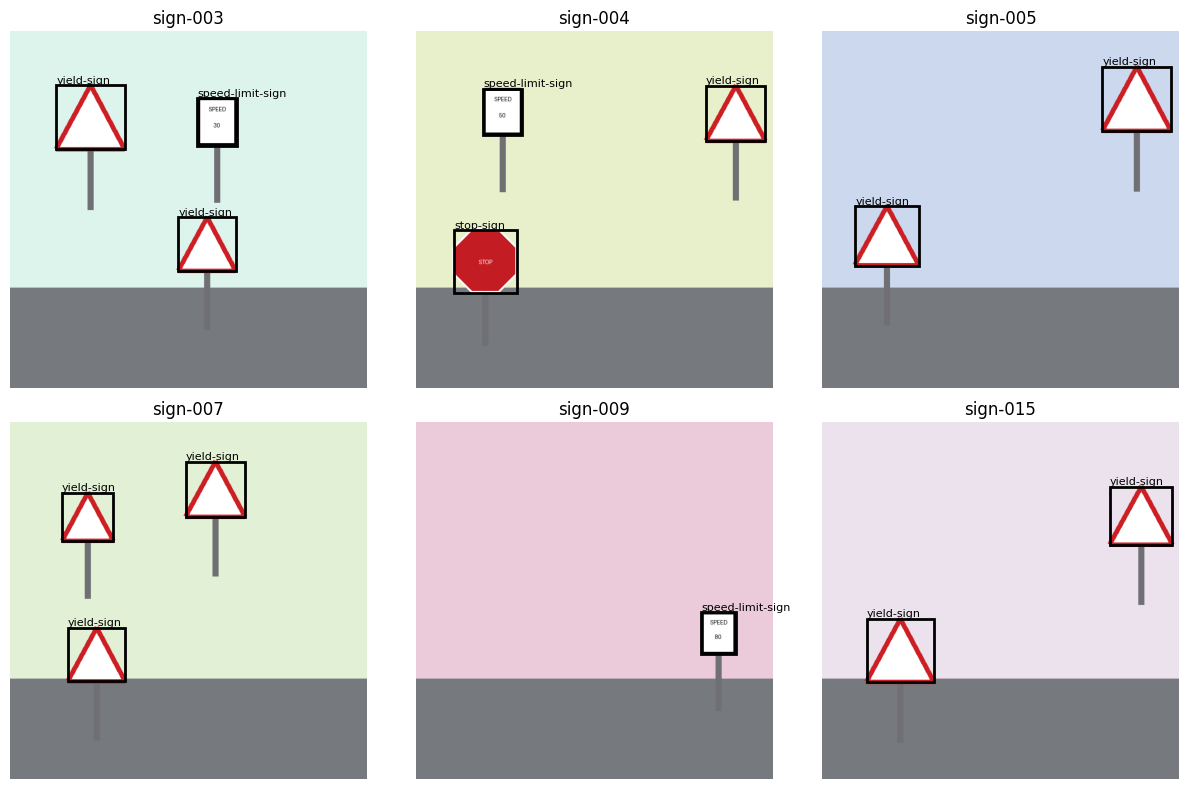

In [ ]:
# @title Dataset gallery
fig, axes = plt.subplots(2,3,figsize=(12,8))
for ax,record in zip(axes.ravel(),train_records[:6]):
    ax.imshow(record["image"])
    for box,label in zip(record["boxes"],record["labels"]):
        x0,y0,x1,y1=box
        rect=plt.Rectangle((x0,y0),x1-x0,y1-y0,fill=False,linewidth=2)
        ax.add_patch(rect)
        ax.text(x0,y0-4,label,fontsize=8)
    ax.set_title(record["id"])
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_ROOT/"figures"/"dataset_gallery.png",dpi=150,bbox_inches="tight")
plt.show()

# 6. Common detector evaluator

The evaluator is notebook-owned and receives only normalized predictions:

```text
[
  {"box":[x0,y0,x1,y1], "label":"stop-sign", "score":0.73},
  ...
]
```

It implements class-aware one-to-one matching, 101-point interpolated AP, and IoU thresholds 0.50:0.05:0.95.

**Worked example.** One image holds two stop signs, A and B. A detector returns three `stop-sign` boxes: score 0.9 overlapping A at IoU 0.8, score 0.7 overlapping A again at IoU 0.6, and score 0.4 on empty background. Matching goes from the highest score down, and each reference can be claimed once at IoU ≥ 0.5: the 0.9 box is a **true positive** (TP) for A; the 0.7 box is a **false positive** (FP), a duplicate of the already-claimed A; the 0.4 box is an FP; B is never claimed, so it is a **false negative** (FN). Precision = TP / (TP + FP) = 1/3 and recall = TP / (TP + FN) = 1/2.

Sorting detections by score and stepping down the list traces a precision–recall curve. A class's AP is the mean of its interpolated precision at 101 recall points (0, 0.01, …, 1). **AP50** is the mean of the per-class APs at IoU 0.50. **AP** (AP@[.50:.95]) averages the same quantity over the ten IoU thresholds 0.50, 0.55, …, 0.95, so it also rewards tight boxes.

These are **COCO-style tutorial metrics**, not `pycocotools` reproduction: there are no crowd regions, area ranges, or official COCO-specific rules.

In [ ]:
# @title IoU, AP, precision/recall helpers
def validate_detections(dets,class_names=CLASS_NAMES,context="detections"):
    """Numerical-validity gate. A malformed or non-finite detection is a failed computation, not a result.

    Geometry policy: four finite pixel coordinates [x0, y0, x1, y1] of the original image with
    x0 <= x1 and y0 <= y1 (boxes are not clipped). Labels must be declared classes; scores must be
    finite and in [0, 1]. An empty list is valid: it is what a finite below-threshold output gives.
    """
    if not isinstance(dets,(list,tuple)):
        raise ValueError(f"{context}: detections must be a list, got {type(dets).__name__}")
    for n,det in enumerate(dets):
        if not isinstance(det,dict) or not {"box","label","score"}<=set(det):
            raise ValueError(f"{context}[{n}]: detection needs box, label and score")
        box=det["box"]
        if not isinstance(box,(list,tuple)) or len(box)!=4:
            raise ValueError(f"{context}[{n}]: box must have exactly four coordinates")
        try:
            coords=np.asarray([float(v) for v in box],dtype=float)
            score=float(det["score"])
        except (TypeError,ValueError) as exc:
            raise ValueError(f"{context}[{n}]: box and score must be numeric") from exc
        if not np.isfinite(coords).all():
            raise ValueError(f"{context}[{n}]: non-finite box coordinate (failed computation)")
        if coords[2]<coords[0] or coords[3]<coords[1]:
            raise ValueError(f"{context}[{n}]: box must satisfy x0 <= x1 and y0 <= y1")
        if det["label"] not in class_names:
            raise ValueError(f"{context}[{n}]: unknown label {det['label']!r}")
        if not (np.isfinite(score) and 0.0<=score<=1.0):
            raise ValueError(f"{context}[{n}]: score {score!r} is not finite in [0, 1] (failed computation)")
    return dets

def validate_prediction_lists(predictions,class_names=CLASS_NAMES):
    for i,dets in enumerate(predictions):
        validate_detections(dets,class_names,context=f"prediction list {i}")

def compare_detection_lists(a,b,context,box_tol=1e-4,score_tol=1e-6):
    """Reload parity on thresholded, postprocessed detections (not raw tensors); both sides must be valid."""
    validate_detections(a,context=f"{context} live")
    validate_detections(b,context=f"{context} reloaded")
    if len(a)!=len(b):
        raise RuntimeError(f"{context}: reload detection count mismatch ({len(a)} vs {len(b)})")
    max_box=max_score=0.0
    for da,db in zip(a,b):
        if da["label"]!=db["label"]:
            raise RuntimeError(f"{context}: reload label mismatch")
        box_diff=np.abs(np.asarray(da["box"],dtype=float)-np.asarray(db["box"],dtype=float))
        max_box=max(max_box,float(box_diff.max()))
        max_score=max(max_score,abs(float(da["score"])-float(db["score"])))
    if not (np.isfinite(max_box) and np.isfinite(max_score)):
        raise RuntimeError(f"{context}: reload difference is not finite")
    if max_box>box_tol or max_score>score_tol:
        raise RuntimeError(
            f"{context}: reload parity exceeded tolerance (box {max_box:.3g}, score {max_score:.3g})"
        )
    return {"n_detections":len(a),"max_abs_box_difference":max_box,"max_abs_score_difference":max_score}

def evaluation_settings():
    """The live evaluation policy. Frozen before the test, then re-checked at the test boundary."""
    return {
        "score_cutoff":EVAL_SCORE_THRESHOLD,
        "display_threshold":DISPLAY_THRESHOLD,
        "yolox_nms":YOLOX_EVAL_NMS,
        "max_detections":MAX_EVAL_DETECTIONS,
        "iou_thresholds":list(IOU_THRESHOLDS),
        "class_names":list(CLASS_NAMES),
        "metric":"notebook-owned class-aware 101-point interpolated AP",
    }

def box_iou(a,b):
    ax0,ay0,ax1,ay1=map(float,a)
    bx0,by0,bx1,by1=map(float,b)
    ix0,iy0=max(ax0,bx0),max(ay0,by0)
    ix1,iy1=min(ax1,bx1),min(ay1,by1)
    iw,ih=max(0.0,ix1-ix0),max(0.0,iy1-iy0)
    inter=iw*ih
    area_a=max(0.0,ax1-ax0)*max(0.0,ay1-ay0)
    area_b=max(0.0,bx1-bx0)*max(0.0,by1-by0)
    union=area_a+area_b-inter
    return inter/union if union>0 else 0.0

def average_precision(predictions,references,class_names,iou_thresholds=IOU_THRESHOLDS):
    if not references or len(predictions)!=len(references):
        raise ValueError("Evaluation needs equal nonempty prediction/reference sequences")
    validate_prediction_lists(predictions,class_names)
    recall_points=np.linspace(0,1,101)
    per_threshold={}
    for threshold in iou_thresholds:
        per_class={}
        for name in class_names:
            scored=[]
            n_refs=0
            for dets,ref in zip(predictions,references):
                ref_boxes=[
                    box for box,label in zip(ref["boxes"],ref["labels"])
                    if label==name
                ]
                n_refs+=len(ref_boxes)
                claimed=[False]*len(ref_boxes)
                candidates=sorted(
                    (d for d in dets if d["label"]==name),
                    key=lambda d:-float(d["score"])
                )
                for det in candidates:
                    best,best_iou=-1,0.0
                    for j,ref_box in enumerate(ref_boxes):
                        if claimed[j]: continue
                        value=box_iou(det["box"],ref_box)
                        if value>best_iou:
                            best,best_iou=j,value
                    hit=best>=0 and best_iou>=threshold
                    if hit: claimed[best]=True
                    scored.append((float(det["score"]),hit))
            if n_refs==0:
                continue
            scored.sort(key=lambda x:-x[0])
            if not scored:
                per_class[name]=0.0
                continue
            tp=np.cumsum([1 if hit else 0 for _,hit in scored])
            fp=np.cumsum([0 if hit else 1 for _,hit in scored])
            recall=tp/n_refs
            precision=tp/np.maximum(tp+fp,1)
            precision=np.maximum.accumulate(precision[::-1])[::-1]
            sampled=np.zeros_like(recall_points)
            indices=np.searchsorted(recall,recall_points,side="left")
            valid=indices<len(precision)
            sampled[valid]=precision[indices[valid]]
            per_class[name]=float(sampled.mean())
        per_threshold[float(threshold)]=per_class

    means={
        t:(float(np.mean(list(v.values()))) if v else 0.0)
        for t,v in per_threshold.items()
    }
    return {
        "ap":float(np.mean(list(means.values()))) if means else 0.0,
        "ap50":means.get(0.5,0.0),
        "ap75":means.get(0.75,0.0),
        "per_class_ap50":per_threshold.get(0.5,{}),
        "n_images":len(references),
        "n_references":sum(len(r["boxes"]) for r in references),
    }

def operating_metrics(predictions,references,threshold=0.30,iou=0.50):
    if not references or len(predictions)!=len(references):
        raise ValueError("Evaluation needs equal nonempty prediction/reference sequences")
    validate_prediction_lists(predictions)
    tp=fp=fn=0
    matched_ious=[]
    for dets,ref in zip(predictions,references):
        filtered=[d for d in dets if float(d["score"])>=threshold]
        claimed=[False]*len(ref["boxes"])
        for det in sorted(filtered,key=lambda d:-float(d["score"])):
            best,best_iou=-1,0.0
            for j,(box,label) in enumerate(zip(ref["boxes"],ref["labels"])):
                if claimed[j] or label!=det["label"]: continue
                value=box_iou(det["box"],box)
                if value>best_iou:
                    best,best_iou=j,value
            if best>=0 and best_iou>=iou:
                claimed[best]=True
                tp+=1
                matched_ious.append(best_iou)
            else:
                fp+=1
        fn+=sum(not x for x in claimed)
    return {
        "precision50":tp/(tp+fp) if tp+fp else 0.0,
        "recall50":tp/(tp+fn) if tp+fn else 0.0,
        "mean_matched_iou":float(np.mean(matched_ious)) if matched_ious else 0.0,
        "false_positives_per_image":fp/len(references),
        "missed_objects_per_image":fn/len(references),
    }

empty_predictions=[[] for _ in validation_records]
empty_metrics=average_precision(empty_predictions,validation_records,CLASS_NAMES)
print({"empty_detector":empty_metrics})
assert empty_metrics["ap"]==0.0 and empty_metrics["ap50"]==0.0

{'empty_detector': {'ap': 0.0, 'ap50': 0.0, 'ap75': 0.0, 'per_class_ap50': {'stop-sign': 0.0, 'yield-sign': 0.0, 'speed-limit-sign': 0.0}, 'n_images': 12, 'n_references': 25}}


# 7. Stage the pinned RT-DETR SafeTensors snapshot

All four files are acquired from the immutable Hugging Face revision and verified before model loading.

In [ ]:
# @title RT-DETR snapshot staging
from huggingface_hub import hf_hub_download

def sha256_file(path):
    h=hashlib.sha256()
    with open(path,"rb") as fh:
        for chunk in iter(lambda:fh.read(1<<20),b""):
            h.update(chunk)
    return h.hexdigest()

RTDETR_ROOT=WORK_ROOT/"rtdetr_weights"
for name,(size,digest) in RTDETR_SPEC["files"].items():
    path=Path(hf_hub_download(
        RTDETR_SPEC["model_id"],
        name,
        revision=RTDETR_SPEC["revision"],
        local_dir=str(RTDETR_ROOT),
    ))
    if path.stat().st_size!=size or sha256_file(path)!=digest:
        raise ValueError(f"RT-DETR asset integrity mismatch: {name}")

print("RT-DETR snapshot verified:",RTDETR_ROOT)

RT-DETR snapshot verified: work/rtdetr_weights


## Infrastructure — carried YOLOX implementation

Nine upstream source files at immutable revision `419778480ab6ec0590e5d3831b3afb3b46ab2aa3` are carried below and checked against original SHA-256 digests. They form eight runtime modules; the Apache-2.0 license and original notices are retained. The local import/logger modifications are recorded beside the staged modules. This cell fetches no source code. Model checkpoints still download from their pinned locations.


In [ ]:
# @title Stage verified upstream YOLOX source
import sys

YOLOX_CODE_REVISION="419778480ab6ec0590e5d3831b3afb3b46ab2aa3"
RAW_BASE=f"https://raw.githubusercontent.com/Megvii-BaseDetection/YOLOX/{YOLOX_CODE_REVISION}/"

UPSTREAM_FILES={
    "network_blocks.py":("yolox/models/network_blocks.py",6092,"f490240a674799f1b548ac4ca571c7f3e59d4e75efee8ebeb1e24e6e4e10d2a4"),
    "darknet.py":("yolox/models/darknet.py",6019,"368c9db45166e863691cf7460b314d047928f90e8744c492a673b6eff9b809f3"),
    "yolo_pafpn.py":("yolox/models/yolo_pafpn.py",3530,"8571af557f6caacda61e54813be4be2d73c4a0889e1f876ec5586057eb2eebde"),
    "losses.py":("yolox/models/losses.py",1677,"7fa685fb4653bab69d5880c3f749edeb8a4cabfe71fadf0acc5151c2eaa75702"),
    "yolo_head.py":("yolox/models/yolo_head.py",23339,"9fcdcf859b91c587d11926c0a8e3e423abdaa53504eb8ad2a17379ee405378bd"),
    "yolox.py":("yolox/models/yolox.py",1364,"3b88f3b19e27232ab5442b4d2c53b20d3f1e40f6f093871d6742e694368f6da0"),
    "coco_classes.py":("yolox/data/datasets/coco_classes.py",1296,"b38193c481a73f1f674cedab9e551b15b39b1a7aaed3e09e16505362cc54ad51"),
}
OPS_FILES=[
    ("yolox/utils/compat.py",310,"a8f0dec9e0566cf0a09a211bc08ce47bc7abd6dd75d239ee85d8c0c5fe3e07ce"),
    ("yolox/utils/boxes.py",4471,"65d8341d67ec35d65f4a73ba8480ce536a8bb38f4b4088f99db82bc812ec9bcb"),
]

PKG_ROOT=WORK_ROOT/"yolox_upstream"
PKG=PKG_ROOT/"yolox_ref"
PKG.mkdir(parents=True,exist_ok=True)
(PKG/"__init__.py").write_text("",encoding="utf-8")

YOLOX_SOURCE_FILES={
    'yolox/models/network_blocks.py': (
        '#!/usr/bin/env python\n# -*- encoding: utf-8 -*-\n# Copyright (c) Megvii Inc. All rights reserved.\n\nimport torch\nimport torch.nn as nn\n\n\nclass SiLU(nn.Module):\n    """export-friendly version of nn.SiLU()"""\n\n    @staticmethod\n    def forward(x):\n        return x * torch.sigmoid(x)\n\n\ndef get_activation(name="silu", inplace=True):\n    if name == "silu":\n        module = nn.SiLU(inplace=inplace)\n    elif name == "relu":\n        module = nn.ReLU(inplace=inplace)\n    elif name == "lrelu":\n        module = nn.LeakyReLU(0.1, inplace=inplace)\n    else:\n        raise AttributeError("Unsupported act type: {}".format(name))\n    return module\n\n\nclass BaseConv(nn.Module):\n    """A Conv2d -> Batchnorm -> silu/leaky relu block"""\n\n    def __init__(\n        self, in_channels, out_channels, ksize, stride, groups=1, bias=False, act="silu"\n    ):\n        super().__init__()\n        # same padding\n        pad = (ksize - 1) // 2\n        self.conv = nn.Conv2d(\n'
        '            in_channels,\n            out_channels,\n            kernel_size=ksize,\n            stride=stride,\n            padding=pad,\n            groups=groups,\n            bias=bias,\n        )\n        self.bn = nn.BatchNorm2d(out_channels)\n        self.act = get_activation(act, inplace=True)\n\n    def forward(self, x):\n        return self.act(self.bn(self.conv(x)))\n\n    def fuseforward(self, x):\n        return self.act(self.conv(x))\n\n\nclass DWConv(nn.Module):\n    """Depthwise Conv + Conv"""\n\n    def __init__(self, in_channels, out_channels, ksize, stride=1, act="silu"):\n        super().__init__()\n        self.dconv = BaseConv(\n            in_channels,\n            in_channels,\n            ksize=ksize,\n            stride=stride,\n            groups=in_channels,\n            act=act,\n        )\n        self.pconv = BaseConv(\n            in_channels, out_channels, ksize=1, stride=1, groups=1, act=act\n        )\n\n    def forward(self, x):\n'
        '        x = self.dconv(x)\n        return self.pconv(x)\n\n\nclass Bottleneck(nn.Module):\n    # Standard bottleneck\n    def __init__(\n        self,\n        in_channels,\n        out_channels,\n        shortcut=True,\n        expansion=0.5,\n        depthwise=False,\n        act="silu",\n    ):\n        super().__init__()\n        hidden_channels = int(out_channels * expansion)\n        Conv = DWConv if depthwise else BaseConv\n        self.conv1 = BaseConv(in_channels, hidden_channels, 1, stride=1, act=act)\n        self.conv2 = Conv(hidden_channels, out_channels, 3, stride=1, act=act)\n        self.use_add = shortcut and in_channels == out_channels\n\n    def forward(self, x):\n        y = self.conv2(self.conv1(x))\n        if self.use_add:\n            y = y + x\n        return y\n\n\nclass ResLayer(nn.Module):\n    "Residual layer with `in_channels` inputs."\n\n    def __init__(self, in_channels: int):\n        super().__init__()\n        mid_channels = in_channels // 2\n'
        '        self.layer1 = BaseConv(\n            in_channels, mid_channels, ksize=1, stride=1, act="lrelu"\n        )\n        self.layer2 = BaseConv(\n            mid_channels, in_channels, ksize=3, stride=1, act="lrelu"\n        )\n\n    def forward(self, x):\n        out = self.layer2(self.layer1(x))\n        return x + out\n\n\nclass SPPBottleneck(nn.Module):\n    """Spatial pyramid pooling layer used in YOLOv3-SPP"""\n\n    def __init__(\n        self, in_channels, out_channels, kernel_sizes=(5, 9, 13), activation="silu"\n    ):\n        super().__init__()\n        hidden_channels = in_channels // 2\n        self.conv1 = BaseConv(in_channels, hidden_channels, 1, stride=1, act=activation)\n        self.m = nn.ModuleList(\n            [\n                nn.MaxPool2d(kernel_size=ks, stride=1, padding=ks // 2)\n                for ks in kernel_sizes\n            ]\n        )\n        conv2_channels = hidden_channels * (len(kernel_sizes) + 1)\n'
        '        self.conv2 = BaseConv(conv2_channels, out_channels, 1, stride=1, act=activation)\n\n    def forward(self, x):\n        x = self.conv1(x)\n        x = torch.cat([x] + [m(x) for m in self.m], dim=1)\n        x = self.conv2(x)\n        return x\n\n\nclass CSPLayer(nn.Module):\n    """C3 in yolov5, CSP Bottleneck with 3 convolutions"""\n\n    def __init__(\n        self,\n        in_channels,\n        out_channels,\n        n=1,\n        shortcut=True,\n        expansion=0.5,\n        depthwise=False,\n        act="silu",\n    ):\n        """\n        Args:\n            in_channels (int): input channels.\n            out_channels (int): output channels.\n            n (int): number of Bottlenecks. Default value: 1.\n        """\n        # ch_in, ch_out, number, shortcut, groups, expansion\n        super().__init__()\n        hidden_channels = int(out_channels * expansion)  # hidden channels\n        self.conv1 = BaseConv(in_channels, hidden_channels, 1, stride=1, act=act)\n'
        '        self.conv2 = BaseConv(in_channels, hidden_channels, 1, stride=1, act=act)\n        self.conv3 = BaseConv(2 * hidden_channels, out_channels, 1, stride=1, act=act)\n        module_list = [\n            Bottleneck(\n                hidden_channels, hidden_channels, shortcut, 1.0, depthwise, act=act\n            )\n            for _ in range(n)\n        ]\n        self.m = nn.Sequential(*module_list)\n\n    def forward(self, x):\n        x_1 = self.conv1(x)\n        x_2 = self.conv2(x)\n        x_1 = self.m(x_1)\n        x = torch.cat((x_1, x_2), dim=1)\n        return self.conv3(x)\n\n\nclass Focus(nn.Module):\n    """Focus width and height information into channel space."""\n\n    def __init__(self, in_channels, out_channels, ksize=1, stride=1, act="silu"):\n        super().__init__()\n        self.conv = BaseConv(in_channels * 4, out_channels, ksize, stride, act=act)\n\n    def forward(self, x):\n        # shape of x (b,c,w,h) -> y(b,4c,w/2,h/2)\n'
        '        patch_top_left = x[..., ::2, ::2]\n        patch_top_right = x[..., ::2, 1::2]\n        patch_bot_left = x[..., 1::2, ::2]\n        patch_bot_right = x[..., 1::2, 1::2]\n        x = torch.cat(\n            (\n                patch_top_left,\n                patch_bot_left,\n                patch_top_right,\n                patch_bot_right,\n            ),\n            dim=1,\n        )\n        return self.conv(x)\n'
    ),
    'yolox/models/darknet.py': (
        '#!/usr/bin/env python\n# -*- encoding: utf-8 -*-\n# Copyright (c) Megvii Inc. All rights reserved.\n\nfrom torch import nn\n\nfrom .network_blocks import BaseConv, CSPLayer, DWConv, Focus, ResLayer, SPPBottleneck\n\n\nclass Darknet(nn.Module):\n    # number of blocks from dark2 to dark5.\n    depth2blocks = {21: [1, 2, 2, 1], 53: [2, 8, 8, 4]}\n\n    def __init__(\n        self,\n        depth,\n        in_channels=3,\n        stem_out_channels=32,\n        out_features=("dark3", "dark4", "dark5"),\n    ):\n        """\n        Args:\n            depth (int): depth of darknet used in model, usually use [21, 53] for this param.\n            in_channels (int): number of input channels, for example, use 3 for RGB image.\n            stem_out_channels (int): number of output channels of darknet stem.\n                It decides channels of darknet layer2 to layer5.\n            out_features (Tuple[str]): desired output layer name.\n        """\n        super().__init__()\n'
        '        assert out_features, "please provide output features of Darknet"\n        self.out_features = out_features\n        self.stem = nn.Sequential(\n            BaseConv(in_channels, stem_out_channels, ksize=3, stride=1, act="lrelu"),\n            *self.make_group_layer(stem_out_channels, num_blocks=1, stride=2),\n        )\n        in_channels = stem_out_channels * 2  # 64\n\n        num_blocks = Darknet.depth2blocks[depth]\n        # create darknet with `stem_out_channels` and `num_blocks` layers.\n        # to make model structure more clear, we don\'t use `for` statement in python.\n        self.dark2 = nn.Sequential(\n            *self.make_group_layer(in_channels, num_blocks[0], stride=2)\n        )\n        in_channels *= 2  # 128\n        self.dark3 = nn.Sequential(\n            *self.make_group_layer(in_channels, num_blocks[1], stride=2)\n        )\n        in_channels *= 2  # 256\n        self.dark4 = nn.Sequential(\n'
        '            *self.make_group_layer(in_channels, num_blocks[2], stride=2)\n        )\n        in_channels *= 2  # 512\n\n        self.dark5 = nn.Sequential(\n            *self.make_group_layer(in_channels, num_blocks[3], stride=2),\n            *self.make_spp_block([in_channels, in_channels * 2], in_channels * 2),\n        )\n\n    def make_group_layer(self, in_channels: int, num_blocks: int, stride: int = 1):\n        "starts with conv layer then has `num_blocks` `ResLayer`"\n        return [\n            BaseConv(in_channels, in_channels * 2, ksize=3, stride=stride, act="lrelu"),\n            *[(ResLayer(in_channels * 2)) for _ in range(num_blocks)],\n        ]\n\n    def make_spp_block(self, filters_list, in_filters):\n        m = nn.Sequential(\n            *[\n                BaseConv(in_filters, filters_list[0], 1, stride=1, act="lrelu"),\n                BaseConv(filters_list[0], filters_list[1], 3, stride=1, act="lrelu"),\n                SPPBottleneck(\n'
        '                    in_channels=filters_list[1],\n                    out_channels=filters_list[0],\n                    activation="lrelu",\n                ),\n                BaseConv(filters_list[0], filters_list[1], 3, stride=1, act="lrelu"),\n                BaseConv(filters_list[1], filters_list[0], 1, stride=1, act="lrelu"),\n            ]\n        )\n        return m\n\n    def forward(self, x):\n        outputs = {}\n        x = self.stem(x)\n        outputs["stem"] = x\n        x = self.dark2(x)\n        outputs["dark2"] = x\n        x = self.dark3(x)\n        outputs["dark3"] = x\n        x = self.dark4(x)\n        outputs["dark4"] = x\n        x = self.dark5(x)\n        outputs["dark5"] = x\n        return {k: v for k, v in outputs.items() if k in self.out_features}\n\n\nclass CSPDarknet(nn.Module):\n    def __init__(\n        self,\n        dep_mul,\n        wid_mul,\n        out_features=("dark3", "dark4", "dark5"),\n        depthwise=False,\n        act="silu",\n'
        '    ):\n        super().__init__()\n        assert out_features, "please provide output features of Darknet"\n        self.out_features = out_features\n        Conv = DWConv if depthwise else BaseConv\n\n        base_channels = int(wid_mul * 64)  # 64\n        base_depth = max(round(dep_mul * 3), 1)  # 3\n\n        # stem\n        self.stem = Focus(3, base_channels, ksize=3, act=act)\n\n        # dark2\n        self.dark2 = nn.Sequential(\n            Conv(base_channels, base_channels * 2, 3, 2, act=act),\n            CSPLayer(\n                base_channels * 2,\n                base_channels * 2,\n                n=base_depth,\n                depthwise=depthwise,\n                act=act,\n            ),\n        )\n\n        # dark3\n        self.dark3 = nn.Sequential(\n            Conv(base_channels * 2, base_channels * 4, 3, 2, act=act),\n            CSPLayer(\n                base_channels * 4,\n                base_channels * 4,\n                n=base_depth * 3,\n'
        '                depthwise=depthwise,\n                act=act,\n            ),\n        )\n\n        # dark4\n        self.dark4 = nn.Sequential(\n            Conv(base_channels * 4, base_channels * 8, 3, 2, act=act),\n            CSPLayer(\n                base_channels * 8,\n                base_channels * 8,\n                n=base_depth * 3,\n                depthwise=depthwise,\n                act=act,\n            ),\n        )\n\n        # dark5\n        self.dark5 = nn.Sequential(\n            Conv(base_channels * 8, base_channels * 16, 3, 2, act=act),\n            SPPBottleneck(base_channels * 16, base_channels * 16, activation=act),\n            CSPLayer(\n                base_channels * 16,\n                base_channels * 16,\n                n=base_depth,\n                shortcut=False,\n                depthwise=depthwise,\n                act=act,\n            ),\n        )\n\n    def forward(self, x):\n        outputs = {}\n        x = self.stem(x)\n'
        '        outputs["stem"] = x\n        x = self.dark2(x)\n        outputs["dark2"] = x\n        x = self.dark3(x)\n        outputs["dark3"] = x\n        x = self.dark4(x)\n        outputs["dark4"] = x\n        x = self.dark5(x)\n        outputs["dark5"] = x\n        return {k: v for k, v in outputs.items() if k in self.out_features}\n'
    ),
    'yolox/models/yolo_pafpn.py': (
        '#!/usr/bin/env python\n# -*- encoding: utf-8 -*-\n# Copyright (c) Megvii Inc. All rights reserved.\n\nimport torch\nimport torch.nn as nn\n\nfrom .darknet import CSPDarknet\nfrom .network_blocks import BaseConv, CSPLayer, DWConv\n\n\nclass YOLOPAFPN(nn.Module):\n    """\n    YOLOv3 model. Darknet 53 is the default backbone of this model.\n    """\n\n    def __init__(\n        self,\n        depth=1.0,\n        width=1.0,\n        in_features=("dark3", "dark4", "dark5"),\n        in_channels=[256, 512, 1024],\n        depthwise=False,\n        act="silu",\n    ):\n        super().__init__()\n        self.backbone = CSPDarknet(depth, width, depthwise=depthwise, act=act)\n        self.in_features = in_features\n        self.in_channels = in_channels\n        Conv = DWConv if depthwise else BaseConv\n\n        self.upsample = nn.Upsample(scale_factor=2, mode="nearest")\n        self.lateral_conv0 = BaseConv(\n'
        '            int(in_channels[2] * width), int(in_channels[1] * width), 1, 1, act=act\n        )\n        self.C3_p4 = CSPLayer(\n            int(2 * in_channels[1] * width),\n            int(in_channels[1] * width),\n            round(3 * depth),\n            False,\n            depthwise=depthwise,\n            act=act,\n        )  # cat\n\n        self.reduce_conv1 = BaseConv(\n            int(in_channels[1] * width), int(in_channels[0] * width), 1, 1, act=act\n        )\n        self.C3_p3 = CSPLayer(\n            int(2 * in_channels[0] * width),\n            int(in_channels[0] * width),\n            round(3 * depth),\n            False,\n            depthwise=depthwise,\n            act=act,\n        )\n\n        # bottom-up conv\n        self.bu_conv2 = Conv(\n            int(in_channels[0] * width), int(in_channels[0] * width), 3, 2, act=act\n        )\n        self.C3_n3 = CSPLayer(\n            int(2 * in_channels[0] * width),\n            int(in_channels[1] * width),\n'
        '            round(3 * depth),\n            False,\n            depthwise=depthwise,\n            act=act,\n        )\n\n        # bottom-up conv\n        self.bu_conv1 = Conv(\n            int(in_channels[1] * width), int(in_channels[1] * width), 3, 2, act=act\n        )\n        self.C3_n4 = CSPLayer(\n            int(2 * in_channels[1] * width),\n            int(in_channels[2] * width),\n            round(3 * depth),\n            False,\n            depthwise=depthwise,\n            act=act,\n        )\n\n    def forward(self, input):\n        """\n        Args:\n            inputs: input images.\n\n        Returns:\n            Tuple[Tensor]: FPN feature.\n        """\n\n        #  backbone\n        out_features = self.backbone(input)\n        features = [out_features[f] for f in self.in_features]\n        [x2, x1, x0] = features\n\n        fpn_out0 = self.lateral_conv0(x0)  # 1024->512/32\n        f_out0 = self.upsample(fpn_out0)  # 512/16\n'
        '        f_out0 = torch.cat([f_out0, x1], 1)  # 512->1024/16\n        f_out0 = self.C3_p4(f_out0)  # 1024->512/16\n\n        fpn_out1 = self.reduce_conv1(f_out0)  # 512->256/16\n        f_out1 = self.upsample(fpn_out1)  # 256/8\n        f_out1 = torch.cat([f_out1, x2], 1)  # 256->512/8\n        pan_out2 = self.C3_p3(f_out1)  # 512->256/8\n\n        p_out1 = self.bu_conv2(pan_out2)  # 256->256/16\n        p_out1 = torch.cat([p_out1, fpn_out1], 1)  # 256->512/16\n        pan_out1 = self.C3_n3(p_out1)  # 512->512/16\n\n        p_out0 = self.bu_conv1(pan_out1)  # 512->512/32\n        p_out0 = torch.cat([p_out0, fpn_out0], 1)  # 512->1024/32\n        pan_out0 = self.C3_n4(p_out0)  # 1024->1024/32\n\n        outputs = (pan_out2, pan_out1, pan_out0)\n        return outputs\n'
    ),
    'yolox/models/losses.py': (
        '#!/usr/bin/env python\n# -*- encoding: utf-8 -*-\n# Copyright (c) Megvii Inc. All rights reserved.\n\nimport torch\nimport torch.nn as nn\n\n\nclass IOUloss(nn.Module):\n    def __init__(self, reduction="none", loss_type="iou"):\n        super(IOUloss, self).__init__()\n        self.reduction = reduction\n        self.loss_type = loss_type\n\n    def forward(self, pred, target):\n        assert pred.shape[0] == target.shape[0]\n\n        pred = pred.view(-1, 4)\n        target = target.view(-1, 4)\n        tl = torch.max(\n            (pred[:, :2] - pred[:, 2:] / 2), (target[:, :2] - target[:, 2:] / 2)\n        )\n        br = torch.min(\n            (pred[:, :2] + pred[:, 2:] / 2), (target[:, :2] + target[:, 2:] / 2)\n        )\n\n        area_p = torch.prod(pred[:, 2:], 1)\n        area_g = torch.prod(target[:, 2:], 1)\n\n        en = (tl < br).type(tl.type()).prod(dim=1)\n        area_i = torch.prod(br - tl, 1) * en\n        area_u = area_p + area_g - area_i\n'
        '        iou = (area_i) / (area_u + 1e-16)\n\n        if self.loss_type == "iou":\n            loss = 1 - iou ** 2\n        elif self.loss_type == "giou":\n            c_tl = torch.min(\n                (pred[:, :2] - pred[:, 2:] / 2), (target[:, :2] - target[:, 2:] / 2)\n            )\n            c_br = torch.max(\n                (pred[:, :2] + pred[:, 2:] / 2), (target[:, :2] + target[:, 2:] / 2)\n            )\n            area_c = torch.prod(c_br - c_tl, 1)\n            giou = iou - (area_c - area_u) / area_c.clamp(1e-16)\n            loss = 1 - giou.clamp(min=-1.0, max=1.0)\n\n        if self.reduction == "mean":\n            loss = loss.mean()\n        elif self.reduction == "sum":\n            loss = loss.sum()\n\n        return loss\n'
    ),
    'yolox/models/yolo_head.py': (
        '#!/usr/bin/env python3\n# -*- coding:utf-8 -*-\n# Copyright (c) Megvii Inc. All rights reserved.\n\nimport math\nfrom loguru import logger\n\nimport torch\nimport torch.nn as nn\nimport torch.nn.functional as F\n\nfrom yolox.utils import bboxes_iou, meshgrid\n\nfrom .losses import IOUloss\nfrom .network_blocks import BaseConv, DWConv\n\n\nclass YOLOXHead(nn.Module):\n    def __init__(\n        self,\n        num_classes,\n        width=1.0,\n        strides=[8, 16, 32],\n        in_channels=[256, 512, 1024],\n        act="silu",\n        depthwise=False,\n    ):\n        """\n        Args:\n            act (str): activation type of conv. Defalut value: "silu".\n            depthwise (bool): whether apply depthwise conv in conv branch. Defalut value: False.\n        """\n        super().__init__()\n\n        self.n_anchors = 1\n        self.num_classes = num_classes\n        self.decode_in_inference = True  # for deploy, set to False\n\n        self.cls_convs = nn.ModuleList()\n'
        '        self.reg_convs = nn.ModuleList()\n        self.cls_preds = nn.ModuleList()\n        self.reg_preds = nn.ModuleList()\n        self.obj_preds = nn.ModuleList()\n        self.stems = nn.ModuleList()\n        Conv = DWConv if depthwise else BaseConv\n\n        for i in range(len(in_channels)):\n            self.stems.append(\n                BaseConv(\n                    in_channels=int(in_channels[i] * width),\n                    out_channels=int(256 * width),\n                    ksize=1,\n                    stride=1,\n                    act=act,\n                )\n            )\n            self.cls_convs.append(\n                nn.Sequential(\n                    *[\n                        Conv(\n                            in_channels=int(256 * width),\n                            out_channels=int(256 * width),\n                            ksize=3,\n                            stride=1,\n                            act=act,\n                        ),\n'
        '                        Conv(\n                            in_channels=int(256 * width),\n                            out_channels=int(256 * width),\n                            ksize=3,\n                            stride=1,\n                            act=act,\n                        ),\n                    ]\n                )\n            )\n            self.reg_convs.append(\n                nn.Sequential(\n                    *[\n                        Conv(\n                            in_channels=int(256 * width),\n                            out_channels=int(256 * width),\n                            ksize=3,\n                            stride=1,\n                            act=act,\n                        ),\n                        Conv(\n                            in_channels=int(256 * width),\n                            out_channels=int(256 * width),\n                            ksize=3,\n                            stride=1,\n'
        '                            act=act,\n                        ),\n                    ]\n                )\n            )\n            self.cls_preds.append(\n                nn.Conv2d(\n                    in_channels=int(256 * width),\n                    out_channels=self.n_anchors * self.num_classes,\n                    kernel_size=1,\n                    stride=1,\n                    padding=0,\n                )\n            )\n            self.reg_preds.append(\n                nn.Conv2d(\n                    in_channels=int(256 * width),\n                    out_channels=4,\n                    kernel_size=1,\n                    stride=1,\n                    padding=0,\n                )\n            )\n            self.obj_preds.append(\n                nn.Conv2d(\n                    in_channels=int(256 * width),\n                    out_channels=self.n_anchors * 1,\n                    kernel_size=1,\n                    stride=1,\n                    padding=0,\n'
        '                )\n            )\n\n        self.use_l1 = False\n        self.l1_loss = nn.L1Loss(reduction="none")\n        self.bcewithlog_loss = nn.BCEWithLogitsLoss(reduction="none")\n        self.iou_loss = IOUloss(reduction="none")\n        self.strides = strides\n        self.grids = [torch.zeros(1)] * len(in_channels)\n\n    def initialize_biases(self, prior_prob):\n        for conv in self.cls_preds:\n            b = conv.bias.view(self.n_anchors, -1)\n            b.data.fill_(-math.log((1 - prior_prob) / prior_prob))\n            conv.bias = torch.nn.Parameter(b.view(-1), requires_grad=True)\n\n        for conv in self.obj_preds:\n            b = conv.bias.view(self.n_anchors, -1)\n            b.data.fill_(-math.log((1 - prior_prob) / prior_prob))\n            conv.bias = torch.nn.Parameter(b.view(-1), requires_grad=True)\n\n    def forward(self, xin, labels=None, imgs=None):\n        outputs = []\n        origin_preds = []\n        x_shifts = []\n        y_shifts = []\n'
        '        expanded_strides = []\n\n        for k, (cls_conv, reg_conv, stride_this_level, x) in enumerate(\n            zip(self.cls_convs, self.reg_convs, self.strides, xin)\n        ):\n            x = self.stems[k](x)\n            cls_x = x\n            reg_x = x\n\n            cls_feat = cls_conv(cls_x)\n            cls_output = self.cls_preds[k](cls_feat)\n\n            reg_feat = reg_conv(reg_x)\n            reg_output = self.reg_preds[k](reg_feat)\n            obj_output = self.obj_preds[k](reg_feat)\n\n            if self.training:\n                output = torch.cat([reg_output, obj_output, cls_output], 1)\n                output, grid = self.get_output_and_grid(\n                    output, k, stride_this_level, xin[0].type()\n                )\n                x_shifts.append(grid[:, :, 0])\n                y_shifts.append(grid[:, :, 1])\n                expanded_strides.append(\n                    torch.zeros(1, grid.shape[1])\n'
        '                    .fill_(stride_this_level)\n                    .type_as(xin[0])\n                )\n                if self.use_l1:\n                    batch_size = reg_output.shape[0]\n                    hsize, wsize = reg_output.shape[-2:]\n                    reg_output = reg_output.view(\n                        batch_size, self.n_anchors, 4, hsize, wsize\n                    )\n                    reg_output = reg_output.permute(0, 1, 3, 4, 2).reshape(\n                        batch_size, -1, 4\n                    )\n                    origin_preds.append(reg_output.clone())\n\n            else:\n                output = torch.cat(\n                    [reg_output, obj_output.sigmoid(), cls_output.sigmoid()], 1\n                )\n\n            outputs.append(output)\n\n        if self.training:\n            return self.get_losses(\n                imgs,\n                x_shifts,\n                y_shifts,\n                expanded_strides,\n                labels,\n'
        '                torch.cat(outputs, 1),\n                origin_preds,\n                dtype=xin[0].dtype,\n            )\n        else:\n            self.hw = [x.shape[-2:] for x in outputs]\n            # [batch, n_anchors_all, 85]\n            outputs = torch.cat(\n                [x.flatten(start_dim=2) for x in outputs], dim=2\n            ).permute(0, 2, 1)\n            if self.decode_in_inference:\n                return self.decode_outputs(outputs, dtype=xin[0].type())\n            else:\n                return outputs\n\n    def get_output_and_grid(self, output, k, stride, dtype):\n        grid = self.grids[k]\n\n        batch_size = output.shape[0]\n        n_ch = 5 + self.num_classes\n        hsize, wsize = output.shape[-2:]\n        if grid.shape[2:4] != output.shape[2:4]:\n            yv, xv = meshgrid([torch.arange(hsize), torch.arange(wsize)])\n            grid = torch.stack((xv, yv), 2).view(1, 1, hsize, wsize, 2).type(dtype)\n            self.grids[k] = grid\n\n'
        '        output = output.view(batch_size, self.n_anchors, n_ch, hsize, wsize)\n        output = output.permute(0, 1, 3, 4, 2).reshape(\n            batch_size, self.n_anchors * hsize * wsize, -1\n        )\n        grid = grid.view(1, -1, 2)\n        output[..., :2] = (output[..., :2] + grid) * stride\n        output[..., 2:4] = torch.exp(output[..., 2:4]) * stride\n        return output, grid\n\n    def decode_outputs(self, outputs, dtype):\n        grids = []\n        strides = []\n        for (hsize, wsize), stride in zip(self.hw, self.strides):\n            yv, xv = meshgrid([torch.arange(hsize), torch.arange(wsize)])\n            grid = torch.stack((xv, yv), 2).view(1, -1, 2)\n            grids.append(grid)\n            shape = grid.shape[:2]\n            strides.append(torch.full((*shape, 1), stride))\n\n        grids = torch.cat(grids, dim=1).type(dtype)\n        strides = torch.cat(strides, dim=1).type(dtype)\n\n        outputs[..., :2] = (outputs[..., :2] + grids) * strides\n'
        '        outputs[..., 2:4] = torch.exp(outputs[..., 2:4]) * strides\n        return outputs\n\n    def get_losses(\n        self,\n        imgs,\n        x_shifts,\n        y_shifts,\n        expanded_strides,\n        labels,\n        outputs,\n        origin_preds,\n        dtype,\n    ):\n        bbox_preds = outputs[:, :, :4]  # [batch, n_anchors_all, 4]\n        obj_preds = outputs[:, :, 4].unsqueeze(-1)  # [batch, n_anchors_all, 1]\n        cls_preds = outputs[:, :, 5:]  # [batch, n_anchors_all, n_cls]\n\n        # calculate targets\n        nlabel = (labels.sum(dim=2) > 0).sum(dim=1)  # number of objects\n\n        total_num_anchors = outputs.shape[1]\n        x_shifts = torch.cat(x_shifts, 1)  # [1, n_anchors_all]\n        y_shifts = torch.cat(y_shifts, 1)  # [1, n_anchors_all]\n        expanded_strides = torch.cat(expanded_strides, 1)\n        if self.use_l1:\n            origin_preds = torch.cat(origin_preds, 1)\n\n        cls_targets = []\n        reg_targets = []\n'
        '        l1_targets = []\n        obj_targets = []\n        fg_masks = []\n\n        num_fg = 0.0\n        num_gts = 0.0\n\n        for batch_idx in range(outputs.shape[0]):\n            num_gt = int(nlabel[batch_idx])\n            num_gts += num_gt\n            if num_gt == 0:\n                cls_target = outputs.new_zeros((0, self.num_classes))\n                reg_target = outputs.new_zeros((0, 4))\n                l1_target = outputs.new_zeros((0, 4))\n                obj_target = outputs.new_zeros((total_num_anchors, 1))\n                fg_mask = outputs.new_zeros(total_num_anchors).bool()\n            else:\n                gt_bboxes_per_image = labels[batch_idx, :num_gt, 1:5]\n                gt_classes = labels[batch_idx, :num_gt, 0]\n                bboxes_preds_per_image = bbox_preds[batch_idx]\n\n                try:\n                    (\n                        gt_matched_classes,\n                        fg_mask,\n                        pred_ious_this_matching,\n'
        '                        matched_gt_inds,\n                        num_fg_img,\n                    ) = self.get_assignments(  # noqa\n                        batch_idx,\n                        num_gt,\n                        total_num_anchors,\n                        gt_bboxes_per_image,\n                        gt_classes,\n                        bboxes_preds_per_image,\n                        expanded_strides,\n                        x_shifts,\n                        y_shifts,\n                        cls_preds,\n                        bbox_preds,\n                        obj_preds,\n                        labels,\n                        imgs,\n                    )\n                except RuntimeError as e:\n                    # TODO: the string might change, consider a better way\n                    if "CUDA out of memory. " not in str(e):\n                        raise  # RuntimeError might not caused by CUDA OOM\n\n                    logger.error(\n'
        '                        "OOM RuntimeError is raised due to the huge memory cost during label assignment. \\\n                           CPU mode is applied in this batch. If you want to avoid this issue, \\\n                           try to reduce the batch size or image size."\n                    )\n                    torch.cuda.empty_cache()\n                    (\n                        gt_matched_classes,\n                        fg_mask,\n                        pred_ious_this_matching,\n                        matched_gt_inds,\n                        num_fg_img,\n                    ) = self.get_assignments(  # noqa\n                        batch_idx,\n                        num_gt,\n                        total_num_anchors,\n                        gt_bboxes_per_image,\n                        gt_classes,\n                        bboxes_preds_per_image,\n                        expanded_strides,\n                        x_shifts,\n                        y_shifts,\n'
        '                        cls_preds,\n                        bbox_preds,\n                        obj_preds,\n                        labels,\n                        imgs,\n                        "cpu",\n                    )\n\n                torch.cuda.empty_cache()\n                num_fg += num_fg_img\n\n                cls_target = F.one_hot(\n                    gt_matched_classes.to(torch.int64), self.num_classes\n                ) * pred_ious_this_matching.unsqueeze(-1)\n                obj_target = fg_mask.unsqueeze(-1)\n                reg_target = gt_bboxes_per_image[matched_gt_inds]\n                if self.use_l1:\n                    l1_target = self.get_l1_target(\n                        outputs.new_zeros((num_fg_img, 4)),\n                        gt_bboxes_per_image[matched_gt_inds],\n                        expanded_strides[0][fg_mask],\n                        x_shifts=x_shifts[0][fg_mask],\n                        y_shifts=y_shifts[0][fg_mask],\n'
        '                    )\n\n            cls_targets.append(cls_target)\n            reg_targets.append(reg_target)\n            obj_targets.append(obj_target.to(dtype))\n            fg_masks.append(fg_mask)\n            if self.use_l1:\n                l1_targets.append(l1_target)\n\n        cls_targets = torch.cat(cls_targets, 0)\n        reg_targets = torch.cat(reg_targets, 0)\n        obj_targets = torch.cat(obj_targets, 0)\n        fg_masks = torch.cat(fg_masks, 0)\n        if self.use_l1:\n            l1_targets = torch.cat(l1_targets, 0)\n\n        num_fg = max(num_fg, 1)\n        loss_iou = (\n            self.iou_loss(bbox_preds.view(-1, 4)[fg_masks], reg_targets)\n        ).sum() / num_fg\n        loss_obj = (\n            self.bcewithlog_loss(obj_preds.view(-1, 1), obj_targets)\n        ).sum() / num_fg\n        loss_cls = (\n            self.bcewithlog_loss(\n                cls_preds.view(-1, self.num_classes)[fg_masks], cls_targets\n            )\n        ).sum() / num_fg\n'
        '        if self.use_l1:\n            loss_l1 = (\n                self.l1_loss(origin_preds.view(-1, 4)[fg_masks], l1_targets)\n            ).sum() / num_fg\n        else:\n            loss_l1 = 0.0\n\n        reg_weight = 5.0\n        loss = reg_weight * loss_iou + loss_obj + loss_cls + loss_l1\n\n        return (\n            loss,\n            reg_weight * loss_iou,\n            loss_obj,\n            loss_cls,\n            loss_l1,\n            num_fg / max(num_gts, 1),\n        )\n\n    def get_l1_target(self, l1_target, gt, stride, x_shifts, y_shifts, eps=1e-8):\n        l1_target[:, 0] = gt[:, 0] / stride - x_shifts\n        l1_target[:, 1] = gt[:, 1] / stride - y_shifts\n        l1_target[:, 2] = torch.log(gt[:, 2] / stride + eps)\n        l1_target[:, 3] = torch.log(gt[:, 3] / stride + eps)\n        return l1_target\n\n    @torch.no_grad()\n    def get_assignments(\n        self,\n        batch_idx,\n        num_gt,\n        total_num_anchors,\n        gt_bboxes_per_image,\n'
        '        gt_classes,\n        bboxes_preds_per_image,\n        expanded_strides,\n        x_shifts,\n        y_shifts,\n        cls_preds,\n        bbox_preds,\n        obj_preds,\n        labels,\n        imgs,\n        mode="gpu",\n    ):\n\n        if mode == "cpu":\n            print("------------CPU Mode for This Batch-------------")\n            gt_bboxes_per_image = gt_bboxes_per_image.cpu().float()\n            bboxes_preds_per_image = bboxes_preds_per_image.cpu().float()\n            gt_classes = gt_classes.cpu().float()\n            expanded_strides = expanded_strides.cpu().float()\n            x_shifts = x_shifts.cpu()\n            y_shifts = y_shifts.cpu()\n\n        fg_mask, is_in_boxes_and_center = self.get_in_boxes_info(\n            gt_bboxes_per_image,\n            expanded_strides,\n            x_shifts,\n            y_shifts,\n            total_num_anchors,\n            num_gt,\n        )\n\n        bboxes_preds_per_image = bboxes_preds_per_image[fg_mask]\n'
        '        cls_preds_ = cls_preds[batch_idx][fg_mask]\n        obj_preds_ = obj_preds[batch_idx][fg_mask]\n        num_in_boxes_anchor = bboxes_preds_per_image.shape[0]\n\n        if mode == "cpu":\n            gt_bboxes_per_image = gt_bboxes_per_image.cpu()\n            bboxes_preds_per_image = bboxes_preds_per_image.cpu()\n\n        pair_wise_ious = bboxes_iou(gt_bboxes_per_image, bboxes_preds_per_image, False)\n\n        gt_cls_per_image = (\n            F.one_hot(gt_classes.to(torch.int64), self.num_classes)\n            .float()\n            .unsqueeze(1)\n            .repeat(1, num_in_boxes_anchor, 1)\n        )\n        pair_wise_ious_loss = -torch.log(pair_wise_ious + 1e-8)\n\n        if mode == "cpu":\n            cls_preds_, obj_preds_ = cls_preds_.cpu(), obj_preds_.cpu()\n\n        with torch.cuda.amp.autocast(enabled=False):\n            cls_preds_ = (\n                cls_preds_.float().unsqueeze(0).repeat(num_gt, 1, 1).sigmoid_()\n'
        '                * obj_preds_.float().unsqueeze(0).repeat(num_gt, 1, 1).sigmoid_()\n            )\n            pair_wise_cls_loss = F.binary_cross_entropy(\n                cls_preds_.sqrt_(), gt_cls_per_image, reduction="none"\n            ).sum(-1)\n        del cls_preds_\n\n        cost = (\n            pair_wise_cls_loss\n            + 3.0 * pair_wise_ious_loss\n            + 100000.0 * (~is_in_boxes_and_center)\n        )\n\n        (\n            num_fg,\n            gt_matched_classes,\n            pred_ious_this_matching,\n            matched_gt_inds,\n        ) = self.dynamic_k_matching(cost, pair_wise_ious, gt_classes, num_gt, fg_mask)\n        del pair_wise_cls_loss, cost, pair_wise_ious, pair_wise_ious_loss\n\n        if mode == "cpu":\n            gt_matched_classes = gt_matched_classes.cuda()\n            fg_mask = fg_mask.cuda()\n            pred_ious_this_matching = pred_ious_this_matching.cuda()\n            matched_gt_inds = matched_gt_inds.cuda()\n\n'
        '        return (\n            gt_matched_classes,\n            fg_mask,\n            pred_ious_this_matching,\n            matched_gt_inds,\n            num_fg,\n        )\n\n    def get_in_boxes_info(\n        self,\n        gt_bboxes_per_image,\n        expanded_strides,\n        x_shifts,\n        y_shifts,\n        total_num_anchors,\n        num_gt,\n    ):\n        expanded_strides_per_image = expanded_strides[0]\n        x_shifts_per_image = x_shifts[0] * expanded_strides_per_image\n        y_shifts_per_image = y_shifts[0] * expanded_strides_per_image\n        x_centers_per_image = (\n            (x_shifts_per_image + 0.5 * expanded_strides_per_image)\n            .unsqueeze(0)\n            .repeat(num_gt, 1)\n        )  # [n_anchor] -> [n_gt, n_anchor]\n        y_centers_per_image = (\n            (y_shifts_per_image + 0.5 * expanded_strides_per_image)\n            .unsqueeze(0)\n            .repeat(num_gt, 1)\n        )\n\n        gt_bboxes_per_image_l = (\n'
        '            (gt_bboxes_per_image[:, 0] - 0.5 * gt_bboxes_per_image[:, 2])\n            .unsqueeze(1)\n            .repeat(1, total_num_anchors)\n        )\n        gt_bboxes_per_image_r = (\n            (gt_bboxes_per_image[:, 0] + 0.5 * gt_bboxes_per_image[:, 2])\n            .unsqueeze(1)\n            .repeat(1, total_num_anchors)\n        )\n        gt_bboxes_per_image_t = (\n            (gt_bboxes_per_image[:, 1] - 0.5 * gt_bboxes_per_image[:, 3])\n            .unsqueeze(1)\n            .repeat(1, total_num_anchors)\n        )\n        gt_bboxes_per_image_b = (\n            (gt_bboxes_per_image[:, 1] + 0.5 * gt_bboxes_per_image[:, 3])\n            .unsqueeze(1)\n            .repeat(1, total_num_anchors)\n        )\n\n        b_l = x_centers_per_image - gt_bboxes_per_image_l\n        b_r = gt_bboxes_per_image_r - x_centers_per_image\n        b_t = y_centers_per_image - gt_bboxes_per_image_t\n        b_b = gt_bboxes_per_image_b - y_centers_per_image\n'
        '        bbox_deltas = torch.stack([b_l, b_t, b_r, b_b], 2)\n\n        is_in_boxes = bbox_deltas.min(dim=-1).values > 0.0\n        is_in_boxes_all = is_in_boxes.sum(dim=0) > 0\n        # in fixed center\n\n        center_radius = 2.5\n\n        gt_bboxes_per_image_l = (gt_bboxes_per_image[:, 0]).unsqueeze(1).repeat(\n            1, total_num_anchors\n        ) - center_radius * expanded_strides_per_image.unsqueeze(0)\n        gt_bboxes_per_image_r = (gt_bboxes_per_image[:, 0]).unsqueeze(1).repeat(\n            1, total_num_anchors\n        ) + center_radius * expanded_strides_per_image.unsqueeze(0)\n        gt_bboxes_per_image_t = (gt_bboxes_per_image[:, 1]).unsqueeze(1).repeat(\n            1, total_num_anchors\n        ) - center_radius * expanded_strides_per_image.unsqueeze(0)\n        gt_bboxes_per_image_b = (gt_bboxes_per_image[:, 1]).unsqueeze(1).repeat(\n            1, total_num_anchors\n        ) + center_radius * expanded_strides_per_image.unsqueeze(0)\n\n'
        '        c_l = x_centers_per_image - gt_bboxes_per_image_l\n        c_r = gt_bboxes_per_image_r - x_centers_per_image\n        c_t = y_centers_per_image - gt_bboxes_per_image_t\n        c_b = gt_bboxes_per_image_b - y_centers_per_image\n        center_deltas = torch.stack([c_l, c_t, c_r, c_b], 2)\n        is_in_centers = center_deltas.min(dim=-1).values > 0.0\n        is_in_centers_all = is_in_centers.sum(dim=0) > 0\n\n        # in boxes and in centers\n        is_in_boxes_anchor = is_in_boxes_all | is_in_centers_all\n\n        is_in_boxes_and_center = (\n            is_in_boxes[:, is_in_boxes_anchor] & is_in_centers[:, is_in_boxes_anchor]\n        )\n        return is_in_boxes_anchor, is_in_boxes_and_center\n\n    def dynamic_k_matching(self, cost, pair_wise_ious, gt_classes, num_gt, fg_mask):\n        # Dynamic K\n        # ---------------------------------------------------------------\n        matching_matrix = torch.zeros_like(cost, dtype=torch.uint8)\n\n'
        '        ious_in_boxes_matrix = pair_wise_ious\n        n_candidate_k = min(10, ious_in_boxes_matrix.size(1))\n        topk_ious, _ = torch.topk(ious_in_boxes_matrix, n_candidate_k, dim=1)\n        dynamic_ks = torch.clamp(topk_ious.sum(1).int(), min=1)\n        dynamic_ks = dynamic_ks.tolist()\n        for gt_idx in range(num_gt):\n            _, pos_idx = torch.topk(\n                cost[gt_idx], k=dynamic_ks[gt_idx], largest=False\n            )\n            matching_matrix[gt_idx][pos_idx] = 1\n\n        del topk_ious, dynamic_ks, pos_idx\n\n        anchor_matching_gt = matching_matrix.sum(0)\n        if (anchor_matching_gt > 1).sum() > 0:\n            _, cost_argmin = torch.min(cost[:, anchor_matching_gt > 1], dim=0)\n            matching_matrix[:, anchor_matching_gt > 1] *= 0\n            matching_matrix[cost_argmin, anchor_matching_gt > 1] = 1\n        fg_mask_inboxes = matching_matrix.sum(0) > 0\n        num_fg = fg_mask_inboxes.sum().item()\n\n'
        '        fg_mask[fg_mask.clone()] = fg_mask_inboxes\n\n        matched_gt_inds = matching_matrix[:, fg_mask_inboxes].argmax(0)\n        gt_matched_classes = gt_classes[matched_gt_inds]\n\n        pred_ious_this_matching = (matching_matrix * pair_wise_ious).sum(0)[\n            fg_mask_inboxes\n        ]\n        return num_fg, gt_matched_classes, pred_ious_this_matching, matched_gt_inds\n'
    ),
    'yolox/models/yolox.py': (
        '#!/usr/bin/env python\n# -*- encoding: utf-8 -*-\n# Copyright (c) Megvii Inc. All rights reserved.\n\nimport torch.nn as nn\n\nfrom .yolo_head import YOLOXHead\nfrom .yolo_pafpn import YOLOPAFPN\n\n\nclass YOLOX(nn.Module):\n    """\n    YOLOX model module. The module list is defined by create_yolov3_modules function.\n    The network returns loss values from three YOLO layers during training\n    and detection results during test.\n    """\n\n    def __init__(self, backbone=None, head=None):\n        super().__init__()\n        if backbone is None:\n            backbone = YOLOPAFPN()\n        if head is None:\n            head = YOLOXHead(80)\n\n        self.backbone = backbone\n        self.head = head\n\n    def forward(self, x, targets=None):\n        # fpn output content features of [dark3, dark4, dark5]\n        fpn_outs = self.backbone(x)\n\n        if self.training:\n            assert targets is not None\n'
        '            loss, iou_loss, conf_loss, cls_loss, l1_loss, num_fg = self.head(\n                fpn_outs, targets, x\n            )\n            outputs = {\n                "total_loss": loss,\n                "iou_loss": iou_loss,\n                "l1_loss": l1_loss,\n                "conf_loss": conf_loss,\n                "cls_loss": cls_loss,\n                "num_fg": num_fg,\n            }\n        else:\n            outputs = self.head(fpn_outs)\n\n        return outputs\n'
    ),
    'yolox/data/datasets/coco_classes.py': (
        '#!/usr/bin/env python3\n# -*- coding:utf-8 -*-\n# Copyright (c) Megvii, Inc. and its affiliates.\n\nCOCO_CLASSES = (\n    "person",\n    "bicycle",\n    "car",\n    "motorcycle",\n    "airplane",\n    "bus",\n    "train",\n    "truck",\n    "boat",\n    "traffic light",\n    "fire hydrant",\n    "stop sign",\n    "parking meter",\n    "bench",\n    "bird",\n    "cat",\n    "dog",\n    "horse",\n    "sheep",\n    "cow",\n    "elephant",\n    "bear",\n    "zebra",\n    "giraffe",\n    "backpack",\n    "umbrella",\n    "handbag",\n    "tie",\n    "suitcase",\n    "frisbee",\n    "skis",\n    "snowboard",\n    "sports ball",\n    "kite",\n    "baseball bat",\n    "baseball glove",\n    "skateboard",\n    "surfboard",\n    "tennis racket",\n    "bottle",\n    "wine glass",\n    "cup",\n    "fork",\n    "knife",\n    "spoon",\n    "bowl",\n    "banana",\n    "apple",\n    "sandwich",\n    "orange",\n    "broccoli",\n    "carrot",\n    "hot dog",\n    "pizza",\n    "donut",\n    "cake",\n'
        '    "chair",\n    "couch",\n    "potted plant",\n    "bed",\n    "dining table",\n    "toilet",\n    "tv",\n    "laptop",\n    "mouse",\n    "remote",\n    "keyboard",\n    "cell phone",\n    "microwave",\n    "oven",\n    "toaster",\n    "sink",\n    "refrigerator",\n    "book",\n    "clock",\n    "vase",\n    "scissors",\n    "teddy bear",\n    "hair drier",\n    "toothbrush",\n)\n'
    ),
    'yolox/utils/compat.py': (
        '#!/usr/bin/env python3\n# -*- coding:utf-8 -*-\n\nimport torch\n\n_TORCH_VER = [int(x) for x in torch.__version__.split(".")[:2]]\n\n__all__ = ["meshgrid"]\n\n\ndef meshgrid(*tensors):\n    if _TORCH_VER >= [1, 10]:\n        return torch.meshgrid(*tensors, indexing="ij")\n    else:\n        return torch.meshgrid(*tensors)\n'
    ),
    'yolox/utils/boxes.py': (
        '#!/usr/bin/env python3\n# -*- coding:utf-8 -*-\n# Copyright (c) Megvii Inc. All rights reserved.\n\nimport numpy as np\n\nimport torch\nimport torchvision\n\n__all__ = [\n    "filter_box",\n    "postprocess",\n    "bboxes_iou",\n    "matrix_iou",\n    "adjust_box_anns",\n    "xyxy2xywh",\n    "xyxy2cxcywh",\n]\n\n\ndef filter_box(output, scale_range):\n    """\n    output: (N, 5+class) shape\n    """\n    min_scale, max_scale = scale_range\n    w = output[:, 2] - output[:, 0]\n    h = output[:, 3] - output[:, 1]\n    keep = (w * h > min_scale * min_scale) & (w * h < max_scale * max_scale)\n    return output[keep]\n\n\ndef postprocess(prediction, num_classes, conf_thre=0.7, nms_thre=0.45, class_agnostic=False):\n    box_corner = prediction.new(prediction.shape)\n    box_corner[:, :, 0] = prediction[:, :, 0] - prediction[:, :, 2] / 2\n    box_corner[:, :, 1] = prediction[:, :, 1] - prediction[:, :, 3] / 2\n    box_corner[:, :, 2] = prediction[:, :, 0] + prediction[:, :, 2] / 2\n'
        '    box_corner[:, :, 3] = prediction[:, :, 1] + prediction[:, :, 3] / 2\n    prediction[:, :, :4] = box_corner[:, :, :4]\n\n    output = [None for _ in range(len(prediction))]\n    for i, image_pred in enumerate(prediction):\n\n        # If none are remaining => process next image\n        if not image_pred.size(0):\n            continue\n        # Get score and class with highest confidence\n        class_conf, class_pred = torch.max(image_pred[:, 5: 5 + num_classes], 1, keepdim=True)\n\n        conf_mask = (image_pred[:, 4] * class_conf.squeeze() >= conf_thre).squeeze()\n        # Detections ordered as (x1, y1, x2, y2, obj_conf, class_conf, class_pred)\n        detections = torch.cat((image_pred[:, :5], class_conf, class_pred.float()), 1)\n        detections = detections[conf_mask]\n        if not detections.size(0):\n            continue\n\n        if class_agnostic:\n            nms_out_index = torchvision.ops.nms(\n                detections[:, :4],\n'
        '                detections[:, 4] * detections[:, 5],\n                nms_thre,\n            )\n        else:\n            nms_out_index = torchvision.ops.batched_nms(\n                detections[:, :4],\n                detections[:, 4] * detections[:, 5],\n                detections[:, 6],\n                nms_thre,\n            )\n\n        detections = detections[nms_out_index]\n        if output[i] is None:\n            output[i] = detections\n        else:\n            output[i] = torch.cat((output[i], detections))\n\n    return output\n\n\ndef bboxes_iou(bboxes_a, bboxes_b, xyxy=True):\n    if bboxes_a.shape[1] != 4 or bboxes_b.shape[1] != 4:\n        raise IndexError\n\n    if xyxy:\n        tl = torch.max(bboxes_a[:, None, :2], bboxes_b[:, :2])\n        br = torch.min(bboxes_a[:, None, 2:], bboxes_b[:, 2:])\n        area_a = torch.prod(bboxes_a[:, 2:] - bboxes_a[:, :2], 1)\n        area_b = torch.prod(bboxes_b[:, 2:] - bboxes_b[:, :2], 1)\n    else:\n'
        '        tl = torch.max(\n            (bboxes_a[:, None, :2] - bboxes_a[:, None, 2:] / 2),\n            (bboxes_b[:, :2] - bboxes_b[:, 2:] / 2),\n        )\n        br = torch.min(\n            (bboxes_a[:, None, :2] + bboxes_a[:, None, 2:] / 2),\n            (bboxes_b[:, :2] + bboxes_b[:, 2:] / 2),\n        )\n\n        area_a = torch.prod(bboxes_a[:, 2:], 1)\n        area_b = torch.prod(bboxes_b[:, 2:], 1)\n    en = (tl < br).type(tl.type()).prod(dim=2)\n    area_i = torch.prod(br - tl, 2) * en  # * ((tl < br).all())\n    return area_i / (area_a[:, None] + area_b - area_i)\n\n\ndef matrix_iou(a, b):\n    """\n    return iou of a and b, numpy version for data augenmentation\n    """\n    lt = np.maximum(a[:, np.newaxis, :2], b[:, :2])\n    rb = np.minimum(a[:, np.newaxis, 2:], b[:, 2:])\n\n    area_i = np.prod(rb - lt, axis=2) * (lt < rb).all(axis=2)\n    area_a = np.prod(a[:, 2:] - a[:, :2], axis=1)\n    area_b = np.prod(b[:, 2:] - b[:, :2], axis=1)\n'
        '    return area_i / (area_a[:, np.newaxis] + area_b - area_i + 1e-12)\n\n\ndef adjust_box_anns(bbox, scale_ratio, padw, padh, w_max, h_max):\n    bbox[:, 0::2] = np.clip(bbox[:, 0::2] * scale_ratio + padw, 0, w_max)\n    bbox[:, 1::2] = np.clip(bbox[:, 1::2] * scale_ratio + padh, 0, h_max)\n    return bbox\n\n\ndef xyxy2xywh(bboxes):\n    bboxes[:, 2] = bboxes[:, 2] - bboxes[:, 0]\n    bboxes[:, 3] = bboxes[:, 3] - bboxes[:, 1]\n    return bboxes\n\n\ndef xyxy2cxcywh(bboxes):\n    bboxes[:, 2] = bboxes[:, 2] - bboxes[:, 0]\n    bboxes[:, 3] = bboxes[:, 3] - bboxes[:, 1]\n    bboxes[:, 0] = bboxes[:, 0] + bboxes[:, 2] * 0.5\n    bboxes[:, 1] = bboxes[:, 1] + bboxes[:, 3] * 0.5\n    return bboxes\n'
    ),
}
YOLOX_LICENSE=(
    '                                 Apache License\n                           Version 2.0, January 2004\n                        http://www.apache.org/licenses/\n\n   TERMS AND CONDITIONS FOR USE, REPRODUCTION, AND DISTRIBUTION\n\n   1. Definitions.\n\n      "License" shall mean the terms and conditions for use, reproduction,\n      and distribution as defined by Sections 1 through 9 of this document.\n\n      "Licensor" shall mean the copyright owner or entity authorized by\n      the copyright owner that is granting the License.\n\n      "Legal Entity" shall mean the union of the acting entity and all\n      other entities that control, are controlled by, or are under common\n      control with that entity. For the purposes of this definition,\n      "control" means (i) the power, direct or indirect, to cause the\n      direction or management of such entity, whether by contract or\n      otherwise, or (ii) ownership of fifty percent (50%) or more of the\n'
    '      outstanding shares, or (iii) beneficial ownership of such entity.\n\n      "You" (or "Your") shall mean an individual or Legal Entity\n      exercising permissions granted by this License.\n\n      "Source" form shall mean the preferred form for making modifications,\n      including but not limited to software source code, documentation\n      source, and configuration files.\n\n      "Object" form shall mean any form resulting from mechanical\n      transformation or translation of a Source form, including but\n      not limited to compiled object code, generated documentation,\n      and conversions to other media types.\n\n      "Work" shall mean the work of authorship, whether in Source or\n      Object form, made available under the License, as indicated by a\n      copyright notice that is included in or attached to the work\n      (an example is provided in the Appendix below).\n\n      "Derivative Works" shall mean any work, whether in Source or Object\n'
    '      form, that is based on (or derived from) the Work and for which the\n      editorial revisions, annotations, elaborations, or other modifications\n      represent, as a whole, an original work of authorship. For the purposes\n      of this License, Derivative Works shall not include works that remain\n      separable from, or merely link (or bind by name) to the interfaces of,\n      the Work and Derivative Works thereof.\n\n      "Contribution" shall mean any work of authorship, including\n      the original version of the Work and any modifications or additions\n      to that Work or Derivative Works thereof, that is intentionally\n      submitted to Licensor for inclusion in the Work by the copyright owner\n      or by an individual or Legal Entity authorized to submit on behalf of\n      the copyright owner. For the purposes of this definition, "submitted"\n      means any form of electronic, verbal, or written communication sent\n'
    '      to the Licensor or its representatives, including but not limited to\n      communication on electronic mailing lists, source code control systems,\n      and issue tracking systems that are managed by, or on behalf of, the\n      Licensor for the purpose of discussing and improving the Work, but\n      excluding communication that is conspicuously marked or otherwise\n      designated in writing by the copyright owner as "Not a Contribution."\n\n      "Contributor" shall mean Licensor and any individual or Legal Entity\n      on behalf of whom a Contribution has been received by Licensor and\n      subsequently incorporated within the Work.\n\n   2. Grant of Copyright License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      copyright license to reproduce, prepare Derivative Works of,\n'
    '      publicly display, publicly perform, sublicense, and distribute the\n      Work and such Derivative Works in Source or Object form.\n\n   3. Grant of Patent License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      (except as stated in this section) patent license to make, have made,\n      use, offer to sell, sell, import, and otherwise transfer the Work,\n      where such license applies only to those patent claims licensable\n      by such Contributor that are necessarily infringed by their\n      Contribution(s) alone or by combination of their Contribution(s)\n      with the Work to which such Contribution(s) was submitted. If You\n      institute patent litigation against any entity (including a\n      cross-claim or counterclaim in a lawsuit) alleging that the Work\n'
    '      or a Contribution incorporated within the Work constitutes direct\n      or contributory patent infringement, then any patent licenses\n      granted to You under this License for that Work shall terminate\n      as of the date such litigation is filed.\n\n   4. Redistribution. You may reproduce and distribute copies of the\n      Work or Derivative Works thereof in any medium, with or without\n      modifications, and in Source or Object form, provided that You\n      meet the following conditions:\n\n      (a) You must give any other recipients of the Work or\n          Derivative Works a copy of this License; and\n\n      (b) You must cause any modified files to carry prominent notices\n          stating that You changed the files; and\n\n      (c) You must retain, in the Source form of any Derivative Works\n          that You distribute, all copyright, patent, trademark, and\n          attribution notices from the Source form of the Work,\n'
    '          excluding those notices that do not pertain to any part of\n          the Derivative Works; and\n\n      (d) If the Work includes a "NOTICE" text file as part of its\n          distribution, then any Derivative Works that You distribute must\n          include a readable copy of the attribution notices contained\n          within such NOTICE file, excluding those notices that do not\n          pertain to any part of the Derivative Works, in at least one\n          of the following places: within a NOTICE text file distributed\n          as part of the Derivative Works; within the Source form or\n          documentation, if provided along with the Derivative Works; or,\n          within a display generated by the Derivative Works, if and\n          wherever such third-party notices normally appear. The contents\n          of the NOTICE file are for informational purposes only and\n          do not modify the License. You may add Your own attribution\n'
    '          notices within Derivative Works that You distribute, alongside\n          or as an addendum to the NOTICE text from the Work, provided\n          that such additional attribution notices cannot be construed\n          as modifying the License.\n\n      You may add Your own copyright statement to Your modifications and\n      may provide additional or different license terms and conditions\n      for use, reproduction, or distribution of Your modifications, or\n      for any such Derivative Works as a whole, provided Your use,\n      reproduction, and distribution of the Work otherwise complies with\n      the conditions stated in this License.\n\n   5. Submission of Contributions. Unless You explicitly state otherwise,\n      any Contribution intentionally submitted for inclusion in the Work\n      by You to the Licensor shall be under the terms and conditions of\n      this License, without any additional terms or conditions.\n'
    '      Notwithstanding the above, nothing herein shall supersede or modify\n      the terms of any separate license agreement you may have executed\n      with Licensor regarding such Contributions.\n\n   6. Trademarks. This License does not grant permission to use the trade\n      names, trademarks, service marks, or product names of the Licensor,\n      except as required for reasonable and customary use in describing the\n      origin of the Work and reproducing the content of the NOTICE file.\n\n   7. Disclaimer of Warranty. Unless required by applicable law or\n      agreed to in writing, Licensor provides the Work (and each\n      Contributor provides its Contributions) on an "AS IS" BASIS,\n      WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or\n      implied, including, without limitation, any warranties or conditions\n      of TITLE, NON-INFRINGEMENT, MERCHANTABILITY, or FITNESS FOR A\n      PARTICULAR PURPOSE. You are solely responsible for determining the\n'
    '      appropriateness of using or redistributing the Work and assume any\n      risks associated with Your exercise of permissions under this License.\n\n   8. Limitation of Liability. In no event and under no legal theory,\n      whether in tort (including negligence), contract, or otherwise,\n      unless required by applicable law (such as deliberate and grossly\n      negligent acts) or agreed to in writing, shall any Contributor be\n      liable to You for damages, including any direct, indirect, special,\n      incidental, or consequential damages of any character arising as a\n      result of this License or out of the use or inability to use the\n      Work (including but not limited to damages for loss of goodwill,\n      work stoppage, computer failure or malfunction, or any and all\n      other commercial damages or losses), even if such Contributor\n      has been advised of the possibility of such damages.\n\n'
    '   9. Accepting Warranty or Additional Liability. While redistributing\n      the Work or Derivative Works thereof, You may choose to offer,\n      and charge a fee for, acceptance of support, warranty, indemnity,\n      or other liability obligations and/or rights consistent with this\n      License. However, in accepting such obligations, You may act only\n      on Your own behalf and on Your sole responsibility, not on behalf\n      of any other Contributor, and only if You agree to indemnify,\n      defend, and hold each Contributor harmless for any liability\n      incurred by, or claims asserted against, such Contributor by reason\n      of your accepting any such warranty or additional liability.\n\n   END OF TERMS AND CONDITIONS\n\n   APPENDIX: How to apply the Apache License to your work.\n\n      To apply the Apache License to your work, attach the following\n      boilerplate notice, with the fields enclosed by brackets "{}"\n'
    '      replaced with your own identifying information. (Don\'t include\n      the brackets!)  The text should be enclosed in the appropriate\n      comment syntax for the file format. We also recommend that a\n      file or class name and description of purpose be included on the\n      same "printed page" as the copyright notice for easier\n      identification within third-party archives.\n\n   Copyright (c) 2021-2022 Megvii Inc. All rights reserved.\n\n   Licensed under the Apache License, Version 2.0 (the "License");\n   you may not use this file except in compliance with the License.\n   You may obtain a copy of the License at\n\n       http://www.apache.org/licenses/LICENSE-2.0\n\n   Unless required by applicable law or agreed to in writing, software\n   distributed under the License is distributed on an "AS IS" BASIS,\n   WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.\n   See the License for the specific language governing permissions and\n'
    '   limitations under the License.\n'
)
(PKG_ROOT/"LICENSE").write_text(YOLOX_LICENSE,encoding="utf-8")
(PKG_ROOT/"DIMER_MODIFICATIONS.txt").write_text("Pinned Apache-2.0 YOLOX source: local utility imports; logger replaced by warnings; utility subset combined into ops.py. Original copyright notices retained.",encoding="utf-8")

def fetch_bytes(path):
    return YOLOX_SOURCE_FILES[path].encode("utf-8")

for target,(source,size,digest) in UPSTREAM_FILES.items():
    payload=fetch_bytes(source)
    if len(payload)!=size or hashlib.sha256(payload).hexdigest()!=digest:
        raise ValueError(f"YOLOX upstream integrity mismatch: {source}")
    text=payload.decode("utf-8")
    if target=="yolo_head.py":
        text=text.replace("from loguru import logger\n","import warnings\n")
        text=text.replace("from yolox.utils import bboxes_iou, meshgrid","from .ops import bboxes_iou, meshgrid")
        text=text.replace("logger.error(","warnings.warn(")
    (PKG/target).write_text(text,encoding="utf-8")

ops_parts=[]
for source,size,digest in OPS_FILES:
    payload=fetch_bytes(source)
    if len(payload)!=size or hashlib.sha256(payload).hexdigest()!=digest:
        raise ValueError(f"YOLOX upstream integrity mismatch: {source}")
    lines=payload.decode("utf-8").splitlines()
    while lines and lines[0].startswith("#!"):
        lines=lines[1:]
    ops_parts.append("\n".join(lines))
(PKG/"ops.py").write_text(
    '"""Minimal YOLOX utility subset pinned to upstream."""\n\n'+"\n\n".join(ops_parts),
    encoding="utf-8",
)

if str(PKG_ROOT.resolve()) not in sys.path:
    sys.path.insert(0,str(PKG_ROOT.resolve()))

from yolox_ref.coco_classes import COCO_CLASSES
from yolox_ref.yolo_pafpn import YOLOPAFPN
from yolox_ref.yolo_head import YOLOXHead
from yolox_ref.yolox import YOLOX
from yolox_ref.ops import postprocess

print({
    "upstream_revision":YOLOX_CODE_REVISION,
    "modules":sorted(p.name for p in PKG.glob("*.py")),
    "source_carrier":"inline; original upstream SHA-256 verified",
})

{'upstream_revision': '419778480ab6ec0590e5d3831b3afb3b46ab2aa3', 'modules': ['__init__.py', 'coco_classes.py', 'darknet.py', 'losses.py', 'network_blocks.py', 'ops.py', 'yolo_head.py', 'yolo_pafpn.py', 'yolox.py'], 'source_carrier': 'inline; original upstream SHA-256 verified'}


# 9. Common detector wrappers

Both wrappers expose one normalized interface:

- custom three-class re-head;
- low-threshold evaluation predictions;
- bounded model-native adaptation;
- export/reload: `adapter.safetensors` (the state dict: tensors only, no pickle) plus a plain-JSON `adapter.json` sidecar recording the format, base-model identity, class order and the weights' SHA-256, checked before any tensor is read.

The evaluator above remains independent of both wrappers.

In [ ]:
# @title Adapter artifact files: safetensors weights plus a plain-JSON sidecar
import os
import struct
from safetensors.torch import load as safetensors_load
from safetensors.torch import save_file as safetensors_save_file

# Each adapted detector is exported as two files and nothing else:
#   adapter.safetensors  the state dict (tensors only: no pickle, nothing that runs code when it is read)
#   adapter.json         plain JSON: format tag, base-model identity, class order and the weights' SHA-256
# The format tags carry a "dimer-workshop-" prefix so they cannot be mistaken for the pipeline repositories'
# own artifact formats (rtdetr-adapter-v*, dimer-yolox-detection-adapter/*): this notebook's state-dict
# layout and sidecar schema are its own, and no loader accepts the other's files by tag.
WORKSHOP_ADAPTER_FORMATS={
    "rtdetr":"dimer-workshop-rtdetr-adapter/1",
    "yolox":"dimer-workshop-yolox-adapter/1",
}
ADAPTER_WEIGHTS_SUFFIX=".safetensors"
ADAPTER_SIDECAR_SUFFIX=".json"

def adapter_sidecar_path(path):
    return Path(path).with_suffix(ADAPTER_SIDECAR_SUFFIX)

def _adapter_sha256(data):
    return hashlib.sha256(data).hexdigest()

def save_adapter_files(path,state_dict,format_tag,identity,class_names,adapted):
    """Write the state dict as safetensors and the provenance as a plain-JSON sidecar; return the descriptor.

    The safetensors header holds one metadata key, the format tag, so the same weights give the same bytes
    in every process (a second key would be written in hash order). Both files are written under temporary
    names and renamed, weights first, so an interrupted save never leaves a half-written artifact."""
    path=Path(path)
    if path.suffix!=ADAPTER_WEIGHTS_SUFFIX:
        raise ValueError(f"adapter path {path.name!r} must end in {ADAPTER_WEIGHTS_SUFFIX}; adapters are never pickled")
    state={}
    for name,value in state_dict.items():
        if not isinstance(value,torch.Tensor):
            raise TypeError(f"state_dict entry {name!r} is a {type(value).__name__}, not a tensor")
        # Own contiguous CPU copies: safetensors refuses shared storage (RT-DETR ties heads to its decoder);
        # load_state_dict(strict=True) writes every key back, so the rebuilt model keeps its own ties.
        state[name]=value.detach().to("cpu").contiguous().clone()
    path.parent.mkdir(parents=True,exist_ok=True)
    partial=path.with_name(path.name+".partial")
    safetensors_save_file(state,str(partial),metadata={"format":format_tag})
    weights_sha256=_adapter_sha256(partial.read_bytes())
    sidecar={
        "format":format_tag,
        "weights_file":path.name,
        "weights_sha256":weights_sha256,
        "tensors":len(state),
        "identity":identity,
        "class_names":[str(name) for name in class_names],
        "adapted":bool(adapted),
    }
    sidecar_path=adapter_sidecar_path(path)
    sidecar_partial=sidecar_path.with_name(sidecar_path.name+".partial")
    sidecar_partial.write_text(json.dumps(sidecar,indent=2,sort_keys=True)+"\n",encoding="utf-8")
    os.replace(partial,path)
    os.replace(sidecar_partial,sidecar_path)
    return {
        "path":str(path),"bytes":path.stat().st_size,"sha256":weights_sha256,"format":format_tag,
        "sidecar":str(sidecar_path),"sidecar_sha256":_adapter_sha256(sidecar_path.read_bytes()),"tensors":len(state),
    }

def read_adapter_files(path,format_tag):
    """Check the sidecar and the weights' digest, then read the tensors; return (sidecar, state_dict).

    Every check runs before a tensor is parsed: the suffix (.pt pickles are refused), the sidecar's format
    tag and file name, the SHA-256 of the exact bytes that are then parsed (read once, so the checked bytes
    are the loaded bytes), the class list, and the safetensors header's own format tag."""
    path=Path(path)
    if path.suffix!=ADAPTER_WEIGHTS_SUFFIX:
        raise ValueError(f"adapter {path.name!r} is not a {ADAPTER_WEIGHTS_SUFFIX} file; pickle (.pt) adapters are not read")
    sidecar_path=adapter_sidecar_path(path)
    if not (path.is_file() and sidecar_path.is_file()):
        raise ValueError(f"adapter {path.name!r} or its sidecar {sidecar_path.name!r} is missing")
    sidecar=json.loads(sidecar_path.read_text(encoding="utf-8"))
    if not isinstance(sidecar,dict) or sidecar.get("format")!=format_tag:
        found=sidecar.get("format") if isinstance(sidecar,dict) else None
        raise ValueError(f"foreign adapter artifact: format {found!r}, expected {format_tag!r}")
    if sidecar.get("weights_file")!=path.name:
        raise ValueError(f"adapter sidecar names {sidecar.get('weights_file')!r}, not {path.name!r}")
    names=sidecar.get("class_names")
    if not isinstance(names,list) or not names or not all(isinstance(n,str) for n in names):
        raise ValueError("adapter sidecar records no class_names list")
    if not isinstance(sidecar.get("identity"),dict):
        raise ValueError("adapter sidecar records no identity")
    data=path.read_bytes()
    expected=sidecar.get("weights_sha256")
    actual=_adapter_sha256(data)
    if actual!=expected:
        raise ValueError(f"adapter weights digest mismatch for {path.name!r}: sidecar {expected}, file {actual}")
    (header_len,)=struct.unpack("<Q",data[:8])
    header=json.loads(data[8:8+header_len])
    if header.get("__metadata__")!={"format":format_tag}:
        raise ValueError("adapter safetensors header does not carry the expected format tag")
    state=safetensors_load(data)
    if len(state)!=sidecar.get("tensors"):
        raise ValueError("adapter tensor count differs from the sidecar")
    return sidecar,state

In [ ]:
# @title RT-DETR reference wrapper
import math
import copy
from transformers import AutoImageProcessor, RTDetrForObjectDetection

def validate_rtdetr_outputs(outputs,num_classes):
    """Raw-output contract, checked before any score threshold can hide a failed computation."""
    logits=getattr(outputs,"logits",None)
    boxes=getattr(outputs,"pred_boxes",None)
    if logits is None or boxes is None:
        raise ValueError("RT-DETR output is missing logits or pred_boxes")
    if logits.ndim!=3 or logits.shape[0]!=1 or logits.shape[-1]!=num_classes:
        raise ValueError(f"RT-DETR logits shape {tuple(logits.shape)} is not (1, queries, {num_classes})")
    if tuple(boxes.shape)!=(1,logits.shape[1],4):
        raise ValueError(f"RT-DETR pred_boxes shape {tuple(boxes.shape)} is not (1, {logits.shape[1]}, 4)")
    if not (bool(torch.isfinite(logits).all()) and bool(torch.isfinite(boxes).all())):
        raise ValueError("RT-DETR produced non-finite logits or boxes: a failed computation, not an empty result")

class RTDETRWorkshop:
    def __init__(self, model, processor, class_names, device, adapted=False):
        self.model=model
        self.processor=processor
        self.class_names=tuple(class_names)
        self.device=device
        self.adapted=adapted

    @classmethod
    def from_pretrained(cls, class_names=CLASS_NAMES, seed=0, device=DEVICE):
        torch.manual_seed(seed)
        processor=AutoImageProcessor.from_pretrained(
            str(RTDETR_ROOT),local_files_only=True,trust_remote_code=False
        )
        model=RTDetrForObjectDetection.from_pretrained(
            str(RTDETR_ROOT),
            local_files_only=True,
            num_labels=len(class_names),
            ignore_mismatched_sizes=True,
            trust_remote_code=False,
            use_pretrained_backbone=False,
        )
        prior=-math.log((1-0.01)/0.01)
        torch.nn.init.constant_(model.model.enc_score_head.bias,prior)
        for embed in model.model.decoder.class_embed:
            torch.nn.init.constant_(embed.bias,prior)
        model=model.to(device).eval()
        return cls(model,processor,class_names,device)

    def detect(self,image,threshold=EVAL_SCORE_THRESHOLD):
        rgb=image.convert("RGB")
        inputs=self.processor(images=rgb,return_tensors="pt").to(self.device)
        was_training=self.model.training
        self.model.eval()
        with torch.inference_mode():
            outputs=self.model(**inputs)
        if was_training:self.model.train()
        validate_rtdetr_outputs(outputs,len(self.class_names))
        result=self.processor.post_process_object_detection(
            outputs,threshold=threshold,target_sizes=[(rgb.height,rgb.width)]
        )[0]
        dets=[]
        for box,label,score in zip(result["boxes"],result["labels"],result["scores"]):
            idx=int(label)
            if idx<len(self.class_names):
                dets.append({
                    "box":[float(v) for v in box.tolist()],
                    "label":self.class_names[idx],
                    "score":float(score),
                })
        validate_detections(dets,self.class_names,context="RT-DETR detections")
        return sorted(dets,key=lambda d:-d["score"])

    def predict_many(self,records,threshold=EVAL_SCORE_THRESHOLD):
        return [self.detect(r["image"],threshold)[:MAX_EVAL_DETECTIONS] for r in records]

    def finetune(self,records,epochs=3,batch_size=4,learning_rate=1e-4,seed=0):
        torch.manual_seed(seed)
        if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
        rng=np.random.default_rng(seed)

        for p in self.model.model.backbone.parameters():
            p.requires_grad=False
        trainable=[p for p in self.model.parameters() if p.requires_grad]
        optimizer=torch.optim.AdamW(trainable,lr=learning_rate,weight_decay=1e-4)
        class_to_id={name:i for i,name in enumerate(self.class_names)}
        history=[]

        for epoch in range(epochs):
            self.model.train()
            order=rng.permutation(len(records))
            batch_losses=[]
            for start in range(0,len(records),batch_size):
                batch=[records[i] for i in order[start:start+batch_size]]
                images=[r["image"].convert("RGB") for r in batch]
                labels=[]
                for r in batch:
                    w,h=r["image"].size
                    boxes=[]
                    for x0,y0,x1,y1 in r["boxes"]:
                        boxes.append([
                            (x0+x1)/2/w,(y0+y1)/2/h,
                            (x1-x0)/w,(y1-y0)/h,
                        ])
                    labels.append({
                        "class_labels":torch.tensor(
                            [class_to_id[x] for x in r["labels"]],
                            dtype=torch.long,device=self.device
                        ),
                        "boxes":torch.tensor(boxes,dtype=torch.float32,device=self.device),
                    })
                inputs=self.processor(images=images,return_tensors="pt").to(self.device)
                optimizer.zero_grad(set_to_none=True)
                output=self.model(pixel_values=inputs["pixel_values"],labels=labels)
                loss=output.loss
                loss.backward()
                optimizer.step()
                batch_losses.append(float(loss.detach().cpu()))
            row={"epoch":epoch+1,"loss":float(np.mean(batch_losses))}
            history.append(row);print("RT-DETR",row)
        self.model.eval();self.adapted=True
        return {
            "epochs":epochs,"batch_size":batch_size,"learning_rate":learning_rate,
            "optimizer":"AdamW(weight_decay=1e-4)",
            "loss":"RT-DETR native Varifocal + L1 + GIoU",
            "freeze_backbone":True,
            "trainable_parameters":sum(p.numel() for p in trainable),
            "total_parameters":sum(p.numel() for p in self.model.parameters()),
            "history":history,
        }

    def save_artifact(self,path):
        """adapter.safetensors (state dict) plus adapter.json (plain-JSON provenance); see the adapter-files cell."""
        return save_adapter_files(
            path,self.model.state_dict(),WORKSHOP_ADAPTER_FORMATS["rtdetr"],
            {"model_id":RTDETR_SPEC["model_id"],"revision":RTDETR_SPEC["revision"]},
            self.class_names,self.adapted,
        )

    @classmethod
    def load_artifact(cls,path,device=DEVICE):
        payload,state=read_adapter_files(path,WORKSHOP_ADAPTER_FORMATS["rtdetr"])
        identity=payload["identity"]
        if identity.get("model_id")!=RTDETR_SPEC["model_id"] or identity.get("revision")!=RTDETR_SPEC["revision"]:
            raise ValueError("RT-DETR artifact base revision mismatch")
        # from_pretrained re-heads the model, so Transformers warns that the class heads are "newly
        # initialized"; the strict load below overwrites every one of them with the trained weights.
        from transformers.utils import logging as hf_logging
        previous_verbosity=hf_logging.get_verbosity()
        hf_logging.set_verbosity_error()
        try:
            pipe=cls.from_pretrained(tuple(payload["class_names"]),seed=0,device=device)
        finally:
            hf_logging.set_verbosity(previous_verbosity)
        pipe.model.load_state_dict(state,strict=True)
        pipe.model.eval();pipe.adapted=True
        return pipe

In [ ]:
# @title Generic YOLOX-S / YOLOX-X reference wrapper
import urllib.request

INPUT_SIZE=(640,640)
PAD_VALUE=114
MAX_LABELS_PER_IMAGE=6
# Pinned upstream Exp.get_model (yolox/exp/yolox_base.py, init_yolo) sets every BatchNorm2d to
# eps=1e-3 and momentum=0.03 before loading weights. PyTorch's defaults are eps=1e-5, momentum=0.1.
YOLOX_BATCHNORM={"eps":1e-3,"momentum":0.03}

def stage_yolox_checkpoint(key):
    spec=YOLOX_VARIANTS[key]
    target=WORK_ROOT/"yolox_weights"/spec["checkpoint"]
    if not (target.is_file() and target.stat().st_size==spec["bytes"] and sha256_file(target)==spec["sha256"]):
        request=urllib.request.Request(spec["url"],headers={"User-Agent":"DIMER-workshop/1.0"})
        with urllib.request.urlopen(request,timeout=120) as response:
            payload=response.read()
        if len(payload)!=spec["bytes"] or hashlib.sha256(payload).hexdigest()!=spec["sha256"]:
            raise ValueError(f"{key}: checkpoint integrity mismatch")
        target.write_bytes(payload)
    return target

def yolox_preprocess(image):
    image=image.convert("RGB")
    width,height=image.size
    ratio=min(INPUT_SIZE[0]/height,INPUT_SIZE[1]/width)
    new_w,new_h=int(width*ratio),int(height*ratio)
    canvas=np.full((INPUT_SIZE[0],INPUT_SIZE[1],3),PAD_VALUE,dtype=np.uint8)
    resized=image if (new_w,new_h)==(width,height) else image.resize((new_w,new_h),Image.BILINEAR)
    canvas[:new_h,:new_w]=np.asarray(resized,dtype=np.uint8)
    chw=canvas.transpose(2,0,1)[::-1] # RGB -> BGR
    return np.ascontiguousarray(chw,dtype=np.float32),ratio

def build_yolox(depth,width,num_classes):
    backbone=YOLOPAFPN(depth=depth,width=width,in_channels=[256,512,1024],act="silu")
    head=YOLOXHead(num_classes=num_classes,width=width,in_channels=[256,512,1024],act="silu")
    model=YOLOX(backbone,head)
    for module in model.modules():  # upstream init_yolo, applied before initialize_biases
        if isinstance(module,torch.nn.BatchNorm2d):
            module.eps=YOLOX_BATCHNORM["eps"]
            module.momentum=YOLOX_BATCHNORM["momentum"]
    model.head.initialize_biases(1e-2)
    check_yolox_batchnorm(model)
    return model

def check_yolox_batchnorm(model):
    layers=[m for m in model.modules() if isinstance(m,torch.nn.BatchNorm2d)]
    wrong=[m for m in layers if (m.eps,m.momentum)!=(YOLOX_BATCHNORM["eps"],YOLOX_BATCHNORM["momentum"])]
    if not layers or wrong:
        raise RuntimeError(f"YOLOX BatchNorm differs from the pinned upstream constructor ({len(wrong)} layers)")
    return len(layers)

def validate_yolox_raw(raw,num_classes):
    """Raw-output contract, checked before confidence filtering and NMS can hide a failed computation."""
    if not torch.is_tensor(raw) or raw.ndim!=3 or raw.shape[0]!=1 or raw.shape[-1]!=5+num_classes:
        shape=tuple(raw.shape) if torch.is_tensor(raw) else type(raw).__name__
        raise ValueError(f"YOLOX raw output {shape} is not (1, anchors, {5+num_classes})")
    if raw.shape[1]==0:
        raise ValueError("YOLOX raw output has no anchors")
    if not bool(torch.isfinite(raw).all()):
        raise ValueError("YOLOX produced non-finite raw output: a failed computation, not an empty result")

class YOLOXWorkshop:
    def __init__(self,key,model,class_names,device,adapted=False):
        self.key=key;self.model=model;self.class_names=tuple(class_names)
        self.device=device;self.adapted=adapted

    @classmethod
    def from_pretrained(cls,key,class_names=CLASS_NAMES,seed=0,device=DEVICE):
        spec=YOLOX_VARIANTS[key]
        path=stage_yolox_checkpoint(key)
        torch.manual_seed(seed)
        model=build_yolox(spec["depth"],spec["width"],len(class_names))
        ckpt=torch.load(path,map_location="cpu",weights_only=True)
        base=ckpt["model"]
        if tuple(class_names)==tuple(COCO_CLASSES):
            model.load_state_dict(base,strict=True)
        else:
            current=model.state_dict()
            compatible={
                k:v for k,v in base.items()
                if k in current and tuple(v.shape)==tuple(current[k].shape)
            }
            result=model.load_state_dict(compatible,strict=False)
            bad=[
                k for k in result.missing_keys
                if not k.startswith("head.cls_preds.")
            ]
            if bad or result.unexpected_keys:
                raise RuntimeError({
                    "unexpected_missing":bad,
                    "unexpected_keys":result.unexpected_keys,
                })
        check_yolox_batchnorm(model)
        model=model.to(device).eval()
        return cls(key,model,class_names,device)

    def detect(self,image,threshold=EVAL_SCORE_THRESHOLD,nms_threshold=YOLOX_EVAL_NMS):
        chw,ratio=yolox_preprocess(image)
        tensor=torch.from_numpy(chw).unsqueeze(0).to(self.device)
        was_training=self.model.training
        self.model.eval()
        with torch.no_grad():
            raw=self.model(tensor)
        validate_yolox_raw(raw,len(self.class_names))
        kept=postprocess(
            raw,len(self.class_names),
            conf_thre=threshold,nms_thre=nms_threshold,class_agnostic=False
        )[0]
        if was_training:self.model.train()
        if kept is None:return []
        dets=[]
        for x0,y0,x1,y1,obj,cls_conf,cls_id in kept.tolist():
            idx=int(cls_id)
            dets.append({
                "box":[x0/ratio,y0/ratio,x1/ratio,y1/ratio],
                "label":self.class_names[idx],
                "score":float(obj*cls_conf),
            })
        validate_detections(dets,self.class_names,context=f"{self.key} detections")
        return sorted(dets,key=lambda d:-d["score"])

    def predict_many(self,records,threshold=EVAL_SCORE_THRESHOLD):
        return [
            self.detect(r["image"],threshold,YOLOX_EVAL_NMS)[:MAX_EVAL_DETECTIONS]
            for r in records
        ]

    def _as_batch(self,records):
        batch=torch.zeros(len(records),3,640,640)
        labels=torch.zeros(len(records),MAX_LABELS_PER_IMAGE,5)
        for i,r in enumerate(records):
            chw,ratio=yolox_preprocess(r["image"])
            batch[i]=torch.from_numpy(chw)
            for j,(box,label) in enumerate(zip(r["boxes"],r["labels"])):
                x0,y0,x1,y1=(float(v)*ratio for v in box)
                labels[i,j]=torch.tensor([
                    float(self.class_names.index(label)),
                    (x0+x1)/2,(y0+y1)/2,x1-x0,y1-y0,
                ])
        return batch,labels

    def finetune(self,records,epochs=6,batch_size=2,learning_rate=1e-3,seed=0):
        torch.manual_seed(seed)
        rng=np.random.default_rng(seed)
        images,targets=self._as_batch(records)
        images,targets=images.to(self.device),targets.to(self.device)

        for p in self.model.backbone.parameters():
            p.requires_grad=False
        self.model.train()
        self.model.backbone.eval()
        self.model.head.use_l1=False
        trainable=[p for p in self.model.parameters() if p.requires_grad]
        optimizer=torch.optim.SGD(
            trainable,lr=learning_rate,momentum=0.9,weight_decay=5e-4
        )
        history=[]
        for epoch in range(epochs):
            order=rng.permutation(len(records))
            rows=[]
            for start in range(0,len(records),batch_size):
                idx=torch.as_tensor(order[start:start+batch_size].copy(),dtype=torch.long,device=self.device)
                optimizer.zero_grad(set_to_none=True)
                losses=self.model(images[idx],targets[idx])
                losses["total_loss"].backward()
                optimizer.step()
                rows.append({
                    k:(float(v.detach()) if torch.is_tensor(v) else float(v))
                    for k,v in losses.items()
                })
            row={"epoch":epoch+1,**{
                k:float(np.mean([r[k] for r in rows])) for k in rows[0]
            }}
            history.append(row);print(self.key,row)
        self.model.eval();self.adapted=True
        return {
            "epochs":epochs,"batch_size":batch_size,"learning_rate":learning_rate,
            "optimizer":"SGD(momentum=0.9, weight_decay=5e-4)",
            "loss":"YOLOX SimOTA (IoU + objectness + classification)",
            "freeze_backbone":True,
            "trainable_parameters":sum(p.numel() for p in trainable),
            "total_parameters":sum(p.numel() for p in self.model.parameters()),
            "history":history,
        }

    def save_artifact(self,path):
        """adapter.safetensors (state dict) plus adapter.json (plain-JSON provenance); see the adapter-files cell."""
        spec=YOLOX_VARIANTS[self.key]
        identity={
            "variant":self.key,
            "release":"0.1.1rc0",
            "upstream_code_revision":YOLOX_CODE_REVISION,
            "base_sha256":spec["sha256"],
            "architecture":{"batchnorm":dict(YOLOX_BATCHNORM)},
        }
        return save_adapter_files(
            path,self.model.state_dict(),WORKSHOP_ADAPTER_FORMATS["yolox"],identity,self.class_names,self.adapted,
        )

    @classmethod
    def load_artifact(cls,path,device=DEVICE):
        payload,state=read_adapter_files(path,WORKSHOP_ADAPTER_FORMATS["yolox"])
        identity=payload["identity"]
        if identity.get("architecture",{}).get("batchnorm")!=YOLOX_BATCHNORM:
            raise ValueError("YOLOX artifact BatchNorm settings differ from the pinned upstream constructor")
        key=identity.get("variant")
        if key not in YOLOX_VARIANTS:
            raise ValueError(f"YOLOX artifact names an unknown variant {key!r}")
        if identity.get("base_sha256")!=YOLOX_VARIANTS[key]["sha256"]:
            raise ValueError("YOLOX artifact base digest mismatch")
        if identity.get("upstream_code_revision")!=YOLOX_CODE_REVISION:
            raise ValueError("YOLOX artifact upstream code revision mismatch")
        pipe=cls.from_pretrained(key,tuple(payload["class_names"]),seed=0,device=device)
        pipe.model.load_state_dict(state,strict=True)
        pipe.model.eval();pipe.adapted=True
        return pipe

# 10. Pre-adaptation baseline on validation

Each detector is re-headed onto the new three-class vocabulary **before training**. What the re-head replaces differs by family:

- **RT-DETR:** the encoder score head `enc_score_head`, which ranks encoder features for query selection (it picks the 300 decoder queries), all six decoder `class_embed` layers and `denoising_class_embed` are newly initialised (15 tensors). Query selection itself therefore starts from random weights.
- **YOLOX:** only the classification branch `cls_preds` is replaced. The COCO objectness and box-regression branches are kept.

So the class-aware AP in the first table comes from **re-initialised class heads**: it mostly reflects chance label assignment. It is **not a measure of how much localisation transfers from COCO**, and the two families' starting points are not comparable (RT-DETR has also lost its query selection; YOLOX keeps its objectness).

The second, display-only table collapses every label into one class (class-agnostic AP). It gives a rough look at box placement before adaptation; for RT-DETR even this is limited by the random query selection. It is not frozen and is not used anywhere later.

Transformers prints a "newly initialized … You should probably TRAIN this model" warning when RT-DETR is re-headed here. That is expected: section 11 trains those heads. Reloading the trained adapter later does not repeat it.

The empty detector remains the task floor.

**Evaluation checkpoint.** Predict which unadapted detector will recognize the new labels. What would an empty result tell you about re-heading?


In [ ]:
# @title Re-head core detectors and score validation before training
import time
import gc

pre_validation_predictions={}
runtime_records={}
pipes={}

for key in MODEL_KEYS:
    t0=time.perf_counter()
    if key=="rtdetr":
        pipe=RTDETRWorkshop.from_pretrained(CLASS_NAMES,seed=0,device=DEVICE)
    else:
        pipe=YOLOXWorkshop.from_pretrained(key,CLASS_NAMES,seed=0,device=DEVICE)
    load_seconds=time.perf_counter()-t0
    t0=time.perf_counter()
    preds=pipe.predict_many(validation_records,EVAL_SCORE_THRESHOLD)
    infer_seconds=time.perf_counter()-t0

    pre_validation_predictions[key]=preds
    pipes[key]=pipe
    runtime_records[key]={
        "load_seconds":load_seconds,
        "pre_validation_inference_seconds":infer_seconds,
    }

pre_val_rows=[]
for key,preds in pre_validation_predictions.items():
    m=average_precision(preds,validation_records,CLASS_NAMES)
    op=operating_metrics(preds,validation_records,DISPLAY_THRESHOLD)
    pre_val_rows.append({"model":key,**m,**op})
pre_val_table=pd.DataFrame(pre_val_rows)
display(pre_val_table)
pre_val_table.to_csv(OUTPUT_ROOT/"pre_adaptation"/"validation_metrics.csv",index=False)

def class_agnostic(predictions,references):
    """Collapse every label into one class: a display-only look at box placement, not a frozen metric."""
    single=CLASS_NAMES[0]  # any declared label works; one label for every box and detection
    preds=[[{**d,"label":single} for d in dets] for dets in predictions]
    refs=[{**r,"labels":[single]*len(r["labels"])} for r in references]
    return preds,refs,(single,)

pre_val_agnostic=[]
for key,preds in pre_validation_predictions.items():
    agnostic_preds,agnostic_refs,agnostic_names=class_agnostic(preds,validation_records)
    m=average_precision(agnostic_preds,agnostic_refs,agnostic_names)
    pre_val_agnostic.append({"model":key,"class_agnostic_ap":m["ap"],"class_agnostic_ap50":m["ap50"],
                             "class_agnostic_ap75":m["ap75"]})
print("Display only: class-agnostic AP before adaptation (labels collapsed; not frozen, not used later).")
display(pd.DataFrame(pre_val_agnostic))
VALIDATION_SETTINGS={"pre":evaluation_settings()}

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


Some weights of RTDetrForObjectDetection were not initialized from the model checkpoint at work/rtdetr_weights and are newly initialized because the shapes did not match:
- model.decoder.class_embed.0.bias: found shape torch.Size([80]) in the checkpoint and torch.Size([3]) in the model instantiated
- model.decoder.class_embed.0.weight: found shape torch.Size([80, 256]) in the checkpoint and torch.Size([3, 256]) in the model instantiated
- model.decoder.class_embed.1.bias: found shape torch.Size([80]) in the checkpoint and torch.Size([3]) in the model instantiated
- model.decoder.class_embed.1.weight: found shape torch.Size([80, 256]) in the checkpoint and torch.Size([3, 256]) in the model instantiated
- model.decoder.class_embed.2.bias: found shape torch.Size([80]) in the checkpoint and torch.Size([3]) in the model instantiated
- model.decoder.class_embed.2.weight: found shape torch.Size([80, 256]) in the checkpoint and torch.Size([3, 256]) in the model instantiated
- model.decoder.cla

,model,ap,ap50,ap75,per_class_ap50,n_images,n_references,precision50,recall50,mean_matched_iou,false_positives_per_image,missed_objects_per_image
0,rtdetr,0.085809,0.135314,0.069307,"{'stop-sign': 0.40594059405940597, 'yield-sign...",12,25,0.0,0.0,0.0,0.000000,2.083333
1,yolox_s,0.075578,0.082921,0.082921,"{'stop-sign': 0.0, 'yield-sign': 0.0, 'speed-l...",12,25,0.0,0.0,0.0,0.333333,2.083333


Display only: class-agnostic AP before adaptation (labels collapsed; not frozen, not used later).


,model,class_agnostic_ap,class_agnostic_ap50,class_agnostic_ap75
0,rtdetr,0.086560,0.092954,0.089109
1,yolox_s,0.612207,0.643564,0.643564


# 11. Model-native bounded adaptation

Fairness does **not** mean forcing unrelated detectors to use one loss or optimizer.

### RT-DETR

- 3 epochs
- batch 4
- AdamW, `1e-4`
- ResNet backbone frozen
- native Varifocal + L1 + GIoU objective

### YOLOX

- 6 epochs
- batch 2
- SGD + momentum 0.9, `1e-3`
- backbone + PAFPN frozen
- native SimOTA / IoU / objectness / class objective

Every model trains on the exact same 36 images and boxes.

### What differs between the two recipes

| | RT-DETR | YOLOX-S |
|---|---|---|
| Epochs × batch | 3 × 4 | 6 × 2 |
| Optimizer steps (36 training images) | 27 | 108 |
| Optimizer, learning rate | AdamW, `1e-4` | SGD, `1e-3` |
| Trainable parameters | about 19.3M (19,259,121) | about 1.9M (1,891,096) |

The trainable-parameter counts are quoted from the 2026-10-04 T4 run of revision `46a300c` (not re-run here); the table below prints your run's counts. **Neither recipe was tuned on validation**: they are fixed starting recipes, and they are not equally tuned or given equal budgets. The comparison is therefore between two whole systems under these recipes. It does not show that the set-prediction or the dense formulation transfers better.

**Evaluation checkpoint.** Predict whether bounded adaptation improves AP50 and whether AP75 improves equally. Explain why box precision matters.


In [ ]:
# @title Fine-tune selected detectors
training_reports={}
artifact_descriptors={}

for key in MODEL_KEYS:
    pipe=pipes[key]
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    t0=time.perf_counter()

    if key=="rtdetr":
        report=pipe.finetune(
            train_records,
            epochs=RTDETR_EPOCHS,
            batch_size=RTDETR_BATCH_SIZE,
            learning_rate=RTDETR_LEARNING_RATE,
            seed=0,
        )
    else:
        report=pipe.finetune(
            train_records,
            epochs=YOLOX_EPOCHS,
            batch_size=YOLOX_BATCH_SIZE,
            learning_rate=YOLOX_LEARNING_RATE,
            seed=0,
        )

    train_seconds=time.perf_counter()-t0
    report["training_seconds"]=train_seconds
    report["peak_cuda_bytes"]=(
        int(torch.cuda.max_memory_allocated()) if torch.cuda.is_available() else None
    )
    report["peak_cuda_bytes_scope"]=(
        "peak allocated during this model's training stage while every selected detector stayed "
        "resident; not an isolated per-model memory requirement"
    )
    training_reports[key]=report

    artifact_dir=OUTPUT_ROOT/"artifacts"/key
    artifact_dir.mkdir(parents=True,exist_ok=True)
    artifact_path=artifact_dir/"adapter.safetensors"
    artifact_descriptors[key]=pipe.save_artifact(artifact_path)

    (OUTPUT_ROOT/"adaptation"/f"{key}_training.json").write_text(
        json.dumps(report,indent=2),encoding="utf-8"
    )

display(pd.DataFrame([
    {
        "model":key,
        "trainable_parameters":r["trainable_parameters"],
        "total_parameters":r["total_parameters"],
        "training_seconds":r["training_seconds"],
        "stage_peak_vram_MiB":(
            r["peak_cuda_bytes"]/2**20 if r["peak_cuda_bytes"] is not None else None
        ),
        "artifact_MiB":artifact_descriptors[key]["bytes"]/2**20,
    }
    for key,r in training_reports.items()
]))
print(
    "stage_peak_vram_MiB is the peak during that model's training stage with all selected detectors "
    "loaded; it is not a standalone per-model memory requirement."
)
optimizer_steps={
    key:(RTDETR_EPOCHS*math.ceil(len(train_records)/RTDETR_BATCH_SIZE) if key=="rtdetr"
         else YOLOX_EPOCHS*math.ceil(len(train_records)/YOLOX_BATCH_SIZE))
    for key in training_reports
}
print({"optimizer_steps":optimizer_steps,"recipes_tuned_on_validation":False})

RT-DETR {'epoch': 1, 'loss': 37.22110917833116}


RT-DETR {'epoch': 2, 'loss': 24.263912412855362}


RT-DETR {'epoch': 3, 'loss': 19.44077470567491}


/content/work/yolox_upstream/yolox_ref/yolo_head.py:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):


yolox_s {'epoch': 1, 'total_loss': 4.490828606817457, 'iou_loss': 1.4129933416843414, 'l1_loss': 0.0, 'conf_loss': 1.351282000541687, 'cls_loss': 1.7265532579686906, 'num_fg': 8.300925925925927}


...

yolox_s {'epoch': 4, 'total_loss': 1.9572843710581462, 'iou_loss': 1.0791447559992473, 'l1_loss': 0.0, 'conf_loss': 0.4657433248228497, 'cls_loss': 0.4123962852689955, 'num_fg': 8.462962962962964}


yolox_s {'epoch': 5, 'total_loss': 1.8819565640555487, 'iou_loss': 1.0624825325277116, 'l1_loss': 0.0, 'conf_loss': 0.4258092790842056, 'cls_loss': 0.39366474085383946, 'num_fg': 8.462037037037039}


yolox_s {'epoch': 6, 'total_loss': 1.7020600967937045, 'iou_loss': 0.9791712860266367, 'l1_loss': 0.0, 'conf_loss': 0.35802849133809406, 'cls_loss': 0.36486031942897373, 'num_fg': 8.523148148148147}


,model,trainable_parameters,total_parameters,training_seconds,stage_peak_vram_MiB,artifact_MiB
0,rtdetr,19259121,42733137,13.627976,2553.402344,166.653408
1,yolox_s,1891096,8938456,5.289654,621.153809,34.232437


stage_peak_vram_MiB is the peak during that model's training stage with all selected detectors loaded; it is not a standalone per-model memory requirement.
{'optimizer_steps': {'rtdetr': 27, 'yolox_s': 108}, 'recipes_tuned_on_validation': False}


# 12. Post-adaptation validation and threshold sensitivity

RT-DETR's class sigmoid and YOLOX's objectness × class score sit on different scales, so one raw threshold such as `DISPLAY_THRESHOLD` = 0.30 is a different operating point for each model. After the sweep, the notebook picks **each model's own operating point, chosen on validation**: the swept threshold with the highest validation F1 at IoU 0.5 (ties go to the higher threshold). Section 13 freezes these thresholds before the test is opened, and sections 14–15 use them next to the shared 0.30 threshold.

**Evaluation checkpoint.** Before running, write your expected direction for pre/post validation AP and one possible failure.


In [ ]:
# @title Validation after adaptation
post_validation_predictions={}
live_parity_predictions={}
post_val_rows=[]

for key,pipe in pipes.items():
    live_parity_predictions[key]=pipe.detect(validation_records[0]["image"],DISPLAY_THRESHOLD)
    preds=pipe.predict_many(validation_records,EVAL_SCORE_THRESHOLD)
    post_validation_predictions[key]=preds
    m=average_precision(preds,validation_records,CLASS_NAMES)
    op=operating_metrics(preds,validation_records,DISPLAY_THRESHOLD)
    post_val_rows.append({"model":key,**m,**op})

post_val_table=pd.DataFrame(post_val_rows)
display(post_val_table)
post_val_table.to_csv(OUTPUT_ROOT/"validation"/"metrics.csv",index=False)
VALIDATION_SETTINGS["post"]=evaluation_settings()
(OUTPUT_ROOT/"validation"/"predictions.json").write_text(json.dumps({
    "split":"validation",
    "evaluation":VALIDATION_SETTINGS["post"],
    "predictions":[
        {"model":key,"state":state,"image_id":record["id"],"detections":dets}
        for state,table in (("pre",pre_validation_predictions),("adapted",post_validation_predictions))
        for key,preds in table.items()
        for record,dets in zip(validation_records,preds)
    ],
},indent=2),encoding="utf-8")

validation_compare=pre_val_table[["model","ap","ap50","ap75"]].merge(
    post_val_table[["model","ap","ap50","ap75"]],
    on="model",suffixes=("_pre","_post")
)
display(validation_compare)

,model,ap,ap50,ap75,per_class_ap50,n_images,n_references,precision50,recall50,mean_matched_iou,false_positives_per_image,missed_objects_per_image
0,rtdetr,0.886357,0.894929,0.894929,"{'stop-sign': 0.9628712871287128, 'yield-sign'...",12,25,0.909091,0.4,0.975011,0.083333,1.25
1,yolox_s,0.879066,1.000000,1.000000,"{'stop-sign': 1.0, 'yield-sign': 1.0, 'speed-l...",12,25,1.000000,1.0,0.924740,0.000000,0.00


,model,ap_pre,ap50_pre,ap75_pre,ap_post,ap50_post,ap75_post
0,rtdetr,0.085809,0.135314,0.069307,0.886357,0.894929,0.894929
1,yolox_s,0.075578,0.082921,0.082921,0.879066,1.000000,1.000000


In [ ]:
# @title Validation-only display-threshold sweep
threshold_rows=[]
for key,pipe in pipes.items():
    for threshold in (0.05,0.10,0.20,0.30,0.50,0.70):
        if key=="rtdetr":
            predictions=[
                pipe.detect(r["image"],threshold)[:MAX_EVAL_DETECTIONS]
                for r in validation_records
            ]
        else:
            predictions=[
                pipe.detect(r["image"],threshold,YOLOX_EVAL_NMS)[:MAX_EVAL_DETECTIONS]
                for r in validation_records
            ]
        values=operating_metrics(predictions,validation_records,threshold,iou=0.50)
        threshold_rows.append({"model":key,"threshold":threshold,**values})

threshold_table=pd.DataFrame(threshold_rows)
threshold_table.to_csv(OUTPUT_ROOT/"validation"/"threshold_sweep.csv",index=False)
display(threshold_table)

# Per-model operating point, chosen on validation only: the threshold with the highest F1 at IoU 0.5
# (ties go to the higher threshold). It is frozen in section 13 and never re-chosen on test.
OPERATING_POINT_GRID=(0.05,0.10,0.20,0.30,0.50,0.70)
operating_rows=[]
for key,preds in post_validation_predictions.items():
    for threshold in OPERATING_POINT_GRID:
        values=operating_metrics(preds,validation_records,threshold,iou=0.50)
        p,r=values["precision50"],values["recall50"]
        operating_rows.append({"model":key,"threshold":threshold,"precision50":p,"recall50":r,
                               "f1_50":(2*p*r/(p+r) if p+r else 0.0)})
operating_point_table=pd.DataFrame(operating_rows)
VALIDATION_OPERATING_POINTS={}
for key in post_validation_predictions:
    rows=[row for row in operating_rows if row["model"]==key]
    best=max(row["f1_50"] for row in rows)
    VALIDATION_OPERATING_POINTS[key]=max(row["threshold"] for row in rows if row["f1_50"]==best)
operating_point_table.to_csv(OUTPUT_ROOT/"validation"/"operating_points.csv",index=False)
print(operating_point_table.to_string(index=False))
print({"validation_operating_points":VALIDATION_OPERATING_POINTS,"rule":"max validation F1 at IoU 0.5"})

,model,threshold,precision50,recall50,mean_matched_iou,false_positives_per_image,missed_objects_per_image
0,rtdetr,0.05,0.020833,1.00,0.968060,97.916667,0.000000
1,rtdetr,0.10,0.068871,1.00,0.968060,28.166667,0.000000
2,rtdetr,0.20,0.389831,0.92,0.968281,3.000000,0.166667
3,rtdetr,0.30,0.909091,0.40,0.975011,0.083333,1.250000
4,rtdetr,0.50,1.000000,0.16,0.974790,0.000000,1.750000
5,rtdetr,0.70,0.000000,0.00,0.000000,0.000000,2.083333
6,yolox_s,0.05,0.961538,1.00,0.924740,0.083333,0.000000
7,yolox_s,0.10,1.000000,1.00,0.924740,0.000000,0.000000
8,yolox_s,0.20,1.000000,1.00,0.924740,0.000000,0.000000
9,yolox_s,0.30,1.000000,1.00,0.924740,0.000000,0.000000


  model  threshold  precision50  recall50    f1_50
 rtdetr       0.05     0.020833      1.00 0.040816
 rtdetr       0.10     0.068871      1.00 0.128866
 rtdetr       0.20     0.389831      0.92 0.547619
 rtdetr       0.30     0.909091      0.40 0.555556
 rtdetr       0.50     1.000000      0.16 0.275862
 rtdetr       0.70     0.000000      0.00 0.000000
yolox_s       0.05     0.961538      1.00 0.980392
yolox_s       0.10     1.000000      1.00 1.000000
yolox_s       0.20     1.000000      1.00 1.000000
yolox_s       0.30     1.000000      1.00 1.000000
yolox_s       0.50     1.000000      1.00 1.000000
yolox_s       0.70     1.000000      1.00 1.000000
{'validation_operating_points': {'rtdetr': 0.3, 'yolox_s': 0.7}, 'rule': 'max validation F1 at IoU 0.5'}


# 13. Freeze before opening the test split

At this point:

- dataset and splits are fixed;
- model identities are fixed;
- model-native training recipes are fixed;
- evaluation cutoff and IoU thresholds are fixed;
- each model's validation-chosen operating point is fixed;
- artifacts have been exported;
- validation has been inspected.

Nothing may now be changed in response to the test results.

The freeze file receives an `experiment_id` (a digest of everything it records). Section 14 re-reads the file and refuses to score the test if the file was edited, or if any evaluation setting, class order, split, selected model or exported artifact changed since freezing. Changing a setting starts a new experiment: run the notebook again from section 1.

In [ ]:
# @title Freeze experiment
if any(VALIDATION_SETTINGS.get(stage)!=evaluation_settings() for stage in ("pre","post")):
    raise RuntimeError(
        "Evaluation settings changed after validation was scored. Re-run from section 10 so the "
        "frozen record matches the validation results."
    )

def experiment_digest(declaration):
    body={k:v for k,v in declaration.items() if k!="experiment_id"}
    return hashlib.sha256(json.dumps(body,sort_keys=True,separators=(",",":")).encode("utf-8")).hexdigest()

frozen_experiment={
    "notebook_spec":"2.5",
    "profile":"E2E",
    "mode":"WORKSHOP",
    "execution_tier":WORKSHOP_TIER,
    "dataset":dataset_manifest,
    "models":{
        "rtdetr":{
            "id":RTDETR_SPEC["model_id"],
            "revision":RTDETR_SPEC["revision"],
            "weight_sha256":RTDETR_SPEC["files"]["model.safetensors"][1],
            "adaptation":{
                "epochs":RTDETR_EPOCHS,"batch_size":RTDETR_BATCH_SIZE,
                "learning_rate":RTDETR_LEARNING_RATE,
                "optimizer":"AdamW(weight_decay=1e-4)",
                "freeze_backbone":True,
            },
        },
        **{
            key:{
                "id":"Megvii-BaseDetection/YOLOX",
                "release":"0.1.1rc0",
                "upstream_code_revision":YOLOX_CODE_REVISION,
                "weight_sha256":YOLOX_VARIANTS[key]["sha256"],
                "architecture":{"batchnorm":dict(YOLOX_BATCHNORM)},
                "adaptation":{
                    "epochs":YOLOX_EPOCHS,"batch_size":YOLOX_BATCH_SIZE,
                    "learning_rate":YOLOX_LEARNING_RATE,
                    "optimizer":"SGD(momentum=0.9, weight_decay=5e-4)",
                    "freeze_backbone":True,
                },
            }
            for key in MODEL_KEYS if key.startswith("yolox_")
        },
    },
    "run_id":RUN_ID,
    "evaluation":evaluation_settings(),
    "artifacts":artifact_descriptors,
    "validation":{
        "pre":pre_val_table.to_dict("records"),
        "post":post_val_table.to_dict("records"),
    },
    "validation_operating_points":VALIDATION_OPERATING_POINTS,
    "operating_point_rule":"per model: swept validation threshold with the highest F1 at IoU 0.5; ties go higher",
    "multi_seed_repeat":{
        "enabled":WORKSHOP_TIER=="FULL",
        "seeds":list(MULTI_SEED_SEEDS),
        "models":["rtdetr","yolox_s"],
        "use":"run-to-run spread only; never used to choose a setting",
    },
    "candidate_release_gate":"fresh STANDARD/FULL T4 and real-model BYOD qualification",
}

frozen_experiment=json.loads(json.dumps(frozen_experiment))  # exactly what the file will hold
frozen_experiment["experiment_id"]=experiment_digest(frozen_experiment)
freeze_path=OUTPUT_ROOT/"frozen"/"frozen_experiment.json"
freeze_path.write_text(json.dumps(frozen_experiment,indent=2),encoding="utf-8")
print("Frozen:",freeze_path,"experiment_id",frozen_experiment["experiment_id"])

Frozen: outputs/runs/20261025T002717Z-580588/frozen/frozen_experiment.json experiment_id 36728823c1e67682f873a830cde404aef781633d53628451b2f037a3c0a91d49


# 14. Independent test: pre-adaptation vs adapted

The test is opened only now.

For the pre-adaptation rows, fresh re-headed detectors are reconstructed with the same deterministic seed.

For adapted rows, the exported artifacts are reloaded into fresh objects before scoring.

This also turns the test into an artifact-boundary check.

Scoring uses the settings read back from the verified freeze file, and the cell saves them as `test/effective_settings.json` together with every normalized test detection (`test/predictions.json`).

The precision/recall columns of this table use the shared raw-score `DISPLAY_THRESHOLD` (0.30), which sits at a different point on each model's score scale; section 15 adds each model's validation-chosen operating point.

**Evaluation checkpoint.** The recipe is frozen. Predict whether the held-out test improvement matches validation; do not change settings after viewing it.


In [ ]:
# @title Fresh reconstruction and test evaluation
# The test is bound to the frozen declaration: re-read it from disk, confirm it was not edited, and
# refuse to score if anything it records changed in the live session. A change is a new experiment.
verified_freeze=json.loads(freeze_path.read_text(encoding="utf-8"))
if verified_freeze.get("experiment_id")!=experiment_digest(verified_freeze):
    raise RuntimeError("frozen_experiment.json was edited after freezing")
drift=[]
if verified_freeze["evaluation"]!=evaluation_settings():
    drift.append("evaluation settings (cutoff, display threshold, NMS, detections cap, IoU or class order)")
if verified_freeze["dataset"]!=json.loads(json.dumps(dataset_manifest)):
    drift.append("dataset or split membership")
if verified_freeze["dataset"]["splits"]["test"]["image_ids"]!=[r["id"] for r in test_records]:
    drift.append("test cohort")
if sorted(verified_freeze["artifacts"])!=sorted(MODEL_KEYS):
    drift.append("selected models")
if verified_freeze.get("validation_operating_points")!=json.loads(json.dumps(VALIDATION_OPERATING_POINTS)):
    drift.append("validation operating points")
for key,descriptor in verified_freeze["artifacts"].items():
    path=OUTPUT_ROOT/"artifacts"/key/"adapter.safetensors"
    sidecar=path.with_suffix(".json")
    if (not path.is_file() or sha256_file(path)!=descriptor["sha256"]
            or not sidecar.is_file() or sha256_file(sidecar)!=descriptor.get("sidecar_sha256")):
        drift.append(f"{key} artifact")
if drift:
    raise RuntimeError(
        "Changed after the experiment was frozen: "+"; ".join(drift)
        +". Changing a setting starts a new experiment: re-run the notebook from section 1 (Run all)."
    )
EFFECTIVE_EVALUATION=verified_freeze["evaluation"]
TEST_SCORE_CUTOFF=EFFECTIVE_EVALUATION["score_cutoff"]
TEST_DISPLAY_THRESHOLD=EFFECTIVE_EVALUATION["display_threshold"]
print({"experiment_id":verified_freeze["experiment_id"],"effective_evaluation":EFFECTIVE_EVALUATION})
TEST_OPERATING_POINTS={key:float(value) for key,value in verified_freeze["validation_operating_points"].items()}
print({"frozen_validation_operating_points":TEST_OPERATING_POINTS})

pipe=None
del pipes
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()

test_predictions={}
test_rows=[]
fresh_adapted={}

for key in MODEL_KEYS:
    # Deterministic pre-adaptation detector.
    if key=="rtdetr":
        pre=RTDETRWorkshop.from_pretrained(CLASS_NAMES,seed=0,device=DEVICE)
    else:
        pre=YOLOXWorkshop.from_pretrained(key,CLASS_NAMES,seed=0,device=DEVICE)

    t0=time.perf_counter()
    pre_preds=pre.predict_many(test_records,TEST_SCORE_CUTOFF)
    pre_seconds=time.perf_counter()-t0
    pre_m=average_precision(pre_preds,test_records,CLASS_NAMES)
    pre_op=operating_metrics(pre_preds,test_records,TEST_DISPLAY_THRESHOLD)
    test_rows.append({
        "model":key,"state":"pre","inference_seconds":pre_seconds,
        "ms_per_image":1000*pre_seconds/len(test_records),**pre_m,**pre_op
    })
    test_predictions[(key,"pre")]=pre_preds

    del pre
    gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()

    artifact_path=OUTPUT_ROOT/"artifacts"/key/"adapter.safetensors"
    if key=="rtdetr":
        adapted=RTDETRWorkshop.load_artifact(artifact_path,DEVICE)
    else:
        adapted=YOLOXWorkshop.load_artifact(artifact_path,DEVICE)

    t0=time.perf_counter()
    adapted_preds=adapted.predict_many(test_records,TEST_SCORE_CUTOFF)
    adapted_seconds=time.perf_counter()-t0
    adapted_m=average_precision(adapted_preds,test_records,CLASS_NAMES)
    adapted_op=operating_metrics(adapted_preds,test_records,TEST_DISPLAY_THRESHOLD)
    test_rows.append({
        "model":key,"state":"adapted","inference_seconds":adapted_seconds,
        "ms_per_image":1000*adapted_seconds/len(test_records),**adapted_m,**adapted_op
    })
    test_predictions[(key,"adapted")]=adapted_preds
    fresh_adapted[key]=adapted

test_table=pd.DataFrame(test_rows)
display(test_table)
test_table.to_csv(OUTPUT_ROOT/"test"/"aggregate_metrics.csv",index=False)
(OUTPUT_ROOT/"test"/"effective_settings.json").write_text(json.dumps({
    "experiment_id":verified_freeze["experiment_id"],
    "verified_against":"frozen/frozen_experiment.json",
    "evaluation":EFFECTIVE_EVALUATION,
},indent=2),encoding="utf-8")
# Every normalized test detection, so the metrics can be replayed without re-running the models.
(OUTPUT_ROOT/"test"/"predictions.json").write_text(json.dumps({
    "experiment_id":verified_freeze["experiment_id"],
    "split":"test",
    "evaluation":EFFECTIVE_EVALUATION,
    "predictions":[
        {"model":key,"state":state,"image_id":record["id"],"detections":dets}
        for (key,state),preds in test_predictions.items()
        for record,dets in zip(test_records,preds)
    ],
},indent=2),encoding="utf-8")

{'experiment_id': '36728823c1e67682f873a830cde404aef781633d53628451b2f037a3c0a91d49', 'effective_evaluation': {'score_cutoff': 0.01, 'display_threshold': 0.3, 'yolox_nms': 0.65, 'max_detections': 100, 'iou_thresholds': [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95], 'class_names': ['stop-sign', 'yield-sign', 'speed-limit-sign'], 'metric': 'notebook-owned class-aware 101-point interpolated AP'}}
{'frozen_validation_operating_points': {'rtdetr': 0.3, 'yolox_s': 0.7}}


Some weights of RTDetrForObjectDetection were not initialized from the model checkpoint at work/rtdetr_weights and are newly initialized because the shapes did not match:
- model.decoder.class_embed.0.bias: found shape torch.Size([80]) in the checkpoint and torch.Size([3]) in the model instantiated
- model.decoder.class_embed.0.weight: found shape torch.Size([80, 256]) in the checkpoint and torch.Size([3, 256]) in the model instantiated
- model.decoder.class_embed.1.bias: found shape torch.Size([80]) in the checkpoint and torch.Size([3]) in the model instantiated
- model.decoder.class_embed.1.weight: found shape torch.Size([80, 256]) in the checkpoint and torch.Size([3, 256]) in the model instantiated
- model.decoder.class_embed.2.bias: found shape torch.Size([80]) in the checkpoint and torch.Size([3]) in the model instantiated
- model.decoder.class_embed.2.weight: found shape torch.Size([80, 256]) in the checkpoint and torch.Size([3, 256]) in the model instantiated
- model.decoder.cla

,model,state,inference_seconds,ms_per_image,ap,ap50,ap75,per_class_ap50,n_images,n_references,precision50,recall50,mean_matched_iou,false_positives_per_image,missed_objects_per_image
0,rtdetr,pre,0.804426,67.035462,0.049505,0.049505,0.049505,"{'stop-sign': 0.1485148514851485, 'yield-sign'...",12,22,0.000000,0.000000,0.000000,0.000000,1.833333
1,rtdetr,adapted,0.847081,70.590073,0.915711,0.929226,0.929226,"{'stop-sign': 0.9669966996699667, 'yield-sign'...",12,22,0.823529,0.636364,0.973936,0.250000,0.666667
2,yolox_s,pre,0.176255,14.687903,0.034398,0.037624,0.037624,"{'stop-sign': 0.0, 'yield-sign': 0.0, 'speed-l...",12,22,0.000000,0.000000,0.000000,0.333333,1.833333
3,yolox_s,adapted,0.176871,14.739269,0.849780,1.000000,1.000000,"{'stop-sign': 1.0, 'yield-sign': 1.0, 'speed-l...",12,22,1.000000,1.000000,0.914715,0.000000,0.000000


625435

## Read AP50 and AP75 together

A synthetic task can make AP50 saturate quickly.

AP75 and the mean AP over 0.50–0.95 reveal whether localization remains tight when the overlap requirement becomes stricter.

**Evaluation checkpoint.** Notice whether AP75 trails AP50. Explain what this says about localization, not just class recognition.


In [ ]:
# @title Per-class AP50 table
per_class_rows=[]
for (key,state),preds in test_predictions.items():
    m=average_precision(preds,test_records,CLASS_NAMES)
    for cls,value in m["per_class_ap50"].items():
        per_class_rows.append({
            "model":key,"state":state,"class":cls,"ap50":value
        })
per_class_table=pd.DataFrame(per_class_rows)
display(per_class_table)
per_class_table.to_csv(OUTPUT_ROOT/"test"/"per_class_metrics.csv",index=False)

,model,state,class,ap50
0,rtdetr,pre,stop-sign,0.148515
1,rtdetr,pre,yield-sign,0.000000
2,rtdetr,pre,speed-limit-sign,0.000000
3,rtdetr,adapted,stop-sign,0.966997
4,rtdetr,adapted,yield-sign,1.000000
5,rtdetr,adapted,speed-limit-sign,0.820682
6,yolox_s,pre,stop-sign,0.000000
7,yolox_s,pre,yield-sign,0.000000
8,yolox_s,pre,speed-limit-sign,0.112871
9,yolox_s,adapted,stop-sign,1.000000


## Class confusion: label-blind spatial-association counts (test, adapted models)

The per-class AP50 table shows how well each class is found, but not which class a sign is mistaken for. The next cell builds, for each adapted model at its validation-chosen operating point, a table of **label-blind spatial-association counts**. Each detection, highest score first, claims the unclaimed reference box it overlaps most (IoU ≥ 0.5) **whatever its label**:

- a row is the reference class; a column is the predicted class;
- the diagonal counts boxes found in the right place with the right label; an off-diagonal cell counts a sign found in the right place but given the wrong class;
- `missed` counts reference boxes that no detection claimed;
- the `unmatched detection` row counts detections that claimed no reference box: detections on background, duplicates of an already-claimed sign, and boxes that overlap a sign by less than IoU 0.5.

These counts need not reconcile with the class-aware evaluator's TP/FP/FN (sections 12–14). There, a wrong-label detection counts as one false positive **and** leaves its sign as one false negative. Here it counts once, off the diagonal; and a high-scoring wrong-label detection can claim a sign before a lower-scoring correct one, which then lands in `unmatched detection`.

**Evaluation checkpoint.** Which class-confusion (off-diagonal) cell is largest for each model, if any? Explain why those two sign designs might be confused, and whether each model's errors are mostly class confusion, misses or unmatched detections.


In [ ]:
# @title Label-blind spatial-association (class-confusion) counts at each model's operating point
def confusion_table(predictions,records,threshold,iou=0.5):
    labels=list(CLASS_NAMES)
    counts={ref:{pred:0 for pred in labels+["missed"]} for ref in labels+["unmatched detection"]}
    validate_prediction_lists(predictions)
    for dets,ref in zip(predictions,records):
        claimed=[False]*len(ref["boxes"])
        for det in sorted((d for d in dets if float(d["score"])>=threshold),key=lambda d:-float(d["score"])):
            best,best_iou=-1,0.0
            for j,box in enumerate(ref["boxes"]):
                if claimed[j]:continue
                value=box_iou(det["box"],box)
                if value>best_iou:best,best_iou=j,value
            if best>=0 and best_iou>=iou:
                claimed[best]=True
                counts[ref["labels"][best]][det["label"]]+=1
            else:
                counts["unmatched detection"][det["label"]]+=1
        for j,hit in enumerate(claimed):
            if not hit:counts[ref["labels"][j]]["missed"]+=1
    table=pd.DataFrame(counts).T
    table.index.name="reference"
    return table

confusion_rows=[]
for key in MODEL_KEYS:
    table=confusion_table(test_predictions[(key,"adapted")],test_records,TEST_OPERATING_POINTS[key])
    cross=sum(int(table.loc[a,b]) for a in CLASS_NAMES for b in CLASS_NAMES if a!=b)
    print(f"{key} at operating point {TEST_OPERATING_POINTS[key]:.2f}: {cross} cross-class confusion(s); "
          "label-blind counts, not the class-aware TP/FP/FN")
    print(table.to_string())
    for reference,row in table.iterrows():
        for predicted,count in row.items():
            confusion_rows.append({"model":key,"operating_point":TEST_OPERATING_POINTS[key],
                                   "reference":reference,"predicted":predicted,"count":int(count)})
pd.DataFrame(confusion_rows).to_csv(OUTPUT_ROOT/"test"/"class_confusion.csv",index=False)

rtdetr at operating point 0.30: 0 cross-class confusion(s); label-blind counts, not the class-aware TP/FP/FN
                     stop-sign  yield-sign  speed-limit-sign  missed
reference                                                           
stop-sign                    0           0                 0       7
yield-sign                   0           7                 0       0
speed-limit-sign             0           0                 7       1
unmatched detection          0           0                 3       0
yolox_s at operating point 0.70: 0 cross-class confusion(s); label-blind counts, not the class-aware TP/FP/FN
                     stop-sign  yield-sign  speed-limit-sign  missed
reference                                                           
stop-sign                    7           0                 0       0
yield-sign                   0           7                 0       0
speed-limit-sign             0           0                 8       0
unmatched detection   

# 15. Object-size and objects-per-scene diagnostics

These are **descriptive slices of 12 test images (22 objects)**, not COCO's official small/medium/large area buckets and not controlled experiments.

- **Size groups** come from bounding-box area relative to the 640×640 image: small < 0.020, medium 0.020–0.040, large ≥ 0.040.
- **Objects per scene** is one, two or three signs. The generator places signs in separated slots, so this is not a test of crowding or occlusion.

**Size is confounded with class.** The generator draws every sign with a radius of 46–70 px, and each class's box shape fixes its area: stop-sign boxes span about 0.018–0.041 of the image, yield-sign 0.016–0.038 and speed-limit-sign 0.010–0.024. So `large` can only hold stop signs drawn at the largest radius (70 px), and `small` is mostly speed-limit signs (every radius up to 64 px) plus the smallest yield (≤ 50 px) and stop (≤ 48 px) signs. The cell prints the observed per-class ranges and each group's class mix. A difference between size groups can therefore reflect class difficulty, or a single object, rather than size.

The cell prints three tables:

1. **Shared raw-score threshold.** Recall at `DISPLAY_THRESHOLD` = 0.30 for both models. The same 0.30 is a different operating point on each model's score scale, so a low recall here can simply mean that model's scores sit lower.
2. **Group composition** of the test set: objects per class and contributing images.
3. **Each model's operating point, chosen on validation** (section 12, frozen in section 13), with recall as `hits / objects` and the contributing images. For each objects-per-scene group it also gives `ap50_over_retained_predictions`: AP50 over the detections the evaluator keeps (score ≥ the 0.01 cutoff, at most 100 per image, after each model's own postprocessing). It does not depend on the operating point, but it is not threshold-free. AP is averaged only over the classes present in the group, so a group that lacks a class averages over fewer classes and is marked not directly comparable.

The two operating points each maximise validation F1 independently; they do not give the models matched precision or matched false-detection rates. With one to a dozen objects per group, one miss can move a group's recall a lot: do not rank groups or models from these slices.

**Evaluation checkpoint.** Compare one model's recall for the same group in tables 1 and 3. What changed when only the threshold changed? Before attributing any remaining difference to object size or objects per scene, list at least two other explanations (for example, the group's class mix, how few objects it holds, or the threshold choice).


In [ ]:
# @title Size and density recall diagnostics
def recall_for_subset(predictions,records,selector,iou=0.5,threshold=DISPLAY_THRESHOLD):
    hits=total=0
    for dets,ref in zip(predictions,records):
        selected=[
            (box,label) for box,label in zip(ref["boxes"],ref["labels"])
            if selector(box,ref)
        ]
        total+=len(selected)
        claimed=[False]*len(selected)
        for det in sorted((d for d in dets if d["score"]>=threshold),key=lambda x:-x["score"]):
            best,best_iou=-1,0
            for j,(box,label) in enumerate(selected):
                if claimed[j] or label!=det["label"]:continue
                value=box_iou(det["box"],box)
                if value>best_iou:best,best_iou=j,value
            if best>=0 and best_iou>=iou:
                claimed[best]=True
        hits+=sum(claimed)
    return hits/total if total else np.nan,total

def area_fraction(box):
    x0,y0,x1,y1=box
    return ((x1-x0)*(y1-y0))/(640*640)

size_selectors={
    "small":lambda box,ref:area_fraction(box)<0.020,
    "medium":lambda box,ref:0.020<=area_fraction(box)<0.040,
    "large":lambda box,ref:area_fraction(box)>=0.040,
}

diag_rows=[]
for key in MODEL_KEYS:
    preds=test_predictions[(key,"adapted")]
    for group,selector in size_selectors.items():
        recall,n=recall_for_subset(preds,test_records,selector)
        diag_rows.append({"model":key,"dimension":"size","group":group,"recall50":recall,"objects":n})
    for count in (1,2,3):
        mask=[len(r["boxes"])==count for r in test_records]
        subset_records=[r for r,m in zip(test_records,mask) if m]
        subset_preds=[p for p,m in zip(preds,mask) if m]
        if subset_records:
            op=operating_metrics(subset_preds,subset_records,DISPLAY_THRESHOLD)
            diag_rows.append({
                "model":key,"dimension":"scene_density","group":str(count),
                "recall50":op["recall50"],"objects":sum(len(r["boxes"]) for r in subset_records)
            })

diagnostics=pd.DataFrame(diag_rows)
print(
    f"Table 1: recall50 at the shared raw-score threshold DISPLAY_THRESHOLD={DISPLAY_THRESHOLD:.2f}. "
    "It is a different operating point for each model's score scale."
)
display(diagnostics)
diagnostics.to_csv(OUTPUT_ROOT/"test"/"size_density_metrics.csv",index=False)

# Group composition: which classes and how many objects/images each descriptive slice holds.
area_ranges={
    name:[round(min(v),4),round(max(v),4)]
    for name in CLASS_NAMES
    for v in [[area_fraction(b) for r in all_records for b,l in zip(r["boxes"],r["labels"]) if l==name]]
    if v
}
print({"observed_box_area_fraction_range_by_class_all_60_images":area_ranges})

def group_members(records,dimension,group):
    """(image index, box, label) for every reference object in one descriptive slice."""
    members=[]
    for idx,r in enumerate(records):
        for box,label in zip(r["boxes"],r["labels"]):
            if dimension=="size" and size_selectors[group](box,r):
                members.append((idx,box,label))
            elif dimension=="objects_per_scene" and len(r["boxes"])==int(group):
                members.append((idx,box,label))
    return members

composition_rows=[]
slices=[("size",g) for g in size_selectors]+[("objects_per_scene",str(c)) for c in (1,2,3)]
for dimension,group in slices:
    members=group_members(test_records,dimension,group)
    composition_rows.append({
        "dimension":dimension,"group":group,"objects":len(members),
        "images":len({idx for idx,_,_ in members}),
        **{f"n_{name}":sum(label==name for _,_,label in members) for name in CLASS_NAMES},
    })
group_composition=pd.DataFrame(composition_rows)
print("Table 2: group composition of the test set (descriptive slices; size is confounded with class).")
print(group_composition.to_string(index=False))

# Each model at its own operating point, chosen on validation and frozen before the test.
operating_point_rows=[]
for key in MODEL_KEYS:
    preds=test_predictions[(key,"adapted")]
    operating_point=TEST_OPERATING_POINTS[key]
    for group,selector in size_selectors.items():
        recall,n=recall_for_subset(preds,test_records,selector,threshold=operating_point)
        members=group_members(test_records,"size",group)
        operating_point_rows.append({
            "model":key,"operating_point":operating_point,"dimension":"size","group":group,
            "hits":int(round(recall*n)) if n else 0,"objects":n,"recall50":recall,
            "images":len({idx for idx,_,_ in members}),
            "ap50_over_retained_predictions":np.nan,"classes_in_ap_mean":"",
            "directly_comparable":"descriptive only",
        })
    for count in (1,2,3):
        mask=[len(r["boxes"])==count for r in test_records]
        subset_records=[r for r,m in zip(test_records,mask) if m]
        subset_preds=[p for p,m in zip(preds,mask) if m]
        if subset_records:
            op=operating_metrics(subset_preds,subset_records,operating_point)
            ap=average_precision(subset_preds,subset_records,CLASS_NAMES,iou_thresholds=(0.5,))
            present=[name for name in CLASS_NAMES if any(name in r["labels"] for r in subset_records)]
            objects=sum(len(r["boxes"]) for r in subset_records)
            operating_point_rows.append({
                "model":key,"operating_point":operating_point,"dimension":"objects_per_scene","group":str(count),
                "hits":int(round(op["recall50"]*objects)),"objects":objects,"recall50":op["recall50"],
                "images":len(subset_records),
                "ap50_over_retained_predictions":ap["ap50"],"classes_in_ap_mean":", ".join(present),
                "directly_comparable":("yes" if len(present)==len(CLASS_NAMES)
                                       else "no: classes missing from the AP mean"),
            })
operating_point_diagnostics=pd.DataFrame(operating_point_rows)
print(
    "Table 3: recall50 = hits/objects at each model's validation-chosen operating point. "
    "ap50_over_retained_predictions uses the evaluator's retained detections (cutoff 0.01, at most 100 per image) "
    "and averages only over the classes present; size groups have no per-group AP because false detections "
    "cannot be assigned a size. Sparse slices: do not rank them."
)
print(operating_point_diagnostics.to_string(index=False))
operating_point_diagnostics.to_csv(OUTPUT_ROOT/"test"/"size_density_operating_point_metrics.csv",index=False)
group_composition.to_csv(OUTPUT_ROOT/"test"/"size_density_group_composition.csv",index=False)

Table 1: recall50 at the shared raw-score threshold DISPLAY_THRESHOLD=0.30. It is a different operating point for each model's score scale.


,model,dimension,group,recall50,objects
0,rtdetr,size,small,0.875000,8
1,rtdetr,size,medium,0.538462,13
2,rtdetr,size,large,0.000000,1
3,rtdetr,scene_density,1,0.500000,4
4,rtdetr,scene_density,2,0.666667,12
5,rtdetr,scene_density,3,0.666667,6
6,yolox_s,size,small,1.000000,8
7,yolox_s,size,medium,1.000000,13
8,yolox_s,size,large,1.000000,1
9,yolox_s,scene_density,1,1.000000,4


{'observed_box_area_fraction_range_by_class_all_60_images': {'stop-sign': [0.0192, 0.0408], 'yield-sign': [0.0171, 0.0379], 'speed-limit-sign': [0.0102, 0.0237]}}
Table 2: group composition of the test set (descriptive slices; size is confounded with class).
        dimension  group  objects  images  n_stop-sign  n_yield-sign  n_speed-limit-sign
             size  small        8       5            0             1                   7
             size medium       13       8            6             6                   1
             size  large        1       1            1             0                   0
objects_per_scene      1        4       4            2             1                   1
objects_per_scene      2       12       6            4             5                   3
objects_per_scene      3        6       2            1             1                   4
Table 3: recall50 = hits/objects at each model's validation-chosen operating point. ap50_over_retained_predictions use

# 16. Disagreement and error gallery (this run)

The gallery picks images from **this run's** per-image AP50. Training on a GPU is not bit-reproducible, so the numbers vary between runs and so do the images drawn here. Recorded hosted T4 runs of earlier revisions of this notebook (quoted from `docs/release-verification.md`, not re-run here; same data, model code and seeds) gave adapted test AP:

- revision `ade681b`, 2026-09-30: RT-DETR 0.9704, YOLOX-S 0.8273 — gap +0.143; no advantage image was drawn;
- revision `46a300c`, 2026-10-04: RT-DETR 0.9299, YOLOX-S 0.8932 — gap +0.037; a YOLOX-S advantage image was drawn.

The Python environment also changed between those two runs (the uv-isolated CPython 3.12 environment arrived in between), so GPU nondeterminism and the environment change are not separated. The run-to-run change in the gap is larger than the gap in the later run. Read every comparison in sections 14–17 as "in this run", on 12 test images (22 objects), not as a stable ranking. In `FULL`, the optional multi-seed repeat after the gallery reports the mean and range over extra seeds.

The `*_detections` columns count detections at the shared `DISPLAY_THRESHOLD` (0.30), which is a different operating point for each model.

Per-image AP50 averages only over the classes present in that image, and it is computed from all retained detections (score ≥ 0.01). The gallery draws only detections scoring ≥ 0.30, so a low-scoring box can change an image's AP50 without appearing in its picture.


In [ ]:
# @title Per-image adapted metrics for disagreement analysis
def image_ap50(dets,record):
    return average_precision([dets],[record],CLASS_NAMES,iou_thresholds=(0.5,))["ap50"]

pair_rows=[]
for idx,record in enumerate(test_records):
    row={"image_id":record["id"],"n_objects":len(record["boxes"])}
    for key in ("rtdetr","yolox_s"):
        if key in MODEL_KEYS:
            dets=test_predictions[(key,"adapted")][idx]
            row[f"{key}_ap50"]=image_ap50(dets,record)
            row[f"{key}_detections"]=sum(d["score"]>=DISPLAY_THRESHOLD for d in dets)
    if "rtdetr" in MODEL_KEYS and "yolox_s" in MODEL_KEYS:
        row["rtdetr_advantage"]=row["rtdetr_ap50"]-row["yolox_s_ap50"]
        row["detection_count_difference"]=row["rtdetr_detections"]-row["yolox_s_detections"]
    pair_rows.append(row)

disagreements=pd.DataFrame(pair_rows)
disagreements.to_csv(OUTPUT_ROOT/"test"/"disagreements.csv",index=False)
display(disagreements.sort_values("rtdetr_advantage",ascending=False).head())
display(disagreements.sort_values("rtdetr_advantage").head())

,image_id,n_objects,rtdetr_ap50,rtdetr_detections,yolox_s_ap50,yolox_s_detections,rtdetr_advantage,detection_count_difference
0,sign-001,2,1.0,0,1.0,2,0.0,-2
1,sign-002,2,1.0,2,1.0,2,0.0,0
2,sign-008,2,1.0,1,1.0,2,0.0,-1
3,sign-012,1,1.0,0,1.0,1,0.0,-1
4,sign-013,1,1.0,2,1.0,1,0.0,1


,image_id,n_objects,rtdetr_ap50,rtdetr_detections,yolox_s_ap50,yolox_s_detections,rtdetr_advantage,detection_count_difference
7,sign-036,3,0.915842,2,1.0,3,-0.084158,-1
0,sign-001,2,1.000000,0,1.0,2,0.000000,-2
2,sign-008,2,1.000000,1,1.0,2,0.000000,-1
1,sign-002,2,1.000000,2,1.0,2,0.000000,0
3,sign-012,1,1.000000,0,1.0,1,0.000000,-1


No test image where RT-DETR's per-image AP50 exceeds YOLOX-S's; no RT-DETR advantage example.


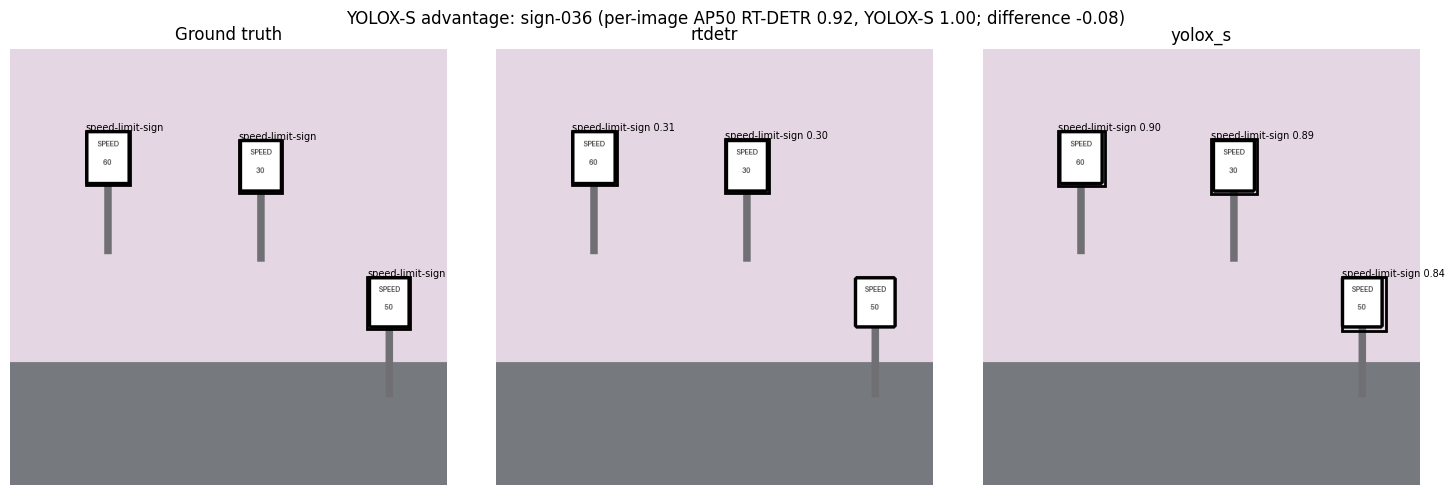

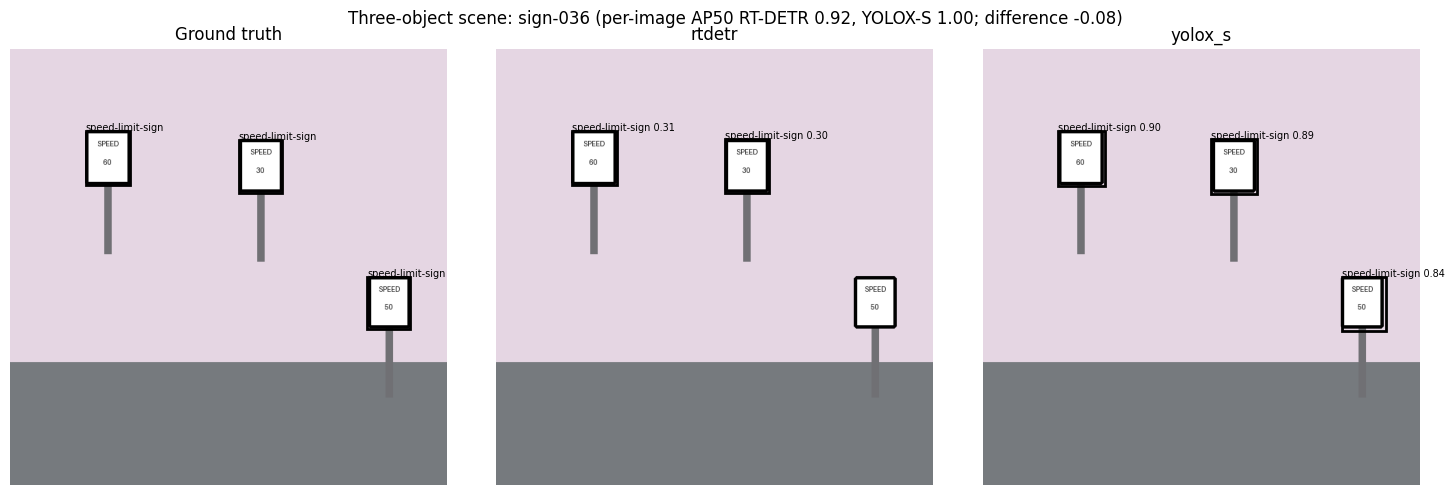

In [ ]:
# @title Plot comparison examples from this run
if "rtdetr" in MODEL_KEYS and "yolox_s" in MODEL_KEYS:
    advantage=disagreements["rtdetr_advantage"]
    candidates=[]
    # An "advantage" example is shown only when that model really scored higher on some image.
    if advantage.max()>0:
        candidates.append(("RT-DETR advantage","rt-detr_advantage",int(advantage.idxmax())))
    else:
        print("No test image where RT-DETR's per-image AP50 exceeds YOLOX-S's; no RT-DETR advantage example.")
    if advantage.min()<0:
        candidates.append(("YOLOX-S advantage","yolox-s_advantage",int(advantage.idxmin())))
    else:
        print("No test image where YOLOX-S's per-image AP50 exceeds RT-DETR's; no YOLOX-S advantage example.")
    candidates.append((
        "Three-object scene","three-object_scene",
        next((i for i,r in enumerate(test_records) if len(r["boxes"])==3),0),
    ))

    for title,slug,idx in candidates:
        record=test_records[idx]
        row=disagreements.iloc[idx]
        fig,axes=plt.subplots(1,3,figsize=(15,5))

        for ax in axes:
            ax.imshow(record["image"]);ax.axis("off")

        axes[0].set_title("Ground truth")
        for box,label in zip(record["boxes"],record["labels"]):
            x0,y0,x1,y1=box
            axes[0].add_patch(plt.Rectangle((x0,y0),x1-x0,y1-y0,fill=False,linewidth=2))
            axes[0].text(x0,y0,label,fontsize=7)

        for ax,key in zip(axes[1:],("rtdetr","yolox_s")):
            ax.set_title(key)
            for det in test_predictions[(key,"adapted")][idx]:
                if det["score"]<DISPLAY_THRESHOLD:continue
                x0,y0,x1,y1=det["box"]
                ax.add_patch(plt.Rectangle((x0,y0),x1-x0,y1-y0,fill=False,linewidth=2))
                ax.text(x0,y0,f"{det['label']} {det['score']:.2f}",fontsize=7)

        fig.suptitle(
            f"{title}: {record['id']} (per-image AP50 RT-DETR {row['rtdetr_ap50']:.2f}, "
            f"YOLOX-S {row['yolox_s_ap50']:.2f}; difference {row['rtdetr_advantage']:+.2f})"
        )
        plt.tight_layout()
        plt.savefig(OUTPUT_ROOT/"figures"/f"gallery_{slug}.png",dpi=150,bbox_inches="tight")
        plt.show()

## Optional (`FULL` only): multi-seed repeat

The `FULL` tier repeats bounded adaptation of RT-DETR and YOLOX-S with extra seeds. The repeat protocol (enabled or not, the seeds and the models) was declared in the freeze file in section 13, together with each model's training recipe. The cell reads the protocol and recipes from the verified freeze, refuses to run if the live settings changed since freezing, and saves the executed protocol next to the results (`test/multi_seed_protocol.json`).

Each repeat re-heads the detector with that seed, trains it with the frozen recipe and seed, and scores validation and test with the frozen cutoff. The table reports each seed, then the mean, minimum and maximum per model, and the RT-DETR minus YOLOX-S gap per seed. The range is the **observed variation across three training seeds on this one fixed dataset and split**: it is not a confidence interval and says nothing about other data. Nothing is chosen from it, and the canonical tables above do not change. `STANDARD` skips this cell.

**Evaluation checkpoint.** In `FULL`, before running, predict whether the gap between the two models keeps its sign across the seeds. Is the gap larger or smaller than one model's own range?


In [ ]:
# @title Optional (FULL only): multi-seed repeat of bounded adaptation
# The repeat runs from the verified freeze declaration, not from live settings; a change is refused.
multi_seed_protocol=verified_freeze["multi_seed_repeat"]
frozen_recipes={key:verified_freeze["models"][key]["adaptation"] for key in multi_seed_protocol["models"]}
live_recipes={
    key:{"epochs":RTDETR_EPOCHS,"batch_size":RTDETR_BATCH_SIZE,"learning_rate":RTDETR_LEARNING_RATE}
    if key=="rtdetr" else
    {"epochs":YOLOX_EPOCHS,"batch_size":YOLOX_BATCH_SIZE,"learning_rate":YOLOX_LEARNING_RATE}
    for key in multi_seed_protocol["models"]
}
repeat_drift=[]
if multi_seed_protocol["enabled"]!=(WORKSHOP_TIER=="FULL"):
    repeat_drift.append("tier")
if multi_seed_protocol["seeds"]!=list(MULTI_SEED_SEEDS):
    repeat_drift.append("MULTI_SEED_SEEDS")
for key,recipe in live_recipes.items():
    if any(frozen_recipes[key][name]!=value for name,value in recipe.items()):
        repeat_drift.append(f"{key} training recipe")
if repeat_drift:
    raise RuntimeError(
        "Changed after the experiment was frozen: "+"; ".join(repeat_drift)
        +". The multi-seed repeat runs only with the frozen protocol: re-run the notebook from section 1 (Run all)."
    )

if multi_seed_protocol["enabled"]:
    seed_rows=[]
    for key in multi_seed_protocol["models"]:
        recipe=frozen_recipes[key]
        for seed in multi_seed_protocol["seeds"]:
            if key=="rtdetr":
                repeat=RTDETRWorkshop.from_pretrained(CLASS_NAMES,seed=seed,device=DEVICE)
            else:
                repeat=YOLOXWorkshop.from_pretrained(key,CLASS_NAMES,seed=seed,device=DEVICE)
            repeat.finetune(train_records,epochs=recipe["epochs"],batch_size=recipe["batch_size"],
                            learning_rate=recipe["learning_rate"],seed=seed)
            validation_m=average_precision(repeat.predict_many(validation_records,TEST_SCORE_CUTOFF),
                                           validation_records,CLASS_NAMES)
            test_m=average_precision(repeat.predict_many(test_records,TEST_SCORE_CUTOFF),test_records,CLASS_NAMES)
            seed_rows.append({"model":key,"seed":seed,"validation_ap":validation_m["ap"],"test_ap":test_m["ap"],
                              "test_ap50":test_m["ap50"],"test_ap75":test_m["ap75"]})
            repeat=None
            gc.collect()
            if torch.cuda.is_available():torch.cuda.empty_cache()
    multi_seed=pd.DataFrame(seed_rows)
    multi_seed_summary=multi_seed.groupby("model")[["validation_ap","test_ap","test_ap50","test_ap75"]].agg(
        ["mean","min","max"])
    seed_gaps=(multi_seed[multi_seed["model"]=="rtdetr"].set_index("seed")["test_ap"]
               -multi_seed[multi_seed["model"]=="yolox_s"].set_index("seed")["test_ap"])
    canonical_gap=(
        test_table[(test_table["model"]=="rtdetr")&(test_table["state"]=="adapted")]["ap"].iloc[0]
        -test_table[(test_table["model"]=="yolox_s")&(test_table["state"]=="adapted")]["ap"].iloc[0]
    )
    print(multi_seed.to_string(index=False))
    print(multi_seed_summary.to_string())
    print({"test_ap_gap_rtdetr_minus_yolox_s_per_seed":{int(k):float(v) for k,v in seed_gaps.items()},
           "gap_mean":float(seed_gaps.mean()),"gap_min":float(seed_gaps.min()),"gap_max":float(seed_gaps.max()),
           "canonical_seed0_gap":float(canonical_gap)})
    print("The range is observed variation across these training seeds on one fixed dataset and split, "
          "not a confidence interval.")
    multi_seed.to_csv(OUTPUT_ROOT/"test"/"multi_seed_repeat.csv",index=False)
    (OUTPUT_ROOT/"test"/"multi_seed_protocol.json").write_text(json.dumps({
        "experiment_id":verified_freeze["experiment_id"],
        "verified_against":"frozen/frozen_experiment.json",
        "protocol":multi_seed_protocol,
        "training_recipes":frozen_recipes,
        "score_cutoff":TEST_SCORE_CUTOFF,
        "interpretation":"observed training-seed variation on one fixed dataset and split; not a confidence interval",
    },indent=2),encoding="utf-8")
else:
    print("Multi-seed repeat skipped: it runs only in the FULL tier (STANDARD keeps the single seed-0 run).")

Multi-seed repeat skipped: it runs only in the FULL tier (STANDARD keeps the single seed-0 run).


# 17. Computational tradeoffs

No composite winner is calculated.

The practical comparison includes:

- base checkpoint size;
- total parameters;
- trainable parameters;
- training wall time;
- test inference time per image: rough observed wall time over 12 images, no warm-up or repetition, including pre- and postprocessing; not a latency benchmark;
- artifact size;
- AP/AP75.

YOLOX-X in `FULL` is specifically a **scale experiment**: larger is not assumed to be better on this small transfer task.

In [ ]:
# @title Tradeoff table
tradeoff_rows=[]
for key in MODEL_KEYS:
    adapted=test_table[(test_table["model"]==key)&(test_table["state"]=="adapted")].iloc[0]
    report=training_reports[key]
    if key=="rtdetr":
        weight_bytes=RTDETR_SPEC["files"]["model.safetensors"][0]
    else:
        weight_bytes=YOLOX_VARIANTS[key]["bytes"]
    tradeoff_rows.append({
        "model":key,
        "weight_MiB":weight_bytes/2**20,
        "parameters_M":report["total_parameters"]/1e6,
        "trainable_M":report["trainable_parameters"]/1e6,
        "training_seconds":report["training_seconds"],
        "ms_per_test_image":adapted["ms_per_image"],
        "artifact_MiB":artifact_descriptors[key]["bytes"]/2**20,
        "test_ap":adapted["ap"],
        "test_ap75":adapted["ap75"],
    })

tradeoffs=pd.DataFrame(tradeoff_rows)
display(tradeoffs)
tradeoffs.to_csv(OUTPUT_ROOT/"test"/"computational_tradeoffs.csv",index=False)

,model,weight_MiB,parameters_M,trainable_M,training_seconds,ms_per_test_image,artifact_MiB,test_ap,test_ap75
0,rtdetr,164.199692,42.733137,19.259121,13.627976,70.590073,166.653408,0.915711,0.929226
1,yolox_s,68.749547,8.938456,1.891096,5.289654,14.739269,34.232437,0.849780,1.000000


# 18. Fresh reload parity

Test evaluation above already used freshly reconstructed artifact-backed models.

The next cell additionally compares one fixed validation image's **thresholded, postprocessed detections** from the live adapted model with those from the reloaded model. This is not a raw-tensor comparison:

- both detection lists must first pass the numerical-validity check (four finite, ordered box coordinates, a declared label, a finite score in [0, 1]);
- same detection count;
- same class labels;
- box coordinates within tolerance;
- scores within tolerance.

In [ ]:
# @title Artifact reload parity on a fixed validation image
parity={}
verify_record=validation_records[0]

for key in MODEL_KEYS:
    # `fresh_adapted` was reconstructed from the artifact before test.
    reloaded=fresh_adapted[key]

    parity[key]=compare_detection_lists(
        live_parity_predictions[key],
        reloaded.detect(verify_record["image"],EFFECTIVE_EVALUATION["display_threshold"]),
        context=key,
    )

print(parity)

{'rtdetr': {'n_detections': 1, 'max_abs_box_difference': 0.0, 'max_abs_score_difference': 0.0}, 'yolox_s': {'n_detections': 1, 'max_abs_box_difference': 0.0, 'max_abs_score_difference': 0.0}}


# 19. New-seed inference sanity check

Three synthetic scenes are generated using seed `2026`, completely outside the train/validation/test fixture.

Their exact boxes are known, so same-label IoU can be shown as an additional sanity check.

These examples do **not** enter the main test metrics.

In [ ]:
# @title New-seed examples
new_records=generate_sign_dataset(3,NEW_DATA_SEED,MAX_OBJECTS)

new_rows=[]
for key in MODEL_KEYS:
    model=fresh_adapted[key]
    preds=model.predict_many(new_records,EVAL_SCORE_THRESHOLD)
    op=operating_metrics(preds,new_records,DISPLAY_THRESHOLD)
    new_rows.append({"model":key,**op})
    for i,(record,dets) in enumerate(zip(new_records,preds)):
        payload={
            "image_id":record["id"],
            "detections":[d for d in dets if d["score"]>=DISPLAY_THRESHOLD],
        }
        (OUTPUT_ROOT/"new_data"/f"{key}_{i}.json").write_text(
            json.dumps(payload,indent=2),encoding="utf-8"
        )

display(pd.DataFrame(new_rows))

,model,precision50,recall50,mean_matched_iou,false_positives_per_image,missed_objects_per_image
0,rtdetr,0.333333,0.428571,0.970347,2.0,1.333333
1,yolox_s,1.000000,1.000000,0.928213,0.0,0.000000


## Optional BYOD — same three-class adaptation task

Set `USE_BYOD=True` and a local `BYOD_ZIP_PATH` in section 1, then Run all: the BYOD run is stored inside the same run directory as the canonical results. If your images include several frames, views or collection sessions of the same physical sign, keep each sign (or sequence, location or session) in one split by supplying the `split` column yourself: the duplicate-pixel check only catches identical images. Supply 5–60 images and `annotations.csv`: `image_id,file,label,x0,y0,x1,y1[,split]`, one row per box, with unique column names and no extra or missing fields in any row, at most six boxes per image. Only `stop-sign`, `yield-sign`, `speed-limit-sign` are supported. Every image must be annotated; each split must contain all three classes. Supply all train/validation/test assignments or omit every assignment for the deterministic 60/20/20 split. Pixels must not repeat across splits. Images must be 16–4096 pixels per side and at most 16 megapixels.

Validation fails before any BYOD model loads: a refused ZIP prints one message that names the file, CSV line or image and the rule it broke, skips the BYOD experiment, and records `byod_status` `refused` with the reason in the provenance manifest and the completion summary. The canonical results are unaffected, so a completed Run all with a refused BYOD is reported as exactly that. A separate run directory records input digests, bounded training, validation, frozen settings, exported adapters, live-to-fresh parity, baseline and adapted test results, and inference. Model instances run sequentially; the canonical tables and artifacts remain separate. This implementation still needs real-model BYOD qualification on the supported T4 runtime. Synthetic success does not establish road-scene performance.


In [ ]:
# @title Optional BYOD: validate, adapt, freeze, reload, evaluate and export
import csv
import zipfile
import tempfile
import traceback
from pathlib import PurePosixPath

MAX_BYOD_IMAGES=60
MAX_LABELS_PER_IMAGE=6

def safe_extract_zip(zip_path,destination):
    parent=Path(destination)
    parent.mkdir(parents=True,exist_ok=True)
    with zipfile.ZipFile(zip_path) as archive:
        infos=archive.infolist()
        if len(infos)>1000 or sum(i.file_size for i in infos)>2*1024**3:
            raise ValueError("BYOD ZIP exceeds member or expanded-size limit")
        names=set()
        for info in infos:
            path=PurePosixPath(info.filename)
            if (not info.filename or '\\' in info.filename or ':' in info.filename
                    or path.is_absolute() or '..' in path.parts):
                raise ValueError("unsafe ZIP path")
            name=str(path).casefold()
            if name in names: raise ValueError("duplicate ZIP member")
            names.add(name)
            if (info.external_attr>>16)&0o170000==0o120000:
                raise ValueError("symlink member refused")
        root=Path(tempfile.mkdtemp(prefix='dataset-',dir=parent))
        archive.extractall(root)
    return root

def load_byod(zip_path):
    root=safe_extract_zip(zip_path,WORK_ROOT/'byod')
    candidates=list(root.rglob('annotations.csv'))
    if len(candidates)!=1: raise ValueError(f'Exactly one annotations.csv required; found {len(candidates)}')
    annotation=candidates[0]
    base=annotation.parent.resolve()
    with annotation.open(encoding='utf-8-sig',newline='') as stream:
        reader=csv.DictReader(stream)
        required={'image_id','file','label','x0','y0','x1','y1'}
        fields=reader.fieldnames or []
        normalized=[str(f).strip().casefold() for f in fields]
        if len(normalized)!=len(set(normalized)): raise ValueError(f'Duplicate annotation column names in the annotations.csv header: {fields}')
        if not required<=set(fields): raise ValueError(f'Missing annotation columns in annotations.csv: {sorted(required-set(fields))}')
        rows=list(reader)
    for line,row in enumerate(rows,start=2):
        if None in row or None in row.values():
            raise ValueError(f'annotations.csv line {line}: Annotation row width differs from the header')
    if not rows or len(rows)>MAX_BYOD_IMAGES*MAX_LABELS_PER_IMAGE:
        raise ValueError(f'Empty or oversized annotations: {len(rows)} rows (allowed 1..{MAX_BYOD_IMAGES*MAX_LABELS_PER_IMAGE})')
    records={}; owners={}
    for line,row in enumerate(rows,start=2):
        rid=row['image_id'].strip(); filename=row['file'].strip()
        where=f'annotations.csv line {line} (image_id {rid!r}, file {filename!r})'
        split=row.get('split','').strip().lower()
        rel=PurePosixPath(filename)
        if not rid or not filename or rel.is_absolute() or '..' in rel.parts or '\\' in filename or ':' in filename:
            raise ValueError(f'{where}: Invalid image identity or path')
        path=(base/filename).resolve()
        if base not in path.parents or not path.is_file(): raise ValueError(f'{where}: Missing or unsafe image')
        if row['label'] not in CLASS_NAMES: raise ValueError(f'{where}: Unsupported class {row["label"]!r}; use the three declared sign labels')
        if split not in ('','train','validation','test'): raise ValueError(f'{where}: Invalid split {split!r}')
        if path in owners and owners[path]!=rid: raise ValueError(f'{where}: One file has multiple image IDs')
        owners[path]=rid
        if rid not in records:
            with Image.open(path) as original:
                if not all(16<=side<=4096 for side in original.size) or original.width*original.height>16_000_000:
                    raise ValueError(f'{where}: Image dimensions {original.size} outside 16..4096 / 16MP bound')
                image=original.convert('RGB')
            records[rid]={'id':rid,'image':image,'boxes':[],'labels':[], 'split':split,
                'file':filename,'sha256':hashlib.sha256(path.read_bytes()).hexdigest(),
                'pixel_sha256':hashlib.sha256(str(image.size).encode()+image.tobytes()).hexdigest()}
        r=records[rid]
        if r['file']!=filename or r['split']!=split: raise ValueError(f'{where}: Inconsistent file/split for image ID')
        box=[float(row[c]) for c in ('x0','y0','x1','y1')]
        w,h=r['image'].size
        if not all(np.isfinite(box)) or not (0<=box[0]<box[2]<=w and 0<=box[1]<box[3]<=h):
            raise ValueError(f'{where}: Nonfinite or out-of-bounds box {box}')
        if any(box==b and row['label']==label for b,label in zip(r['boxes'],r['labels'])):
            raise ValueError(f'{where}: Duplicate annotation')
        r['boxes'].append(box); r['labels'].append(row['label'])
        if len(r['boxes'])>MAX_LABELS_PER_IMAGE: raise ValueError(f'{where}: More than six labels per image')
    records=sorted(records.values(),key=lambda r:r['id'])
    if not 5<=len(records)<=MAX_BYOD_IMAGES: raise ValueError(f'BYOD requires 5..60 images; found {len(records)}')
    image_files={p.resolve() for p in root.rglob('*') if p.suffix.lower() in {'.png','.jpg','.jpeg','.webp','.bmp','.tif','.tiff'}}
    if image_files!=set(owners):
        unannotated=sorted(str(p.relative_to(base)) if base in p.parents else p.name for p in image_files-set(owners))
        raise ValueError(f'Every archive image must be annotated exactly once by ID; not annotated: {unannotated[:5]}')
    if any(r['split'] for r in records) and not all(r['split'] for r in records):
        raise ValueError(f'Supply splits for every image or none; no split for image_id {next(r["id"] for r in records if not r["split"])!r}')
    if not records[0]['split']:
        order=np.random.default_rng(SPLIT_SEED).permutation(len(records))
        a=int(.6*len(records)); b=int(.8*len(records))
        for index,pos in enumerate(order): records[pos]['split']='train' if index<a else 'validation' if index<b else 'test'
    hashes={}
    for r in records:
        old=hashes.setdefault(r['pixel_sha256'],r['split'])
        if old!=r['split']: raise ValueError(f"image_id {r['id']!r}: Duplicate pixels across splits ({old} and {r['split']})")
    for split in ('train','validation','test'):
        labels={label for r in records if r['split']==split for label in r['labels']}
        if labels!=set(CLASS_NAMES): raise ValueError(f'{split} must contain all three classes')
    return records

def assert_byod_parity(a,b):
    return compare_detection_lists(a,b,context='BYOD live-to-reload')

def run_byod_model(key,records,run_root):
    train=[r for r in records if r['split']=='train']
    validation=[r for r in records if r['split']=='validation']
    test=[r for r in records if r['split']=='test']
    folder=run_root/key; folder.mkdir()
    pipe=None; fresh=None
    try:
        pipe=(RTDETRWorkshop.from_pretrained(CLASS_NAMES,seed=0,device=DEVICE) if key=='rtdetr'
              else YOLOXWorkshop.from_pretrained(key,CLASS_NAMES,seed=0,device=DEVICE))
        baseline_validation=average_precision(pipe.predict_many(validation,EVAL_SCORE_THRESHOLD),validation,CLASS_NAMES)
        if key=='rtdetr':
            training=pipe.finetune(train,epochs=RTDETR_EPOCHS,batch_size=RTDETR_BATCH_SIZE,learning_rate=RTDETR_LEARNING_RATE,seed=0)
        else:
            training=pipe.finetune(train,epochs=YOLOX_EPOCHS,batch_size=YOLOX_BATCH_SIZE,learning_rate=YOLOX_LEARNING_RATE,seed=0)
        validation_metrics=average_precision(pipe.predict_many(validation,EVAL_SCORE_THRESHOLD),validation,CLASS_NAMES)
        live=pipe.detect(validation[0]['image'],DISPLAY_THRESHOLD)
        artifact=folder/'adapter.safetensors'; descriptor=pipe.save_artifact(artifact)
        artifact_hash=hashlib.sha256(artifact.read_bytes()+artifact.with_suffix('.json').read_bytes()).hexdigest()
        frozen={'model':key,'classes':list(CLASS_NAMES),'training':training,'artifact':descriptor,
                'artifact_sha256':artifact_hash,'baseline_validation':baseline_validation,'adapted_validation':validation_metrics,
                'evaluation_score_threshold':EVAL_SCORE_THRESHOLD,'display_threshold':DISPLAY_THRESHOLD,
                'input_manifest':'../input_manifest.json'}
        (folder/'frozen_experiment.json').write_text(json.dumps(frozen,indent=2,default=str),encoding='utf-8')
        pipe=None; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        pipe=(RTDETRWorkshop.from_pretrained(CLASS_NAMES,seed=0,device=DEVICE) if key=='rtdetr'
              else YOLOXWorkshop.from_pretrained(key,CLASS_NAMES,seed=0,device=DEVICE))
        baseline_test=pipe.predict_many(test,EVAL_SCORE_THRESHOLD)
        pipe=None; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        if hashlib.sha256(artifact.read_bytes()+artifact.with_suffix('.json').read_bytes()).hexdigest()!=artifact_hash: raise RuntimeError('Artifact changed')
        fresh=(RTDETRWorkshop.load_artifact(artifact,DEVICE) if key=='rtdetr' else YOLOXWorkshop.load_artifact(artifact,DEVICE))
        assert_byod_parity(live,fresh.detect(validation[0]['image'],DISPLAY_THRESHOLD))
        adapted_test=fresh.predict_many(test,EVAL_SCORE_THRESHOLD)
        metrics=[]
        for state,predictions in [('pre',baseline_test),('adapted',adapted_test)]:
            metrics.append({'model':key,'state':state,**average_precision(predictions,test,CLASS_NAMES),
                            **operating_metrics(predictions,test,DISPLAY_THRESHOLD)})
        payload={'metrics':metrics,'parity':'live-to-fresh PASS','test_ids':[r['id'] for r in test],
                 'baseline_predictions':baseline_test,'adapted_predictions':adapted_test,
                 'inference_example':fresh.detect(test[0]['image'],DISPLAY_THRESHOLD)}
        (folder/'results.json').write_text(json.dumps(payload,indent=2,default=str),encoding='utf-8')
        pd.DataFrame(metrics).to_csv(folder/'metrics.csv',index=False)
        return metrics
    except Exception as exc:
        traceback.clear_frames(exc.__traceback__)
        raise
    finally:
        pipe=None; fresh=None; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()

byod_records=None
BYOD_STATUS,BYOD_REFUSAL_REASON=('requested','') if USE_BYOD else ('disabled','')
if USE_BYOD:
    if not (OUTPUT_ROOT/'frozen'/'frozen_experiment.json').is_file():
        raise RuntimeError('BYOD runs inside a complete canonical run: set USE_BYOD and BYOD_ZIP_PATH in section 1, then Run all')
    for stale in ('byod_metrics','byod_run'):
        globals().pop(stale,None)  # a refusal must not leave an earlier BYOD result looking current
    # All validation precedes model acquisition/adaptation. A refusal prints one message naming the item
    # and the rule, and stops here; the canonical results above are unchanged.
    byod_refusal=None
    try:
        if not BYOD_ZIP_PATH:
            raise ValueError('BYOD_ZIP_PATH is empty; set it in section 1 to the path of your ZIP')
        if not Path(BYOD_ZIP_PATH).is_file():
            raise ValueError(f'BYOD_ZIP_PATH {BYOD_ZIP_PATH!r} is not a file')
        byod_records=load_byod(BYOD_ZIP_PATH)
    except ValueError as refusal:
        byod_refusal=str(refusal)
    except zipfile.BadZipFile as refusal:
        byod_refusal=f'{BYOD_ZIP_PATH!r} is not a readable ZIP archive ({refusal})'
    if byod_refusal is not None:
        BYOD_STATUS,BYOD_REFUSAL_REASON='refused',byod_refusal
        print(f'BYOD refused before any BYOD model was loaded: {byod_refusal}. '
              'The canonical results above are unaffected; fix the ZIP and re-run this cell.')
if byod_records is not None:
    for alias in ('pipe','model','adapted','reloaded','again','fresh_adapted'):
        globals().pop(alias,None)
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    byod_parent=OUTPUT_ROOT/'byod'; byod_parent.mkdir(exist_ok=True)
    byod_run=Path(tempfile.mkdtemp(prefix='run-',dir=byod_parent))
    manifest={'zip_sha256':hashlib.sha256(Path(BYOD_ZIP_PATH).read_bytes()).hexdigest(),
              'records':[{k:v for k,v in r.items() if k!='image'} for r in byod_records],
              'runtime':{'python':sys.version,'torch':torch.__version__,'device':str(DEVICE)},
              'models':frozen_experiment['models'],
              'split_seed':SPLIT_SEED,'scope':'three-class bounded adaptation; separate from canonical results'}
    (byod_run/'input_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
    byod_metrics=[row for key in MODEL_KEYS for row in run_byod_model(key,byod_records,byod_run)]
    pd.DataFrame(byod_metrics).to_csv(byod_run/'metrics.csv',index=False)
    display(pd.DataFrame(byod_metrics)); print('BYOD exports:',byod_run)
    BYOD_STATUS='completed'
elif not USE_BYOD:
    print('BYOD disabled; canonical synthetic E2E path completed.')


BYOD disabled; canonical synthetic E2E path completed.


## BYOD privacy

User-supplied imagery and annotations are processed inside the selected notebook runtime and are not sent to DIMER workers or APIs.

A hosted notebook is still an external compute environment. Do not upload confidential, biometric, surveillance, personal, security-sensitive, restricted, or proprietary imagery unless authorized.

# 21. Interpretation and limits

### Synthetic domain

These are rendered signs, not photographs.

High AP means that bounded adaptation learned this controlled rendering domain. It does not establish performance on real traffic signs.

### Small test set

Twelve images are sample-sanity evidence, not a benchmark.

### Different model-native recipes: a whole-system comparison

This notebook compares **two whole detector systems under these recipes**, not architecture under one optimizer. The recipes are untuned (nothing was tuned on validation), and their budgets differ: 27 versus 108 optimizer steps and about 19.3M versus 1.9M trainable parameters (section 11). No result here can be attributed to the set-prediction or the dense detection formulation.

RT-DETR and YOLOX differ in:

- prediction representation;
- matching/assignment;
- loss;
- optimizer;
- trainable surface;
- post-processing.

### Run-to-run variation

GPU training is not bit-reproducible. Recorded T4 runs of earlier revisions (section 16, quoted from `docs/release-verification.md`) moved the RT-DETR minus YOLOX-S test-AP gap from +0.143 (revision `ade681b`) to +0.037 (revision `46a300c`), with an environment change in between, so the cause is not isolated. Every comparison here holds "in this run" only.

### AP50 can hide localization differences

AP50 may saturate. Read AP75 and AP@[.50:.95] alongside it.

### Scores are not automatically calibrated probabilities

RT-DETR's class sigmoid and YOLOX's objectness × class score have different semantics. One raw threshold is a different operating point for each model, which is why section 15 also reports each model at its own validation-chosen operating point.

### Closed vocabulary

After adaptation, this exercise's detectors recognize only:

- stop-sign
- yield-sign
- speed-limit-sign

They cannot accept a new text label at inference time.

That limitation motivates the subsequent **Open-Vocabulary Detection & Counting** workshop.

# 22. Exercises

### Exercise A — set prediction versus dense detection

Why does RT-DETR not require conventional NMS while YOLOX does?

### Exercise B — AP50 versus AP75

If two detectors both reach AP50 = 1.0, can one still localize boxes more accurately?

### Exercise C — bigger YOLOX

In `FULL`, does the 99M-parameter YOLOX-X outperform the 9M-parameter YOLOX-S on this small task?

Do not assume the answer before running it.

### Exercise D — score threshold

What changes when display threshold moves from 0.05 to 0.70?

Why should test data never be used to choose that operating point?

### Exercise F — equal thresholds, different behaviour (goal 4)

In the section 12 sweep (`threshold_table`), compare `precision50`, `recall50` and `false_positives_per_image` at threshold 0.05 for the two models, then compare `VALIDATION_OPERATING_POINTS`. Predict first: should the same numeric threshold give both models the same precision, recall or number of false detections? Explain why it need not: the models produce different candidate boxes, and their scores follow different distributions. Different F1-best thresholds do not, on their own, show that either model is miscalibrated.

**Calibration is a separate question.** A detector's scores are calibrated when, among detections given a score near *p*, about a fraction *p* are correct. "Correct" has to be defined first, for example: the predicted class is right and the box reaches IoU ≥ 0.5 with a reference box that no higher-scored detection has claimed. Checking calibration needs many held-out detections; this notebook's 12 validation images are far too few, so it does not measure calibration.

### Exercise G — when closed-set detection is the wrong tool (goal 11)

For each request, decide whether **these adapted artifacts** can serve it, and what would: (1) find stop signs in new rendered scenes; (2) find "pedestrian crossing" signs; (3) let a user type any sign name at inference time. Check your answers against `CLASS_NAMES` and section 21's closed-vocabulary limit.

Hint: case 2 is a new but fixed class. A closed-set detector can serve it after you add `pedestrian-crossing-sign` to the vocabulary, collect boxes for it and retrain; an open-vocabulary detector is an alternative to evaluate, not a requirement. Case 3 asks for arbitrary text queries, which is what an open-vocabulary interface provides, and its accuracy on your signs would still need validation.

### Exercise E — production transfer

What labelled evidence would be required before adapting either detector to real Philippine road-sign imagery?

**Evaluation checkpoint.** **Optional controlled activity — Predict → Change one thing → Run → Observe → Explain.** After the canonical run, use the already computed validation predictions to compare the existing threshold-sweep rows at 0.30 and 0.50. Predict which changes more: precision or recall. Change only the display threshold in a separate scratch cell calling `operating_metrics(post_validation_predictions[key], validation_records, 0.50)` with `key="rtdetr"`; run and compare with 0.30. Record both values and explain misses versus false positives. Do not overwrite `DISPLAY_THRESHOLD`, frozen settings, test outputs, or retrain. No model reload is needed.


# 23. Export provenance and report

In [ ]:
# @title Final provenance
import datetime

experiment_manifest={
    "notebook_spec":"2.5",
    "notebook_kind":"WORKSHOP",
    "notebook_profile":"E2E",
    "notebook_mode":"WORKSHOP",
    "workshop_revision":"0.4.0-candidate",
    "runtime_environment":"uv isolated CPython 3.12.12 environment from a hash lock; Linux x86_64 only",
    "timestamp_utc":datetime.datetime.now(datetime.timezone.utc).isoformat(),
    "execution_tier":WORKSHOP_TIER,
    "dataset":dataset_manifest,
    "run_id":RUN_ID,
    "experiment_id":verified_freeze["experiment_id"],
    "models":verified_freeze["models"],
    "evaluation":EFFECTIVE_EVALUATION,
    "validation_operating_points":verified_freeze["validation_operating_points"],
    "training_reports":training_reports,
    "test_metrics":test_table.to_dict("records"),
    "artifact_parity":parity,
    "byod":{"status":globals().get("BYOD_STATUS","not run"),"refusal_reason":globals().get("BYOD_REFUSAL_REASON","")},
    "standalone_contract":{
        "dimer_git_clone_required":False,
        "dimer_source_runtime_fetch_required":False,
        "dimer_service_required":False,
        "credentials_required":False,
        "default_upload_required":False,
    },
    "candidate_release_gates":[
        "real-model BYOD valid and invalid path evidence",
        "fresh T4 Run all for STANDARD",
        "fresh T4 Run all for FULL",
        "record exact peak VRAM and wall time",
    ],
    "evidence_scope":"60 deterministic rendered sign scenes; 36 train / 12 validation / 12 independent test",
}

# Replay the test metrics from the saved detections alone; a mismatch means the export is incomplete.
saved=json.loads((OUTPUT_ROOT/"test"/"predictions.json").read_text(encoding="utf-8"))
records_by_id={r["id"]:r for r in test_records}
replay={}
for (key,state) in test_predictions:
    rows=[p for p in saved["predictions"] if p["model"]==key and p["state"]==state]
    replayed=average_precision(
        [p["detections"] for p in rows],[records_by_id[p["image_id"]] for p in rows],CLASS_NAMES
    )
    stored=test_table[(test_table["model"]==key)&(test_table["state"]==state)].iloc[0]
    if any(replayed[m]!=stored[m] for m in ("ap","ap50","ap75")) or len(rows)!=len(test_records):
        raise RuntimeError(f"{key}/{state}: metrics replayed from test/predictions.json differ")
    replay[f"{key}/{state}"]="PASS"
experiment_manifest["metric_replay_from_saved_predictions"]=replay

(OUTPUT_ROOT/"provenance"/"experiment_manifest.json").write_text(
    json.dumps(experiment_manifest,indent=2,default=str),encoding="utf-8"
)
(OUTPUT_ROOT/"workshop_summary.json").write_text(
    json.dumps({
        "run_id":RUN_ID,
        "experiment_id":verified_freeze["experiment_id"],
        "tier":WORKSHOP_TIER,
        "models":MODEL_KEYS,
        "dataset_sha256":dataset_manifest["dataset_sha256"],
        "test_metrics":test_table.to_dict("records"),
        "artifacts":artifact_descriptors,
        "reload_parity":parity,
        "byod_status":globals().get("BYOD_STATUS","not run"),
    },indent=2,default=str),
    encoding="utf-8"
)

import shutil
# The bundle holds this run's directory only: earlier runs under OUTPUT_DIR are not included.
bundle=shutil.make_archive(
    str((Path(OUTPUT_DIR)/f"DIMER_Closed_Set_Detection_Workshop_Report_{RUN_ID}").resolve()),
    "zip",
    root_dir=OUTPUT_ROOT.resolve(),
)
print({
    "bundle":bundle,"sha256":sha256_file(bundle),"run_id":RUN_ID,
    "files":sum(1 for p in OUTPUT_ROOT.rglob("*") if p.is_file()),"metric_replay":replay,
})

{'bundle': '/content/outputs/DIMER_Closed_Set_Detection_Workshop_Report_20261025T002717Z-580588.zip', 'sha256': 'afc10742e70963b52d9d32c93091d6f65a089462bed05593bb74003758126b51', 'run_id': '20261025T002717Z-580588', 'files': 34, 'metric_replay': {'rtdetr/pre': 'PASS', 'rtdetr/adapted': 'PASS', 'yolox_s/pre': 'PASS', 'yolox_s/adapted': 'PASS'}}


# 24. Troubleshooting

| Symptom | Likely cause | Corrective action |
|---|---|---|
| CUDA unavailable | CPU runtime selected | choose a T4-class runtime before `Run all` |
| "This notebook needs a Linux x86_64 runtime" | the kernel is Windows, macOS or ARM | use Google Colab, Kaggle or Linux x86_64 Jupyter; the lock is built for manylinux x86_64 |
| "pinned uv wheel failed its size/SHA-256 check" | incomplete or altered download | run the infrastructure cell again; never bypass the check |
| "The isolated environment's Python process exited" | the worker process died, usually out of memory | restart the session and choose `Run all` |
| "does not hold the locked versions" | a reused `dimer_isolated_env` folder from another revision | delete that folder or start a fresh runtime, then `Run all` |
| RT-DETR digest mismatch | incomplete/changed Hub asset | remove cached snapshot and retry; never bypass digest |
| YOLOX source digest mismatch | pinned upstream file changed/incorrect response | stop; never execute unverified source |
| YOLOX checkpoint digest mismatch | incomplete/changed release asset | remove cached checkpoint and retry |
| YOLOX OOM during SimOTA | label-assignment memory pressure | use canonical T4/batch size; do not change test protocol silently |
| one class absent from a split | canonical/BYOD split invalid | supply more data or explicit split; do not move boxes ad hoc |
| AP50 high but AP low | boxes not tight enough at stricter IoU thresholds | inspect localization, not only class hits |
| training loss decreases but validation AP does not | optimization did not transfer | keep the fixed recipe and interpret the result |
| reload parity fails | artifact/base mismatch or nondeterministic boundary | refuse the artifact and inspect identity/state |
| "non-finite ... failed computation" | a model produced NaN/Inf or malformed output | treat it as a failed run, not as "no objects"; restart the runtime and Run all |
| "Changed after the experiment was frozen" | a setting, split, model selection or artifact changed after section 13 | that is a new experiment: Run all from section 1 |
| "YOLOX artifact predates the upstream BatchNorm correction" | adapter saved by an earlier notebook revision | re-run adaptation; old adapters were trained with different BatchNorm settings |
| BYOD geometry differs between models | RT-DETR squash vs YOLOX letterbox | interpret BYOD as system-level rather than architecture-only comparison |

Failure should remain explicit rather than silently changing the detection problem.

# Glossary

| Term | Meaning |
|---|---|
| **Closed-set detector** | Detector with a fixed learned class vocabulary |
| **Bounding box** | Axis-aligned `[x0,y0,x1,y1]` rectangle around an object |
| **IoU** | Intersection-over-union between predicted and reference boxes |
| **AP** | Mean average precision across IoU thresholds 0.50–0.95 |
| **AP50** | AP using IoU ≥ 0.50 |
| **AP75** | AP using IoU ≥ 0.75 |
| **Object query** | Learned RT-DETR decoder query that can predict one object |
| **Objectness** | YOLOX estimate that a candidate location contains an object |
| **SimOTA** | YOLOX dynamic target-assignment procedure |
| **NMS** | Non-maximum suppression used to remove overlapping dense predictions |
| **Set prediction** | DETR-style formulation predicting a bounded object set without conventional NMS |
| **Re-head** | Replace/reinitialize the classification head for a new vocabulary |
| **Sample-sanity evidence** | Bounded tutorial evidence, not a deployment benchmark |

In [ ]:
# @title Run-all completion summary
summary={
    "notebook_spec":"2.5",
    "profile":"E2E",
    "mode":"WORKSHOP",
    "run_id":RUN_ID,
    "experiment_id":verified_freeze["experiment_id"],
    "tier":WORKSHOP_TIER,
    "models":MODEL_KEYS,
    "dataset_sha256":dataset_manifest["dataset_sha256"],
    "split_counts":{k:len(v) for k,v in splits.items()},
    "artifacts":artifact_descriptors,
    "reload_parity":parity,
    "output_directory":str(OUTPUT_ROOT.resolve()),
    "release_status":"candidate",
    "byod_status":globals().get("BYOD_STATUS","not run"),
}
display(pd.Series(summary,name="value").to_frame())
if globals().get("BYOD_STATUS")=="refused":
    print(f"BYOD was requested but REFUSED: {BYOD_REFUSAL_REASON}. Only the canonical path completed.")
print(
    "Closed-set detection notebook complete. "
    "Interpret built-in metrics as synthetic sample-sanity evidence; "
    "release still requires fresh STANDARD/FULL T4 and real-model BYOD qualification."
)

,value
notebook_spec,2.5
profile,E2E
mode,WORKSHOP
run_id,20261025T002717Z-580588
experiment_id,36728823c1e67682f873a830cde404aef781633d536284...
tier,STANDARD
models,"[rtdetr, yolox_s]"
dataset_sha256,823df4cf634db78216dccf5a6988171248b844beb5303e...
split_counts,"{'train': 36, 'validation': 12, 'test': 12}"
artifacts,{'rtdetr': {'path': 'outputs/runs/20261025T002...


Closed-set detection notebook complete. Interpret built-in metrics as synthetic sample-sanity evidence; release still requires fresh STANDARD/FULL T4 and real-model BYOD qualification.
